In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.table import Table
from astropy.io import fits
import os
import matplotlib.patches as patches
import matplotlib as mpl
from scipy.special import gammaincc
from scipy import stats
import seaborn as sns
from scipy.stats import gaussian_kde
import ndtest
from scipy.stats import ks_2samp, norm

# Orbital analysis with MWPotential2014

## Loading in the data

Loading in literature data

In [2]:
# Loading in the literature orbits and the Gaia data
lit_orbs = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/orbits/lit_orbits.fits')
lit_orbs_df = lit_orbs.to_pandas()
lit_orbs_df['star'] = lit_orbs_df['star'].str.decode('utf-8')  # Decode bytes to string
lit_orbs_df['jtot'] = np.sqrt(lit_orbs_df['jp']**2 + lit_orbs_df['jz']**2 + lit_orbs_df['jr']**2)

lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_v2.csv')

# # For Jacobson+2015, only taking stars present in Cordoni+2021.
# cordoni2021_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/cordoni2021_gaia_ids.csv')
# leftover = []
# for i, row in lit_gaia_df.iterrows():
#     catalog = row['catalog']
#     if catalog == 'jacobson2015':
#         if row['target_id'] not in cordoni2021_df['gaia_id'].values:
#             lit_gaia_df.drop(i, inplace=True)
#             lit_orbs_df.drop(i, inplace=True)
            
#             # Adding the dropped star to the leftover list
#             leftover.append({'star_id': row['target_id'], 'ra': row['ra'], 'dec': row['dec']})
# leftover_df = pd.DataFrame(leftover)
# leftover_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_leftover_stars.csv', index=False)

# For stars dropped, update the lit_orbs_df and lit_gaia_df with the updated leftover data
leftover_lit_orbs = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/orbits_leftover/lit_orbits.fits')
leftover_lit_orbs_df = leftover_lit_orbs.to_pandas()
leftover_lit_orbs_df['star'] = leftover_lit_orbs_df['star'].str.decode('utf-8')  # Decode bytes to string
leftover_lit_orbs_df['jtot'] = np.sqrt(leftover_lit_orbs_df['jp']**2 + leftover_lit_orbs_df['jz']**2 + leftover_lit_orbs_df['jr']**2)

leftover_lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_leftover.csv')

for i, row in leftover_lit_gaia_df.iterrows():
    star_id = row['star_id']
    if star_id in lit_gaia_df['star_id'].values:
        # Update the corresponding row in lit_gaia_df with the new rv and rv_err values
        lit_gaia_df.loc[lit_gaia_df['star_id'] == star_id, 'rv'] = row['rv']
        lit_gaia_df.loc[lit_gaia_df['star_id'] == star_id, 'rv_err'] = row['rv_err']
        
for i, row in leftover_lit_orbs_df.iterrows():
    star_id = row['star']
    if star_id in lit_orbs_df['star'].values:
        # Update the corresponding row in lit_orbs_df with the new orbital parameters
        lit_orbs_df.loc[lit_orbs_df['star'] == star_id, ['star', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'rmax', 'rmax_err', 'rapo', 'rapo_err',
       'e', 'e_err', 'zmax', 'zmax_err', 'E', 'E_err', 'jp', 'jp_err', 'jr',
       'jr_err', 'jz', 'jz_err', 'xpos', 'xpos_err', 'ypos', 'ypos_err',
       'zpos', 'zpos_err', 'vx', 'vx_err', 'vy', 'vy_err', 'vz', 'vz_err',
       'vphi', 'vphi_err', 'vR', 'vR_err', 'vT', 'vT_err', 'vbb', 'vbb_err',
       'vll', 'vll_err', 'xhelio', 'xhelio_err', 'yhelio', 'yhelio_err',
       'zhelio', 'zhelio_err', 'jtot']] = row[['star', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'rmax', 'rmax_err', 'rapo', 'rapo_err',
       'e', 'e_err', 'zmax', 'zmax_err', 'E', 'E_err', 'jp', 'jp_err', 'jr',
       'jr_err', 'jz', 'jz_err', 'xpos', 'xpos_err', 'ypos', 'ypos_err',
       'zpos', 'zpos_err', 'vx', 'vx_err', 'vy', 'vy_err', 'vz', 'vz_err',
       'vphi', 'vphi_err', 'vR', 'vR_err', 'vT', 'vT_err', 'vbb', 'vbb_err',
       'vll', 'vll_err', 'xhelio', 'xhelio_err', 'yhelio', 'yhelio_err',
       'zhelio', 'zhelio_err', 'jtot']].values

# lit_orbs_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_orbit_params.csv', index=False)
# lit_gaia_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_v2.csv', index=False)

# Separating stars into different orbit types
lit_disk_pro = lit_orbs_df[(lit_orbs_df['jp']/lit_orbs_df['jtot'] >= 0.75) & (lit_orbs_df['zmax'] < 3)]
lit_disk_pro['orbit'] = 'pro_disk'

lit_disk_ret = lit_orbs_df[(lit_orbs_df['jp']/lit_orbs_df['jtot'] <= -0.75) & (lit_orbs_df['zmax'] < 3)]
lit_disk_ret['orbit'] = 'ret_disk'

lit_ges = lit_orbs_df[(lit_orbs_df['jp']/lit_orbs_df['jtot'] > -0.25) & (lit_orbs_df['jp']/lit_orbs_df['jtot'] < 0.25) 
                 & ((lit_orbs_df['jz']-lit_orbs_df['jr'])/lit_orbs_df['jtot'] > -0.75) & ((lit_orbs_df['jz']-lit_orbs_df['jr'])/lit_orbs_df['jtot'] < 0.25)]
lit_ges['orbit'] = 'gse'

lit_halo = lit_orbs_df[~lit_orbs_df['star'].isin(lit_ges['star']) & ~lit_orbs_df['star'].isin(lit_disk_pro['star']) & ~lit_orbs_df['star'].isin(lit_disk_ret['star'])]
lit_halo['orbit'] = 'halo'


# Combining all the orbit types into one DataFrame
lit_combined = pd.concat([lit_disk_pro, lit_disk_ret, lit_ges, lit_halo], ignore_index=True)
# lit_combined['star'] = lit_combined['star'].str.decode('utf-8')  # Decode bytes to string
lit_combined.rename(columns={'star': 'star_id'}, inplace=True)  # Rename 'star' to 'star_id' for merging

lit_combined = lit_combined.merge(lit_gaia_df[['star_id', 'teff', 'feh', 'logg', 'source_id', 'catalog']], left_on='star_id', right_on='star_id', how='left')
# lit_combined.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_orbits_v2.csv', index=False)


lit_disk_pro = lit_combined[lit_combined['orbit'] == 'pro_disk']
lit_disk_ret = lit_combined[lit_combined['orbit'] == 'ret_disk']
lit_ges = lit_combined[lit_combined['orbit'] == 'gse']
lit_halo = lit_combined[lit_combined['orbit'] == 'halo']

print(f"Number of prograde disk stars: {len(lit_disk_pro)}")
print(f"Number of retrograde disk stars: {len(lit_disk_ret)}")
print(f"Number of GES stars: {len(lit_ges)}")
print(f"Number of halo stars: {len(lit_halo)}")

Number of prograde disk stars: 16
Number of retrograde disk stars: 4
Number of GES stars: 34
Number of halo stars: 261


/tmp/ipykernel_1407371/2991264105.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_pro['orbit'] = 'pro_disk'
/tmp/ipykernel_1407371/2991264105.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_ret['orbit'] = 'ret_disk'
/tmp/ipykernel_1407371/2991264105.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/st

In [ ]:
yong2013_orbs = lit_combined[lit_combined['catalog'] == 'yong2013']
print(len(yong2013_orbs[yong2013_orbs['orbit'] == 'pro_disk']), len(yong2013_orbs[yong2013_orbs['orbit'] == 'ret_disk']), len(yong2013_orbs[yong2013_orbs['orbit'] == 'halo']), len(yong2013_orbs[yong2013_orbs['orbit'] == 'gse']))
print(len(yong2013_orbs[yong2013_orbs['orbit'] == 'pro_disk'])/len(yong2013_orbs), len(yong2013_orbs[yong2013_orbs['orbit'] == 'ret_disk'])/len(yong2013_orbs), len(yong2013_orbs[yong2013_orbs['orbit'] == 'halo'])/len(yong2013_orbs), len(yong2013_orbs[yong2013_orbs['orbit'] == 'gse'])/len(yong2013_orbs))
print()


jacobson2015_orbs = lit_combined[lit_combined['catalog'] == 'jacobson2015']
print(len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'pro_disk']), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'ret_disk']), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'halo']), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'gse']))
print(len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'pro_disk'])/len(jacobson2015_orbs), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'ret_disk'])/len(jacobson2015_orbs), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'halo'])/len(jacobson2015_orbs), len(jacobson2015_orbs[jacobson2015_orbs['orbit'] == 'gse'])/len(jacobson2015_orbs))
print()

marino2019_orbs = lit_combined[lit_combined['catalog'] == 'marino2019']
print(len(marino2019_orbs[marino2019_orbs['orbit'] == 'pro_disk']), len(marino2019_orbs[marino2019_orbs['orbit'] == 'ret_disk']), len(marino2019_orbs[marino2019_orbs['orbit'] == 'halo']), len(marino2019_orbs[marino2019_orbs['orbit'] == 'gse']))
print(len(marino2019_orbs[marino2019_orbs['orbit'] == 'pro_disk'])/len(marino2019_orbs), len(marino2019_orbs[marino2019_orbs['orbit'] == 'ret_disk'])/len(marino2019_orbs), len(marino2019_orbs[marino2019_orbs['orbit'] == 'halo'])/len(marino2019_orbs), len(marino2019_orbs[marino2019_orbs['orbit'] == 'gse'])/len(marino2019_orbs))
print()

yong2021_orbs = lit_combined[lit_combined['catalog'] == 'yong2021']
print(len(yong2021_orbs[yong2021_orbs['orbit'] == 'pro_disk']), len(yong2021_orbs[yong2021_orbs['orbit'] == 'ret_disk']), len(yong2021_orbs[yong2021_orbs['orbit'] == 'halo']), len(yong2021_orbs[yong2021_orbs['orbit'] == 'gse']))
print(len(yong2021_orbs[yong2021_orbs['orbit'] == 'pro_disk'])/len(yong2021_orbs), len(yong2021_orbs[yong2021_orbs['orbit'] == 'ret_disk'])/len(yong2021_orbs), len(yong2021_orbs[yong2021_orbs['orbit'] == 'halo'])/len(yong2021_orbs), len(yong2021_orbs[yong2021_orbs['orbit'] == 'gse'])/len(yong2021_orbs))

,star_id,ra,dec,dist,dist_err,pmRA,pmRA_err,pmdec,pmdec_err,Vlos,...,yhelio_err,zhelio,zhelio_err,jtot,orbit,teff,feh,logg,source_id,catalog
0,53327-2044-515,25.150925,23.749406,0.940910,0.033900,0.972496,0.050264,-21.590494,0.031319,-193.50,...,0.000000,-0.554895,0.000000,895.656035,pro_disk,5703,-4.00,4.68,2.909303e+17,yong2013
1,HE 0945-1435,146.961061,-14.818582,1.246371,0.044010,-21.083921,0.030016,-2.080702,0.025505,121.75,...,0.010448,0.619749,0.062949,1110.666334,pro_disk,6344,-3.77,4.43,5.687210e+18,yong2013
2,SMSS J135217.78-151405.7,208.074005,-15.234940,2.330720,0.171064,-21.008556,0.033011,-2.356619,0.031042,39.70,...,0.189180,1.671516,0.149916,654.133773,pro_disk,5260,-2.56,2.75,6.295923e+18,jacobson2015
3,J081627.99-055913.3,124.116611,-5.987050,6.630397,0.751344,-0.442591,0.016562,-1.887239,0.013701,159.80,...,0.161230,1.844782,0.000000,1369.857239,pro_disk,4875,-3.36,1.65,3.064362e+18,yong2021
4,J091043.10-144418.5,137.679564,-14.738497,5.510580,0.525487,-3.637101,0.016372,-0.003217,0.014172,210.80,...,0.197866,2.098890,0.086295,1328.121095,pro_disk,4650,-3.41,1.04,5.731383e+18,yong2021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,J215842.28-202915.8,329.676194,-20.487759,9.140718,3.749140,10.561893,0.029654,-11.543915,0.025409,-94.00,...,0.037384,-7.059286,0.137291,2802.646806,halo,4975,-3.30,1.92,6.823220e+18,yong2021
279,J222323.36-482451.3,335.847386,-48.414280,1.041327,0.016562,16.510353,0.012915,-36.398441,0.014240,-107.80,...,0.039777,-0.828815,0.130454,610.786558,halo,5250,-2.90,2.70,6.517965e+18,yong2021
280,J224145.62-064643.0,340.440108,-6.778676,15.665713,13.100705,1.869163,0.023671,-2.898415,0.017150,-201.60,...,0.042025,-12.782991,0.140776,1346.660529,halo,4800,-3.19,1.46,2.623364e+18,yong2021
281,J230525.31-213807.0,346.355546,-21.635311,3.483409,0.135107,-1.075391,0.013362,-15.167666,0.012498,-15.70,...,0.042025,-3.135718,0.137609,581.763397,halo,5100,-3.35,2.26,2.398203e+18,yong2021


Loading in the X-Shooter data

In [3]:
p113_orb_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')
p115_orb_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')
comb_df = pd.concat([p113_orb_df, p115_orb_df], ignore_index=True)
comb_df.rename(columns={'Jp': 'jp', 'Jz': 'jz', 'Jr': 'jr', 'Jtot': 'jtot'}, inplace=True)
comb_df = comb_df.drop(columns=['iter_num', 'teff', 'teff_err', 'logg', 'logg_upp_err', 'logg_low_err', 'z', 'z_err', 'rv', 'rv_err', 'carb', 'carb_err'])

# Separating the orbits into different types
pro_disk = comb_df[comb_df['orbit'] == 'pro_disk']
ret_disk = comb_df[comb_df['orbit'] == 'ret_disk']
gse = comb_df[comb_df['orbit'] == 'gse']
halo = comb_df[comb_df['orbit'] == 'halo']

Loading in the full AAT dataset

In [4]:
aat_orb_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/aat_params_FINAL.csv')
aat_orb_df.rename(columns={'Jp': 'jp', 'Jz': 'jz', 'Jr': 'jr', 'Jtot': 'jtot'}, inplace=True)

aat_orb_df_fehm20 = aat_orb_df[aat_orb_df['z'] < -2.0]
aat_orb_df_fehm25 = aat_orb_df[aat_orb_df['z'] < -2.5]

Loading in Sculptor data

In [5]:
dwarf_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/dwarf_abunds_v2.csv')
sculp_df = dwarf_df[dwarf_df['galaxy'] == 'sculptor']
display(sculp_df[['catalog']].value_counts())

# # Loading in the Hill+2019 data
# hill_table = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/hill2019_sculptor.fits')
# hill_df = hill_table.to_pandas()
# hill_df.rename(columns={'Star': 'star_id'}, inplace=True)  # Rename 'star' to 'star_id' for merging
# hill_df['star_id'] = hill_df['star_id'].str.decode('utf-8')  # Decode bytes to string
# hill_df = hill_df.drop(columns=['[TiI/Fe]', '[FeII/Fe]'])

# # Renamng the columns in hill_df to match sculp_df for merging
# # [O/Fe]	[Na/Fe]	[Mg/Fe]	[Si/Fe]	[Ca/Fe]	[Sc/Fe]	[TiI/Fe]	[Cr/Fe]	[Co/Fe]	[Ni/Fe]	[Zn/Fe]	[Ba/Fe]	[La/Fe]	[Nd/Fe]	[Eu/Fe]
# cols = ['star_id', 'feh', 'ofe', 'nafe', 'mgfe', 'sife', 'cafe', 'scfe', 'tife', 'crfe', 'cofe', 'nife', 'znfe', 'bafe', 'lafe', 'ndfe', 'eufe']
# hill_df.columns = cols
# hill_df['galaxy'] = 'sculptor'
# hill_df['catalog'] = 'hill2019'

# # Adding the hill_df data to the sculp_df
# sculp_df = pd.concat([sculp_df, hill_df], ignore_index=True)
# sculp_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/dwarf_abunds_v2.csv', index=False)

catalog        
hill2019           99
jablonka2015        5
mashonkina2017      3
tafelmeyer2010      2
frebel2010a         1
skuladottir2023     1
Name: count, dtype: int64

## Loading in chemical abundances

For literature

In [6]:
lit_abund_path = '/data/misfit/benlowe/xshooter/lit_abund_data/abundances'

def load_lit_abunds(lit_path, el):
    """Loads in the literature abundances for a given element.

    Parameters
    ----------
    lit_path : str
        Path to the literature abundances.
    el : str
         Element to load abundances for. Make sure to include the ionization state (e.g. 'feI' or 'mgII').

    Returns
    -------
    el_lit_abunds : pd.DataFrame
        DataFrame containing the literature abundances for the given element, along with the corresponding orbit classifications.
    el_lit_orb_abunds : pd.DataFrame
        DataFrame containing the literature abundances for the given element, but only for stars with orbit classifications. This is a subset of el_lit_abunds.
    """
    
    el_lit_abunds = pd.read_csv(os.path.join(lit_path, f'{el}_lit_abund.csv'))
    el_lit_abunds.dropna(subset=['abund'], inplace=True)  # Drop rows where abundance is NaN
    
    # For stars without orbits, drop the rows
    el_lit_orb_abunds = el_lit_abunds.merge(lit_combined[['star_id', 'orbit']], left_on='star_id', right_on='star_id', how='left')
    el_lit_orb_abunds = el_lit_orb_abunds.dropna(subset=['orbit'])
    
    return el_lit_abunds, el_lit_orb_abunds
    

alI_lit_abunds, alI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'alI')
baII_lit_abunds, baII_lit_orbabunds = load_lit_abunds(lit_abund_path, 'baII')
caI_lit_abunds, caI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'caI')
cI_lit_abunds, cI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'cI')
nI_lit_abunds, nI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'nI')
naI_lit_abunds, naI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'naI')
coI_lit_abunds, coI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'coI')
crI_lit_abunds, crI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'crI')
euII_lit_abunds, euII_lit_orbabunds = load_lit_abunds(lit_abund_path, 'euII')
mgI_lit_abunds, mgI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'mgI')
mnI_lit_abunds, mnI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'mnI')
niI_lit_abunds, niI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'niI')
scII_lit_abunds, scII_lit_orbabunds = load_lit_abunds(lit_abund_path, 'scII')
siI_lit_abunds, siI_lit_orbabunds = load_lit_abunds(lit_abund_path, 'siI')
srII_lit_abunds, srII_lit_orbabunds = load_lit_abunds(lit_abund_path, 'srII')
tiII_lit_abunds, tiII_lit_orbabunds = load_lit_abunds(lit_abund_path, 'tiII')

For X-Shooter data

In [7]:
# Loading in the P113 and P115 data
def get_data(path):
    
    # Getting list of all abundances files
    list_data = [path + f for f in os.listdir(path) if f.endswith('I_abunds.csv')]

    # Storing the dataframes in a dictionary, with the element as the key
    dict_data = {df['el'].iloc[0]: df for df in [pd.read_csv(f) for f in list_data]}
    
    # Rearranging the dictionary to have elements in order of atomic number
    el_order = ['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II',
            'Ti_II', 'Cr_I', 'Mn_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']
    dict_data = {el: dict_data[el] for el in el_order}

    return dict_data

p113_data = get_data('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/')
for el, df in p113_data.items():
    p113_data[el]['p#'] = 'p113'

p115_data = get_data('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/')
for el, df in p115_data.items():
    p115_data[el]['p#'] = 'p115'

# Combining the P113 and P115 data into one dictionary
comb_xshooter_data = {el: pd.concat([p113_data[el], p115_data[el]], ignore_index=True) for el in p113_data.keys()}

# Updating the orbit classifications with the teff, logg and feh values from X-Shooter
p113_params = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
p115_params = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')
comb_params = pd.concat([p113_params, p115_params], ignore_index=True)

pro_disk = pro_disk.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
pro_disk.rename(columns={'Fe_it1': 'feh'}, inplace=True)
ret_disk = ret_disk.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
ret_disk.rename(columns={'Fe_it1': 'feh'}, inplace=True)
gse = gse.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
gse.rename(columns={'Fe_it1': 'feh'}, inplace=True)
halo = halo.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
halo.rename(columns={'Fe_it1': 'feh'}, inplace=True)

Saving ALL line abundance data (as in, if an element has multiple lines, it'll have multiple abundances) for each element into a .csv file

In [25]:
# Loading in the P113 and P115 data
def get_data_ALL(p113_path, p113_detect_path, p115_path, p115_detect_path, stars_df, savepath):
    els = ['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II',
            'Ti_II', 'Cr_I', 'Mn_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']
    # els = ['Ba_II']
    
    for el in els:
        print(f'Extracting {el}')
        el_all_list = []
        for star in stars_df.iterrows():
            
            star_id = star[1]['star_id']
            star_teff = star[1]['teff']
            star_logg = star[1]['logg']
            star_feh = star[1]['Fe_it1']
            star_vmic = star[1]['vmic']
            
            # First check if star is in P113, if not then check in P115
            # Then extract the individual line abundances for that star and element
            try:
                star_el_path = f'{p113_path}/{star_id}/{el}/iter_1/{el.split("_")[0]}_results.csv'
                star_el_df = pd.read_csv(star_el_path)[['line', 'abund_xfe']]                
                star_el_df['p#'] = 'p113'
            except FileNotFoundError:
                star_el_path = f'{p115_path}/{star_id}/{el}/iter_1/{el.split("_")[0]}_results.csv'    
                star_el_df = pd.read_csv(star_el_path)[['line', 'abund_xfe']]
                star_el_df['p#'] = 'p115'
            
            star_el_df['star_id'] = star_id
            star_el_df['element'] = el
            star_el_df['teff'] = star_teff
            star_el_df['logg'] = star_logg
            star_el_df['feh'] = star_feh
            star_el_df['vmic'] = star_vmic
            
            # Next, identifying the upper limits for that star and element, and appending them to the dataframe
            # First check if file exists in either P113 or P115 folders. If it does not, then element for that
            # star is a detection, so give it detection and make upper-limit NaN
            try:
                try:
                    star_el_detect_path = f'{p113_detect_path}/{star_id}/{el}_abunds.csv'
                    star_el_detect_df = pd.read_csv(star_el_detect_path)
                    
                    # For molecules, their upper-limit information is stored differently than the atomic lines, 
                    # so need to extract the information differently, then apending directly to star_el_df
                    if el == 'C_I' or el == 'N_I':
                        detection = star_el_detect_df['detection'].iloc[0]
                        ul = star_el_detect_df['min_abund_xfe'].iloc[0]
                        
                        star_el_df['detection'] = detection
                        star_el_df['ul'] = ul
                    
                    else:
                        # Extracting the line, detection and upper limit information from the detection dataframe and
                        # merging it with the star_el_df
                        all_detect_list = []
                        for detect_line in star_el_detect_df.iterrows():
                            line = detect_line[1]['el'].split('_')[0] + '_' + str(detect_line[1]['line_peak'])
                            detect = detect_line[1]['detection']
                            ul = detect_line[1]['min_abund_xfe']
                            
                            detect_dict = {'line': line, 'detection': detect, 'ul': ul}
                            all_detect_list.append(detect_dict)
                        star_el_detect_df = pd.DataFrame(all_detect_list)
                        star_el_df = star_el_df.merge(star_el_detect_df[['line', 'detection', 'ul']], left_on='line', right_on='line', how='left')
                        
                except FileNotFoundError:
                    star_el_detect_path = f'{p115_detect_path}/{star_id}/{el}_abunds.csv'    
                    star_el_detect_df = pd.read_csv(star_el_detect_path)
                    
                    # For molecules, their upper-limit information is stored differently than the atomic lines, 
                    # so need to extract the information differently, then apending directly to star_el_df
                    if el == 'C_I' or el == 'N_I':
                        detection = star_el_detect_df['detection'].iloc[0]
                        ul = star_el_detect_df['min_abund_xfe'].iloc[0]
                        
                        star_el_df['detection'] = detection
                        star_el_df['ul'] = ul
                        
                    else:
                        # Extracting the line, detection and upper limit information from the detection dataframe and
                        # merging it with the star_el_df
                        all_detect_list = []
                        for detect_line in star_el_detect_df.iterrows():
                            line = detect_line[1]['el'].split('_')[0] + '_' + str(detect_line[1]['line_peak'])
                            detect = detect_line[1]['detection']
                            ul = detect_line[1]['min_abund_xfe']
                            
                            detect_dict = {'line': line, 'detection': detect, 'ul': ul}
                            all_detect_list.append(detect_dict)
                        star_el_detect_df = pd.DataFrame(all_detect_list)
                        star_el_df = star_el_df.merge(star_el_detect_df[['line', 'detection', 'ul']], left_on='line', right_on='line', how='left')

            except FileNotFoundError:
                star_el_detect = 'Y'
                star_el_ul = np.nan
                
                star_el_df['detection'] = star_el_detect
                star_el_df['ul'] = star_el_ul
                        
            # Storing the dataframe into list
            el_all_list.append(star_el_df)
            
        # Combining the list into one dataframe for that element
        el_all_df = pd.concat(el_all_list, ignore_index=True)
        
        # Saving    
        el_all_df.to_csv(os.path.join(savepath, f'{el}_allabunds_line.csv'), index=False)    


p113_path = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
p113_starparams = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
p113_detect_path = '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6'
p115_path = '/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/'
p115_starparams = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')
p115_detect_path = '/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2'
xshooter_starparams = pd.concat([p113_starparams, p115_starparams], ignore_index=True)
# xshooter_starparams = xshooter_starparams[xshooter_starparams['star_id'] == 'ra_0103-7050_s163']

savepath = '/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/'

get_data_ALL(p113_path = p113_path, 
             p113_detect_path = p113_detect_path,
             p115_path = p115_path, 
             p115_detect_path = p115_detect_path,
             stars_df = xshooter_starparams,
             savepath = savepath)

# for el, df in p113_data.items():
#     p113_data[el]['p#'] = 'p113'

# p115_data = get_data('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/')
# for el, df in p115_data.items():
#     p115_data[el]['p#'] = 'p115'

# # Combining the P113 and P115 data into one dictionary
# comb_xshooter_data = {el: pd.concat([p113_data[el], p115_data[el]], ignore_index=True) for el in p113_data.keys()}

# # Updating the orbit classifications with the teff, logg and feh values from X-Shooter
# p113_params = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
# p115_params = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')
# comb_params = pd.concat([p113_params, p115_params], ignore_index=True)

# pro_disk = pro_disk.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# pro_disk.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# ret_disk = ret_disk.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# ret_disk.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# gse = gse.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# gse.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# halo = halo.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# halo.rename(columns={'Fe_it1': 'feh'}, inplace=True)

Extracting C_I
Extracting N_I
Extracting Na_I
Extracting Mg_I
Extracting Al_I
Extracting Si_I
Extracting Ca_II
Extracting Sc_II


ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

## Making orbital plots

### Cicle plot

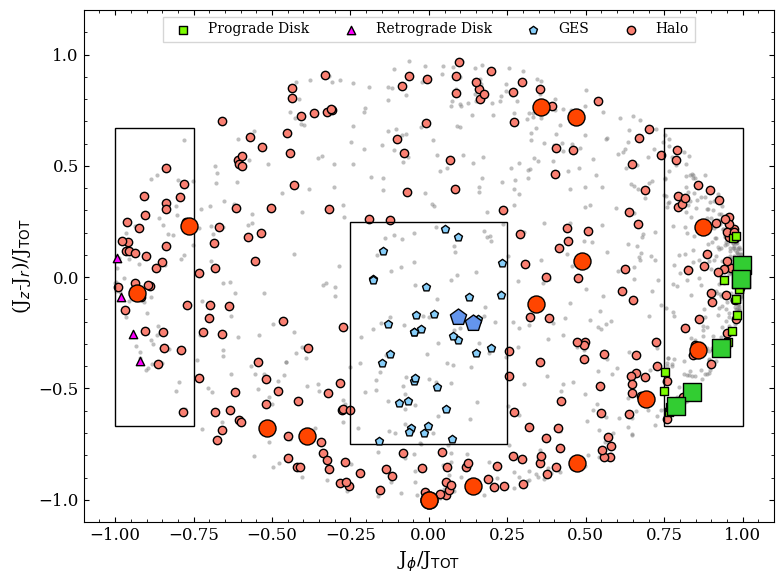

In [ ]:
plt.figure(figsize=(8, 6))

# Plotting the literature orbits
plt.scatter(lit_disk_pro['jp']/lit_disk_pro['jtot'], (lit_disk_pro['jz']-lit_disk_pro['jr'])/lit_disk_pro['jtot'], color='lawngreen', label='Prograde Disk', alpha=1, marker='s', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_disk_pro['jp']/lit_disk_ret['jtot'], (lit_disk_ret['jz']-lit_disk_ret['jr'])/lit_disk_ret['jtot'], color='fuchsia', label='Retrograde Disk', alpha=1, marker='^', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_ges['jp']/lit_ges['jtot'], (lit_ges['jz']-lit_ges['jr'])/lit_ges['jtot'], color='lightskyblue', label='GES', alpha=1, marker='p', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_halo['jp']/lit_halo['jtot'], (lit_halo['jz']-lit_halo['jr'])/lit_halo['jtot'], color='salmon', label='Halo', alpha=1, linewidths=1, edgecolors='black')

# Plotting the X-Shooter orbits
plt.scatter(pro_disk['jp']/pro_disk['jtot'], (pro_disk['jz']-pro_disk['jr'])/pro_disk['jtot'], color='limegreen', alpha=1, marker='s', edgecolor='black', s=150, zorder=15)
plt.scatter(gse['jp']/gse['jtot'], (gse['jz']-gse['jr'])/gse['jtot'], color='cornflowerblue', alpha=1, marker='p', edgecolor='black', s=150, zorder=15)
plt.scatter(halo['jp']/halo['jtot'], (halo['jz']-halo['jr'])/halo['jtot'], color='orangered', alpha=1, marker='o', edgecolor='black', s=150, zorder=15)

# Plotting the AAT orbits
# plt.scatter(aat_orb_df_fehm20['jp']/aat_orb_df_fehm20['jtot'], (aat_orb_df_fehm20['jz']-aat_orb_df_fehm20['jr'])/aat_orb_df_fehm20['jtot'], color='grey', alpha=0.5, marker='.', linewidths=0, zorder=0)
plt.scatter(aat_orb_df_fehm20['jp']/aat_orb_df_fehm20['jtot'], (aat_orb_df_fehm20['jz']-aat_orb_df_fehm20['jr'])/aat_orb_df_fehm20['jtot'], color='grey', alpha=0.5, marker='.', linewidths=0, zorder=0)


# Making the boxes
rect_ret = patches.Rectangle(xy=(-1,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_ret)
rect_pro = patches.Rectangle(xy=(0.75,-0.67), width=0.25, height=1.34, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_pro)
rect_gse = patches.Rectangle(xy=(-0.25,-0.75), width=0.5, height=1.0, edgecolor='black', facecolor='None')
plt.gca().add_patch(rect_gse)

plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.2)
plt.xlabel(r'J$_{\phi}$/J$_{\rm TOT}$')
plt.ylabel(r'(J$_{z}$-J$_{r}$)/J$_{\rm TOT}$')
plt.legend(loc='upper center', ncol=4, fontsize='small', fancybox=False)
plt.tight_layout()
# plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/orbits_circle_AATfehm200.png', dpi=300, bbox_inches='tight')
# plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/orbits_circle_AATfehm200.pdf', dpi=300, bbox_inches='tight')

### Lz vs E

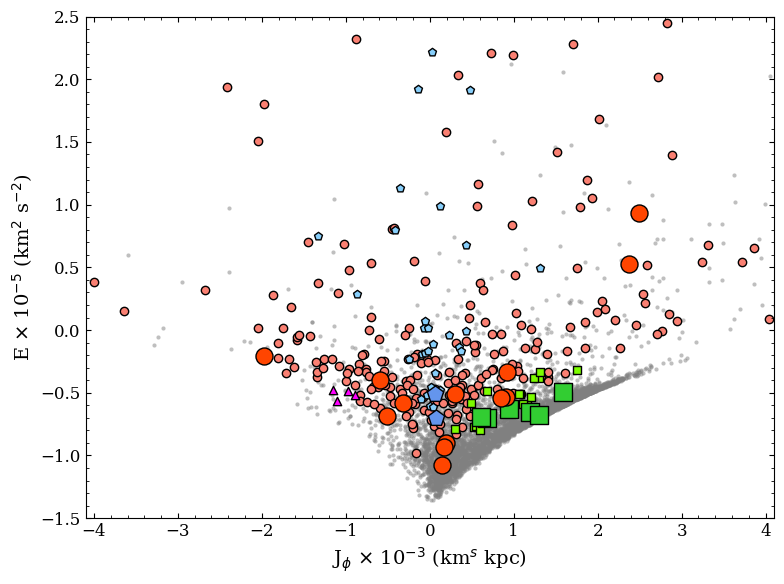

In [123]:
plt.figure(figsize=(8, 6))

# Plotting the literature orbits
plt.scatter(lit_disk_pro['jp']/1e3, lit_disk_pro['E']/1e5, color='lawngreen', label='Prograde Disk', alpha=1, marker='s', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_disk_ret['jp']/1e3, lit_disk_ret['E']/1e5, color='fuchsia', label='Retrograde Disk', alpha=1, marker='^', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_ges['jp']/1e3, lit_ges['E']/1e5, color='lightskyblue', label='GES', alpha=1, marker='p', zorder=10, linewidths=1, edgecolor='black')
plt.scatter(lit_halo['jp']/1e3, lit_halo['E']/1e5, color='salmon', label='Halo', alpha=1, linewidths=1, edgecolors='black')

# Plotting the X-Shooter orbits
plt.scatter(pro_disk['jp']/1e3, pro_disk['E']/1e5, color='limegreen', alpha=1, marker='s', edgecolor='black', s=150, zorder=15)
plt.scatter(gse['jp']/1e3, gse['E']/1e5, color='cornflowerblue', alpha=1, marker='p', edgecolor='black', s=150, zorder=15)
plt.scatter(halo['jp']/1e3, halo['E']/1e5, color='orangered', alpha=1, marker='o', edgecolor='black', s=150, zorder=15)

# Plotting the AAT orbits
plt.scatter(aat_orb_df['jp']/1e3, aat_orb_df['E']/1e5, color='grey', alpha=0.5, marker='.', linewidths=0, zorder=0)
plt.xlim(-4.1, 4.1)
plt.ylim(-1.5, 2.5)
plt.xlabel(r'J$_{\phi}$ $\times$ 10$^{-3}$ (km$^{s}$ kpc)')
plt.ylabel(r'E $\times$ 10$^{-5}$ (km$^2$ s$^{-2}$)')
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/lz_vs_E.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/lz_vs_E.pdf', dpi=300, bbox_inches='tight')

### e vs E

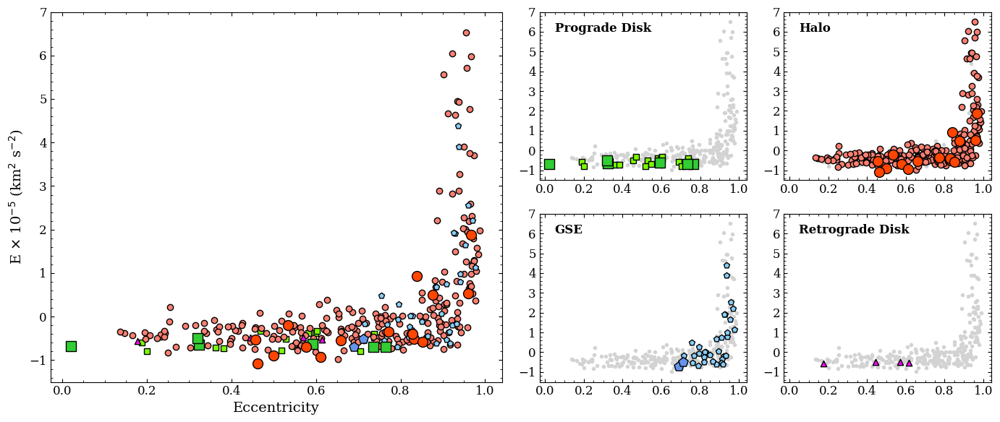

In [68]:
# Create a figure
fig = plt.figure(figsize=(14, 6))

# Define a GridSpec layout with 3 rows and 5 columns
gs = mpl.gridspec.GridSpec(2, 4, wspace=0.15, width_ratios=[0.5, 0.5, 0.5, 0.5])

# Add subplots using the GridSpec object
ax1 = fig.add_subplot(gs[0:2, 0:2])  # Row 0, Column 0:2
ax2 = fig.add_subplot(gs[0, 2], sharex=ax1, sharey=ax1)  # Row 0, Column 2
ax3 = fig.add_subplot(gs[0, 3], sharex=ax1, sharey=ax1)  # Row 0, Column 3
ax4 = fig.add_subplot(gs[1, 2], sharex=ax1, sharey=ax1)  # Row 1, Column 2
ax5 = fig.add_subplot(gs[1, 3], sharex=ax1, sharey=ax1)  # Row 1, Column 3


# --- SUBPLOT 1: WHOLE SAMPLE--- #
ax1.scatter(pro_disk['e'], pro_disk['E']/1e5, color='limegreen', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax1.scatter(halo['e'], halo['E']/1e5, color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax1.scatter(gse['e'], gse['E']/1e5, color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)

ax1.scatter(lit_disk_pro['e'], lit_disk_pro['E']/1e5, color='lawngreen', marker='s', edgecolor='black', zorder=5, linewidths=1)
ax1.scatter(lit_halo['e'], lit_halo['E']/1e5, color='salmon', marker='o', edgecolor='black', zorder=5, linewidths=1)
ax1.scatter(lit_ges['e'], lit_ges['E']/1e5, color='lightskyblue', marker='p', edgecolor='black', zorder=5, linewidths=1)
ax1.scatter(lit_disk_ret['e'], lit_disk_ret['E']/1e5, color='fuchsia', marker='^', edgecolor='black', zorder=5, linewidths=1)

ax1.set_ylim(-1.5, 7)
ax1.set_xlabel('Eccentricity')
ax1.set_ylabel(r'E $\times$ 10$^{-5}$ (km$^2$ s$^{-2}$)')

# --- SUBPLOT 2: PROGRADE DISK --- #
ax2.scatter(lit_combined['e'], lit_combined['E']/1e5, c="lightgrey", marker='.', zorder=1)

ax2.scatter(pro_disk['e'], pro_disk['E']/1e5, color='limegreen', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax2.scatter(lit_disk_pro['e'], lit_disk_pro['E']/1e5, color='lawngreen', marker='s', edgecolor='black', zorder=5, linewidths=1)

ax2.text(0.05, 6, 'Prograde Disk', fontsize=12, fontweight='bold', ha='left')


# --- SUBPLOT 3: HALO --- #
ax3.scatter(lit_combined['e'], lit_combined['E']/1e5, c="lightgrey", marker='.', zorder=1)

ax3.scatter(halo['e'], halo['E']/1e5, color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax3.scatter(lit_halo['e'], lit_halo['E']/1e5, color='salmon', marker='o', edgecolor='black', zorder=5, linewidths=1)

ax3.text(0.05, 6, 'Halo', fontsize=12, fontweight='bold', ha='left')


# --- SUBPLOT 4: GSE --- #
ax4.scatter(lit_combined['e'], lit_combined['E']/1e5, c="lightgrey", marker='.', zorder=1)

ax4.scatter(gse['e'], gse['E']/1e5, color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax4.scatter(lit_ges['e'], lit_ges['E']/1e5, color='lightskyblue', marker='p', edgecolor='black', zorder=5, linewidths=1)    

ax4.text(0.05, 6, 'GSE', fontsize=12, fontweight='bold', ha='left')


# --- SUBPLOT 5: Retrograde Disk --- #
ax5.scatter(lit_combined['e'], lit_combined['E']/1e5, c="lightgrey", marker='.', zorder=1)

ax5.scatter(lit_disk_ret['e'], lit_disk_ret['E']/1e5, color='fuchsia', marker='^', edgecolor='black', zorder=5, linewidths=1) 

ax5.text(0.05, 6, 'Retrograde Disk', fontsize=12, fontweight='bold', ha='left')

gs.tight_layout(fig)
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/eccentricity_vs_energy.png', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/eccentricity_vs_energy.pdf', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')

### MDF

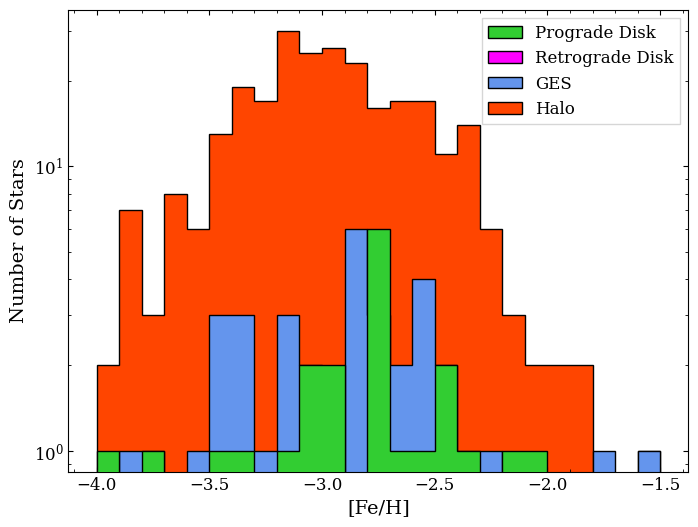

In [86]:
# Combining the X-Shooter and Literature data into one DataFrame
all_prodisk = pd.concat([pro_disk, lit_disk_pro], ignore_index=True)
all_retdisk = pd.concat([ret_disk], ignore_index=True)
all_halo = pd.concat([halo, lit_halo], ignore_index=True)
all_gse = pd.concat([gse, lit_ges], ignore_index=True)

bin_size = 0.1  # Specify the bin size
bins = np.arange(-4.0, -1.5 + bin_size, bin_size)

plt.figure(figsize=(8, 6))
plt.hist(all_prodisk['feh'], bins=bins, color='limegreen', alpha=1, label='Prograde Disk', histtype='stepfilled', edgecolor='black', ec='k', zorder=3)
plt.hist(all_retdisk['feh'], bins=bins, color='fuchsia', alpha=1, label='Retrograde Disk', histtype='stepfilled', edgecolor='black', ec='k', zorder=4)
plt.hist(all_gse['feh'], bins=bins, color='cornflowerblue', alpha=1, label='GES', histtype='stepfilled', edgecolor='black', ec='k', zorder=2)
plt.hist(all_halo['feh'], bins=bins, color='orangered', alpha=1, label='Halo', histtype='stepfilled', edgecolor='black', ec='k', zorder=1)
plt.xlabel('[Fe/H]')
plt.ylabel('Number of Stars')
plt.yscale('log')
plt.legend(fancybox=False)
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/feh_histogram.png', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/orbits/feh_histogram.pdf', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')

In [90]:
all_gse['feh']

0    -3.350497
1    -3.893281
2    -3.280000
3    -3.310000
4    -2.870000
5    -2.780000
6    -3.790000
7    -1.590000
8    -2.870000
9    -3.400000
10   -2.220000
11   -3.180000
12   -2.640000
13   -3.180000
14   -3.030000
15   -2.580000
16   -2.710000
17   -2.500000
18   -2.320000
19   -2.610000
20   -2.400000
21   -3.490000
22   -3.350000
23   -2.530000
24   -1.710000
25   -2.580000
26   -2.890000
27   -2.460000
28   -2.810000
29   -2.870000
30   -3.420000
31   -2.840000
32   -2.720000
33   -3.000000
34   -3.570000
35   -3.150000
Name: feh, dtype: float64

### rmax vs zmax

(0.0, 20.0)

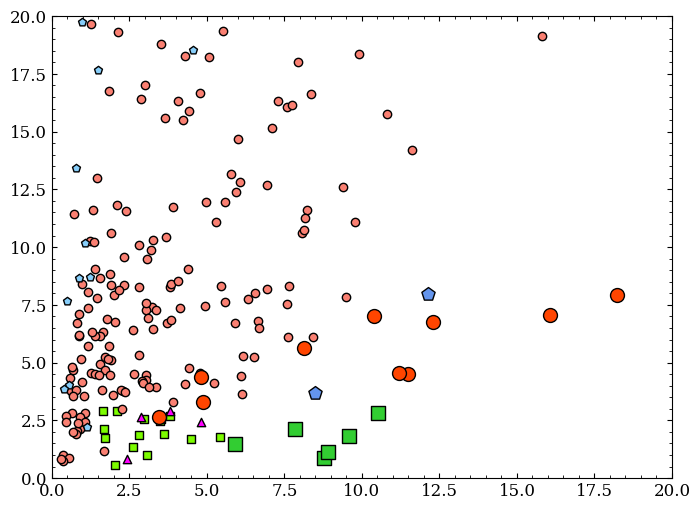

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(pro_disk['rmax'], pro_disk['zmax'], color='limegreen', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='Prograde Disk')
plt.scatter(halo['rmax'], halo['zmax'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='Halo')
plt.scatter(gse['rmax'], gse['zmax'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='GSE')

plt.scatter(lit_disk_pro['rmax'], lit_disk_pro['zmax'], color='lawngreen', marker='s', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_halo['rmax'], lit_halo['zmax'], color='salmon', marker='o', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_ges['rmax'], lit_ges['zmax'], color='lightskyblue', marker='p', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_disk_ret['rmax'], lit_disk_ret['zmax'], color='fuchsia', marker='^', edgecolor='black', zorder=5, linewidths=1)

plt.ylim(0, 20)
plt.xlim(0, 20)

## Making abundance plots

In [19]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_xshooter_abunds = [comb_xshooter_data['C_I'], comb_xshooter_data['N_I'], comb_xshooter_data['Na_I'], comb_xshooter_data['Mg_I'], comb_xshooter_data['Al_I'], comb_xshooter_data['Si_I'], comb_xshooter_data['Ca_II'], comb_xshooter_data['Sc_II'],
                  comb_xshooter_data['Ti_II'], comb_xshooter_data['Cr_I'], comb_xshooter_data['Mn_I'], comb_xshooter_data['Co_I'], comb_xshooter_data['Ni_I'], 
                  comb_xshooter_data['Sr_II'], comb_xshooter_data['Ba_II'], comb_xshooter_data['Eu_II']]

all_lit_abunds = [cI_lit_abunds, nI_lit_abunds, naI_lit_abunds, mgI_lit_abunds, alI_lit_abunds, siI_lit_abunds, caI_lit_abunds,
                  scII_lit_abunds, tiII_lit_abunds, crI_lit_abunds, mnI_lit_abunds, coI_lit_abunds, niI_lit_abunds, 
                  srII_lit_abunds, baII_lit_abunds, euII_lit_abunds]

all_lit_orbabunds = [cI_lit_orbabunds, nI_lit_orbabunds, naI_lit_orbabunds, mgI_lit_orbabunds, alI_lit_orbabunds, siI_lit_orbabunds, caI_lit_orbabunds,
                     scII_lit_orbabunds, tiII_lit_orbabunds, crI_lit_orbabunds, mnI_lit_orbabunds, coI_lit_orbabunds, niI_lit_orbabunds,
                     srII_lit_orbabunds, baII_lit_orbabunds, euII_lit_orbabunds]

In [27]:
comb_xshooter_data['C_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/C_I_allabunds.csv', index=False)
comb_xshooter_data['N_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/N_I_allabunds.csv', index=False)
comb_xshooter_data['Na_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Na_I_allabunds.csv', index=False)
comb_xshooter_data['Mg_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mg_I_allabunds.csv', index=False)
comb_xshooter_data['Al_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Al_I_allabunds.csv', index=False)
comb_xshooter_data['Si_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Si_I_allabunds.csv', index=False)
comb_xshooter_data['Ca_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ca_II_allabunds.csv', index=False)
comb_xshooter_data['Sc_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sc_II_allabunds.csv', index=False)
comb_xshooter_data['Ti_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ti_II_allabunds.csv', index=False)
comb_xshooter_data['Cr_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Cr_I_allabunds.csv', index=False)
comb_xshooter_data['Mn_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mn_I_allabunds.csv', index=False)
comb_xshooter_data['Co_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Co_I_allabunds.csv', index=False)
comb_xshooter_data['Ni_I'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ni_I_allabunds.csv', index=False)
comb_xshooter_data['Sr_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sr_II_allabunds.csv', index=False)
comb_xshooter_data['Ba_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ba_II_allabunds.csv', index=False)
comb_xshooter_data['Eu_II'].to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Eu_II_allabunds.csv', index=False)

### [Fe/H] vs [X/Fe]

#### Prograde disk

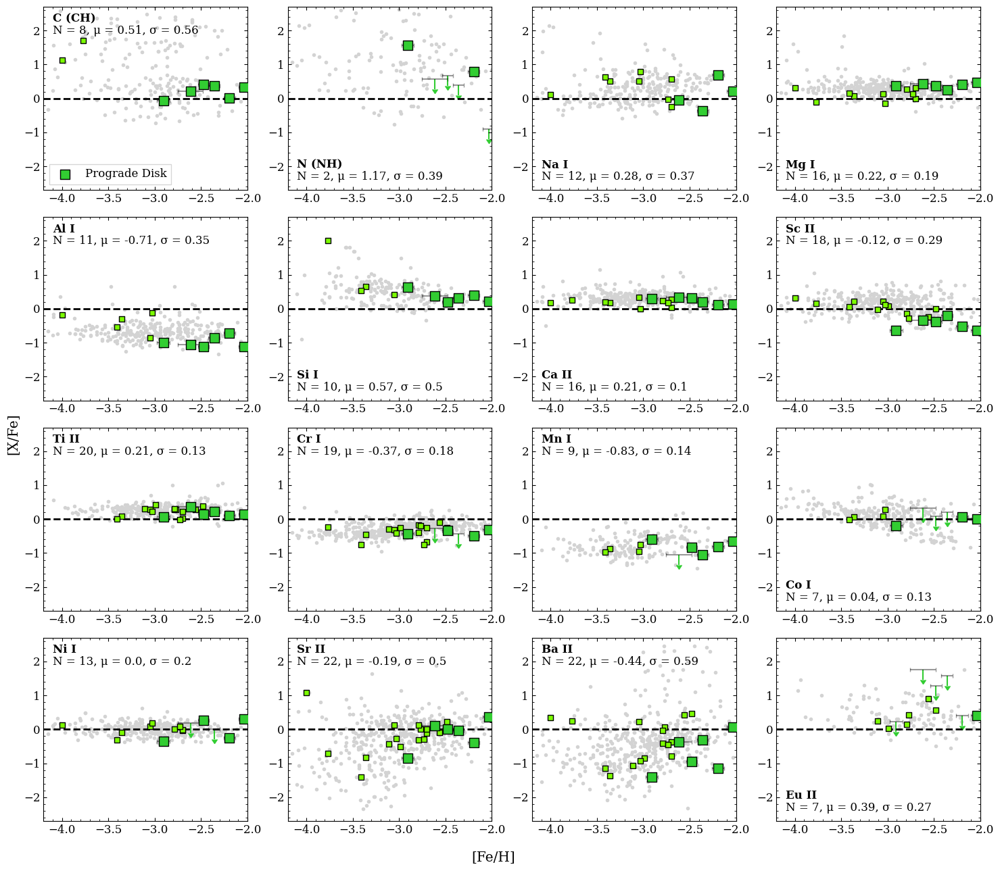

In [ ]:
fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # X-Shooter data
    abund_xshooter_df = all_xshooter_abunds[el_index]
    
    abund_xshooter_detect = abund_xshooter_df[abund_xshooter_df['detection'] == 'Y']
    abund_xshooter_detect_prodisk = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'pro_disk']
    # abund_xshooter_detect_halo = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'halo']
    # abund_xshooter_detect_gse = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'gse']
    
    abund_xshooter_nondetect = abund_xshooter_df[abund_xshooter_df['detection'] == 'N']
    abund_xshooter_nondetect_prodisk = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'pro_disk']
    # abund_xshooter_nondetect_halo = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'halo']
    # abund_xshooter_nondetect_gse = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'gse']    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    # Getting the literature data for elements with orbital classifications (this is a subset of the above dataframe)
    lit_orbabund_df = all_lit_orbabunds[el_index]
    lit_orbabund_df = lit_orbabund_df.drop_duplicates(subset='star_id')  # Drop duplicate rows based on 'star_id'
    
    lit_orbabund_prodisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'pro_disk']
    # lit_orbabund_halo = lit_orbabund_df[lit_orbabund_df['orbit'] == 'halo']
    # lit_orbabund_gse = lit_orbabund_df[lit_orbabund_df['orbit'] == 'gse']
    # lit_orbabund_retdisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'ret_disk']
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting literature data with orbits
    ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)
    
    
    # xshooter data
    alpha_xshooter = 1
    alpha_xshooter_err = 0.4
    
    # Plotting observed data (detections)
    ax.scatter(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
               marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], xerr=abund_xshooter_detect_prodisk['feh_err'],
               yerr=abund_xshooter_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
    #            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], xerr=abund_xshooter_detect_halo['feh_err'],
    #            yerr=abund_xshooter_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
    #            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], xerr=abund_xshooter_detect_gse['feh_err'],
    #            yerr=abund_xshooter_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], 
                xerr=abund_xshooter_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    # Combining the dataframes for both x-shooter and literature data with orbits, for calculating the mean and stddev to put on the plot
    lit_rename_df = lit_orbabund_prodisk.rename(columns={'abund': 'bestfit_abund_xfe'})
    num_df = pd.concat([abund_xshooter_detect_prodisk, lit_rename_df], ignore_index=True)

    
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_prodisk_v2.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_prodisk_v2.png", dpi=300, transparent=False, facecolor="white")



#### Halo

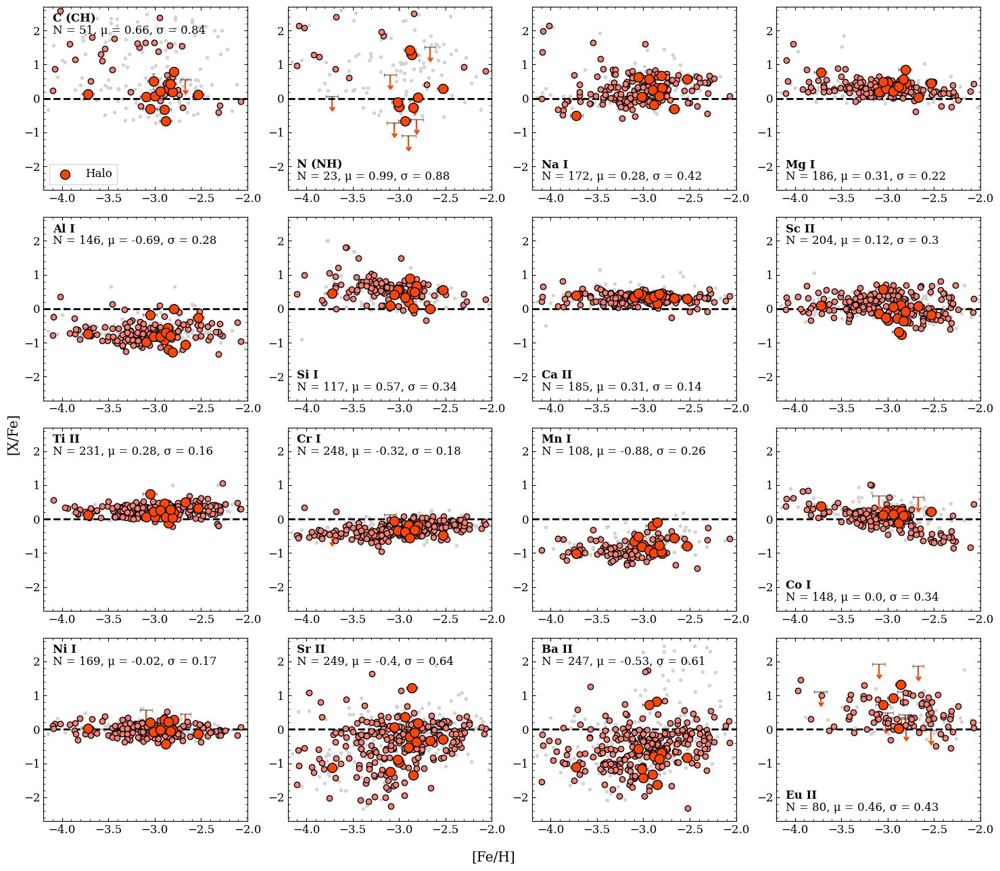

In [ ]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_xshooter_abunds = [comb_xshooter_data['C_I'], comb_xshooter_data['N_I'], comb_xshooter_data['Na_I'], comb_xshooter_data['Mg_I'], comb_xshooter_data['el_I'], comb_xshooter_data['Si_I'], comb_xshooter_data['Ca_II'], comb_xshooter_data['Sc_II'],
                  comb_xshooter_data['Ti_II'], comb_xshooter_data['Cr_I'], comb_xshooter_data['Mn_I'], comb_xshooter_data['Co_I'], comb_xshooter_data['Ni_I'], 
                  comb_xshooter_data['Sr_II'], comb_xshooter_data['Ba_II'], comb_xshooter_data['Eu_II']]

all_lit_abunds = [cI_lit_abunds, nI_lit_abunds, naI_lit_abunds, mgI_lit_abunds, alI_lit_abunds, siI_lit_abunds, caI_lit_abunds,
                  scII_lit_abunds, tiII_lit_abunds, crI_lit_abunds, mnI_lit_abunds, coI_lit_abunds, niI_lit_abunds, 
                  srII_lit_abunds, baII_lit_abunds, euII_lit_abunds]

all_lit_orbabunds = [cI_lit_orbabunds, nI_lit_orbabunds, naI_lit_orbabunds, mgI_lit_orbabunds, alI_lit_orbabunds, siI_lit_orbabunds, caI_lit_orbabunds,
                     scII_lit_orbabunds, tiII_lit_orbabunds, crI_lit_orbabunds, mnI_lit_orbabunds, coI_lit_orbabunds, niI_lit_orbabunds,
                     srII_lit_orbabunds, baII_lit_orbabunds, euII_lit_orbabunds]


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # X-Shooter data
    abund_xshooter_df = all_xshooter_abunds[el_index]
    
    abund_xshooter_detect = abund_xshooter_df[abund_xshooter_df['detection'] == 'Y']
    # abund_xshooter_detect_prodisk = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'pro_disk']
    abund_xshooter_detect_halo = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'halo']
    # abund_xshooter_detect_gse = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'gse']
    
    abund_xshooter_nondetect = abund_xshooter_df[abund_xshooter_df['detection'] == 'N']
    # abund_xshooter_nondetect_prodisk = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'pro_disk']
    abund_xshooter_nondetect_halo = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'halo']
    # abund_xshooter_nondetect_gse = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'gse']    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    # Getting the literature data for elements with orbital classifications (this is a subset of the above dataframe)
    lit_orbabund_df = all_lit_orbabunds[el_index]
    
    # lit_orbabund_prodisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'pro_disk']
    lit_orbabund_halo = lit_orbabund_df[lit_orbabund_df['orbit'] == 'halo']
    # lit_orbabund_gse = lit_orbabund_df[lit_orbabund_df['orbit'] == 'gse']
    # lit_orbabund_retdisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'ret_disk']
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting literature data with orbits
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)
    
    
    # xshooter data
    alpha_xshooter = 1
    alpha_xshooter_err = 0.4
    
    # Plotting observed data (detections)
    # ax.scatter(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
    #            marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], xerr=abund_xshooter_detect_prodisk['feh_err'],
    #            yerr=abund_xshooter_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    ax.scatter(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
               marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], xerr=abund_xshooter_detect_halo['feh_err'],
               yerr=abund_xshooter_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
    #            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], xerr=abund_xshooter_detect_gse['feh_err'],
    #            yerr=abund_xshooter_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], 
                xerr=abund_xshooter_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    # Combining the dataframes for both x-shooter and literature data with orbits, for calculating the mean and stddev to put on the plot
    lit_rename_df = lit_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
    num_df = pd.concat([abund_xshooter_detect_halo, lit_rename_df], ignore_index=True)

    
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_halo_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_halo_v2.png", dpi=300, transparent=False, facecolor="white")



#### GSE

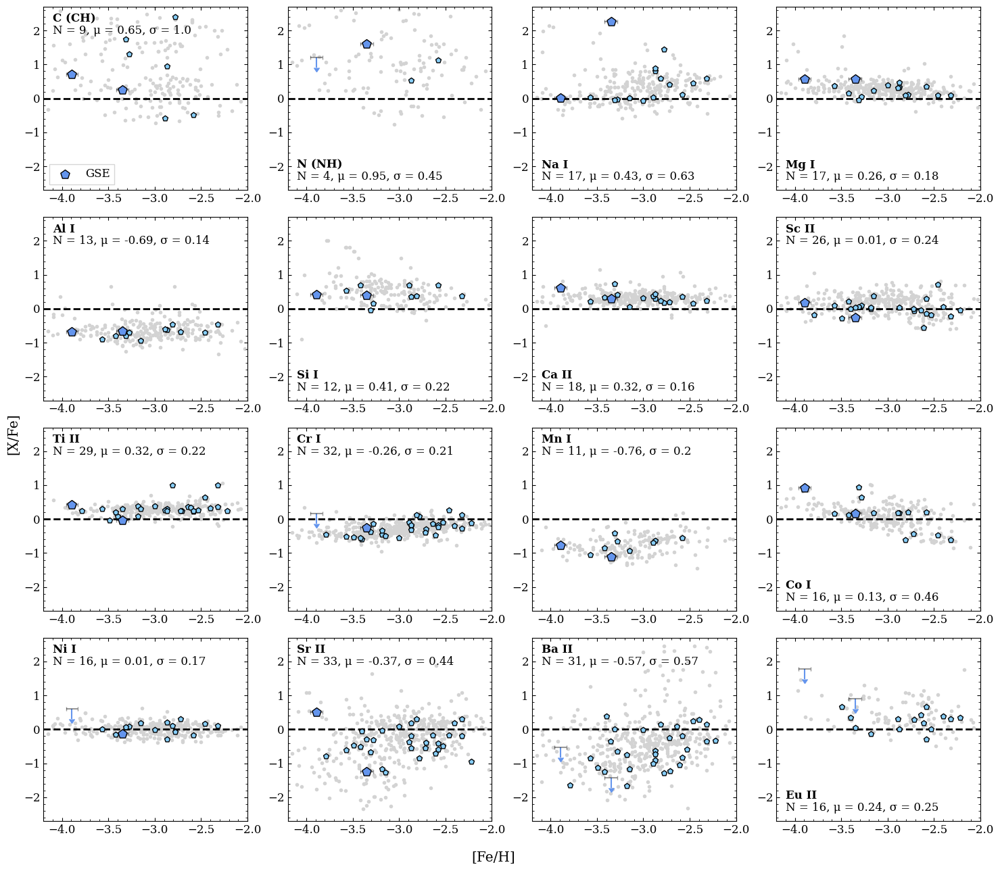

In [ ]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_xshooter_abunds = [comb_xshooter_data['C_I'], comb_xshooter_data['N_I'], comb_xshooter_data['Na_I'], comb_xshooter_data['Mg_I'], comb_xshooter_data['el_I'], comb_xshooter_data['Si_I'], comb_xshooter_data['Ca_II'], comb_xshooter_data['Sc_II'],
                  comb_xshooter_data['Ti_II'], comb_xshooter_data['Cr_I'], comb_xshooter_data['Mn_I'], comb_xshooter_data['Co_I'], comb_xshooter_data['Ni_I'], 
                  comb_xshooter_data['Sr_II'], comb_xshooter_data['Ba_II'], comb_xshooter_data['Eu_II']]

all_lit_abunds = [cI_lit_abunds, nI_lit_abunds, naI_lit_abunds, mgI_lit_abunds, alI_lit_abunds, siI_lit_abunds, caI_lit_abunds,
                  scII_lit_abunds, tiII_lit_abunds, crI_lit_abunds, mnI_lit_abunds, coI_lit_abunds, niI_lit_abunds, 
                  srII_lit_abunds, baII_lit_abunds, euII_lit_abunds]

all_lit_orbabunds = [cI_lit_orbabunds, nI_lit_orbabunds, naI_lit_orbabunds, mgI_lit_orbabunds, alI_lit_orbabunds, siI_lit_orbabunds, caI_lit_orbabunds,
                     scII_lit_orbabunds, tiII_lit_orbabunds, crI_lit_orbabunds, mnI_lit_orbabunds, coI_lit_orbabunds, niI_lit_orbabunds,
                     srII_lit_orbabunds, baII_lit_orbabunds, euII_lit_orbabunds]


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # X-Shooter data
    abund_xshooter_df = all_xshooter_abunds[el_index]
    
    abund_xshooter_detect = abund_xshooter_df[abund_xshooter_df['detection'] == 'Y']
    # abund_xshooter_detect_prodisk = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'pro_disk']
    # abund_xshooter_detect_halo = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'halo']
    abund_xshooter_detect_gse = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'gse']
    
    abund_xshooter_nondetect = abund_xshooter_df[abund_xshooter_df['detection'] == 'N']
    # abund_xshooter_nondetect_prodisk = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'pro_disk']
    # abund_xshooter_nondetect_halo = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'halo']
    abund_xshooter_nondetect_gse = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'gse']    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    # Getting the literature data for elements with orbital classifications (this is a subset of the above dataframe)
    lit_orbabund_df = all_lit_orbabunds[el_index]
    
    # lit_orbabund_prodisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'pro_disk']
    # lit_orbabund_halo = lit_orbabund_df[lit_orbabund_df['orbit'] == 'halo']
    lit_orbabund_gse = lit_orbabund_df[lit_orbabund_df['orbit'] == 'gse']
    # lit_orbabund_retdisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'ret_disk']
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting literature data with orbits
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)
    
    
    # xshooter data
    alpha_xshooter = 1
    alpha_xshooter_err = 0.4
    
    # Plotting observed data (detections)
    # ax.scatter(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
    #            marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], xerr=abund_xshooter_detect_prodisk['feh_err'],
    #            yerr=abund_xshooter_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
    #            marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], xerr=abund_xshooter_detect_halo['feh_err'],
    #            yerr=abund_xshooter_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    ax.scatter(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
               marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], xerr=abund_xshooter_detect_gse['feh_err'],
               yerr=abund_xshooter_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_xshooter)
    ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], 
                xerr=abund_xshooter_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    # Combining the dataframes for both x-shooter and literature data with orbits, for calculating the mean and stddev to put on the plot
    lit_rename_df = lit_orbabund_gse.rename(columns={'abund': 'bestfit_abund_xfe'})
    num_df = pd.concat([abund_xshooter_detect_gse, lit_rename_df], ignore_index=True)

    
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_gse_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_gse_v2.png", dpi=300, transparent=False, facecolor="white")



#### Retrograde disk

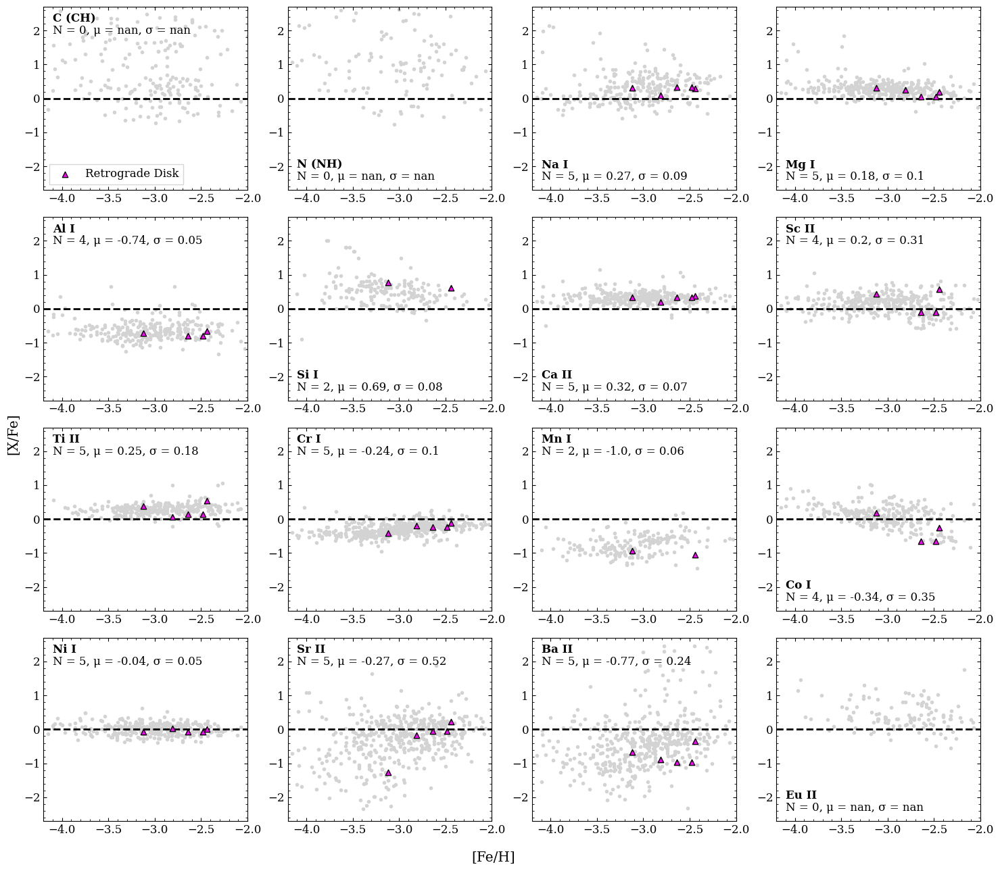

In [ ]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_xshooter_abunds = [comb_xshooter_data['C_I'], comb_xshooter_data['N_I'], comb_xshooter_data['Na_I'], comb_xshooter_data['Mg_I'], comb_xshooter_data['el_I'], comb_xshooter_data['Si_I'], comb_xshooter_data['Ca_II'], comb_xshooter_data['Sc_II'],
                  comb_xshooter_data['Ti_II'], comb_xshooter_data['Cr_I'], comb_xshooter_data['Mn_I'], comb_xshooter_data['Co_I'], comb_xshooter_data['Ni_I'], 
                  comb_xshooter_data['Sr_II'], comb_xshooter_data['Ba_II'], comb_xshooter_data['Eu_II']]

all_lit_abunds = [cI_lit_abunds, nI_lit_abunds, naI_lit_abunds, mgI_lit_abunds, alI_lit_abunds, siI_lit_abunds, caI_lit_abunds,
                  scII_lit_abunds, tiII_lit_abunds, crI_lit_abunds, mnI_lit_abunds, coI_lit_abunds, niI_lit_abunds, 
                  srII_lit_abunds, baII_lit_abunds, euII_lit_abunds]

all_lit_orbabunds = [cI_lit_orbabunds, nI_lit_orbabunds, naI_lit_orbabunds, mgI_lit_orbabunds, alI_lit_orbabunds, siI_lit_orbabunds, caI_lit_orbabunds,
                     scII_lit_orbabunds, tiII_lit_orbabunds, crI_lit_orbabunds, mnI_lit_orbabunds, coI_lit_orbabunds, niI_lit_orbabunds,
                     srII_lit_orbabunds, baII_lit_orbabunds, euII_lit_orbabunds]


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # X-Shooter data
    abund_xshooter_df = all_xshooter_abunds[el_index]
    
    abund_xshooter_detect = abund_xshooter_df[abund_xshooter_df['detection'] == 'Y']
    # abund_xshooter_detect_prodisk = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'pro_disk']
    # abund_xshooter_detect_halo = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'halo']
    # abund_xshooter_detect_gse = abund_xshooter_detect[abund_xshooter_detect['orbit'] == 'gse']
    
    abund_xshooter_nondetect = abund_xshooter_df[abund_xshooter_df['detection'] == 'N']
    # abund_xshooter_nondetect_prodisk = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'pro_disk']
    # abund_xshooter_nondetect_halo = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'halo']
    # abund_xshooter_nondetect_gse = abund_xshooter_nondetect[abund_xshooter_nondetect['orbit'] == 'gse']    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    # Getting the literature data for elements with orbital classifications (this is a subset of the above dataframe)
    lit_orbabund_df = all_lit_orbabunds[el_index]
    
    # lit_orbabund_prodisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'pro_disk']
    # lit_orbabund_halo = lit_orbabund_df[lit_orbabund_df['orbit'] == 'halo']
    # lit_orbabund_gse = lit_orbabund_df[lit_orbabund_df['orbit'] == 'gse']
    lit_orbabund_retdisk = lit_orbabund_df[lit_orbabund_df['orbit'] == 'ret_disk']
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting literature data with orbits
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    
    # xshooter data
    alpha_xshooter = 1
    alpha_xshooter_err = 0.4
    
    # Plotting observed data (detections)
    # ax.scatter(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
    #            marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_prodisk['feh'], abund_xshooter_detect_prodisk['bestfit_abund_xfe'], xerr=abund_xshooter_detect_prodisk['feh_err'],
    #            yerr=abund_xshooter_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
    #            marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_halo['feh'], abund_xshooter_detect_halo['bestfit_abund_xfe'], xerr=abund_xshooter_detect_halo['feh_err'],
    #            yerr=abund_xshooter_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.scatter(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
    #            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_detect_gse['feh'], abund_xshooter_detect_gse['bestfit_abund_xfe'], xerr=abund_xshooter_detect_gse['feh_err'],
    #            yerr=abund_xshooter_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_xshooter_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_prodisk['feh'], abund_xshooter_nondetect_prodisk['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_halo['feh'], abund_xshooter_nondetect_halo['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
    #             uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_xshooter)
    # ax.errorbar(abund_xshooter_nondetect_gse['feh'], abund_xshooter_nondetect_gse['upper_limit_xfe'], 
    #             xerr=abund_xshooter_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_xshooter_err)
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    # Combining the dataframes for both x-shooter and literature data with orbits, for calculating the mean and stddev to put on the plot
    num_df = lit_orbabund_retdisk.rename(columns={'abund': 'bestfit_abund_xfe'})

    
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(num_df)}, μ = {round(np.mean(num_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(num_df['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_retdisk.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_retdisk.png", dpi=300, transparent=False, facecolor="white")



### Separated by kinematic groups

In [45]:
def plot_feh_xfe_comparison(all_xshooter_abunds, all_lit_abunds, all_lit_orbabunds, el, el_list, xlim, ylim,
                            text_pos1, text_pos2, text_pos3, text_hozalign, ul_size=None, save_path=None, delta_chisqr_save_path=None,
                            sculptor=None, galah=False, apogee=False, halo_background=None, galah_save_path=None, 
                            halo_fit_save_path=None, stat_save_path=None, cdf_save_path=None, z_score_save_path=None,
                            gce=False, gce_save_path=None):
    """Makes a 2x2 plot showing [Fe/H] vs [X/Fe] abundaces for the different kinematic groups: prograde disk, halo,
    GSE and retrograde disk.

    Parameters
    ----------
    all_xshooter_abunds : list
        List of dataframes containing the X-Shooter abundance data for each element, in the same order as el_list
    all_lit_abunds : list
        List of dataframes containing the literature abundance data for each element, in the same order as el_list
    all_lit_orbabunds : list
        List of dataframes containing the literature abundance data with orbital classifications for each element, 
        in the same order as el_list
    el : str
        Desired element to plot (e.g. 'Al')
    el_list : list
        List of elements to plot, in the same order as the abundance dataframes in all_xshooter_abunds and all_lit_abunds
    xlim : tuple
        X-axis limits for the plot, in form (xmin, xmax)
    ylim : tuple
        Y-axis limits for the plot, in form (ymin, ymax)
    text_pos1 : tuple
        Position for text stating kinematic group, in form (x, y)
    text_pos2 : tuple
        Position for text stating the kinematic group's statistics (number of stars, mean and standard deviation), 
        in form (x, y)
    text_pos3 : tuple
        Position for text containing the 1-degree polynomial fit, in form (x, y)
    text_hozalign : str
        Horizontal alignment for the text (e.g. 'left', 'center', 'right')
    save_path : str, optional
        Path to save the plots. Give the directory and filename without the extension (e.g. "/path/to/plot/fe_xfe_comparison"). 
        Plots will be saved in both .png and .pdf format. By default None. If None, the plots will not be saved.
    sculptor : pd.DataFrame, optional
        Whether to show the xfe comparision with the Sculptor data (only for Al and Sc). Default is None. If None, the Sculptor data will not be plotted.
    save_chisq : bool, optional
        Whether to save the chi-squared values for the polynomial fits. Default is None. If None, the chi-squared values will not be saved. If True, the chi-squared values
        will be saved into a .csv file in the same directory as the plots.
    galah : bool, optional
        Whether to show the xfe comparision with the GALAH data. Default is False.
    apogee : bool, optional
        Whether to show the xfe comparision with the APOGEE data. Default is False.
    halo_background : bool, optional
        Whether to show the halo background in the plots. Default is False.
    galah_save_path : str, optional
        Path to save the GALAH comparison plots, if galah=True. Same format as save_path. If None, the GALAH comparison plots will not be saved.
    halo_fit_save_path : str, optional
        Path to save the halo fit comparison plots, if halo_background=True. Same format as save_path. If None, the halo fit comparison plots will not be saved.
    """
    
    # If galah, apogee or halo_background are all true, then need to inform the user that only one of these can be true at a time,
    # and return an error if more than one are true
    if galah and apogee:
        raise ValueError("galah and apogee cannot both be True. Please choose only one of these to be True.")
    if galah and halo_background:
        raise ValueError("galah and halo_background cannot both be True. Please choose only one of these to be True.")
    if apogee and halo_background:
        raise ValueError("apogee and halo_background cannot both be True. Please choose only one of these to be True.")
    if galah and halo_background and apogee:
        raise ValueError("galah, apogee and halo_background cannot all be True. Please choose only one of these to be True.")
    
    
    # Extracting the abundance data for the element
    # Getting index of element
    el_index = el_list.index(el)

    # X-Shooter
    el_xshooter_abund_all = all_xshooter_abunds[el_index]
    el_xshooter_abund_all = el_xshooter_abund_all.copy()
    
    # Renaming the error column to be consistent
    # NOTE: re-running this code breaks for some reason, so using try-except
    try:
        el_xshooter_abund_all.rename(columns={'bestfit_abund_comberr_xfe': 'abund_err'}, inplace=True)
    except KeyError:
        pass

    # For C - applying evolutionary corrections
    if el == 'C (CH)':
        el_xshooter_abund_all['bestfit_abund_xfe'] = el_xshooter_abund_all['bestfit_abund_xfe'] + el_xshooter_abund_all['cfe_corr']
    else:
        pass
    
    el_xshooter_abund_detect = el_xshooter_abund_all[el_xshooter_abund_all['detection'] == 'Y']
    el_xshooter_abund_prodisk = el_xshooter_abund_detect[el_xshooter_abund_detect['orbit'] == 'pro_disk']
    el_xshooter_abund_halo = el_xshooter_abund_detect[el_xshooter_abund_detect['orbit'] == 'halo']
    el_xshooter_abund_gse = el_xshooter_abund_detect[el_xshooter_abund_detect['orbit'] == 'gse']
    
    el_abund_nondetect = el_xshooter_abund_all[el_xshooter_abund_all['detection'] == 'N']
    el_xshooter_abund_nondetect_prodisk = el_abund_nondetect[el_abund_nondetect['orbit'] == 'pro_disk']
    el_xshooter_abund_nondetect_halo = el_abund_nondetect[el_abund_nondetect['orbit'] == 'halo']
    el_xshooter_abund_nondetect_gse = el_abund_nondetect[el_abund_nondetect['orbit'] == 'gse']
    
    
    # Literature
    el_lit_abund_all = all_lit_abunds[el_index]
    el_lit_orbabund_all = all_lit_orbabunds[el_index]
    
    # For literature stars with nans as errors, drop them
    el_lit_orbabund_all = el_lit_orbabund_all.dropna(subset=['abund_err'])
    
    # Some literature stars have an abundance error of 0 dex...
    # Will repalce these with 0.1 dex, typical for high-res abundance measurements
    el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
    
    
    # If True, load in the GALAH dataset
    if galah:
        el_galah = el.split(' ')[0].lower() + '_' + 'fe'
        el_galah_data = pd.read_csv(f"/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/abundance_orbits/galah_{el.split(' ')[0].lower()}fe_orbits.csv")
        el_galah_prodisk = el_galah_data[el_galah_data['orbit'] == 'prodisk']
        el_galah_halo = el_galah_data[el_galah_data['orbit'] == 'halo']
        el_galah_gse = el_galah_data[el_galah_data['orbit'] == 'gse']
        el_galah_retdisk = el_galah_data[el_galah_data['orbit'] == 'retdisk']
        
    # If True, load in the APOGEE dataset
    if apogee:
        el_apogee = el.split(' ')[0].lower() + '_' + 'fe'
        el_apogee_data = pd.read_csv(f"/data/misfit/benlowe/xshooter/lit_abund_data/apogee_dr19/apogee_{el.split(' ')[0].lower()}fe_orbits.csv")
        # el_apogee_data = el_apogee_data.dropna(subset=[el_apogee])
        el_apogee_prodisk = el_apogee_data[el_apogee_data['orbit'] == 'prodisk']
        el_apogee_halo = el_apogee_data[el_apogee_data['orbit'] == 'halo']
        el_apogee_gse = el_apogee_data[el_apogee_data['orbit'] == 'gse']
        el_apogee_retdisk = el_apogee_data[el_apogee_data['orbit'] == 'retdisk']
        

    
    # ---PLOT 1: OVERALL [FE/H] VS [X/FE] COMPARISON--- #
    # Setting up figure
    fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    fig.subplots_adjust(wspace=0.25)
    fig.supxlabel('[Fe/H]')
    
    if el == 'C (CH)' or el == 'N (NH)':
        fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    else:
        fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
    
    # If working with Galah data, extending the x-axis limits to accomodate the higher metallicity stars in the Galah sample
    # Will go to [Fe/H] = -1.3.
    if galah:
        xlim_galah = (xlim[0], -1.2)
        
        axs[0,0].set_xlim(xlim_galah)
        axs[0,0].set_ylim(ylim)
        axs[0,1].set_xlim(xlim_galah)
        axs[0,1].set_ylim(ylim)
        axs[1,0].set_xlim(xlim_galah)
        axs[1,0].set_ylim(ylim)
        axs[1,1].set_xlim(xlim_galah)
        axs[1,1].set_ylim(ylim)
        
        # For text with right horizontal alignment, need to adjust the x position to accomodate the extended x-axis limits
        if text_hozalign == 'right':
            text_galah_pos1 = (-1.3, text_pos1[1])
            text_galah_pos2 = (-1.3, text_pos2[1])
            text_galah_pos3 = (-1.3, text_pos3[1])
        
    else:
        axs[0,0].set_xlim(xlim)
        axs[0,0].set_ylim(ylim)
        axs[0,1].set_xlim(xlim)
        axs[0,1].set_ylim(ylim)
        axs[1,0].set_xlim(xlim)
        axs[1,0].set_ylim(ylim)
        axs[1,1].set_xlim(xlim)
        axs[1,1].set_ylim(ylim)
    
    # --SUBPLOT 1: HALO--- #
    ax = axs[0,0]
    lit_orbabund_halo = el_lit_orbabund_all[el_lit_orbabund_all['orbit'] == 'halo']
    lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
        
    # Fitting polynomial (both literature and x-shooter)
    halo_lit = lit_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
    comb_halo_df = pd.concat([el_xshooter_abund_halo, halo_lit], ignore_index=True)
    
    weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
    # p_halo, cov_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=True)
    p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=False)
    fit_halo = np.poly1d(p_halo)
    
    if galah:
        xline_halo = np.linspace(xlim_galah[0], xlim_galah[1], 100)
    else:
        xline_halo = np.linspace(xlim[0], xlim[1], 100)
    yline_halo = fit_halo(xline_halo)
    res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
    std_halo = np.std(res_halo)
    
    # # Getting uncertainty in gradient
    # m_halo = p_halo[0]
    # c_halo = p_halo[1]
    # m_err_halo = np.sqrt(cov_halo[0,0])
    # c_err_halo = np.sqrt(cov_halo[1,1])

    # yline_halo_pmerr = (m_halo + m_err_halo) * xline_halo + c_halo
    # yline_halo_mmerr = (m_halo - m_err_halo) * xline_halo + c_halo
    
    # yline_halo_c_pmerr = m_halo * xline_halo + (c_halo + c_err_halo)
    # yline_halo_c_pmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo + c_err_halo)
    # yline_halo_c_pmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo + c_err_halo)
    
    # yline_halo_c_mmerr = m_halo * xline_halo + (c_halo - c_err_halo)
    # yline_halo_c_mmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo - c_err_halo)
    # yline_halo_c_mmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo - c_err_halo)
    
    # # Plotting the background data
    # # (literature data, prograde disk and GSE stars)
    # ax.scatter(el_lit_abund_all['feh'], el_lit_abund_all['abund'], c="lightgrey", marker='.', zorder=1)
    # ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='grey', label='Prograde Disk', 
    #             marker='s', s=100, zorder=2, alpha=0.9, linewidths=0)
    # ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], xerr=el_xshooter_abund_prodisk['feh_err'],
    #             yerr=el_xshooter_abund_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)
    # ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='grey', label='GSE', 
    #             marker='p', s=100, zorder=2, alpha=0.9, linewidths=0)
    # ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], xerr=el_xshooter_abund_gse['feh_err'],
    #             yerr=el_xshooter_abund_gse['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)
    
    # Plotting the halo stars (literature and x-shooter)
    ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
            label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # Plotting the polynomial fit and 1-sigma bounds
    ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
    ax.fill_between(xline_halo, 
                        yline_halo - std_halo, 
                        yline_halo + std_halo, 
                        color='orangered', 
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # ax.fill_between(xline_halo, 
    #                     yline_halo_pmerr, 
    #                     yline_halo_mmerr, 
    #                     color='orangered', 
    #                     alpha=0.3)
    
    # ax.plot(xline_halo, yline_halo_c_pmerr, color='orangered', linestyle='--', linewidth=1)
    # ax.fill_between(xline_halo, 
    #                 yline_halo_c_pmerr_m_pmerr, 
    #                 yline_halo_c_pmerr_m_mmerr, 
    #                 color='orangered', 
    #                 alpha=0.15)
    
    # ax.plot(xline_halo, yline_halo_c_mmerr, color='orangered', linestyle='--', linewidth=1)
    # ax.fill_between(xline_halo, 
    #                 yline_halo_c_mmerr_m_pmerr, 
    #                 yline_halo_c_mmerr_m_mmerr, 
    #                 color='orangered', 
    #                 alpha=0.15)    
    
    
    
    # Plot Galah data if true
    if galah:
        ax.scatter(el_galah_halo['fe_h'], el_galah_halo[el_galah], color='grey', marker='o', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)
    
    # Making the text
    # For Galah, if the horizontal alignment is right, need to adjust the x position of the text to accomodate the extended x-axis limits
    if galah and text_hozalign == 'right':
        ax.text(-1.3, text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(-1.3, text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_halo[0] > 0:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    else: 
        ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_halo[0] > 0:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        

    
    
    # ---SUBPLOT 2: PROGRADE DISK--- #
    ax = axs[0,1]
    lit_orbabund_prodisk = el_lit_orbabund_all[el_lit_orbabund_all['orbit'] == 'pro_disk']
    lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)

    # Fitting polynomial (both literature and x-shooter)
    prodisk_lit = lit_orbabund_prodisk.rename(columns={'abund': 'bestfit_abund_xfe'})
    comb_prodisk_df = pd.concat([el_xshooter_abund_prodisk, prodisk_lit], ignore_index=True)
    
    weights_prodisk = 1 / np.sqrt(comb_prodisk_df['abund_err']**2 + np.std(comb_prodisk_df['bestfit_abund_xfe'])**2)    
    # p_prodisk, cov_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=True)
    p_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=False)
    fit_prodisk = np.poly1d(p_prodisk)
    
    if galah:
        xline_prodisk = np.linspace(xlim_galah[0], xlim_galah[1], 100)
    else:
        xline_prodisk = np.linspace(xlim[0], xlim[1], 100)

    yline_prodisk = fit_prodisk(xline_prodisk)
    res_prodisk = comb_prodisk_df['bestfit_abund_xfe'] - fit_prodisk(comb_prodisk_df['feh'])
    std_prodisk = np.std(res_prodisk)
    
    # # Getting uncertainty in gradient
    # m_prodisk = p_prodisk[0]
    # c_prodisk = p_prodisk[1]
    # m_err_prodisk = np.sqrt(cov_prodisk[0,0])
    # c_err_prodisk = np.sqrt(cov_prodisk[1,1])

    # yline_prodisk_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + c_prodisk
    # yline_prodisk_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + c_prodisk
    
    # yline_prodisk_c_pmerr = m_prodisk * xline_prodisk + (c_prodisk + c_err_prodisk)
    # yline_prodisk_c_pmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)
    # yline_prodisk_c_pmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)
    
    # yline_prodisk_c_mmerr = m_prodisk * xline_prodisk + (c_prodisk - c_err_prodisk)
    # yline_prodisk_c_mmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)
    # yline_prodisk_c_mmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)
    
    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

    # Plotting the prograde disk stars (literature and x-shooter)
    ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)

    # Plotting the polynomial fit and 1-sigma bounds
    ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
    ax.fill_between(xline_prodisk, 
                        yline_prodisk - std_prodisk, 
                        yline_prodisk + std_prodisk, 
                        color='limegreen', 
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # ax.fill_between(xline_prodisk, 
    #                     yline_prodisk_pmerr, 
    #                     yline_prodisk_mmerr, 
    #                     color='limegreen', 
    #                     alpha=0.3)
    
    # ax.plot(xline_prodisk, yline_prodisk_c_pmerr, color='limegreen', linestyle='--', linewidth=1)
    # ax.fill_between(xline_prodisk, 
    #                 yline_prodisk_c_pmerr_m_pmerr, 
    #                 yline_prodisk_c_pmerr_m_mmerr, 
    #                 color='limegreen', 
    #                 alpha=0.15)
    
    # ax.plot(xline_prodisk, yline_prodisk_c_mmerr, color='limegreen', linestyle='--', linewidth=1)
    # ax.fill_between(xline_prodisk, 
    #                 yline_prodisk_c_mmerr_m_pmerr, 
    #                 yline_prodisk_c_mmerr_m_mmerr, 
    #                 color='limegreen', 
    #                 alpha=0.15)    

    
    # Plot Galah data if true
    if galah:
        ax.scatter(el_galah_prodisk['fe_h'], el_galah_prodisk[el_galah], color='grey', marker='s', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)
        

    # Making the text
    # For Galah, if the horizontal alignment is right, need to adjust the x position of the text to accomodate the extended x-axis limits
    if galah and text_hozalign == 'right':
        ax.text(-1.3, text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(-1.3, text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_prodisk[0] > 0:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    else:
        ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_prodisk[0] > 0:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

        
    # ---SUBPLOT 3: GSE--- #
    ax = axs[1,0]
    lit_orbabund_gse = el_lit_orbabund_all[el_lit_orbabund_all['orbit'] == 'gse']
    lit_orbabund_gse.drop_duplicates(subset=['star_id'], inplace=True)
    
    
    # Fitting polynomial (both literature and x-shooter)
    gse_lit = lit_orbabund_gse.rename(columns={'abund': 'bestfit_abund_xfe'})
    comb_gse_df = pd.concat([el_xshooter_abund_gse, gse_lit], ignore_index=True)
    
    weights_gse = 1 / np.sqrt(comb_gse_df['abund_err']**2 + np.std(comb_gse_df['bestfit_abund_xfe'])**2)
    # p_gse, cov_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=True)
    p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=False)
    fit_gse = np.poly1d(p_gse)
    
    if galah:
        xline_gse = np.linspace(xlim_galah[0], xlim_galah[1], 100)
    else:
        xline_gse = np.linspace(xlim[0], xlim[1], 100)
    yline_gse = fit_gse(xline_gse)
    res_gse = comb_gse_df['bestfit_abund_xfe'] - fit_gse(comb_gse_df['feh'])
    std_gse = np.std(res_gse)
    
    # # Getting uncertainty in gradient
    # m_gse = p_gse[0]
    # c_gse = p_gse[1]
    # m_err_gse = np.sqrt(cov_gse[0,0])
    # c_err_gse = np.sqrt(cov_gse[1,1])
    
    # yline_gse_pmerr = (m_gse + m_err_gse) * xline_gse + c_gse
    # yline_gse_mmerr = (m_gse - m_err_gse) * xline_gse + c_gse
    
    # yline_gse_c_pmerr = m_gse * xline_gse + (c_gse + c_err_gse)
    # yline_gse_c_pmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse + c_err_gse)
    # yline_gse_c_pmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse + c_err_gse)
    
    # yline_gse_c_mmerr = m_gse * xline_gse + (c_gse - c_err_gse)
    # yline_gse_c_mmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse - c_err_gse)
    # yline_gse_c_mmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse - c_err_gse)
    
    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    # Plotting the GSE stars (literature and x-shooter)
    ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
            label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # Plotting the polynomial fit and 1-sigma bounds
    ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
    ax.fill_between(xline_gse, 
                        yline_gse - std_gse, 
                        yline_gse + std_gse, 
                        color='cornflowerblue', 
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # ax.fill_between(xline_gse, 
    #                     yline_gse_pmerr, 
    #                     yline_gse_mmerr, 
    #                     color='cornflowerblue', 
    #                     alpha=0.3)
    
    # ax.plot(xline_gse, yline_gse_c_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    # ax.fill_between(xline_gse, 
    #                 yline_gse_c_pmerr_m_pmerr, 
    #                 yline_gse_c_pmerr_m_mmerr, 
    #                 color='cornflowerblue', 
    #                 alpha=0.15)
    
    # ax.plot(xline_gse, yline_gse_c_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    # ax.fill_between(xline_gse, 
    #                 yline_gse_c_mmerr_m_pmerr, 
    #                 yline_gse_c_mmerr_m_mmerr, 
    #                 color='cornflowerblue', 
    #                 alpha=0.15)    
    
    # Plot Galah data if true
    if galah:
        ax.scatter(el_galah_gse['fe_h'], el_galah_gse[el_galah], color='grey', marker='p', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)
    
    # Making the text
    # For Galah, if the horizontal alignment is right, need to adjust the x position of the text to accomodate the extended x-axis limits
    if galah and text_hozalign == 'right':
        ax.text(-1.3, text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(-1.3, text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_gse[0] > 0:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(-1.3, text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    else:  
        ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_gse[0] > 0:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
            ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        
        
    # ---SUBPLOT 4: RETROGRADE DISK--- #
    ax = axs[1,1]
    lit_orbabund_retdisk = el_lit_orbabund_all[el_lit_orbabund_all['orbit'] == 'ret_disk']
    lit_orbabund_retdisk.drop_duplicates(subset=['star_id'], inplace=True)
    
    # Fitting polynomial (both literature and x-shooter)
    retdisk_lit = lit_orbabund_retdisk.rename(columns={'abund': 'bestfit_abund_xfe'})
    comb_retdisk_df = pd.concat([retdisk_lit], ignore_index=True)
    
    # If there are no retrograde disk stars, just make the text with N, mean and stddev (which will be NaN)
    if len(comb_retdisk_df) == 0:
        ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
    else:
        
        weights_retdisk = 1 / np.sqrt(comb_retdisk_df['abund_err']**2 + np.std(comb_retdisk_df['bestfit_abund_xfe'])**2)
        
        # If there are too few stars (2 or less), the covariance will break. If this happens, then skip
        if len(comb_retdisk_df) <= 2:
            p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
            fit_retdisk = np.poly1d(p_retdisk)
            
            if galah:
                xline_retdisk = np.linspace(xlim_galah[0], xlim_galah[1], 100)
            else:
                xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
            yline_retdisk = fit_retdisk(xline_retdisk)
            res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
            std_retdisk = np.std(res_retdisk)
        else:
            # p_retdisk, cov_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=True)
            p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
            fit_retdisk = np.poly1d(p_retdisk)
            
            if galah:
                xline_retdisk = np.linspace(xlim_galah[0], xlim_galah[1], 100)
            else:
                xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
            yline_retdisk = fit_retdisk(xline_retdisk)
            res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
            std_retdisk = np.std(res_retdisk)
        
            # # Getting uncertainty in gradient
            # m_retdisk = p_retdisk[0]
            # c_retdisk = p_retdisk[1]
            # m_err_retdisk = np.sqrt(cov_retdisk[0,0])
            # c_err_retdisk = np.sqrt(cov_retdisk[1,1])

            # yline_retdisk_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + c_retdisk
            # yline_retdisk_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + c_retdisk
            
            # yline_retdisk_c_pmerr = m_retdisk * xline_retdisk + (c_retdisk + c_err_retdisk)
            # yline_retdisk_c_pmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
            # yline_retdisk_c_pmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
            
            # yline_retdisk_c_mmerr = m_retdisk * xline_retdisk + (c_retdisk - c_err_retdisk)
            # yline_retdisk_c_mmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)
            # yline_retdisk_c_mmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)

        # Plotting the background data
        if halo_background:
            ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

        
        # Plotting the retrograde disk stars (literature)
        ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                        edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
        # Plotting the polynomial fit and 1-sigma bounds
        ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
        ax.fill_between(xline_retdisk, 
                            yline_retdisk - std_retdisk,
                            yline_retdisk + std_retdisk,
                            color='fuchsia',
                            alpha=0.1)
        
        # Plotting the ±m_err lines
        # if len(comb_retdisk_df) > 2:
        #     ax.fill_between(xline_retdisk, 
        #                         yline_retdisk_pmerr, 
        #                         yline_retdisk_mmerr, 
        #                         color='fuchsia', 
        #                         alpha=0.3)
            
        #     ax.plot(xline_retdisk, yline_retdisk_c_pmerr, color='fuchsia', linestyle='--', linewidth=1)
        #     ax.fill_between(xline_retdisk, 
        #                     yline_retdisk_c_pmerr_m_pmerr, 
        #                     yline_retdisk_c_pmerr_m_mmerr, 
        #                     color='fuchsia', 
        #                     alpha=0.15)
            
        #     ax.plot(xline_retdisk, yline_retdisk_c_mmerr, color='fuchsia', linestyle='--', linewidth=1)
        #     ax.fill_between(xline_retdisk, 
        #                     yline_retdisk_c_mmerr_m_pmerr, 
        #                     yline_retdisk_c_mmerr_m_mmerr, 
        #                     color='fuchsia', 
        #                     alpha=0.15)    
    
        
        # Plot Galah data if true
        if galah:
            ax.scatter(el_galah_retdisk['fe_h'], el_galah_retdisk[el_galah], color='grey', marker='^', edgecolor='black',
                       zorder=0, linewidths=0, alpha=0.5)

        # Making the text
        if galah and text_hozalign == 'right':
            ax.text(-1.3, text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
            ax.text(-1.3, text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
                    fontsize=12, horizontalalignment=text_hozalign)
            if fit_retdisk[0] > 0:
                ax.text(-1.3, text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
            else:
                ax.text(-1.3, text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:  
            ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
            ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
                    fontsize=12, horizontalalignment=text_hozalign)
            if fit_retdisk[0] > 0:
                ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
            else:
                ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        
    # if galah_save_path is not None and galah:
    #     plt.savefig(galah_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(galah_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.close()
    # ------------------------------------------------------------------------------------------------------------ #
    
    
    
    # ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
    # ---EXCLUDING THE RETROGRADE DISK--- #
    # Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
    # Setting up figure
    fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
    fig.subplots_adjust(wspace=0.25)
    axs[1].set_xlabel('[Fe/H]')
    
    if el == 'C (CH)' or el == 'N (NH)':
        axs[0].set_ylabel(f"[{el.split(' ')[0]}/Fe]")
    else:
        axs[0].set_ylabel(f"[{el.split(' I')[0]}/Fe]")
        
    axs[0].set_xlim(xlim)
    axs[0].set_ylim(ylim)
    axs[1].set_xlim(xlim)
    axs[1].set_ylim(ylim)
    axs[2].set_xlim(xlim)
    axs[2].set_ylim(ylim)    
    
    # ---HALO--- #
    # Calculating the chi-square value for the halo stars using the halo fit
    # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # Adding the scatter in quadrature to the abundance error
    halo_halofit_model = fit_halo(comb_halo_df['feh'])
    halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
    halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
    n_params = 2
    halo_halofit_dof = len(comb_halo_df) - n_params
    halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
    halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)
    
    # Plotting the halo stars (literature and x-shooter)
    ax = axs[0]
    ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
            label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
    
    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(halo_halofit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)

    
    
    # ---PROGRADE DISK--- #
    # Calculating the chi-square value for the prograde disk stars using the halo fit
    # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # Adding the scatter in quadrature to the abundance error
    prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
    prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
    prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
    n_params = 0
    prodisk_halofit_dof = len(comb_prodisk_df) - n_params
    prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
    prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)
    
    # Now doing this for the prograde disk fit
    prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
    prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
    prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
    n_params = 2
    prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
    prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
    prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)
    
    # Calculating the delta chisquare
    prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
    prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
    prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)
    
    # Plotting the prograde disk stars (literature and x-shooter)
    ax = axs[1]
    ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting the prograde disk fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_prodisk(xline)
    ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
    ax.fill_between(xline, 
                        yline - std_prodisk,
                        yline + std_prodisk,
                        color='limegreen',
                        alpha=0.1)
    
    # # Plotting the prograde disk ±m_err lines
    # ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
    # ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)
    
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)

    # # Plotting the halo ±m_err lines
    # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)
    
    
    # ---GSE--- #
    # Calculating the chi-square value for the GSE stars using the halo fit
    # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # Adding the scatter in quadrature to the abundance error
    gse_halofit_model = fit_halo(comb_gse_df['feh'])
    gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
    gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
    n_params = 0
    gse_halofit_dof = len(comb_gse_df) - n_params
    gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
    gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)
    
    # Now doing this for the GSE fit
    gse_origfit_model = fit_gse(comb_gse_df['feh'])
    gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
    gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
    n_params = 2
    gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
    gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
    gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)
    
    # Calculating the delta chisquare
    gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
    gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
    gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)
    
    # Plotting the GSE stars (literature and x-shooter)
    ax = axs[2]
    ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                    edgecolor='black', zorder=10, linewidths=1)
    ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
            label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
                xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)
    
    if ul_size is not None:
        ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
                    uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
        ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
                    xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting the GSE fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_gse(xline)
    ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
    ax.fill_between(xline, 
                        yline - std_gse,
                        yline + std_gse,
                        color='cornflowerblue',
                        alpha=0.1)
    
    # # Plotting the GSE ±m_err lines
    # ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    # ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)

    # # Plotting the halo ±m_err lines
    # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
    
    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)
    
    
    if delta_chisqr_save_path is not None:
        plt.savefig(delta_chisqr_save_path + '_no_retdisk.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(delta_chisqr_save_path + '_no_retdisk.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.close()
    # ------------------------------------------------------------------------------------------------------------ #

    
    
    
    # # ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
    # # ---INCLUDING THE RETROGRADE DISK--- #
    # # Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
    # # Setting up figure
    # fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    # fig.subplots_adjust(wspace=0.25)
    # fig.supxlabel('[Fe/H]')
    
    # if el == 'C (CH)' or el == 'N (NH)':
    #     fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    # else:
    #     fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
        
    # axs[0,0].set_xlim(xlim)
    # axs[0,0].set_ylim(ylim)
    # axs[0,1].set_xlim(xlim)
    # axs[0,1].set_ylim(ylim)
    # axs[1,0].set_xlim(xlim)
    # axs[1,0].set_ylim(ylim)
    # axs[1,1].set_xlim(xlim)
    # axs[1,1].set_ylim(ylim)
    
    
    # # ---HALO--- #
    # # Calculating the chi-square value for the halo stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # halo_halofit_model = fit_halo(comb_halo_df['feh'])
    # halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
    # halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
    # n_params = 2
    # halo_halofit_dof = len(comb_halo_df) - n_params
    # halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
    # halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)
    
    # # Plotting the halo stars (literature and x-shooter)
    # ax = axs[0,0]
    # ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
    #         label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)
    
    # # # Plotting the ±m_err lines
    # # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
    
    # # Making the text
    # ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(halo_halofit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)

    
    
    # # ---PROGRADE DISK--- #
    # # Calculating the chi-square value for the prograde disk stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
    # prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
    # prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
    # n_params = 0
    # prodisk_halofit_dof = len(comb_prodisk_df) - n_params
    # prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
    # prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)
    
    # # Now doing this for the prograde disk fit
    # prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
    # prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
    # prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
    # n_params = 2
    # prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
    # prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
    # prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)
    
    # # Calculating the delta chisquare
    # prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
    # prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
    # prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)
    
    # # Plotting the prograde disk stars (literature and x-shooter)
    # ax = axs[0,1]
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #         label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # # Plotting the background data
    # if halo_background:
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
    # # Plotting the prograde disk fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_prodisk(xline)
    # ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
    # ax.fill_between(xline, 
    #                     yline - std_prodisk,
    #                     yline + std_prodisk,
    #                     color='limegreen',
    #                     alpha=0.1)
    
    # # # Plotting the prograde disk ±m_err lines
    # # ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
    # # ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)
    
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)

    # # # Plotting the halo ±m_err lines
    # # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

    # # Making the text
    # ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
    
    
    # # ---GSE--- #
    # # Calculating the chi-square value for the GSE stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # gse_halofit_model = fit_halo(comb_gse_df['feh'])
    # gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
    # gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
    # n_params = 0
    # gse_halofit_dof = len(comb_gse_df) - n_params
    # gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
    # gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)
    
    # # Now doing this for the GSE fit
    # gse_origfit_model = fit_gse(comb_gse_df['feh'])
    # gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
    # gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
    # n_params = 2
    # gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
    # gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
    # gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)
    
    # # Calculating the delta chisquare
    # gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
    # gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
    # gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)
    
    # # Plotting the GSE stars (literature and x-shooter)
    # ax = axs[1,0]
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #         label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # # Plotting the background data
    # if halo_background:
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
    # # Plotting the GSE fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_gse(xline)
    # ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
    # ax.fill_between(xline, 
    #                     yline - std_gse,
    #                     yline + std_gse,
    #                     color='cornflowerblue',
    #                     alpha=0.1)
    
    # # # Plotting the GSE ±m_err lines
    # # ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    # # ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)
    
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)

    # # # Plotting the halo ±m_err lines
    # # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    # # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
    
    # # Making the text
    # ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
    
    
    # # --RETROGRADE DISK--- #
    # # Calculating the chi-square value for the retrograde disk stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # if len(comb_retdisk_df) > 0:
    #     retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
    #     retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
    #     retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
    #     n_params = 0
    #     retdisk_halofit_dof = len(comb_retdisk_df) - n_params
    #     retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
    #     retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)
        
    #     # Now doing this for the retrograde disk fit
    #     retdisk_origfit_model = fit_retdisk(comb_retdisk_df['feh'])
    #     retdisk_origfit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
    #     retdisk_origfit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_origfit_model) ** 2) / (retdisk_origfit_error ** 2))
    #     n_params = 2
    #     retdisk_origfit_dof = len(comb_retdisk_df) - n_params # Number of parameters is the degree
    #     retdisk_origfit_redchisqr = retdisk_origfit_chisqr / retdisk_origfit_dof
    #     retdisk_origfit_pvalue = gammaincc(retdisk_origfit_dof / 2, retdisk_origfit_chisqr / 2)
                
    #     # Calculating the delta chisquare
    #     retdisk_delta_chisqr = retdisk_halofit_chisqr - retdisk_origfit_chisqr
    #     retdisk_delta_chisqr_pvalue = stats.chi2.sf(retdisk_delta_chisqr, 2)
    #     retdisk_delta_chisqr_siglevel = stats.norm.isf(retdisk_delta_chisqr_pvalue/2)
        
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[1,1]
    #     ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #                     edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
    #     # Plotting the background data
    #     if halo_background:
    #         ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    #     # Plotting the retrograde disk fit
    #     xline = np.linspace(xlim[0], xlim[1], 100)
    #     yline = fit_retdisk(xline)
    #     ax.plot(xline, yline, color='fuchsia', linestyle='--', linewidth=2, label='Retrograde Disk Fit')
    #     ax.fill_between(xline, 
    #                         yline - std_retdisk,
    #                         yline + std_retdisk,
    #                         color='fuchsia',
    #                         alpha=0.1)

    #     # # Plotting the retrograde disk ±m_err lines
    #     # if len(comb_retdisk_df) > 2:
    #     #     ax.plot(xline_retdisk, yline_retdisk_pmerr, color='fuchsia', linestyle='--', linewidth=1)
    #     #     ax.plot(xline_retdisk, yline_retdisk_mmerr, color='fuchsia', linestyle='--', linewidth=1)
            
    #     # Plotting the halo fit
    #     xline = np.linspace(xlim[0], xlim[1], 100)
    #     yline = fit_halo(xline)
    #     ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline, 
    #                         yline - std_halo,
    #                         yline + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # # Plotting the halo ±m_err lines
    #     # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
    #     # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
                
    #     # Making the text
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(retdisk_halofit_chisqr, 2)}, retdisk = {round(retdisk_origfit_chisqr, 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(retdisk_delta_chisqr, 2)} ({round(retdisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
    # else:
    #     ax = axs[1,1]
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = N/A, retdisk = N/A", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = N/A", fontsize=12, horizontalalignment=text_hozalign)
    
    # if delta_chisqr_save_path is not None:
    #     plt.savefig(delta_chisqr_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(delta_chisqr_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # # plt.close()
    
    
    # # Saving the chi-square values into a csv file
    # chisq_all_dict = {
    #     'Region': ['pro_disk', 'halo', 'gse', 'ret_disk'],
    #     'halofit_chisqr': [prodisk_halofit_chisqr, halo_halofit_chisqr, gse_halofit_chisqr, retdisk_halofit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'halofit_chisqr_red': [prodisk_halofit_redchisqr, halo_halofit_redchisqr, gse_halofit_redchisqr, retdisk_halofit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'halofit_pvalue': [prodisk_halofit_pvalue, halo_halofit_pvalue, gse_halofit_pvalue, retdisk_halofit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_chisqr': [prodisk_origfit_chisqr, np.nan, gse_origfit_chisqr, retdisk_origfit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_chisqr_red': [prodisk_origfit_redchisqr, np.nan, gse_origfit_redchisqr, retdisk_origfit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_pvalue': [prodisk_origfit_pvalue, np.nan, gse_origfit_pvalue, retdisk_origfit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    #     'delta_chisqr': [prodisk_delta_chisqr, np.nan, gse_delta_chisqr, retdisk_delta_chisqr if len(comb_retdisk_df) > 0 else np.nan]
    # }
    # chisq_all_df = pd.DataFrame(chisq_all_dict)
    # if delta_chisqr_save_path is not None:
    #     chisq_all_df.to_csv(delta_chisqr_save_path + '_chisqr.csv', index=False)
        
    
    # # ---SCULPTOR GALAXY--- #
    # if sculptor is not None:
    #     if el == 'Al I':
    #         sculptor_el = 'alfe'
    #     elif el == 'Sc II':
    #         sculptor_el = 'scfe'
    #     elif el == 'Na I':
    #         sculptor_el = 'nafe'
    #     elif el == 'Si I':
    #         sculptor_el = 'sife'
    #     elif el == 'Mg I':
    #         sculptor_el = 'mgfe'
    #     elif el == 'Ca II':
    #         sculptor_el = 'cafe'
    #     elif el == 'Ti II':
    #         sculptor_el = 'tife'
    #     elif el == 'Cr I':
    #         sculptor_el = 'crfe'
    #     elif el == 'Mn I':
    #         sculptor_el = 'mnfe'
    #     elif el == 'Co I':
    #         sculptor_el = 'cofe'
    #     elif el == 'Ni I':
    #         sculptor_el = 'nife'
    #     elif el == 'Sr II':
    #         sculptor_el = 'srfe'
    #     elif el == 'Ba II':
    #         sculptor_el = 'bafe'
    #     else:
    #         print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #         return
        
    #     sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
        
    #     # Fitting polynomial to the Sculptor data
    #     weights_sculp = 1 / np.sqrt(sculp_el_df[sculptor_el + '_err']**2 + np.std(sculp_el_df[sculptor_el]) ** 2)
    #     p_sculp = np.polyfit(sculp_el_df['feh'], sculp_el_df[sculptor_el], deg=1, w=weights_sculp)
    #     fit_sculp = np.poly1d(p_sculp)
    #     xline_sculp = np.linspace(xlim[0], xlim[1], 100)
    #     yline_sculp = fit_sculp(xline_sculp)
    #     res_sculp = sculp_el_df[sculptor_el] - fit_sculp(sculp_el_df['feh'])
    #     std_sculp = np.std(res_sculp)
        
    #     # Plotting the Sculptor data, separated by the different catalogs
    #     sculp_hill2019_df = sculp_el_df[sculp_el_df['catalog'] == 'hill2019']
    #     sculp_jabonka2015_df = sculp_el_df[sculp_el_df['catalog'] == 'jablonka2015']
    #     sculp_mashonkina2017_df = sculp_el_df[sculp_el_df['catalog'] == 'mashonkina2017']
    #     sculp_tafelmeyer2010_df = sculp_el_df[sculp_el_df['catalog'] == 'tafelmeyer2010']
    #     sculp_frebel2010a_df = sculp_el_df[sculp_el_df['catalog'] == 'frebel2010a']
    #     sculp_skuladottir2023_df = sculp_el_df[sculp_el_df['catalog'] == 'skuladottir2023']
        
    #     plt.figure(figsize=[6,5])
    #     plt.scatter(sculp_hill2019_df['feh'], sculp_hill2019_df[sculptor_el], color='goldenrod', marker='d', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Hill+2019")
    #     plt.scatter(sculp_jabonka2015_df['feh'], sculp_jabonka2015_df[sculptor_el], color='goldenrod', marker='D', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Jablonka+2015")
    #     plt.scatter(sculp_mashonkina2017_df['feh'], sculp_mashonkina2017_df[sculptor_el], color='goldenrod', marker='X', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Mashonkina+2017")
    #     plt.scatter(sculp_tafelmeyer2010_df['feh'], sculp_tafelmeyer2010_df[sculptor_el], color='goldenrod', marker='H', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Tafelmeyer+2010")
    #     plt.scatter(sculp_frebel2010a_df['feh'], sculp_frebel2010a_df[sculptor_el], color='goldenrod', marker='8', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Frebel+2010a")
    #     plt.scatter(sculp_skuladottir2023_df['feh'], sculp_skuladottir2023_df[sculptor_el], color='goldenrod', marker='v', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Skuladottir+2023")
        
        
    #     # Plotting the background halo data
    #     if halo_background:
    #         plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

    #     # Plotting the polynomial fit and 1-sigma bounds
    #     plt.plot(xline_sculp, yline_sculp, color='goldenrod', linestyle='--', linewidth=2)
    #     plt.fill_between(xline_sculp, 
    #                         yline_sculp - std_sculp, 
    #                         yline_sculp + std_sculp, 
    #                         color='goldenrod', 
    #                         alpha=0.1)
        
    #     # Making the text
    #     plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df['scfe']), 2)}, σ = {round(np.std(sculp_el_df['scfe']), 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     if fit_sculp[0] > 0:
    #         plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x + {round(p_sculp[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #     else:
    #         plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x - {abs(round(p_sculp[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

    #     plt.xlim(xlim)
    #     plt.ylim(ylim)
    #     plt.xlabel('[Fe/H]')
    #     plt.ylabel(f'[{sculptor_el[0:2].capitalize()}/Fe]')
        
    #     if text_hozalign == 'right':
    #         leg_loc = 'upper left'
    #     elif text_hozalign == 'left':
    #         leg_loc = 'upper right'
    #     plt.legend(fancybox=False, loc=leg_loc, fontsize='small')
    #     plt.tight_layout()

    #     if save_path is not None:
    #         plt.savefig(save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     # plt.close()


    #     # Calculating the chi-square value for the Sculptor data using the halo fit
    #     # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    #     # Adding the scatter in quadrature to the abundance error
    #     sculp_halofit_model = fit_halo(sculp_el_df['feh'])
    #     sculp_halofit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2) 
    #     sculp_halofit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_halofit_model) ** 2) / (sculp_halofit_error ** 2))
    #     n_params = 0
    #     sculp_halofit_dof = len(sculp_el_df) - n_params
    #     sculp_halofit_redchisqr = sculp_halofit_chisqr / sculp_halofit_dof
    #     sculp_halofit_pvalue = gammaincc(sculp_halofit_dof / 2, sculp_halofit_chisqr / 2)
        
    #     # Now doing this for the Sculptor fit
    #     sculp_origfit_model = fit_sculp(sculp_el_df['feh'])
    #     sculp_origfit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2)
    #     sculp_origfit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_origfit_model) ** 2) / (sculp_origfit_error ** 2))
    #     n_params = 2
    #     sculp_origfit_dof = len(sculp_el_df) - n_params # Number of parameters is the degree
    #     sculp_origfit_redchisqr = sculp_origfit_chisqr / sculp_origfit_dof
    #     sculp_origfit_pvalue = gammaincc(sculp_origfit_dof / 2, sculp_origfit_chisqr / 2)
        
    #     # Calculating the delta chisquare
    #     sculp_delta_chisqr = sculp_halofit_chisqr - sculp_origfit_chisqr
    #     sculp_delta_chisqr_pvalue = stats.chi2.sf(sculp_delta_chisqr, 2)
    #     sculp_delta_chisqr_siglevel = stats.norm.isf(sculp_delta_chisqr_pvalue/2)
        
    #     # Plotting 
    #     plt.figure(figsize=[6,5.5])
    #     plt.scatter(sculp_tafelmeyer2010_df['feh'], sculp_tafelmeyer2010_df[sculptor_el], color='goldenrod', marker='H', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Tafelmeyer+2010")
    #     plt.scatter(sculp_frebel2010a_df['feh'], sculp_frebel2010a_df[sculptor_el], color='goldenrod', marker='8', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Frebel+2010a")
    #     plt.scatter(sculp_jabonka2015_df['feh'], sculp_jabonka2015_df[sculptor_el], color='goldenrod', marker='D', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Jablonka+2015")
    #     plt.scatter(sculp_mashonkina2017_df['feh'], sculp_mashonkina2017_df[sculptor_el], color='goldenrod', marker='X', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Mashonkina+2017")
    #     plt.scatter(sculp_hill2019_df['feh'], sculp_hill2019_df[sculptor_el], color='goldenrod', marker='d', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Hill+2019")
    #     plt.scatter(sculp_skuladottir2023_df['feh'], sculp_skuladottir2023_df[sculptor_el], color='goldenrod', marker='v', 
    #                     edgecolor='black', zorder=10, linewidths=1, label="Skuladottir+2023")
                
    #     # Plotting the background halo data
    #     if halo_background:
    #         plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    #     # Plotting the Sculptor fit
    #     xline = np.linspace(xlim[0], xlim[1], 100)
    #     yline = fit_sculp(xline)
    #     plt.plot(xline, yline, color='goldenrod', linestyle='--', linewidth=2)
    #     plt.fill_between(xline, 
    #                         yline - std_sculp,
    #                         yline + std_sculp,
    #                         color='goldenrod',
    #                         alpha=0.1)
        
    #     # Plotting the halo fit
    #     xline = np.linspace(xlim[0], xlim[1], 100)
    #     yline = fit_halo(xline)
    #     plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2)
    #     plt.fill_between(xline, 
    #                         yline - std_halo,
    #                         yline + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     plt.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(sculp_halofit_chisqr, 2)}, sculptor = {round(sculp_origfit_chisqr, 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     plt.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(sculp_delta_chisqr, 2)} ({round(sculp_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
        
    #     plt.xlim(xlim)
    #     plt.ylim(ylim)
    #     plt.xlabel('[Fe/H]')
    #     plt.ylabel(f'[{sculptor_el[0:2].capitalize()}/Fe]')
    #     # if text_hozalign == 'right':
    #     #     leg_loc = 'upper left'
    #     # elif text_hozalign == 'left':
    #     #     leg_loc = 'upper right'
    #     plt.legend(fancybox=False, fontsize='small', loc='upper left', bbox_to_anchor=(-0.07, 1.15), ncol=3, frameon=False, columnspacing=0.1)
    #     plt.tight_layout()
        
    #     if delta_chisqr_save_path is not None:
    #         plt.savefig(delta_chisqr_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(delta_chisqr_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     # plt.close()

        
    #     # Saving the chi-square values into a csv file
    #     chisq_sculp_dict = {
    #         'Region': ['sculptor'],
    #         'halofit_chisqr': [sculp_halofit_chisqr],
    #         'halofit_chisqr_red': [sculp_halofit_redchisqr],
    #         'halofit_pvalue': [sculp_halofit_pvalue],
    #         'origfit_chisqr': [sculp_origfit_chisqr],
    #         'origfit_chisqr_red': [sculp_origfit_redchisqr],
    #         'origfit_pvalue': [sculp_origfit_pvalue],
    #         'delta_chisqr': [sculp_delta_chisqr]
    #     }
    #     chisq_sculp_df = pd.DataFrame(chisq_sculp_dict)
    #     if delta_chisqr_save_path is not None:
    #         chisq_sculp_df.to_csv(delta_chisqr_save_path + '_sculptor_chisqr.csv', index=False)
    # # ------------------------------------------------------------------------------------------------------------ #
    
    
    
    
    # # ---PLOT 3: PLOTTING JUST HALO FIT--- #
    # # Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
    # # Setting up figure
    # fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    # fig.subplots_adjust(wspace=0.25)
    # fig.supxlabel('[Fe/H]')
    
    # if el == 'C (CH)' or el == 'N (NH)':
    #     fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    # else:
    #     fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
        
    # axs[0,0].set_xlim(xlim)
    # axs[0,0].set_ylim(ylim)
    # axs[0,1].set_xlim(xlim)
    # axs[0,1].set_ylim(ylim)
    # axs[1,0].set_xlim(xlim)
    # axs[1,0].set_ylim(ylim)
    # axs[1,1].set_xlim(xlim)
    # axs[1,1].set_ylim(ylim)
    
    
    # # ---HALO--- #
    # # Calculating the chi-square value for the halo stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # halo_halofit_model = fit_halo(comb_halo_df['feh'])
    # halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
    # halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
    # n_params = 2
    # halo_halofit_dof = len(comb_halo_df) - n_params
    # halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
    # halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)
    
    # # Computing the residual z-score, then the 1-Sample t-test
    # res_halo = comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model
    # z_scores_halo = res_halo / std_halo
    # t_stat_halo, p_value_halo = stats.ttest_1samp(z_scores_halo, popmean=0.0)
    # sigma_halo = stats.norm.ppf(1 - p_value_halo / 2)
    # print(f"Halo: t-statistic = {t_stat_halo:.2f}, p-value = {p_value_halo:.4f}, sigma = {sigma_halo:.2f}")
    
    
    # # Plotting the halo stars (literature and x-shooter)
    # ax = axs[0,0]
    # ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
    #         label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)
    
    # # Making the text
    # ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(halo_halofit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, z-score = {round(t_stat_halo, 2)}, p-value = {round(p_value_halo, 4)}", 
    # #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_halo, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    
    
    # # ---PROGRADE DISK--- #
    # # Calculating the chi-square value for the prograde disk stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
    # prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
    # prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
    # n_params = 0
    # prodisk_halofit_dof = len(comb_prodisk_df) - n_params
    # prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
    # prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)
    
    
    # # Computing the residual z-score, then the 1-Sample t-test
    # res_prodisk = comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model
    # z_scores_prodisk = res_prodisk / std_halo
    # t_stat_prodisk, p_value_prodisk = stats.ttest_1samp(z_scores_prodisk, popmean=0.0)
    # sigma_prodisk = stats.norm.ppf(1 - p_value_prodisk / 2)
    # print(f"Prograde Disk: t-statistic = {t_stat_prodisk:.2f}, p-value = {p_value_prodisk:.4f}, sigma = {sigma_prodisk:.2f}")
        
    # # Plotting the prograde disk stars (literature and x-shooter)
    # ax = axs[0,1]
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #         label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # # Plotting the background data
    # if halo_background:
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)
            
    # ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(prodisk_halofit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, z-score = {round(t_stat_prodisk, 2)}, p-value = {round(p_value_prodisk, 4)}", 
    # #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_prodisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)    
    
    
    # # ---GSE--- #
    # # Calculating the chi-square value for the GSE stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # gse_halofit_model = fit_halo(comb_gse_df['feh'])
    # gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
    # gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
    # n_params = 0
    # gse_halofit_dof = len(comb_gse_df) - n_params
    # gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
    # gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)
    
    # # Computing the residual z-score, then the 1-Sample t-test
    # res_gse = comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model
    # z_scores_gse = res_gse / std_halo
    # t_stat_gse, p_value_gse = stats.ttest_1samp(z_scores_gse, popmean=0.0)
    # sigma_gse = stats.norm.ppf(1 - p_value_gse / 2)
    # print(f"GSE: t-statistic = {t_stat_gse:.2f}, p-value = {p_value_gse:.4f}, sigma = {sigma_gse:.2f}")
        
    # # Plotting the GSE stars (literature and x-shooter)
    # ax = axs[1,0]
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #         label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
        
    # # Plotting the background data
    # if halo_background:
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    # # Plotting the halo fit
    # xline = np.linspace(xlim[0], xlim[1], 100)
    # yline = fit_halo(xline)
    # ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    # ax.fill_between(xline, 
    #                     yline - std_halo,
    #                     yline + std_halo,
    #                     color='orangered',
    #                     alpha=0.1)
    
    # # Making the text
    # ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, z-score = {round(t_stat_gse, 2)}, p-value = {round(p_value_gse, 4)}", 
    # #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_gse, 2)}", fontsize=12, horizontalalignment=text_hozalign)        
    
    
    # # --RETROGRADE DISK--- #
    # # Calculating the chi-square value for the retrograde disk stars using the halo fit
    # # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # # Adding the scatter in quadrature to the abundance error
    # if len(comb_retdisk_df) > 0:
    #     retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
    #     retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
    #     retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
    #     n_params = 0
    #     retdisk_halofit_dof = len(comb_retdisk_df) - n_params
    #     retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
    #     retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)
        
    #     # Computing the residual z-score, then the 1-Sample t-test
    #     res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model
    #     z_scores_retdisk = res_retdisk / std_halo
    #     t_stat_retdisk, p_value_retdisk = stats.ttest_1samp(z_scores_retdisk, popmean=0.0)
    #     sigma_retdisk = stats.norm.ppf(1 - p_value_retdisk / 2)
    #     print(f"Retrograde Disk: t-statistic = {t_stat_retdisk:.2f}, p-value = {p_value_retdisk:.4f}, sigma = {sigma_retdisk:.2f}")
                                
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[1,1]
    #     ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #                     edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
    #     # Plotting the background data
    #     if halo_background:
    #         ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
                
    #     # Plotting the halo fit
    #     xline = np.linspace(xlim[0], xlim[1], 100)
    #     yline = fit_halo(xline)
    #     ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline, 
    #                         yline - std_halo,
    #                         yline + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, z-score = {round(t_stat_retdisk, 2)}, p-value = {round(p_value_retdisk, 4)}", 
    #     #     fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_retdisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    # else:
    #     ax = axs[1,1]
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     ax.text(text_pos3[0], text_pos3[1], f"Chisqr = N/A", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, z-score = N/A, p-value = N/A", 
    #     #     fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos3[0], text_pos3[1], f"Sigma = N/A", fontsize=12, horizontalalignment=text_hozalign)
    
    # if halo_fit_save_path is not None:
    #     plt.savefig(halo_fit_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(halo_fit_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.show()
    
    # # Saving the chi-square values into a csv file
    # chisq_all_dict = {
    #     'Region': ['pro_disk', 'halo', 'gse', 'ret_disk'],
    #     'halofit_chisqr': [prodisk_halofit_chisqr, halo_halofit_chisqr, gse_halofit_chisqr, retdisk_halofit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'halofit_chisqr_red': [prodisk_halofit_redchisqr, halo_halofit_redchisqr, gse_halofit_redchisqr, retdisk_halofit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'halofit_pvalue': [prodisk_halofit_pvalue, halo_halofit_pvalue, gse_halofit_pvalue, retdisk_halofit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_chisqr': [prodisk_origfit_chisqr, np.nan, gse_origfit_chisqr, retdisk_origfit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_chisqr_red': [prodisk_origfit_redchisqr, np.nan, gse_origfit_redchisqr, retdisk_origfit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    #     'origfit_pvalue': [prodisk_origfit_pvalue, np.nan, gse_origfit_pvalue, retdisk_origfit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    #     'delta_chisqr': [prodisk_delta_chisqr, np.nan, gse_delta_chisqr, retdisk_delta_chisqr if len(comb_retdisk_df) > 0 else np.nan]
    # }
    # chisq_all_df = pd.DataFrame(chisq_all_dict)
    # if halo_fit_save_path is not None:
    #     chisq_all_df.to_csv(halo_fit_save_path + '_chisqrs.csv', index=False)
        
    
    # # ---SCULPTOR GALAXY--- #
    # if sculptor is not None:
    #     if el == 'Al I':
    #         sculptor_el = 'alfe'
    #     elif el == 'Sc II':
    #         sculptor_el = 'scfe'
    #     elif el == 'Na I':
    #         sculptor_el = 'nafe'
    #     elif el == 'Si I':
    #         sculptor_el = 'sife'
    #     elif el == 'Mg I':
    #         sculptor_el = 'mgfe'
    #     elif el == 'Ca II':
    #         sculptor_el = 'cafe'
    #     elif el == 'Ti II':
    #         sculptor_el = 'tife'
    #     elif el == 'Cr I':
    #         sculptor_el = 'crfe'
    #     elif el == 'Mn I':
    #         sculptor_el = 'mnfe'
    #     elif el == 'Co I':
    #         sculptor_el = 'cofe'
    #     elif el == 'Ni I':
    #         sculptor_el = 'nife'
    #     elif el == 'Sr II':
    #         sculptor_el = 'srfe'
    #     elif el == 'Ba II':
    #         sculptor_el = 'bafe'
    #     else:
    #         print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #         return
        
    #     sculp_el_df = sculp_df.dropna(subset=[sculptor_el])

    #     # Calculating the chi-square value for the Sculptor data using the halo fit
    #     # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    #     # Adding the scatter in quadrature to the abundance error
    #     sculp_halofit_model = fit_halo(sculp_el_df['feh'])
    #     sculp_halofit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2) 
    #     sculp_halofit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_halofit_model) ** 2) / (sculp_halofit_error ** 2))
    #     n_params = 0
    #     sculp_halofit_dof = len(sculp_el_df) - n_params
    #     sculp_halofit_redchisqr = sculp_halofit_chisqr / sculp_halofit_dof
    #     sculp_halofit_pvalue = gammaincc(sculp_halofit_dof / 2, sculp_halofit_chisqr / 2)
        
    #     # Computing the residual z-score, then the 1-Sample t-test
    #     res_sculp = sculp_el_df[sculptor_el] - sculp_halofit_model
    #     z_scores_sculp = res_sculp / std_halo
    #     t_stat_sculp, p_value_sculp = stats.ttest_1samp(z_scores_sculp, popmean=0.0)
    #     sigma_sculp = stats.norm.ppf(1 - p_value_sculp / 2)
    #     print(f"Sculptor: t-statistic = {t_stat_sculp:.2f}, p-value = {p_value_sculp:.4f}, sigma = {sigma_sculp:.2f}")
                
    #     # Plotting 
    #     plt.figure(figsize=[6,5])
    #     plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
    #                     edgecolor='black', zorder=10, linewidths=1)
        
    #     # Plotting the background halo data
    #     if halo_background:
    #         plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
                
    #     # Plotting the halo fit
    #     xline = np.linspace(-4.2, -1.2, 100)
    #     yline = fit_halo(xline)
    #     plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     plt.fill_between(xline, 
    #                         yline - std_halo,
    #                         yline + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df[sculptor_el]), 2)}, σ = {round(np.std(sculp_el_df[sculptor_el]), 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     plt.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
    #     # plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, z-score = {round(t_stat_sculp, 2)}, p-value = {round(p_value_sculp, 4)}", 
    #     #     fontsize=12, horizontalalignment=text_hozalign)
    #     # plt.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_sculp, 2)}", fontsize=12, horizontalalignment=text_hozalign)
        
    #     plt.xlim(xlim)
    #     plt.ylim(ylim)
    #     plt.xlabel('[Fe/H]')
    #     plt.ylabel(f'[{sculptor_el[0:2].capitalize()}/Fe]')
    #     plt.tight_layout()
        
    #     if halo_fit_save_path is not None:
    #         plt.savefig(halo_fit_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(halo_fit_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.show()
        
    #     # Saving the chi-square values into a csv file
    #     chisq_sculp_dict = {
    #         'Region': ['sculptor'],
    #         'halofit_chisqr': [sculp_halofit_chisqr],
    #         'halofit_chisqr_red': [sculp_halofit_redchisqr],
    #         'halofit_pvalue': [sculp_halofit_pvalue],
    #         'origfit_chisqr': [sculp_origfit_chisqr],
    #         'origfit_chisqr_red': [sculp_origfit_redchisqr],
    #         'origfit_pvalue': [sculp_origfit_pvalue],
    #         'delta_chisqr': [sculp_delta_chisqr]
    #     }
    #     chisq_sculp_df = pd.DataFrame(chisq_sculp_dict)
    #     if halo_fit_save_path is not None:
    #         chisq_sculp_df.to_csv(halo_fit_save_path + '_sculptor_chisqrs.csv', index=False)
    # # ------------------------------------------------------------------------------------------------------------ #        

        
    # # ---PLOTTING THE Z-SCORES--- #
    # fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    # fig.subplots_adjust(wspace=0.25)
    # fig.supxlabel('[Fe/H]')
    
    # if el == 'C (CH)' or el == 'N (NH)':
    #     fig.supylabel(f"Residual Z-Score ([{el.split(' ')[0]}/Fe])")
    # else:
    #     fig.supylabel(f"Residual Z-Score ([{el.split(' I')[0]}/Fe])")
        
    # axs[0,0].set_xlim(xlim)
    # axs[0,0].set_ylim((-4.3, 4.3))
    # axs[0,1].set_xlim(xlim)
    # axs[0,1].set_ylim((-4.3, 4.3))
    # axs[1,0].set_xlim(xlim)
    # axs[1,0].set_ylim((-4.3, 4.3))
    # axs[1,1].set_xlim(xlim)
    # axs[1,1].set_ylim((-4.3, 4.3))
    
    
    # # ---HALO--- #    
    # # Plotting the halo stars (literature and x-shooter)
    # ax = axs[0,0]
    # ax.scatter(comb_halo_df['feh'], z_scores_halo, color='orangered', marker='o', edgecolor='black', zorder=10, linewidths=1)
    # ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # # Making the text
    # ax.text(text_pos1[0], 3.65, 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], 3.15, f"N = {len(comb_halo_df)}, μ = {round(np.mean(z_scores_halo), 2)},  σ = {round(np.std(z_scores_halo), 2)}",
    #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_halo, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    
    
    # # ---PROGRADE DISK--- #
    # # Plotting the prograde disk stars (literature and x-shooter)
    # ax = axs[0,1]
    # ax.scatter(comb_prodisk_df['feh'], z_scores_prodisk, color='limegreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
    # ax.axhline(0, color='black', linestyle='--', linewidth=1)
        
    # # Making the text
    # ax.text(text_pos1[0], 3.65, 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_prodisk)}, μ = {round(np.mean(z_scores_prodisk), 2)},  σ = {round(np.std(z_scores_prodisk), 2)}",
    #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_prodisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)    
    
    
    # # ---GSE--- #        
    # # Plotting the GSE stars (literature and x-shooter)
    # ax = axs[1,0]
    # ax.scatter(comb_gse_df['feh'], z_scores_gse, color='cornflowerblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
    # ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # # Making the text
    # ax.text(text_pos1[0], 3.65, 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_gse)}, μ = {round(np.mean(z_scores_gse), 2)},  σ = {round(np.std(z_scores_gse), 2)}",
    #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_gse, 2)}", fontsize=12, horizontalalignment=text_hozalign)    
    
    
    # # --RETROGRADE DISK--- #
    # if len(comb_retdisk_df) > 0:
                                
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[1,1]
    #     ax.scatter(comb_retdisk_df['feh'], z_scores_retdisk, color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)
    #     ax.axhline(0, color='black', linestyle='--', linewidth=1)
              
    #     # Making the text
    #     ax.text(text_pos1[0], 3.65, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_retdisk)}, μ = {round(np.mean(z_scores_retdisk), 2)},  σ = {round(np.std(z_scores_retdisk), 2)}",
    #             fontsize=12, horizontalalignment=text_hozalign)        
    #     # ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_retdisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    # else:
    #     ax = axs[1,1]
    #     ax.axhline(0, color='black', linestyle='--', linewidth=1)

    #     # Making the text
    #     ax.text(text_pos1[0], 3.65, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], 3.15, f"N = {len(comb_retdisk_df)}, μ = N/A,  σ = N/A",
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos3[0], 2.7, f"Sigma = N/A", fontsize=12, horizontalalignment=text_hozalign)
    
    # if z_score_save_path is not None:
    #     plt.savefig(z_score_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(z_score_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.show()
    
    
    # if sculptor is not None:
    #     # Plotting the Sculptor data
    #     plt.figure(figsize=[6,5])
    #     plt.scatter(sculp_el_df['feh'], z_scores_sculp, color='goldenrod', marker='D', edgecolor='black', zorder=10, linewidths=1)
    #     plt.axhline(0, color='black', linestyle='--', linewidth=1)
    #     plt.xlabel(f"[Fe/H]")
    #     plt.ylabel(f"Residual Z-Score ([{sculptor_el[0:2].capitalize()}/Fe])")
    #     plt.xlim(xlim)
    #     plt.ylim((-4, 4))
        
        
    #     # Making the text
    #     plt.text(text_pos1[0], 3.65, 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     plt.text(text_pos2[0], 3.15, f"N = {len(z_scores_sculp)}, μ = {round(np.mean(z_scores_sculp), 2)},  σ = {round(np.std(z_scores_sculp), 2)}",
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     # plt.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_sculp, 2)}", fontsize=12, horizontalalignment=text_hozalign)
        
    #     plt.tight_layout()
        
    #     # Saving all individual residual z-score values into a .csv file (including sculptor)
    #     z_score_dict = {
    #         'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
    #         'z_scores': [z_scores_prodisk.to_numpy(), z_scores_gse.to_numpy(), z_scores_retdisk.to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), z_scores_sculp.to_numpy()],
    #         'feh': [comb_prodisk_df['feh'].to_numpy(), comb_gse_df['feh'].to_numpy(), comb_retdisk_df['feh'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), sculp_el_df['feh'].to_numpy()],
    #         'abund': [comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), comb_retdisk_df['bestfit_abund_xfe'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), sculp_el_df[sculptor_el].to_numpy()]
    #     }
    #     z_score_df = pd.DataFrame(z_score_dict)
        
    #     if z_score_save_path is not None:
    #         plt.savefig(z_score_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(z_score_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
            
    #         z_score_df.to_csv(z_score_save_path + "_results.csv", index=False)
    #     plt.show()
        
    # else:
    #     # Saving all individual residual z-score values into a .csv file (excluding sculptor)
    #     z_score_dict = {
    #         'region': ['prodisk', 'gse', 'retdisk'],
    #         'z_scores': [z_scores_prodisk.to_numpy(), z_scores_gse.to_numpy(), z_scores_retdisk.to_numpy() if len(comb_retdisk_df) > 0 else np.array([])],
    #         'feh': [comb_prodisk_df['feh'].to_numpy(), comb_gse_df['feh'].to_numpy(), comb_retdisk_df['feh'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([])],
    #         'abund': [comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), comb_retdisk_df['bestfit_abund_xfe'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([])]
    #     }
    #     z_score_df = pd.DataFrame(z_score_dict)
        
    #     if z_score_save_path is not None:
    #         z_score_df.to_csv(z_score_save_path + "_results.csv", index=False)
    # # ------------------------------------------------------------------------------------------------------------ #




    # # ---PLOTTING THE CUMULATIVE DISTRIBUTION FUNCTIONS--- #
    # fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
    # fig.subplots_adjust(wspace=0.25)
    # fig.supylabel('CDF')    
    
    # if el == 'C (CH)' or el == 'N (NH)':
    #     fig.supxlabel(f"Residual Z-Score ([{el.split(' ')[0]}/Fe])")
    # else:
    #     fig.supxlabel(f"Residual Z-Score ([{el.split(' I')[0]}/Fe])")

    # axs[0].set_xlim((-4, 4))
    # axs[1].set_xlim((-4, 4))
    # axs[2].set_xlim((-4, 4))
    
    
    # # ---PROGRADE DISK--- #
    # # Computing the K-S test
    # ks_res_prodisk = ks_2samp(z_scores_halo, z_scores_prodisk)
    # d_stat_1d_prodisk = ks_res_prodisk.statistic
    # p_val_1d_prodisk = ks_res_prodisk.pvalue
    # x_max_gap = ks_res_prodisk.statistic_location
    # sigma_1d_prodisk = stats.norm.ppf(1 - p_val_1d_prodisk / 2)
    
    # # Using x_max_gap, find corresponding y-value
    # y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    # y_prodisk = np.sum(z_scores_prodisk.to_numpy() <= x_max_gap) / len(z_scores_prodisk.to_numpy())
    
    # # Plotting the prograde disk stars (literature and x-shooter)
    # ax = axs[0]
    # ax.ecdf(z_scores_prodisk.to_numpy(), label='Prograde Disk', color='limegreen')       
    # ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')
    
    # # Plotting the maximum gap line
    # ax.plot([x_max_gap, x_max_gap], [y_halo, y_prodisk], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_prodisk, 2)}")
    
    # # Making the text
    # ax.text(-3.5, 0.9, f"p = {round(p_val_1d_prodisk, 2)} ({round(sigma_1d_prodisk, 2)}σ)", 
    #         fontsize=12, horizontalalignment='left')
    
    # ax.legend(fancybox=False, loc='lower right')

    
    # # ---GSE--- #        
    # # Computing the K-S test
    # ks_res_gse = ks_2samp(z_scores_halo, z_scores_gse)
    # d_stat_1d_gse = ks_res_gse.statistic
    # p_val_1d_gse = ks_res_gse.pvalue
    # x_max_gap = ks_res_gse.statistic_location
    # sigma_1d_gse = stats.norm.ppf(1 - p_val_1d_gse / 2)
    
    # # Using x_max_gap, find corresponding y-value
    # y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    # y_gse = np.sum(z_scores_gse.to_numpy() <= x_max_gap) / len(z_scores_gse.to_numpy())

    # # Plotting the GSE stars (literature and x-shooter)
    # ax = axs[1]
    # ax.ecdf(z_scores_gse.to_numpy(), label='GSE', color='cornflowerblue')
    # ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')
    
    # # Plotting the maximum gap line
    # ax.plot([x_max_gap, x_max_gap], [y_halo, y_gse], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_gse, 2)}")
    
    # # Making the text
    # ax.text(-3.5, 0.9, f"p = {round(p_val_1d_gse, 2)} ({round(sigma_1d_gse, 2)}σ)", 
    #         fontsize=12, horizontalalignment='left')
    
    # ax.legend(fancybox=False, loc='lower right')

    
    # # --RETROGRADE DISK--- #
    # if len(comb_retdisk_df) > 0:
        
    #     # Computing the K-S test
    #     ks_res_retdisk = ks_2samp(z_scores_halo, z_scores_retdisk)
    #     d_stat_1d_retdisk = ks_res_retdisk.statistic
    #     p_val_1d_retdisk = ks_res_retdisk.pvalue
    #     x_max_gap = ks_res_retdisk.statistic_location
    #     sigma_1d_retdisk = stats.norm.ppf(1 - p_val_1d_retdisk / 2)
        
    #     # Using x_max_gap, find the corresponding y-value
    #     y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    #     y_retdisk = np.sum(z_scores_retdisk.to_numpy() <= x_max_gap) / len(z_scores_retdisk.to_numpy())
                                
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[2]
    #     ax.ecdf(z_scores_retdisk.to_numpy(), label='Retrograde Disk', color='fuchsia')
    #     ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')      
    #     ax.legend(fancybox=False, loc='lower right')
        
    #     # Plotting the maximum gap line
    #     ax.plot([x_max_gap, x_max_gap], [y_halo, y_retdisk], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_retdisk, 2)}")
        
    #     # Making the text
    #     ax.text(-3.5, 0.9, f"p = {round(p_val_1d_retdisk, 2)} ({round(sigma_1d_retdisk, 2)}σ)", 
    #             fontsize=12, horizontalalignment='left')
        
    #     ax.legend(fancybox=False, loc='lower right')
    # else:
    #     ax = axs[2]
    #     ax.text(-3.5, 0.9, f"p = N/A (N/Aσ)", 
    #             fontsize=12, horizontalalignment='left')

    
    # if cdf_save_path is not None:
    #     plt.savefig(cdf_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(cdf_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.show()
    
    # if sculptor is not None:
        
    #     # Computing the K-S test
    #     ks_res_sculp = ks_2samp(z_scores_halo, z_scores_sculp)
    #     d_stat_1d_sculp = ks_res_sculp.statistic
    #     p_val_1d_sculp = ks_res_sculp.pvalue
    #     x_max_gap = ks_res_sculp.statistic_location
    #     sigma_1d_sculp = stats.norm.ppf(1 - p_val_1d_sculp / 2)
        
    #     # Using x_max_gap, find the corresponding y-value
    #     y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    #     y_sculp = np.sum(z_scores_sculp.to_numpy() <= x_max_gap) / len(z_scores_sculp.to_numpy())
        
    #     # Plotting the Sculptor data
    #     plt.figure(figsize=[6,5])
    #     plt.ecdf(z_scores_sculp.to_numpy(), label='Sculptor', color='goldenrod')
    #     plt.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')
        
    #     # Plotting the maximum line
    #     plt.plot([x_max_gap, x_max_gap], [y_halo, y_sculp], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_sculp, 2)}")
        
    #     # Making the text
    #     plt.text(-3.5, 0.9, f"p = {round(p_val_1d_sculp, 2)} ({round(sigma_1d_sculp, 2)}σ)", 
    #             fontsize=12, horizontalalignment='left')
        
    #     plt.legend(fancybox=False, loc='lower right')
    #     plt.xlabel(f"Residual Z-Score ([{sculptor_el[0:2].capitalize()}/Fe])")
    #     plt.ylabel('CDF')
    #     plt.xlim((-4, 4))
    #     plt.ylim((0, 1))
    #     plt.tight_layout()
        
    #     # Storing and saving the 2D K-S test results into a dataframe and csv file (including sculptor)
    #     ks_1d_results_dict = {
    #         'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
    #         'D_statistic': [d_stat_1d for d_stat_1d in [d_stat_1d_prodisk, d_stat_1d_gse, d_stat_1d_retdisk, d_stat_1d_sculp]],
    #         'p_value': [p_val_1d for p_val_1d in [p_val_1d_prodisk, p_val_1d_gse, p_val_1d_retdisk, p_val_1d_sculp]],
    #         'sigma': [sigma_1d for sigma_1d in [sigma_1d_prodisk, sigma_1d_gse, sigma_1d_retdisk, sigma_1d_sculp]]}
    #     ks_1d_results_df = pd.DataFrame(ks_1d_results_dict)

                
    #     if cdf_save_path is not None:
    #         plt.savefig(cdf_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(cdf_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')

    #         ks_1d_results_df.to_csv(cdf_save_path + "_results.csv", index=False)
    #     plt.show()
    # # ------------------------------------------------------------------------------------------------------------ #
     



    # # ---PLOTTING 2D CUMULATIVE DISTRIBUTION FUNCTION PLOT--- #
    # fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
    # fig.subplots_adjust(wspace=0.25)
    # fig.supxlabel('[Fe/H]')    
    
    # if el == 'C (CH)' or el == 'N (NH)':
    #     fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    # else:
    #     fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
        
    # axs[0].set_xlim(xlim)
    # axs[0].set_ylim(ylim)
    # axs[1].set_xlim(xlim)
    # axs[1].set_ylim(ylim)
    # axs[2].set_xlim(xlim)
    # axs[2].set_ylim(ylim)    
    
    
    
    # # Compute the KDE
    # xy_halo = np.vstack([comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe']])
    # kde_halo = gaussian_kde(xy_halo)
    
    # # Creating the grid for the KDE plot
    # x_grid = np.linspace(xlim[0], xlim[1], 100)
    # y_grid = np.linspace(ylim[0], ylim[1], 100)
    # X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
    # positions = np.vstack([X_grid.ravel(), Y_grid.ravel()])
    
    # # Computing the KDE values on the grid
    # Z_halo = np.reshape(kde_halo(positions).T, X_grid.shape)
    
    # # Finding the sigma thresholds
    # Z_halo_flat = Z_halo.flatten()
    # Z_halo_sorted = np.sort(Z_halo_flat)
    # cum_Z_halo = np.cumsum(Z_halo_sorted) / np.sum(Z_halo_sorted)
    
    # level_1sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.3173)]
    # level_2sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.0455)]
    # level_3sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.0027)]
    # level_4sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.000063)]
    
    # sigma_levels = [level_4sigma, level_3sigma, level_2sigma, level_1sigma]
    # sigma_labels = {level_4sigma: '4σ', level_3sigma: '3σ', level_2sigma: '2σ', level_1sigma: '1σ'}
    
    # fill_levels = [level_4sigma, level_3sigma, level_2sigma, level_1sigma, Z_halo.max()]
    # fill_colors = ['#f0f0f0', '#cccccc', '#969696', '#525252']
    # line_colors = ['#252525', '#252525', '#252525', '#252525']
    
    
    # # ---PROGRADE DISK WITH HALO--- #
    # ax = axs[0]
    
    # # Plotting the halo contours with KDE
    # ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    # cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    # ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
    
    # # Performing the 2D K-S test
    # p_val_2d_prodisk, d_stat_2d_prodisk = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
    #                                     comb_prodisk_df['feh'].to_numpy(), comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), extra=True)
    # sigma_2d_prodisk = stats.norm.ppf(1 - p_val_2d_prodisk / 2)
    
    # # Plotting the prograde disk stars (literature and x-shooter)
    # ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lightgreen', marker='s', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #         label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    # ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_prodisk, 2)}, p = {round(p_val_2d_prodisk, 2)} ({round(sigma_2d_prodisk, 2)}σ)", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(prodisk_halofit_chisqr, 2)}", 
    # #         fontsize=12, horizontalalignment=text_hozalign)

    
    # # ---GSE WITH HALO--- #        
    # ax = axs[1]
    
    # # Plotting the halo contours with KDE 
    # ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    # cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    # ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
    
    # # Performing the 2D K-S test
    # p_val_2d_gse, d_stat_2d_gse = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
    #                                     comb_gse_df['feh'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), extra=True)
    # sigma_2d_gse = stats.norm.ppf(1 - p_val_2d_gse / 2)
        
    # # Plotting the GSE stars (literature and x-shooter)
    # ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                 edgecolor='black', zorder=10, linewidths=1)
    # ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #         label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    # ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #             xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #             fmt='o', color='black', zorder=1, alpha=0.4)
    
    # if ul_size is not None:
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
    #                 uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
    #     ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
    #                 xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)    
    
    
    # ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_gse, 2)}, p = {round(p_val_2d_gse, 2)} ({round(sigma_2d_gse, 2)}σ)", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
    # #         fontsize=12, horizontalalignment=text_hozalign)
    
    
    # # --RETROGRADE DISK WITH HALO--- #
    # if len(comb_retdisk_df) > 0:
                                
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[2]
        
    #     # Plotting the halo contours with KDE 
    #     ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    #     cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    #     ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
        
    #     # Performing the 2D K-S test
    #     p_val_2d_retdisk, d_stat_2d_retdisk = ndtest.ks2d2s(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], 
    #                                         comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], extra=True)
    #     sigma_2d_retdisk = stats.norm.ppf(1 - p_val_2d_retdisk / 2)
            
    #     # Plotting the retrograde disk stars (literature)
    #     ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #                     edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_retdisk, 2)}, p = {round(p_val_2d_retdisk, 2)} ({round(sigma_2d_retdisk, 2)}σ)", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    #     # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(retdisk_halofit_chisqr, 2)}", 
    #     #         fontsize=12, horizontalalignment=text_hozalign)
        
    # else:
    #     ax = axs[2]
        
    #     p_val_2d_retdisk =  np.nan
    #     d_stat_2d_retdisk = np.nan
    #     sigma_2d_retdisk = np.nan
        
    #     ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"D = N/A, p = N/A", 
    #         fontsize=12, horizontalalignment=text_hozalign)

    
    # if stat_save_path is not None:
    #     plt.savefig(stat_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.savefig(stat_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    # plt.show()
    
    
    # if sculptor is not None:
    #     if el == 'Al I':
    #         sculptor_el = 'alfe'
    #     elif el == 'Sc II':
    #         sculptor_el = 'scfe'
    #     elif el == 'Na I':
    #         sculptor_el = 'nafe'
    #     elif el == 'Si I':
    #         sculptor_el = 'sife'
    #     elif el == 'Mg I':
    #         sculptor_el = 'mgfe'
    #     elif el == 'Ca II':
    #         sculptor_el = 'cafe'
    #     elif el == 'Ti II':
    #         sculptor_el = 'tife'
    #     elif el == 'Cr I':
    #         sculptor_el = 'crfe'
    #     elif el == 'Mn I':
    #         sculptor_el = 'mnfe'
    #     elif el == 'Co I':
    #         sculptor_el = 'cofe'
    #     elif el == 'Ni I':
    #         sculptor_el = 'nife'
    #     elif el == 'Sr II':
    #         sculptor_el = 'srfe'
    #     elif el == 'Ba II':
    #         sculptor_el = 'bafe'
    #     else:
    #         print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #         return
        
    #     sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
        
    #     # Plotting the data
    #     plt.figure(figsize=[6,5])
    #     plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
    #                     edgecolor='black', zorder=10, linewidths=1)

    #     # Plotting the halo contours with KDE
    #     plt.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    #     cs = plt.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    #     plt.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
        
        
    #     # Performing the 2D K-S test
    #     p_val_2d_sculp, d_stat_2d_sculp = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
    #                                         sculp_el_df['feh'].to_numpy(), sculp_el_df[sculptor_el].to_numpy(), extra=True)
    #     sigma_2d_sculp = stats.norm.ppf(1 - p_val_2d_sculp / 2)
                
    #     # Making the text
    #     plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     plt.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_sculp, 2)}, p = {round(p_val_2d_sculp, 4)} ({round(sigma_2d_sculp, 2)}σ)", 
    #         fontsize=12, horizontalalignment=text_hozalign)
        
    #     plt.xlim(xlim)
    #     plt.ylim(ylim)
    #     plt.xlabel('[Fe/H]')
    #     plt.ylabel(f'[{sculptor_el[0:2].capitalize()}/Fe]')
    #     plt.tight_layout()
        
    #     # Storing and saving the 2D K-S test results into a dataframe and csv file (including sculptor)
    #     ks_2d_results_dict = {
    #         'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
    #         'D_statistic': [d_stat_2d for d_stat_2d in [d_stat_2d_prodisk, d_stat_2d_gse, d_stat_2d_retdisk, d_stat_2d_sculp]],
    #         'p_value': [p_val_2d for p_val_2d in [p_val_2d_prodisk, p_val_2d_gse, p_val_2d_retdisk, p_val_2d_sculp]],
    #         'sigma': [sigma_2d for sigma_2d in [sigma_2d_prodisk, sigma_2d_gse, sigma_2d_retdisk, sigma_2d_sculp]]}
    #     ks_2d_results_df = pd.DataFrame(ks_2d_results_dict)
        
    #     if stat_save_path is not None:
    #         plt.savefig(stat_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(stat_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
            
    #         ks_2d_results_df.to_csv(stat_save_path + "_results.csv", index=False)
    #     plt.show()
    
    # else:
    #     # Storing and saving the 2D K-S test results into a dataframe and csv file (not including sculptor)
    #     ks_2d_results_dict = {
    #         'region': ['prodisk', 'gse', 'retdisk'],
    #         'D_statistic': [d_stat_2d for d_stat_2d in [d_stat_2d_prodisk, d_stat_2d_gse, d_stat_2d_retdisk]],
    #         'p_value': [p_val_2d for p_val_2d in [p_val_2d_prodisk, p_val_2d_gse, p_val_2d_retdisk]],
    #         'sigma': [sigma_2d for sigma_2d in [sigma_2d_prodisk, sigma_2d_gse, sigma_2d_retdisk]]}
    #     ks_2d_results_df = pd.DataFrame(ks_2d_results_dict)
        
    #     if stat_save_path is not None:
    #         ks_2d_results_df.to_csv(stat_save_path + "_results.csv", index=False)
    # # ------------------------------------------------------------------------------------------------------------ #


    # # ---PLOTTING DATA WITH GALAXY CHEMICAL EVOLUTION MODELS--- #
    # # For this, overplot the GCE model WITHOUT any fits to the data
    # if gce:
        
    #     # Loading in the GCE dataset        
    #     if el == 'C (CH)' or el == 'N (NH)':
    #         gce_el = f"{el.split(' ')[0].lower()}fe"
    #     else:
    #         gce_el = f"{el.split(' I')[0].lower()}fe"
        
    #     # Loading in the GCE models
    #     # sz = solar neighbourhood
    #     # hz = halo
    #     # hzto03 = halo with stronger outflows
    #     # wtz = thick disk
    #     sz_gce_path = f"/data/misfit/benlowe/xshooter/p115/gce_models/sz_mw/{gce_el}_abunds.csv"
    #     sz_gce_df = pd.read_csv(sz_gce_path)
    #     hz_gce_path = f"/data/misfit/benlowe/xshooter/p115/gce_models/hz_mw/{gce_el}_abunds.csv"
    #     hz_gce_df = pd.read_csv(hz_gce_path)
    #     hzto03_gce_path = f"/data/misfit/benlowe/xshooter/p115/gce_models/hzto03_mw/{gce_el}_abunds.csv"
    #     hzto03_gce_df = pd.read_csv(hzto03_gce_path)
    #     wtz_gce_path = f"/data/misfit/benlowe/xshooter/p115/gce_models/wtz_mw/{gce_el}_abunds.csv"
    #     wtz_gce_df = pd.read_csv(wtz_gce_path)
        
        
    #     # Setting up the figure
    #     fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    #     fig.subplots_adjust(wspace=0.25)
    #     fig.supxlabel('[Fe/H]')
        
    #     if el == 'C (CH)' or el == 'N (NH)':
    #         fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    #     else:
    #         fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
            
    #     axs[0,0].set_xlim(xlim)
    #     axs[0,0].set_ylim(ylim)
    #     axs[0,1].set_xlim(xlim)
    #     axs[0,1].set_ylim(ylim)
    #     axs[1,0].set_xlim(xlim)
    #     axs[1,0].set_ylim(ylim)
    #     axs[1,1].set_xlim(xlim)
    #     axs[1,1].set_ylim(ylim)
        
        
    #     # ---SUBPLOT 1: HALO--- #
    #     ax = axs[0,0]
        
    #     # Plotting the halo stars (literature and x-shooter)
    #     ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered',
    #                marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     if ul_size is not None:
    #         ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], yerr=ul_size, 
    #                     uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=1)
    #         ax.errorbar(el_xshooter_abund_nondetect_halo['feh'], el_xshooter_abund_nondetect_halo['upper_limit_xfe'], 
    #                     xerr=el_xshooter_abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
            
    #     # Making the text
    #     ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
        
    #     # Plotting the GCE model
    #     ax.plot(sz_gce_df['feh'], sz_gce_df[gce_el], color='black', label='sz')
    #     ax.plot(hz_gce_df['feh'], hz_gce_df[gce_el], color='black', linestyle='--', label='hz')
    #     ax.plot(hzto03_gce_df['feh'], hzto03_gce_df[gce_el], color='black', linestyle='-.', label='hz*to03')
    #     ax.plot(wtz_gce_df['feh'], wtz_gce_df[gce_el], color='black', linestyle=':', label='wtz')
        
    #     if text_hozalign == "left":
    #         leg_align = "upper right"
    #     elif text_hozalign == "right":
    #         leg_align = "upper left"

    #     ax.legend(fancybox=False, loc=leg_align)
        
    #     # ---SUBPLOT 2: PROGRADE DISK--- #
    #     ax = axs[0,1]
        
    #     # Plotting the prograde disk stars (literature and x-shooter)
    #     ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #             label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     if ul_size is not None:
    #         ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_size, 
    #                     uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=1)
    #         ax.errorbar(el_xshooter_abund_nondetect_prodisk['feh'], el_xshooter_abund_nondetect_prodisk['upper_limit_xfe'], 
    #                     xerr=el_xshooter_abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
            
    #     # Plotting the background halo data
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    #     # Plotting the GCE model
    #     ax.plot(sz_gce_df['feh'], sz_gce_df[gce_el], color='black', label='sz')
    #     ax.plot(hz_gce_df['feh'], hz_gce_df[gce_el], color='black', linestyle='--', label='hz')
    #     ax.plot(hzto03_gce_df['feh'], hzto03_gce_df[gce_el], color='black', linestyle='-.', label='hz*to03')
    #     ax.plot(wtz_gce_df['feh'], wtz_gce_df[gce_el], color='black', linestyle=':', label='wtz')
        
    #     # Making the text
    #     ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
        
        
    #     # ---SUBPLOT 3: GSE--- #
    #     ax = axs[1,0]
        
    #     # Plotting the GSE stars (literature and x-shooter)
    #     ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #             label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     if ul_size is not None:
    #         ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], yerr=ul_size, 
    #                     uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=1)
    #         ax.errorbar(el_xshooter_abund_nondetect_gse['feh'], el_xshooter_abund_nondetect_gse['upper_limit_xfe'], 
    #                     xerr=el_xshooter_abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
            
    #     # Plotting the background halo data
    #     ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
        
    #     # Plotting the GCE model 
    #     ax.plot(sz_gce_df['feh'], sz_gce_df[gce_el], color='black', label='sz')
    #     ax.plot(hz_gce_df['feh'], hz_gce_df[gce_el], color='black', linestyle='--', label='hz')
    #     ax.plot(hzto03_gce_df['feh'], hzto03_gce_df[gce_el], color='black', linestyle='-.', label='hz*to03')
    #     ax.plot(wtz_gce_df['feh'], wtz_gce_df[gce_el], color='black', linestyle=':', label='wtz')
        
    #     # Making the text
    #     ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
        
        
    #     # ---SUBPLOT 4: RETROGRADE DISK--- #
    #     ax = axs[1,1]
        
    #     # Plotting the retrograde disk stars (literature)
    #     if len(comb_retdisk_df) > 0:
    #         ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #             edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
            
    #         # Plotting the background halo data
    #         ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
            
    #         # Plotting the GCE model 
    #         ax.plot(sz_gce_df['feh'], sz_gce_df[gce_el], color='black', label='sz')
    #         ax.plot(hz_gce_df['feh'], hz_gce_df[gce_el], color='black', linestyle='--', label='hz')
    #         ax.plot(hzto03_gce_df['feh'], hzto03_gce_df[gce_el], color='black', linestyle='-.', label='hz*to03')
    #         ax.plot(wtz_gce_df['feh'], wtz_gce_df[gce_el], color='black', linestyle=':', label='wtz')
            
    #         # Making the text
    #         ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
        
    #     else:
            
    #         # Making the text
    #         ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(text_pos2[0], text_pos2[1], f"N = N/A, μ = N/A, σ = N/A", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
            
            
    #     if gce_save_path is not None:
    #         plt.savefig(gce_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(gce_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        
            
    #     # ---SCULPTOR GALAXY--- #
    #     if sculptor is not None:
    #         if el == 'Al I':
    #             sculptor_el = 'alfe'
    #         elif el == 'Sc II':
    #             sculptor_el = 'scfe'
    #         else:
    #             print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #             return
            
    #         sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
            
    #         # Loading in the GCE model for Sculptor
    #         wzSclsx50_path = f"/data/misfit/benlowe/xshooter/p115/gce_models/wzSclsx50_Sculp/{sculptor_el}_abunds.csv"
    #         wzSclsx50_gce_df = pd.read_csv(wzSclsx50_path)
            
    #         # Plotting the data
    #         plt.figure(figsize=[6,5])
    #         plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
    #                         edgecolor='black', zorder=10, linewidths=1)
            
    #         # Plotting the GCE model for Sculptor
    #         plt.plot(wzSclsx50_gce_df['feh'], wzSclsx50_gce_df[sculptor_el], color='black', linestyle='-', label='wzSclsx50')
            
    #         if text_hozalign == "left":
    #             leg_align = "upper right"
    #         elif text_hozalign == "right":
    #             leg_align = "upper left"
    #         plt.legend(fancybox=False, loc=leg_align)
            
    #         # Making the text
    #         plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df[sculptor_el]), 2)}, σ = {round(np.std(sculp_el_df[sculptor_el]), 2)}", 
    #             fontsize=12, horizontalalignment=text_hozalign)
            
    #         plt.xlim(xlim)
    #         plt.ylim(ylim)
    #         plt.xlabel('[Fe/H]')
    #         plt.ylabel(f'[{sculptor_el[0:2].capitalize()}/Fe]')
    #         plt.tight_layout()

    #         if gce_save_path is not None:
    #             plt.savefig(gce_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #             plt.savefig(gce_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.show()
    # ------------------------------------------------------------------------------------------------------------ #



    # if galah:
    #     # ---PLOT 3: REDUCED CHISQUARE WITH JUST HALO FIT--- #
    #     # Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
    #     # Setting up figure
    #     fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    #     fig.subplots_adjust(wspace=0.25)
    #     fig.supxlabel('[Fe/H]')
        
    #     if el == 'C (CH)' or el == 'N (NH)':
    #         fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    #     else:
    #         fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
            
    #     # If working with Galah data, extending the x-axis limits to accomodate the higher metallicity stars in the Galah sample
    #     # Will go to [Fe/H] = -1.3.
    #     xlim_galah = (xlim[0], -1.2)
        
    #     axs[0,0].set_xlim(xlim_galah)
    #     axs[0,0].set_ylim(ylim)
    #     axs[0,1].set_xlim(xlim_galah)
    #     axs[0,1].set_ylim(ylim)
    #     axs[1,0].set_xlim(xlim_galah)
    #     axs[1,0].set_ylim(ylim)
    #     axs[1,1].set_xlim(xlim_galah)
    #     axs[1,1].set_ylim(ylim)
        
    #     # For text with right horizontal alignment, need to adjust the x position to accomodate the extended x-axis limits
    #     if text_hozalign == 'right':
    #         text_galah_pos1 = (-1.3, text_pos1[1])
    #         text_galah_pos2 = (-1.3, text_pos2[1])
    #         text_galah_pos3 = (-1.3, text_pos3[1])
                        
                        
    #     # ---HALO--- #
    #     # Calculating the chi-square value for the halo stars using the halo fit
    #     # Fitting polynomial (literature, x-shooter and GALAH)
    #     halo_lit = lit_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
    #     halo_galah = el_galah_halo.rename(columns={el_galah: 'bestfit_abund_xfe', 'e_' + el_galah: 'abund_err', 'sobject_id': 'star_id', 'fe_h': 'feh'})
    #     comb_halo_df = pd.concat([el_xshooter_abund_halo, halo_lit, halo_galah[['star_id', 'feh', 'bestfit_abund_xfe', 'abund_err']]], ignore_index=True)
        
    #     weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
    #     p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo)
    #     fit_halo = np.poly1d(p_halo)
    #     xline_halo = np.linspace(xlim_galah[0], xlim_galah[1], 100)    
    #     yline_halo = fit_halo(xline_halo)
    #     res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
    #     std_halo = np.std(res_halo)

    #     # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    #     # Adding the scatter in quadrature to the abundance error
    #     halo_halofit_model = fit_halo(comb_halo_df['feh'])
    #     halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
    #     halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
    #     n_params = 2
    #     halo_halofit_dof = len(comb_halo_df) - n_params
    #     halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
    #     halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)
        
    #     # Plotting the halo stars (literature and x-shooter)
    #     ax = axs[0,0]
    #     ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
    #             label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # Plotting the halo fit
    #     # xline = np.linspace(xlim[0], xlim[1], 100)
    #     # yline = fit_halo(xline)
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Plotting the GALAH halo stars
    #     ax.scatter(el_galah_halo['fe_h'], el_galah_halo[el_galah], color='grey', marker='o', edgecolor='black',
    #                zorder=0, linewidths=0, alpha=0.5)
        
    #     # Making the text        
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(-1.3, text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}, chisqr = {round(halo_halofit_chisqr, 2)}", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
    #         if fit_halo[0] > 0:
    #             ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #         else:
    #             ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}, chisqr = {round(halo_halofit_chisqr, 2)}", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
    #         if fit_halo[0] > 0:
    #             ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #         else:
    #             ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


        
        
    #     # ---PROGRADE DISK--- #        
    #     # Plotting the prograde disk stars (literature and x-shooter)
    #     ax = axs[0,1]
    #     ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #             label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # # For stars with weird [Mn/Fe] abundances, identify them as black squares
    #     # weird_mn_stars = ['ra_1648-0653_s38', 'ra_1639-2632_s419', 'ra_1659-2154_s261']
    #     # weird_mn_stars_df = el_xshooter_abund_prodisk[el_xshooter_abund_prodisk['star_id'].isin(weird_mn_stars)]
    #     # display(weird_mn_stars_df)
    #     # ax.scatter(weird_mn_stars_df['feh'], weird_mn_stars_df['bestfit_abund_xfe'], color='black', 
    #     #     label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)

        
    #     # # For stars with low [Mg/Fe] abundances (<= 0.25 dex), identify them as black squares
    #     # low_mg_stars = ['HE 0945-1435', 'J081627.99-055913.3', 'J091043.10-144418.5', 'J120638.24-291441.1',
    #     #                 'J170133.47-651115.6', 'J190556.70-454724.2', 'J232121.57-160505.4']
    #     # low_mg_stars_df = lit_orbabund_prodisk[lit_orbabund_prodisk['star_id'].isin(low_mg_stars)]
    #     # ax.scatter(low_mg_stars_df['feh'], low_mg_stars_df['abund'], color='black', marker='s', 
    #     #         edgecolor='black', zorder=10, linewidths=1) 
    #     # display(lit_orbabund_prodisk[lit_orbabund_prodisk['abund'] <= 0.25][['star_id', 'feh', 'abund']])
        
    #     # Plotting the GALAH prograde disk stars
    #     ax.scatter(el_galah_prodisk['fe_h'], el_galah_prodisk[el_galah], color='grey', marker='s', edgecolor='black',
    #                zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
                
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        
        
    #     # ---GSE--- #
    #     # Plotting the GSE stars (literature and x-shooter)
    #     ax = axs[1,0]
    #     ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #             label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # Plotting the GALAH GSE stars
    #     ax.scatter(el_galah_gse['fe_h'], el_galah_gse[el_galah], color='grey', marker='p', edgecolor='black',
    #                zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        
        
    #     # ---RETROGRADE DISK--- #
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[1,1]
    #     ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #                     edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
    #     # Plotting the GALAH retrograde disk stars
    #     ax.scatter(el_galah_retdisk['fe_h'], el_galah_retdisk[el_galah], color='grey', marker='^', edgecolor='black',
    #                 zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)

        
                
    #     if halo_fit_save_path is not None:
    #         plt.savefig(halo_fit_save_path + f"{el.split(' ')[0].lower()}_compare.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(halo_fit_save_path + f"{el.split(' ')[0].lower()}_compare.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.show()
        
    #     # ---SCULPTOR--- #
    #     if sculptor is not None:
    #         if el == 'Al I':
    #             sculptor_el = 'alfe'
    #         elif el == 'Sc II':
    #             sculptor_el = 'scfe'
    #         else:
    #             print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #             return
            
    #         sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
                        
    #         # Plotting 
    #         plt.figure(figsize=[6,5])
    #         plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
    #                         edgecolor='black', zorder=10, linewidths=1)
            
    #         # Plotting the halo fit
    #         plt.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #         plt.fill_between(xline_halo, 
    #                             yline_halo - std_halo,
    #                             yline_halo + std_halo,
    #                             color='orangered',
    #                             alpha=0.1)
            
    #         # Making the text
    #         if text_hozalign == 'right':
    #             plt.text(-1.3, text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         else: 
    #             plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
            
    #         plt.xlim(xlim_galah)
    #         plt.ylim(ylim)
    #         plt.xlabel('[Fe/H]')
    #         plt.ylabel(f'[{sculptor_el[0:2]}/Fe]')
    #         plt.tight_layout()
            
    #         if halo_fit_save_path is not None:
    #             plt.savefig(halo_fit_save_path + f"{el.split(' ')[0].lower()}_sculptor_compare.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #             plt.savefig(halo_fit_save_path + f"{el.split(' ')[0].lower()}_sculptor_compare.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.show()
    # ------------------------------------------------------------------------------------------------------------ #


    # if apogee:
    #     # ---PLOT 3: REDUCED CHISQUARE WITH JUST HALO FIT--- #
    #     # Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
    #     # Setting up figure
    #     fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
    #     fig.subplots_adjust(wspace=0.25)
    #     fig.supxlabel('[Fe/H]')
        
    #     if el == 'C (CH)' or el == 'N (NH)':
    #         fig.supylabel(f"[{el.split(' ')[0]}/Fe]")
    #     else:
    #         fig.supylabel(f"[{el.split(' I')[0]}/Fe]")
            
        
    #     axs[0,0].set_xlim(xlim)
    #     axs[0,0].set_ylim(ylim)
    #     axs[0,1].set_xlim(xlim)
    #     axs[0,1].set_ylim(ylim)
    #     axs[1,0].set_xlim(xlim)
    #     axs[1,0].set_ylim(ylim)
    #     axs[1,1].set_xlim(xlim)
    #     axs[1,1].set_ylim(ylim)
        
                        
                        
    #     # ---HALO--- #
    #     # Calculating the chi-square value for the halo stars using the halo fit
    #     # Fitting polynomial (literature, x-shooter and APOGEE)
    #     halo_lit = lit_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
    #     halo_apogee = el_apogee_halo.rename(columns={el_apogee: 'bestfit_abund_xfe', 'e_' + el_apogee: 'abund_err', 'sdss4_apogee_id': 'star_id', 'fe_h': 'feh'})
    #     comb_halo_df = pd.concat([el_xshooter_abund_halo, halo_lit], ignore_index=True)
        
    #     weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
    #     p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo)
    #     fit_halo = np.poly1d(p_halo)
    #     xline_halo = np.linspace(xlim[0], xlim[1], 100)    
    #     yline_halo = fit_halo(xline_halo)
    #     res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
    #     std_halo = np.std(res_halo)

    #     # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    #     # Adding the scatter in quadrature to the abundance error
    #     halo_halofit_model = fit_halo(comb_halo_df['feh'])
    #     halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
    #     halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
    #     n_params = 2
    #     halo_halofit_dof = len(comb_halo_df) - n_params
    #     halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
    #     halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)
        
    #     # Plotting the halo stars (literature and x-shooter)
    #     ax = axs[0,0]
    #     ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
    #             label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # Plotting the halo fit
    #     # xline = np.linspace(xlim[0], xlim[1], 100)
    #     # yline = fit_halo(xline)
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Plotting the APOGEE halo stars
    #     ax.scatter(el_apogee_halo['fe_h'], el_apogee_halo[el_apogee], color='grey', marker='o', edgecolor='black',
    #             zorder=0, linewidths=0, alpha=0.5)
        
    #     # Making the text        
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(-1.3, text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}, chisqr = {round(halo_halofit_chisqr, 2)}", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
    #         if fit_halo[0] > 0:
    #             ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #         else:
    #             ax.text(-1.3, text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}, chisqr = {round(halo_halofit_chisqr, 2)}", 
    #                 fontsize=12, horizontalalignment=text_hozalign)
    #         if fit_halo[0] > 0:
    #             ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    #         else:
    #             ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


        
        
    #     # ---PROGRADE DISK--- #        
    #     # Plotting the prograde disk stars (literature and x-shooter)
    #     ax = axs[0,1]
    #     ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
    #             label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # # For stars with weird [Mn/Fe] abundances, identify them as black squares
    #     # weird_mn_stars = ['ra_1648-0653_s38', 'ra_1639-2632_s419', 'ra_1659-2154_s261']
    #     # weird_mn_stars_df = el_xshooter_abund_prodisk[el_xshooter_abund_prodisk['star_id'].isin(weird_mn_stars)]
    #     # display(weird_mn_stars_df)
    #     # ax.scatter(weird_mn_stars_df['feh'], weird_mn_stars_df['bestfit_abund_xfe'], color='black', 
    #     #     label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)

        
    #     # # For stars with low [Mg/Fe] abundances (<= 0.25 dex), identify them as black squares
    #     # low_mg_stars = ['HE 0945-1435', 'J081627.99-055913.3', 'J091043.10-144418.5', 'J120638.24-291441.1',
    #     #                 'J170133.47-651115.6', 'J190556.70-454724.2', 'J232121.57-160505.4']
    #     # low_mg_stars_df = lit_orbabund_prodisk[lit_orbabund_prodisk['star_id'].isin(low_mg_stars)]
    #     # ax.scatter(low_mg_stars_df['feh'], low_mg_stars_df['abund'], color='black', marker='s', 
    #     #         edgecolor='black', zorder=10, linewidths=1) 
    #     # display(lit_orbabund_prodisk[lit_orbabund_prodisk['abund'] <= 0.25][['star_id', 'feh', 'abund']])
        
    #     # Plotting the APOGEE prograde disk stars
    #     ax.scatter(el_apogee_prodisk['fe_h'], el_apogee_prodisk[el_apogee], color='grey', marker='s', edgecolor='black',
    #             zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
                
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        
        
    #     # ---GSE--- #
    #     # Plotting the GSE stars (literature and x-shooter)
    #     ax = axs[1,0]
    #     ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
    #                     edgecolor='black', zorder=10, linewidths=1)
    #     ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
    #             label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
    #     ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
    #                 xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
    #                 fmt='o', color='black', zorder=1, alpha=0.4)
        
    #     # Plotting the APOGEE GSE stars
    #     ax.scatter(el_apogee_gse['fe_h'], el_apogee_gse[el_apogee], color='grey', marker='p', edgecolor='black',
    #             zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        
        
    #     # ---RETROGRADE DISK--- #
    #     # Plotting the retrograde disk stars (literature)
    #     ax = axs[1,1]
    #     ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
    #                     edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
        
    #     # Plotting the APOGEE retrograde disk stars
    #     ax.scatter(el_apogee_retdisk['fe_h'], el_apogee_retdisk[el_apogee], color='grey', marker='^', edgecolor='black',
    #                 zorder=0, linewidths=0, alpha=0.5)
        
    #     # Plotting the halo fit
    #     ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #     ax.fill_between(xline_halo, 
    #                         yline_halo - std_halo,
    #                         yline_halo + std_halo,
    #                         color='orangered',
    #                         alpha=0.1)
        
    #     # Making the text
    #     if text_hozalign == 'right':
    #         ax.text(-1.3, text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #     else: 
    #         ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)

        
                
    #     if save_path is not None:
    #         plt.savefig(save_path + f".png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.savefig(save_path + f".pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #     plt.show()
        
    #     # ---SCULPTOR--- #
    #     if sculptor is not None:
    #         if el == 'Al I':
    #             sculptor_el = 'alfe'
    #         elif el == 'Sc II':
    #             sculptor_el = 'scfe'
    #         else:
    #             print("Element not recognized for Sculptor. Please choose either Al I or Sc I.")
    #             return
            
    #         sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
                        
    #         # Plotting 
    #         plt.figure(figsize=[6,5])
    #         plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
    #                         edgecolor='black', zorder=10, linewidths=1)
            
    #         # Plotting the APOGEE data
    #         plt.scatter(el_apogee_retdisk['fe_h'], el_apogee_retdisk[el_apogee], color='grey', marker='^', edgecolor='black',
    #                 zorder=0, linewidths=0, alpha=0.5)
            
    #         # Plotting the halo fit
    #         plt.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    #         plt.fill_between(xline_halo, 
    #                             yline_halo - std_halo,
    #                             yline_halo + std_halo,
    #                             color='orangered',
    #                             alpha=0.1)
            
    #         # Making the text
    #         if text_hozalign == 'right':
    #             plt.text(-1.3, text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    #         else: 
    #             plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
            
    #         plt.xlim(xlim)
    #         plt.ylim(ylim)
    #         plt.xlabel('[Fe/H]')
    #         plt.ylabel(f'[{sculptor_el[0:2]}/Fe]')
    #         plt.tight_layout()
            
    #         if save_path is not None:
    #             plt.savefig(save_path + f"_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #             plt.savefig(save_path + f"_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    #         plt.show()
    # ------------------------------------------------------------------------------------------------------------ #
            
        
        
    

#### [Fe/H] vs [C/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

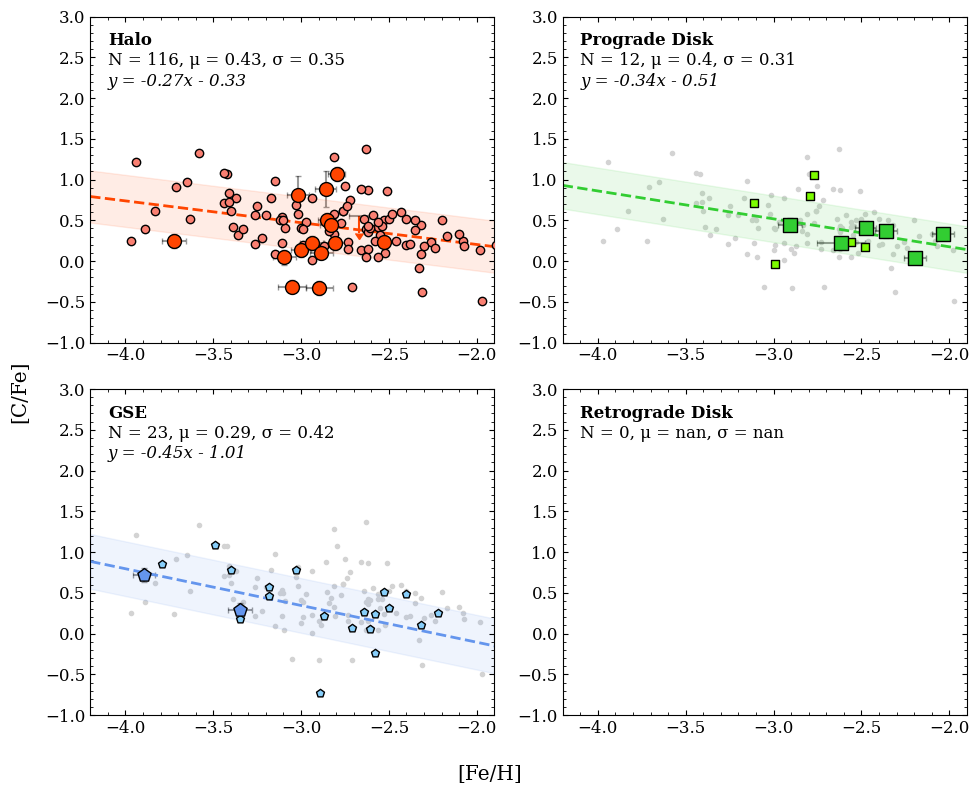

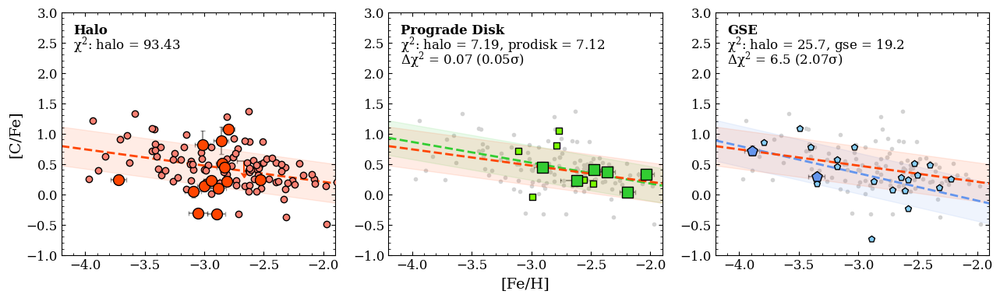

In [46]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='C (CH)', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1, 3.0),
    text_pos1=(-4.1, 2.65),
    text_pos2=(-4.1, 2.4),
    text_pos3=(-4.1, 2.15),
    text_hozalign='left',
    ul_size=0.2,
    save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/c_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/c_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/c_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/c_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/c_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/c_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/c_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/c_abunds_ks",
    gce=False,
    gce_save_path=None #"/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/c_abunds_gce"
)


# plot_feh_xfe_comparison(
#     all_xshooter_abunds=all_xshooter_abunds, 
#     all_lit_abunds=all_lit_abunds, 
#     all_lit_orbabunds=all_lit_orbabunds, 
#     el='C (CH)', 
#     el_list=el_list, 
#     xlim=(-4.2, -1.2), 
#     ylim=(-1, 3.0),
#     text_pos1=(-4.1, 2.65),
#     text_pos2=(-4.1, 2.4),
#     text_pos3=(-4.1, 2.2),
#     text_hozalign='left',
#     ul_size=0.2,
#     save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/c_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
#     galah=False,
#     apogee=False,
#     halo_background=True,
#     galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/c_abunds_orbit_galah"
#     halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/"
#     z_score_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/c_abunds_zscore",
#     cdf_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/c_abunds_cdf",
#     stat_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/c_abunds_ks"
# )

#### [Fe/H] vs [N/Fe]

/tmp/ipykernel_640927/1564865114.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/1564865114.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/1564865114.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

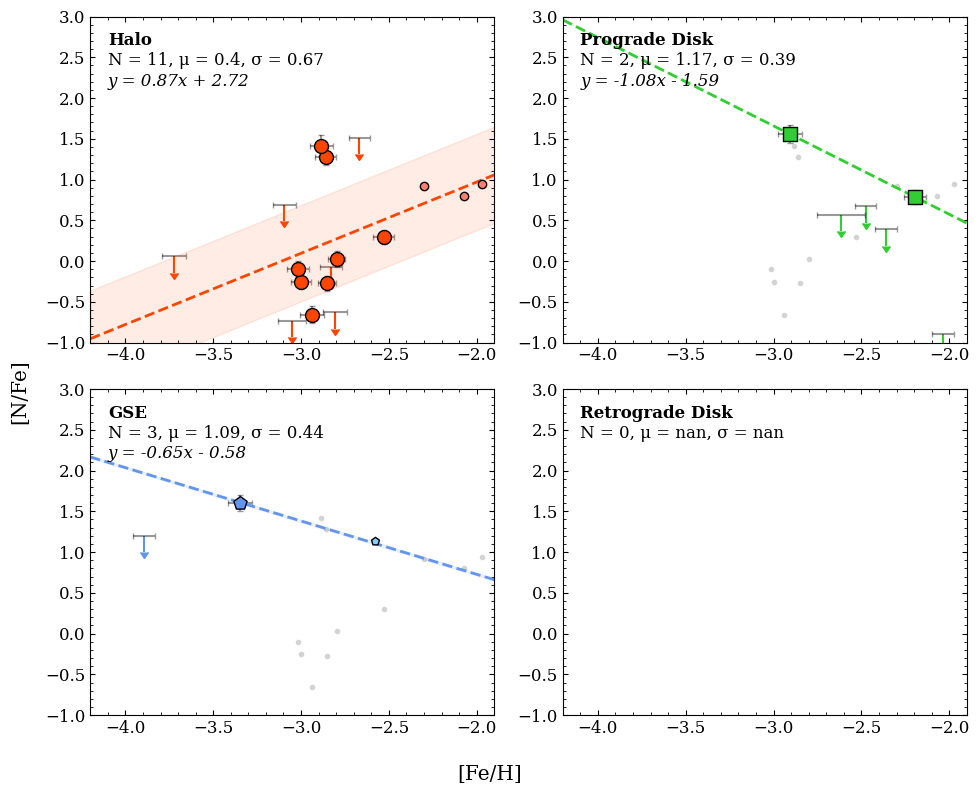

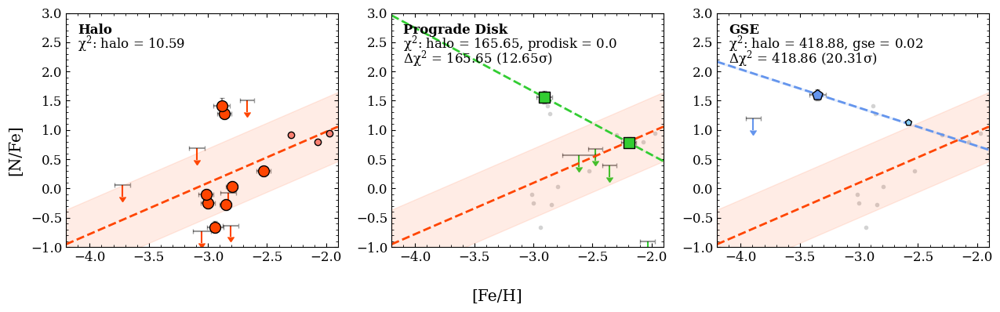

In [20]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='N (NH)', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1, 3.0),
    text_pos1=(-4.1, 2.65),
    text_pos2=(-4.1, 2.4),
    text_pos3=(-4.1, 2.15),
    text_hozalign='left',
    ul_size=0.2,
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/n_abunds", #"/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/n_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/n_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/n_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/n_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/n_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/n_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/n_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/n_abunds_gce"
)

#### [Fe/H] vs [Na/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

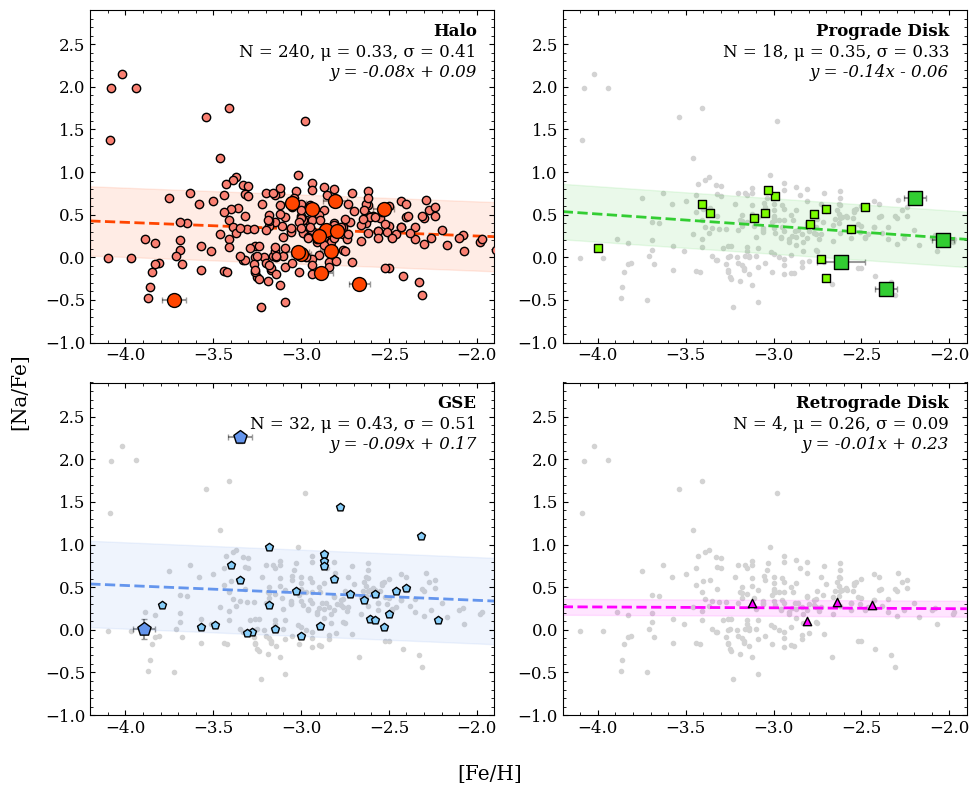

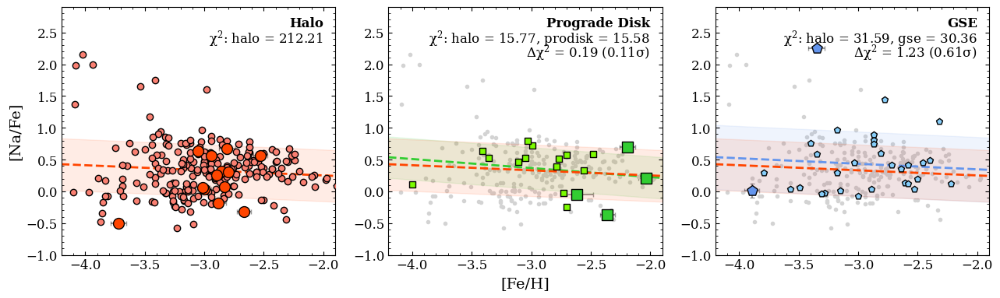

In [47]:

el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Na I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1, 2.9),
    text_pos1=(-2.0, 2.6),
    text_pos2=(-2.0, 2.35),
    text_pos3=(-2.0, 2.12),
    text_hozalign='right',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/na_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/na_abunds", #"/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/na_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/na_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/na_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/na_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/na_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/na_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/na_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/na_abunds_gce"
)

In [40]:
import matplotlib
print(matplotlib.matplotlib_fname())

/home/benlowe/.config/matplotlib/matplotlibrc


#### [Fe/H] vs [Mg/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

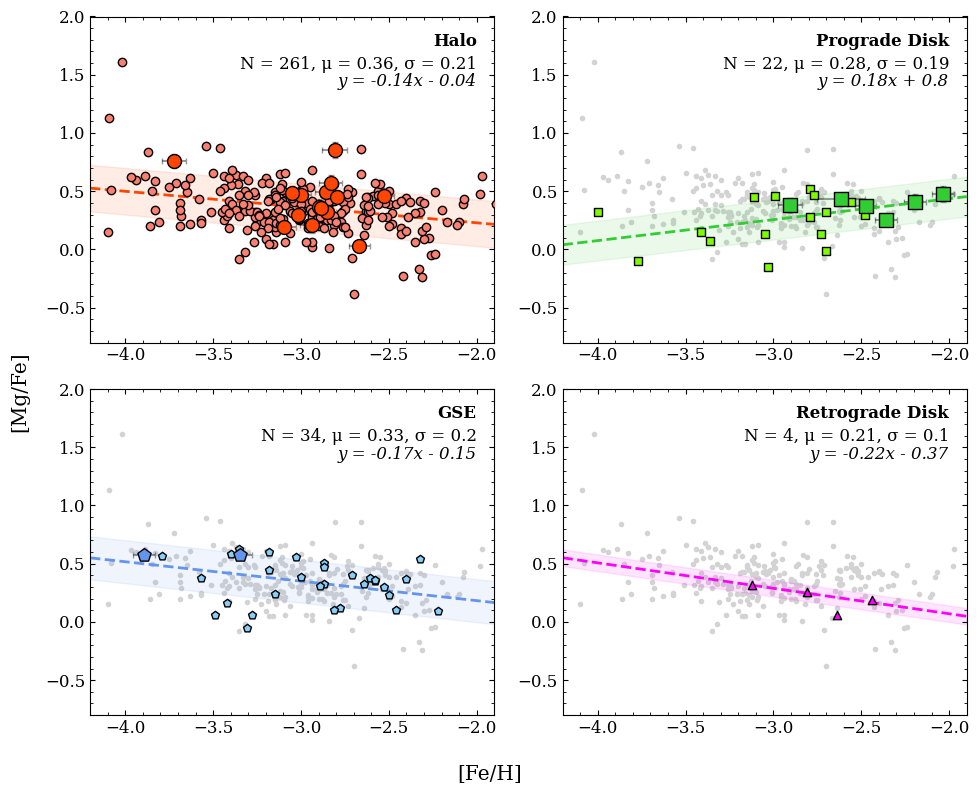

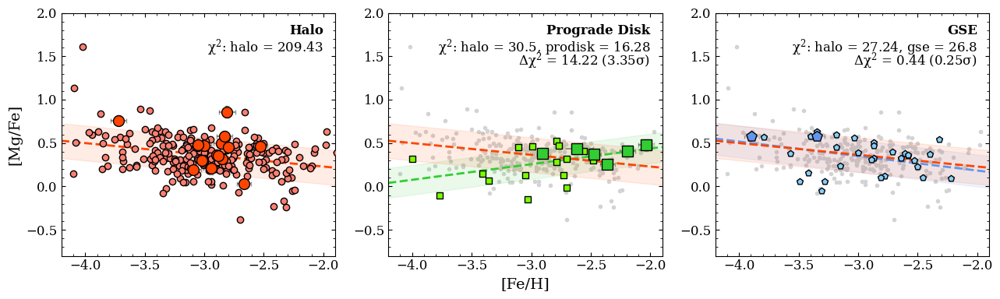

In [48]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Mg I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-0.8, 2.0),
    text_pos1=(-2.0, 1.75),
    text_pos2=(-2.0, 1.55),
    text_pos3=(-2.0, 1.4),
    text_hozalign='right',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/mg_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mg_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/mg_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/mg_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mg_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/mg_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/mg_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/mg_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/mg_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/mg_abunds_gce"
)

#### [Fe/H] vs [Al/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

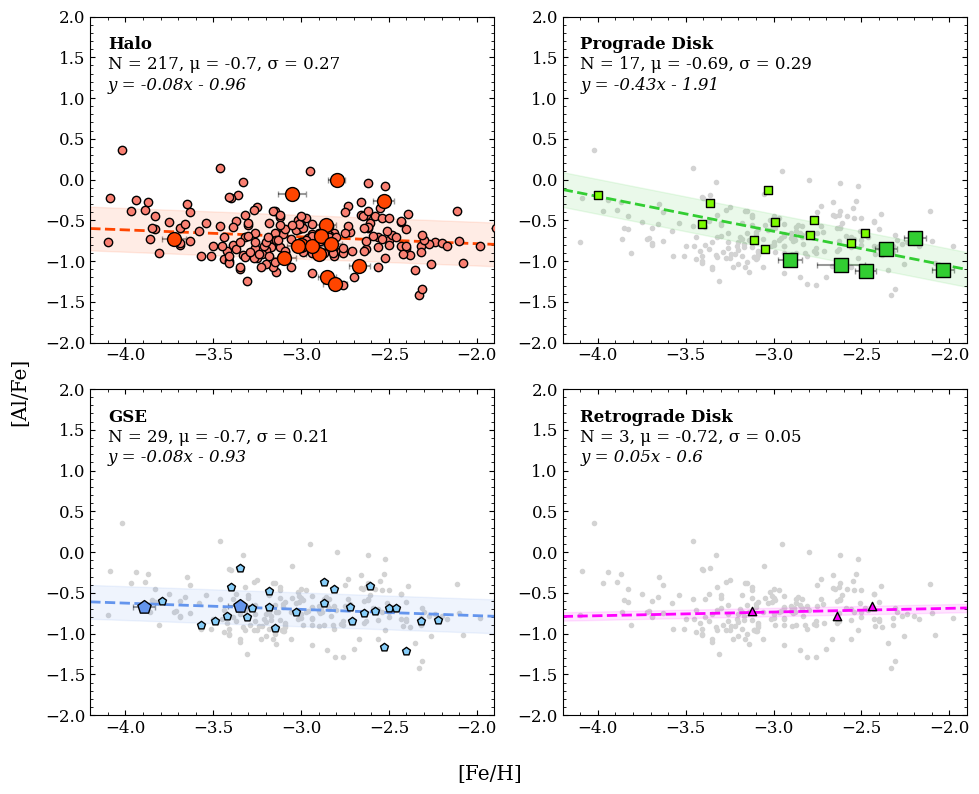

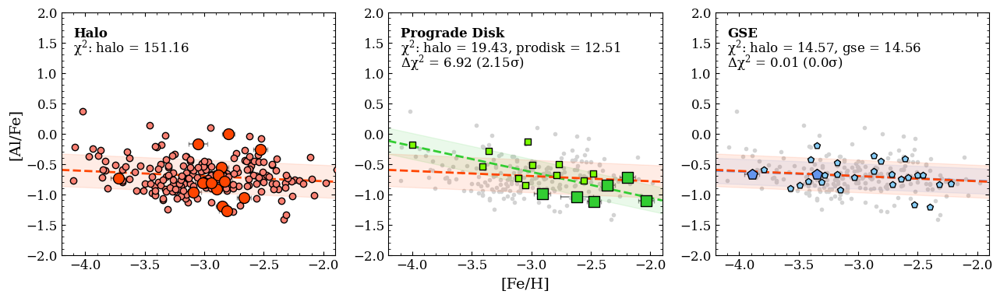

In [49]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Al I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-2, 2),
    text_pos1=(-4.1, 1.6),
    text_pos2=(-4.1, 1.35),
    text_pos3=(-4.1, 1.1),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/al_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/al_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/al_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/al_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/al_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/al_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/al_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/al_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/al_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/al_abunds_gce"
)

#### [Fe/H] vs [Si/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

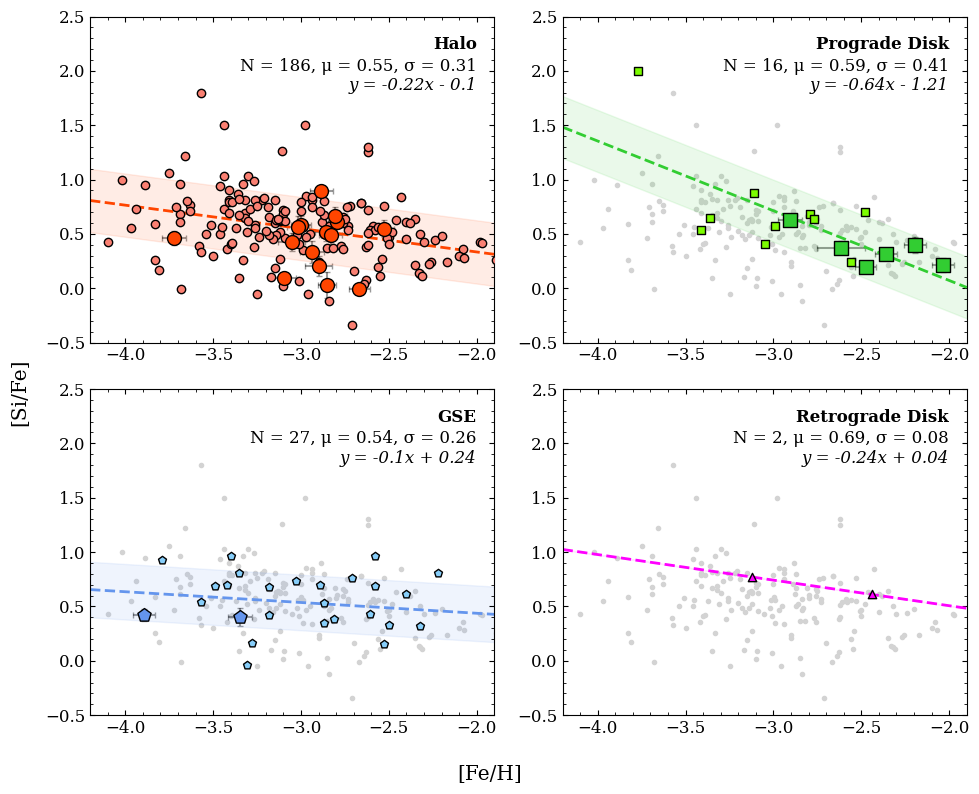

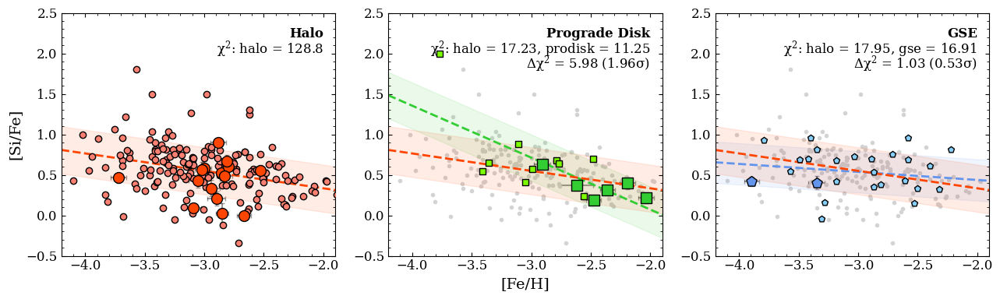

In [50]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Si I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-0.5, 2.5),
    text_pos1=(-2.0, 2.2),
    text_pos2=(-2.0, 2.0),
    text_pos3=(-2.0, 1.82),
    text_hozalign='right',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/si_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/si_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/si_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/si_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/si_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/si_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/si_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/si_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/si_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/si_abunds_gce"
)

#### [Fe/H] vs [Ca/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

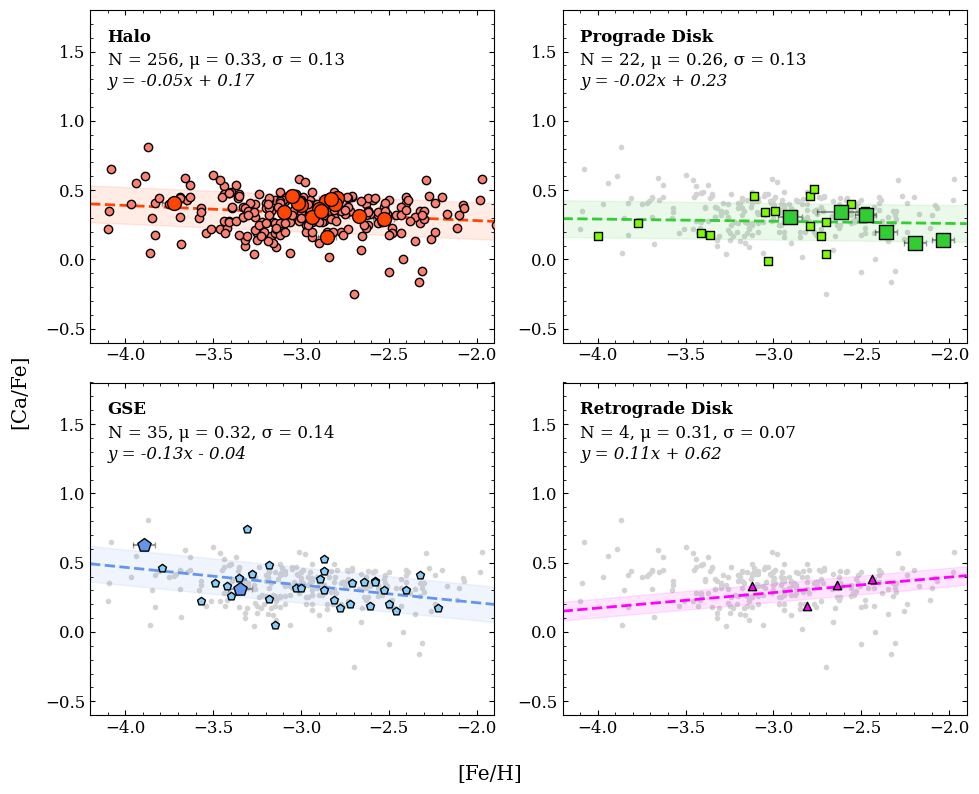

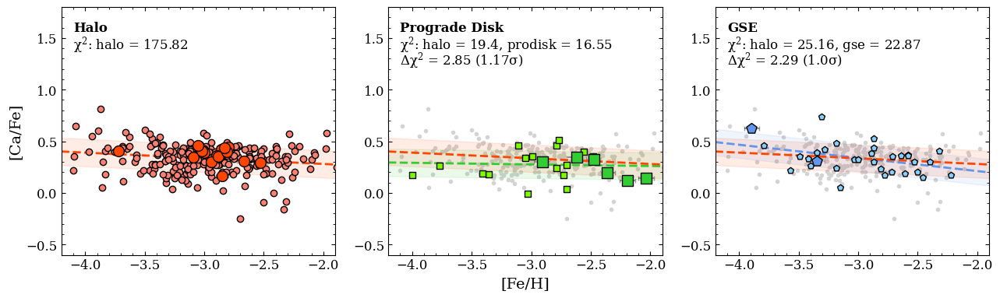

In [51]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Ca II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-0.6, 1.8),
    text_pos1=(-4.1, 1.57),
    text_pos2=(-4.1, 1.4),
    text_pos3=(-4.1, 1.25),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ca_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ca_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ca_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/ca_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ca_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/ca_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/ca_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/ca_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/ca_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/ca_abunds_gce"
)

#### [Fe/H] vs [Sc/Fe] 

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

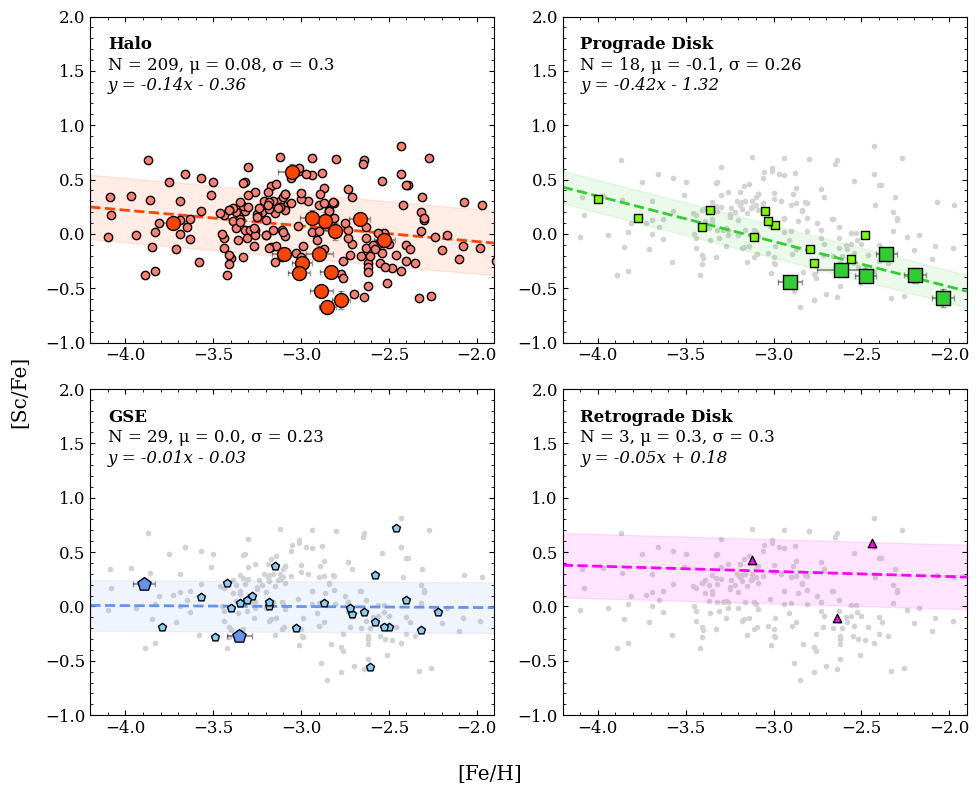

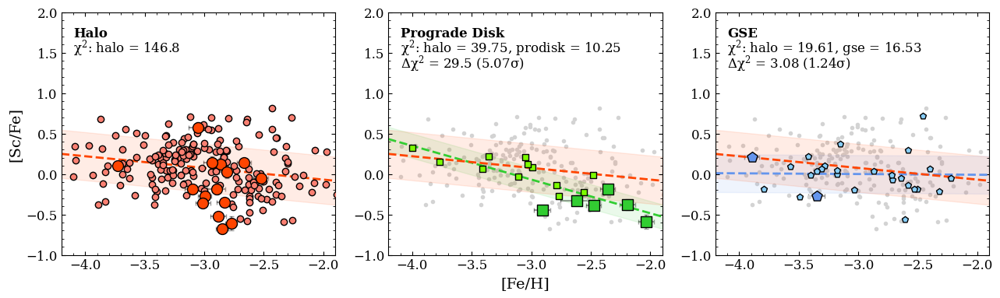

In [52]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Sc II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1, 2),
    text_pos1=(-4.1, 1.7),
    text_pos2=(-4.1, 1.51),
    text_pos3=(-4.1, 1.32),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/sc_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/sc_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/sc_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sc_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/sc_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/sc_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/sc_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/sc_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/sc_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/sc_abunds_gce"
)

#### [Fe/H] vs [Ti/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

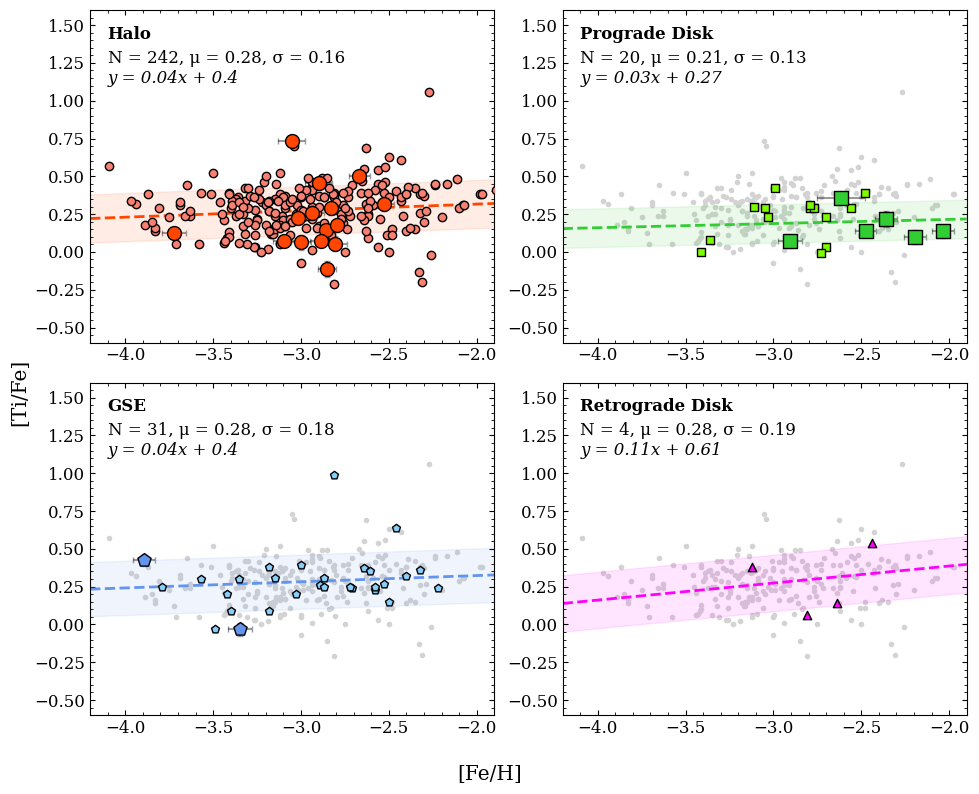

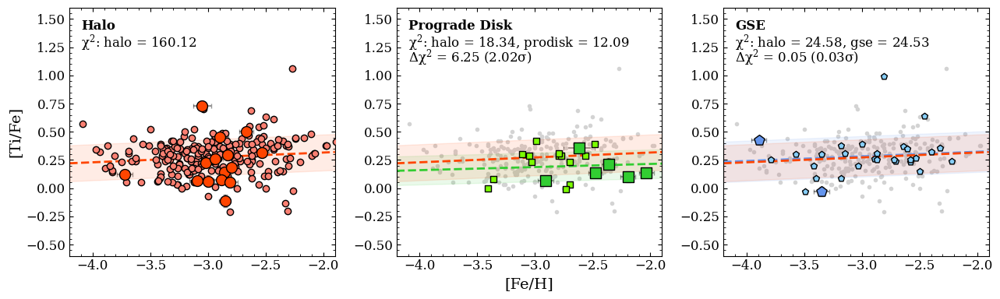

In [53]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Ti II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-0.6, 1.6),
    text_pos1=(-4.1, 1.41),
    text_pos2=(-4.1, 1.25),
    text_pos3=(-4.1, 1.12),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ti_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ti_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ti_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/ti_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ti_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/ti_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/ti_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/ti_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/ti_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/ti_abunds_gce"
)

#### [Fe/H] vs [Cr/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

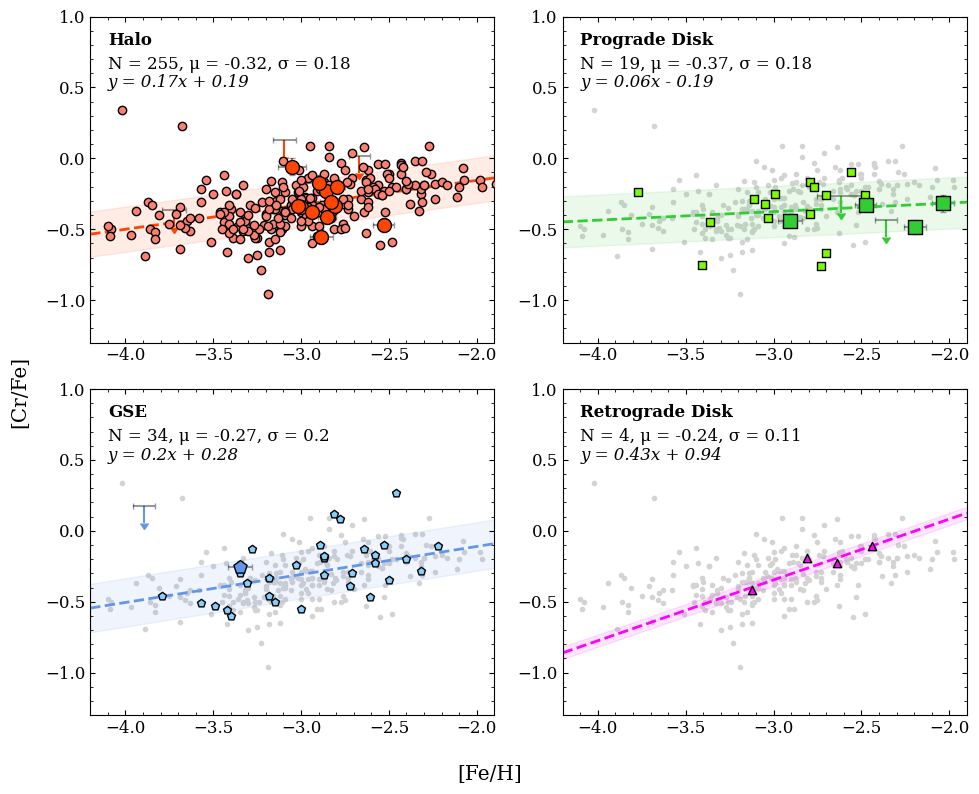

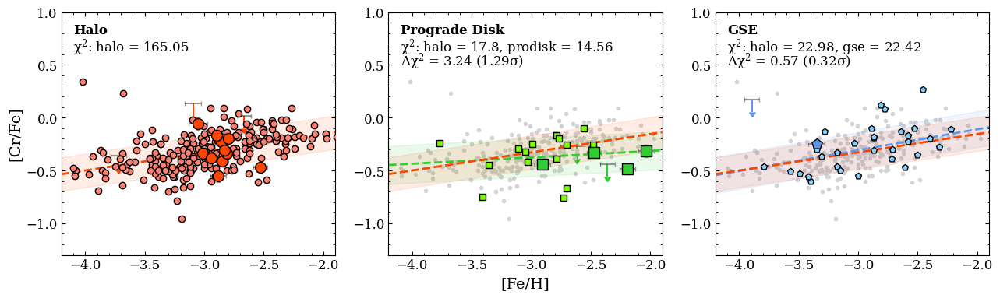

In [54]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Cr I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1.3, 1.0),
    text_pos1=(-4.1, 0.8),
    text_pos2=(-4.1, 0.63),
    text_pos3=(-4.1, 0.5),
    text_hozalign='left',
    ul_size=0.12,
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/cr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/cr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/cr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/cr_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/cr_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/cr_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/cr_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/cr_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/cr_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/cr_abunds_gce"
)


#### [Fe/H] vs [Mn/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

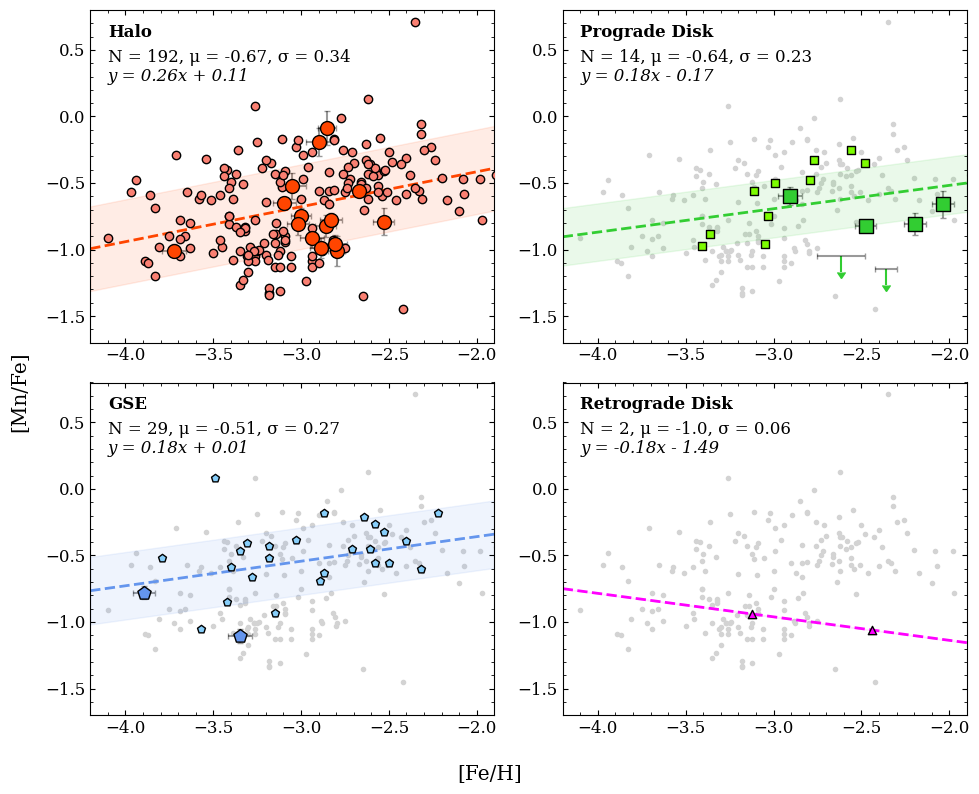

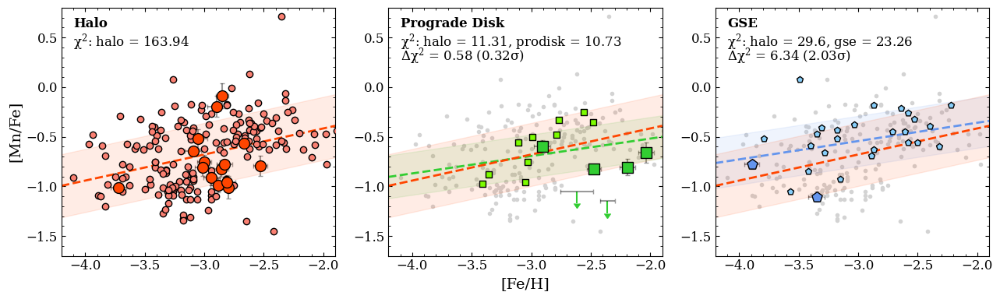

In [55]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Mn I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1.7, 0.8),
    text_pos1=(-4.1, 0.6),
    text_pos2=(-4.1, 0.41),
    text_pos3=(-4.1, 0.27),
    text_hozalign='left',
    ul_size=0.12,
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/mn_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mn_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/mn_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/mn_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mn_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/mn_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/mn_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/mn_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/mn_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/mn_abunds_gce"
)

#### [Fe/H] vs [Co/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

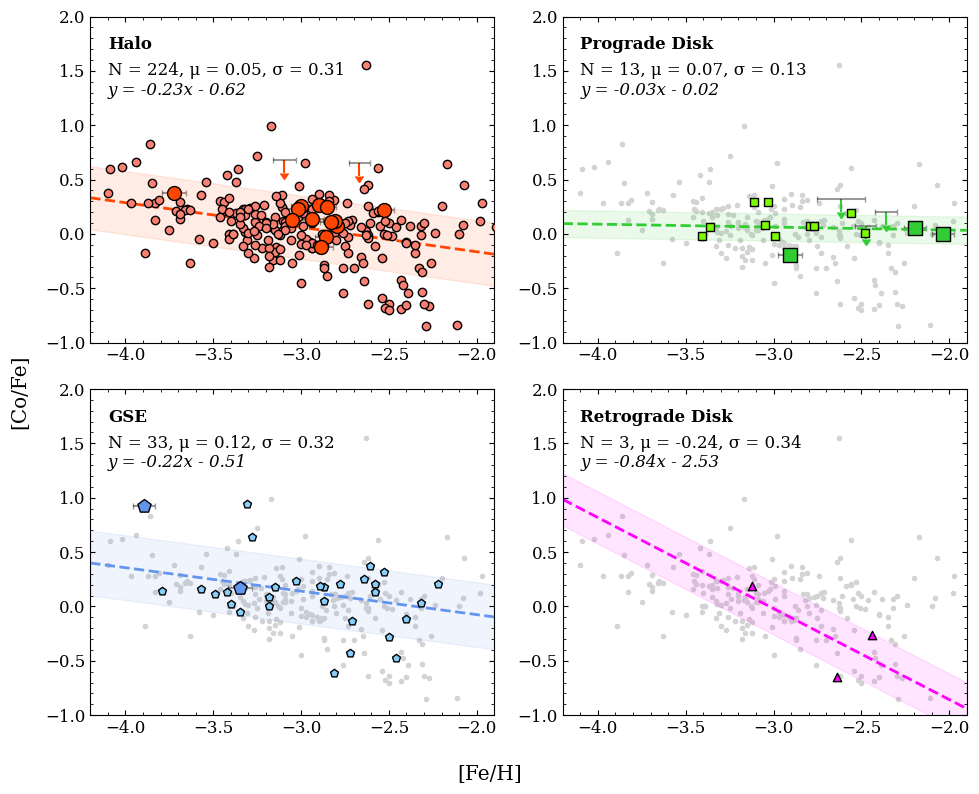

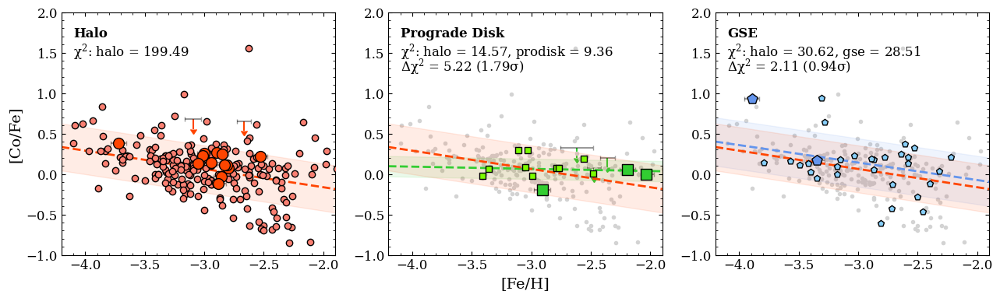

In [56]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Co I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1.0, 2.0),
    text_pos1=(-4.1, 1.7),
    text_pos2=(-4.1, 1.46),
    text_pos3=(-4.1, 1.28),
    text_hozalign='left',
    ul_size=0.12,
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/co_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/co_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/co_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/ti_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/co_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/co_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/co_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/co_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/co_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/co_abunds_gce"
)


#### [Fe/H] [Ni/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

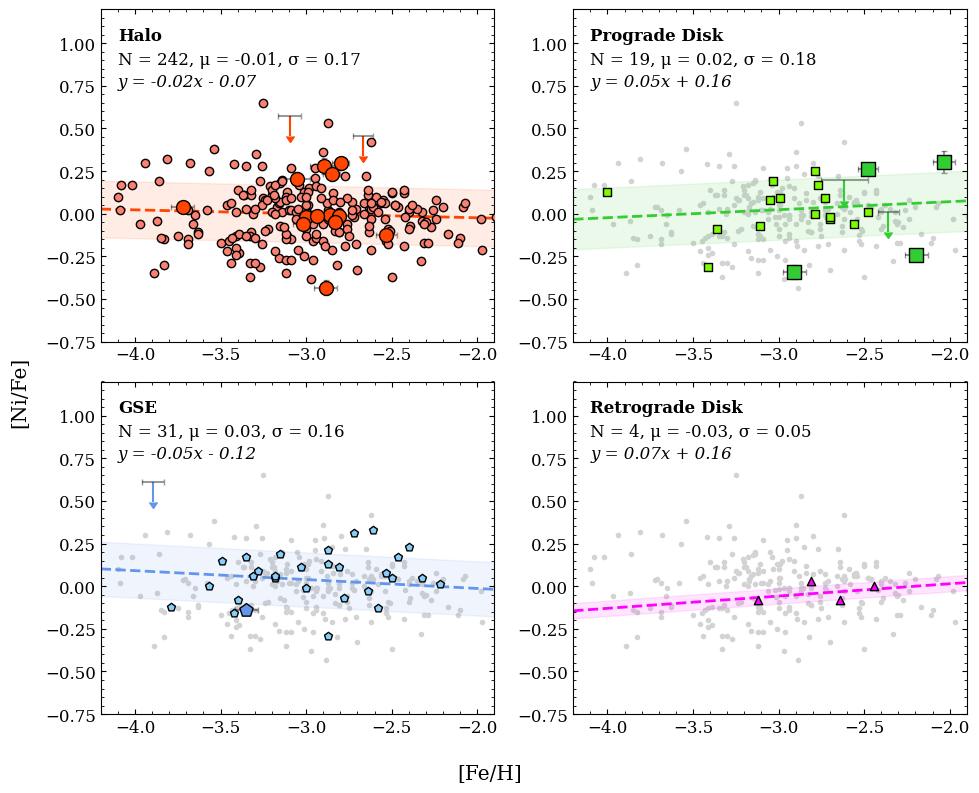

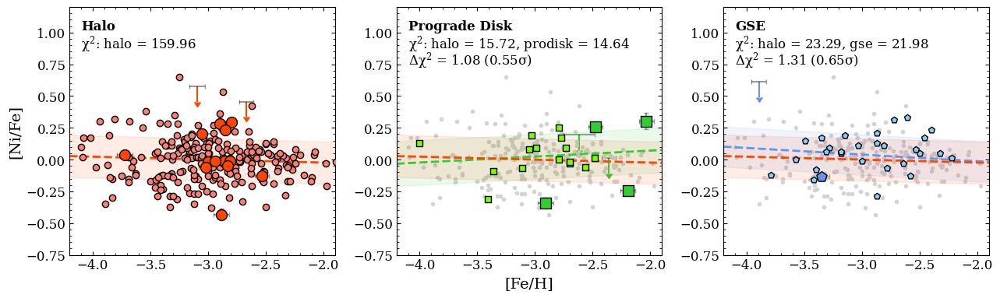

In [57]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Ni I', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-0.75, 1.2),
    text_pos1=(-4.1, 1.02),
    text_pos2=(-4.1, 0.88),
    text_pos3=(-4.1, 0.75),
    text_hozalign='left',
    ul_size=0.12,
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ni_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ni_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ni_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/ni_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ni_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/ni_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/ni_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/ni_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/ni_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/ni_abunds_gce"
)


#### [Fe/H] vs [Sr/Fe]

/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:415: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_gse.drop_duplicates(subset=['

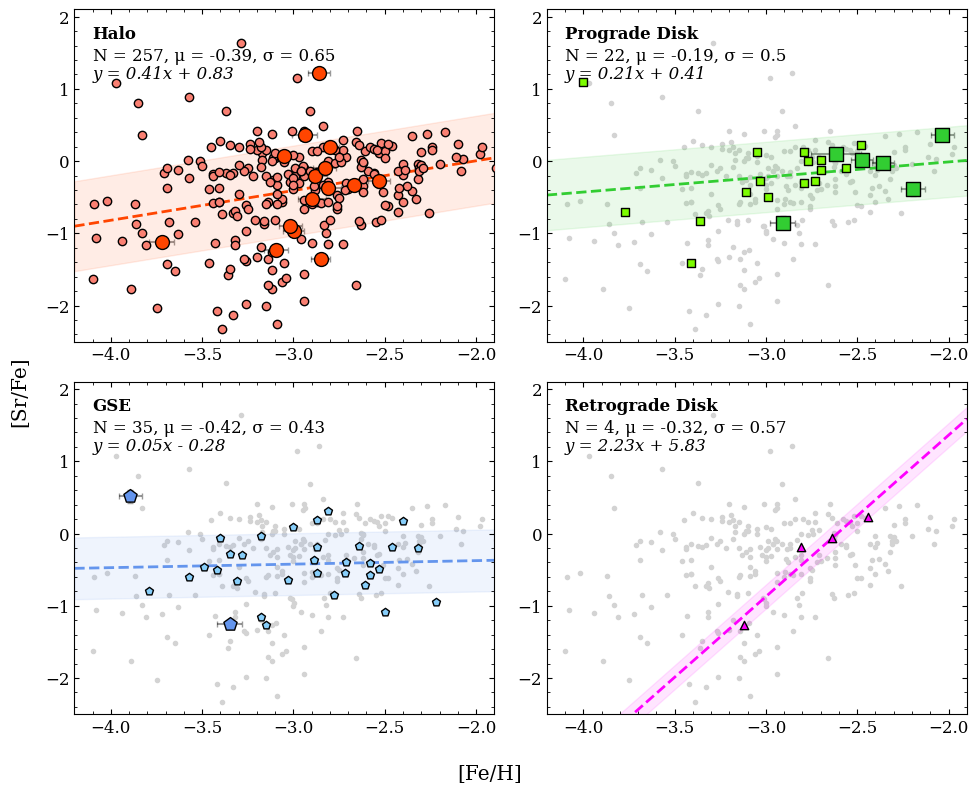

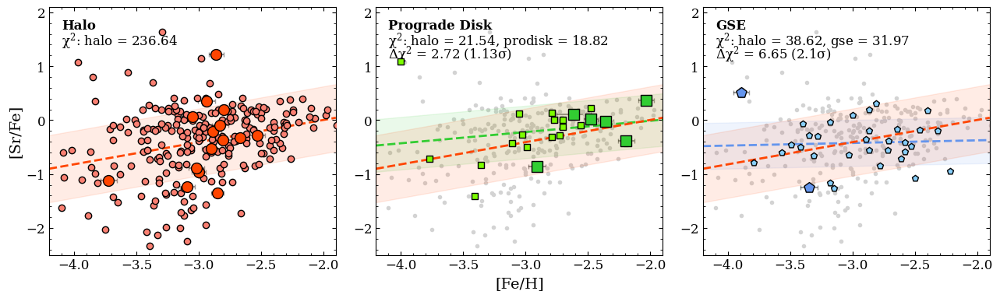

In [58]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Sr II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-2.5, 2.1),
    text_pos1=(-4.1, 1.7),
    text_pos2=(-4.1, 1.4),
    text_pos3=(-4.1, 1.15),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/sr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/sr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/sr_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sr_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/sr_abunds",
    halo_fit_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/sr_abunds",
    z_score_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/sr_abunds_zscore",
    cdf_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/sr_abunds_cdf",
    stat_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/sr_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/sr_abunds_gce"
)


#### [Fe/H] vs [Ba/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

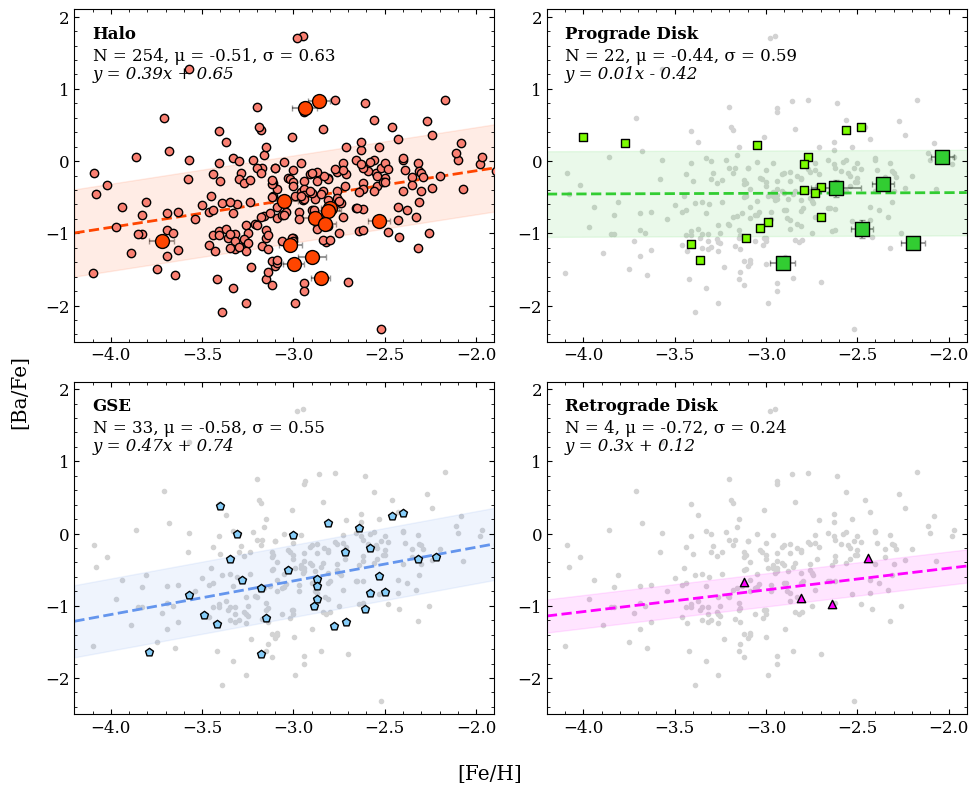

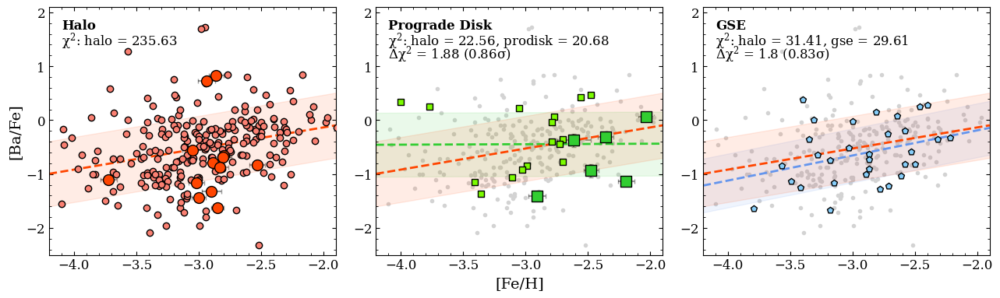

In [59]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Ba II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-2.5, 2.1),
    text_pos1=(-4.1, 1.7),
    text_pos2=(-4.1, 1.4),
    text_pos3=(-4.1, 1.15),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ba_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ba_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/ba_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    sculptor=sculp_df,
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/ba_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/ba_abunds",
    halo_fit_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/ba_abunds",
    z_score_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/ba_abunds_zscore",
    cdf_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/ba_abunds_cdf",
    stat_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/ba_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/ba_abunds_gce"
)


#### [Fe/H] vs [Eu/Fe]

/tmp/ipykernel_640927/228059271.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_lit_orbabund_all['abund_err'] = el_lit_orbabund_all['abund_err'].replace(0, 0.1)
/tmp/ipykernel_640927/228059271.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_640927/228059271.py:300: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#retur

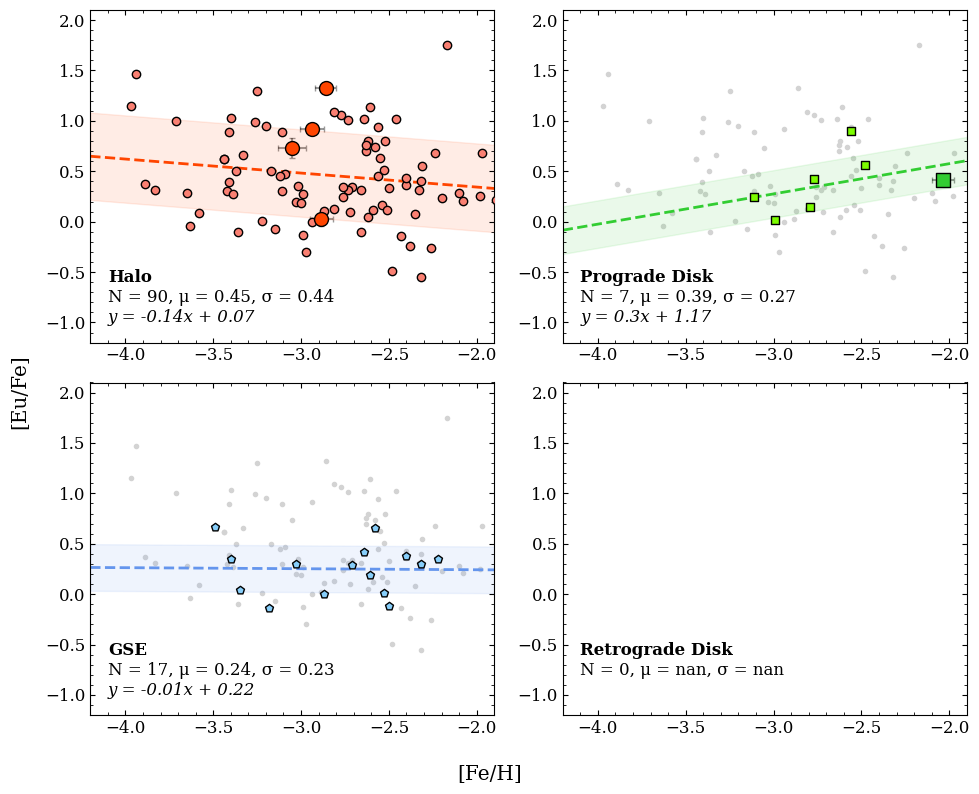

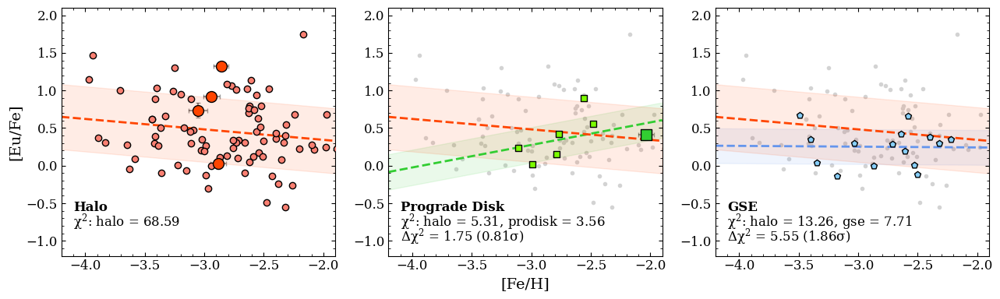

In [60]:
plot_feh_xfe_comparison(
    all_xshooter_abunds=all_xshooter_abunds, 
    all_lit_abunds=all_lit_abunds, 
    all_lit_orbabunds=all_lit_orbabunds, 
    el='Eu II', 
    el_list=el_list, 
    xlim=(-4.2, -1.9), 
    ylim=(-1.2, 2.1),
    text_pos1=(-4.1, -0.6),
    text_pos2=(-4.1, -0.8),
    text_pos3=(-4.1, -1.0),
    text_hozalign='left',
    save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/eu_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/eu_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/eu_abunds", # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_zscore/c_abunds_zscore",
    galah=False,
    apogee=False,
    halo_background=True,
    galah_save_path=None, # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/eu_abunds_orbit_galah"
    delta_chisqr_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/eu_abunds",
    halo_fit_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/eu_abunds",
    z_score_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/eu_abunds_zscore",
    cdf_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/eu_abunds_cdf",
    stat_save_path="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/eu_abunds_ks",
    gce=False,
    gce_save_path=None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/gce_models/eu_abunds_gce"
)


### Looking at Mg and Sc abundances

Loading in the data

In [20]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
mg_xshooter_abunds = all_xshooter_abunds[3]
sc_xshooter_abunds = all_xshooter_abunds[7]

# Calculating [Sc/Mg]
scmg_xshooter_abunds = []
for i, row in mg_xshooter_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    feh = row['feh']
    feh_err = row['feh_err']
    mg_xfe = row['bestfit_abund_xfe']
    mg_xfe_err = row['bestfit_abund_comberr_xfe']
    
    orb_row = comb_df[comb_df['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['Vr'].values[0]
        Vphi = orb_row['Vphi'].values[0]
        X = orb_row['X'].values[0]
        Y = orb_row['Y'].values[0]
    
    sc_row = sc_xshooter_abunds[sc_xshooter_abunds['star_id'] == star_id]
    
    
    if sc_row['detection'].values[0] == 'Y':
        sc_xfe = sc_row['bestfit_abund_xfe'].values[0]
        sc_xfe_err = sc_row['bestfit_abund_comberr_xfe'].values[0]
        
        scmg_xfe = sc_xfe - mg_xfe
        scmg_xfe_err = np.sqrt(sc_xfe_err**2 + mg_xfe_err**2)
        
        scmg_xshooter_abunds.append({
            'star_id': star_id,
            'orbit': orbit,
            'feh': feh,
            'feh_err': feh_err,
            'abund_mgfe': mg_xfe,
            'abund_mgfe_err': mg_xfe_err,
            'abund_scfe': sc_xfe,
            'abund_scfe_err': sc_xfe_err,
            'abund_scmg': scmg_xfe,
            'abund_scmg_err': scmg_xfe_err,
            'bestfit_abund_xfe': scmg_xfe,
            'abund_err': scmg_xfe_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
scmg_xshooter_abunds = pd.DataFrame(scmg_xshooter_abunds)

# For literature
mg_lit_abunds = all_lit_abunds[3]
sc_lit_abunds = all_lit_abunds[7]

# Calculating [Sc/Mg]
scmg_lit_abunds_list = []
for i, row in mg_lit_abunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    mg_abund = row['abund']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    sc_row = sc_lit_abunds[sc_lit_abunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        
        scmg_abund = sc_abund - mg_abund
        
        scmg_lit_abunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'abund_mgfe': mg_abund,
            'abund_scfe': sc_abund,
            'abund_scmg': scmg_abund,
            'bestfit_abund_xfe': scmg_abund,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
scmg_lit_abunds = pd.DataFrame(scmg_lit_abunds_list)

# comb_df = pd.merge(al_lit_abunds, scal_lit_abunds, on=['star_id', 'feh'])
# comb_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)


# For literature orbital groups
mg_lit_orbabunds = all_lit_orbabunds[3]
sc_lit_orbabunds = all_lit_orbabunds[7]

# Calculating [Mg/Mn]
scmg_lit_orbabunds_list = []
for i, row in mg_lit_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    mg_abund = row['abund']
    mg_abund_err = row['abund_err']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    sc_row = sc_lit_orbabunds[sc_lit_orbabunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        sc_abund_err = sc_row['abund_err'].values[0]
        
        scmg_abund = sc_abund - mg_abund
        scmg_abund_err = np.sqrt(sc_abund_err**2 + mg_abund_err**2)
        
        scmg_lit_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit': orbit,
            'abund_mgfe': mg_abund,
            'abund_mgfe_err': mg_abund_err,
            'abund_scfe': sc_abund,
            'abund_scfe_err': sc_abund_err,
            'abund_scmg': scmg_abund,
            'abund_scmg_err': scmg_abund_err,
            'abund': scmg_abund,
            'abund_err': scmg_abund_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
scmg_lit_orbabunds = pd.DataFrame(scmg_lit_orbabunds_list)

Separating by kinematic group

In [21]:
# X-Shooter
el_xshooter_abund_prodisk = scmg_xshooter_abunds[scmg_xshooter_abunds['orbit'] == 'pro_disk']
el_xshooter_abund_halo = scmg_xshooter_abunds[scmg_xshooter_abunds['orbit'] == 'halo']
el_xshooter_abund_gse = scmg_xshooter_abunds[scmg_xshooter_abunds['orbit'] == 'gse']

# Literature
lit_orbabund_prodisk = scmg_lit_orbabunds[scmg_lit_orbabunds['orbit'] == 'pro_disk']
lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
lit_orbabund_prodisk.dropna(subset=['abund_err'], inplace=True)

lit_orbabund_halo = scmg_lit_orbabunds[scmg_lit_orbabunds['orbit'] == 'halo']
lit_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
lit_orbabund_halo.dropna(subset=['abund_err'], inplace=True)

lit_orbabund_gse = scmg_lit_orbabunds[scmg_lit_orbabunds['orbit'] == 'gse']
lit_orbabund_gse.drop_duplicates(subset=['star_id'], inplace=True)
lit_orbabund_gse.dropna(subset=['abund_err'], inplace=True)

lit_orbabund_retdisk = scmg_lit_orbabunds[scmg_lit_orbabunds['orbit'] == 'ret_disk']
lit_orbabund_retdisk.drop_duplicates(subset=['star_id'], inplace=True)
lit_orbabund_retdisk.dropna(subset=['abund_err'], inplace=True)

# X-Shooter
sculp_df['scmg'] = sculp_df['scfe'] - sculp_df['mgfe']
sculp_df['scmg_err'] = np.sqrt(sculp_df['scfe_err']**2 + sculp_df['mgfe_err']**2)


/tmp/ipykernel_1046112/2662266326.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_1046112/2662266326.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_prodisk.dropna(subset=['abund_err'], inplace=True)
/tmp/ipykernel_1046112/2662266326.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_orbabund_halo.drop_duplicates(subset=['st

In [13]:
el_xshooter_abund_prodisk

,star_id,orbit,feh,feh_err,abund_mgfe,abund_mgfe_err,abund_scfe,abund_scfe_err,abund_scmg,abund_scmg_err,...,jp,jr,jz,jtot,e,dist,Vr,Vphi,X,Y
0,ra_0103-7050_s163,pro_disk,-2.359003,0.060794,0.252548,0.053239,-0.187066,0.040204,-0.439614,0.066714,...,1191.012215,97.542938,88.491505,1198.271867,0.322595,1.360807,9.944337,163.296965,7.692528,-0.794982
1,ra_0834-5220_s316,pro_disk,-2.616194,0.137417,0.432330,0.055202,-0.328674,0.041503,-0.761004,0.069063,...,938.289662,368.486309,48.475280,1009.217272,0.591672,1.533442,105.154213,110.539518,8.203069,-1.521019
7,ra_1648-0653_s38,pro_disk,-2.475968,0.059728,0.374954,0.049391,-0.386725,0.039620,-0.761679,0.063319,...,1295.837964,0.418952,71.690885,1297.819629,0.020229,2.988196,10.321077,345.229096,5.520911,0.521296
18,ra_1639-2632_s419,pro_disk,-2.034058,0.063943,0.475742,0.070394,-0.589638,0.085855,-1.065380,0.111024,...,681.696063,441.568587,23.928242,812.566859,0.765531,3.007140,-184.423780,154.420939,5.289146,-0.336360
20,ra_1659-2154_s261,pro_disk,-2.194068,0.064467,0.408668,0.065040,-0.380955,0.067239,-0.789623,0.093548,...,607.562961,474.029123,27.742583,771.107004,0.735137,3.084374,-221.022385,174.659991,5.192406,0.003604
22,ra_1752-4300_s155,pro_disk,-2.907340,0.067832,0.379596,0.066069,-0.443160,0.052195,-0.822756,0.084198,...,1588.802528,126.198686,115.082054,1597.956026,0.319100,17.999428,-44.693049,133.428782,-9.279501,-3.525812


Loading in GALAH DR4 data

In [74]:
scmg_galah_data = pd.read_csv(f"/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_scmg_orbits.csv")
scmg_galah_data['abund_scmg'] = scmg_galah_data['sc_fe'] - scmg_galah_data['mg_fe']
scmg_galah_data['abund_scmg_err'] = np.sqrt(scmg_galah_data['e_mg_fe']**2 + scmg_galah_data['e_sc_fe']**2)
scmg_galah_data = scmg_galah_data.rename(columns={'fe_h': 'feh', 'sobject_id': 'star_id'})

scmg_galah_prodisk = scmg_galah_data[scmg_galah_data['orbit'] == 'prodisk']
scmg_galah_halo = scmg_galah_data[scmg_galah_data['orbit'] == 'halo']
scmg_galah_gse = scmg_galah_data[scmg_galah_data['orbit'] == 'gse']
scmg_galah_retdisk = scmg_galah_data[scmg_galah_data['orbit'] == 'retdisk']

#### [Fe/H] vs [Sc/Mg]

In [35]:
# Save paths for [Sc/Mg] plots
save_path = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/scmg_abunds" 
delta_chisqr_save_path = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/scmg_abunds" 
halo_fit_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/scmg_abunds" 
z_score_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/scmg_abunds_zscore" 
cdf_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/scmg_abunds_cdf" 
stat_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/scmg_abunds_ks"

##### Delta Chisquare

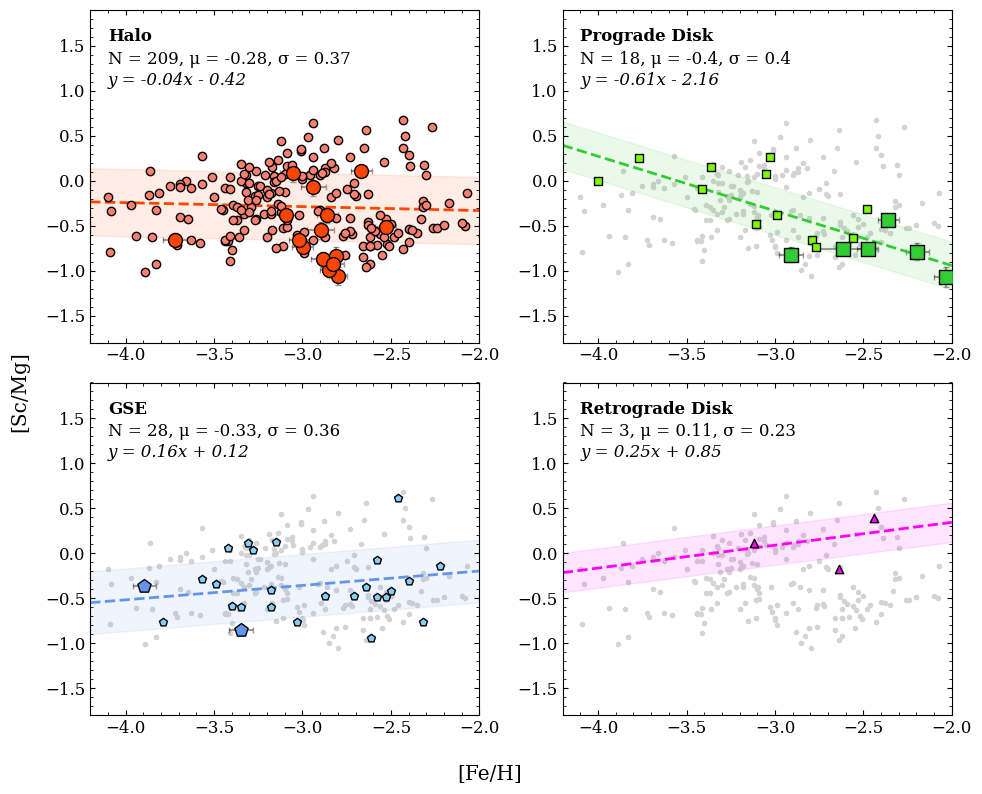

In [30]:
# Setting up figure
xlim = (-4.2, -2.0)
ylim = (-1.8, 1.9)

text_pos1 = (-4.1, 1.55)
text_pos2 = (-4.1, 1.3)
text_pos3 = (-4.1, 1.07)
text_hozalign = 'left'

halo_background = True
sculptor = sculp_df

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Sc/Mg]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# --SUBPLOT 1: HALO--- #
ax = axs[0,0]
    
# Fitting polynomial (both literature and x-shooter)
halo_lit = lit_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_halo_df = pd.concat([el_xshooter_abund_halo, halo_lit], ignore_index=True)

weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
# p_halo, cov_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=True)
p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=False)
fit_halo = np.poly1d(p_halo)

xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# # Getting uncertainty in gradient
# m_halo = p_halo[0]
# c_halo = p_halo[1]
# m_err_halo = np.sqrt(cov_halo[0,0])
# c_err_halo = np.sqrt(cov_halo[1,1])

# yline_halo_pmerr = (m_halo + m_err_halo) * xline_halo + c_halo
# yline_halo_mmerr = (m_halo - m_err_halo) * xline_halo + c_halo

# yline_halo_c_pmerr = m_halo * xline_halo + (c_halo + c_err_halo)
# yline_halo_c_pmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo + c_err_halo)
# yline_halo_c_pmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo + c_err_halo)

# yline_halo_c_mmerr = m_halo * xline_halo + (c_halo - c_err_halo)
# yline_halo_c_mmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo - c_err_halo)
# yline_halo_c_mmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo - c_err_halo)

# # Plotting the background data
# # (literature data, prograde disk and GSE stars)
# ax.scatter(el_lit_abund_all['feh'], el_lit_abund_all['abund'], c="lightgrey", marker='.', zorder=1)
# ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='grey', label='Prograde Disk', 
#             marker='s', s=100, zorder=2, alpha=0.9, linewidths=0)
# ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], xerr=el_xshooter_abund_prodisk['feh_err'],
#             yerr=el_xshooter_abund_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)
# ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='grey', label='GSE', 
#             marker='p', s=100, zorder=2, alpha=0.9, linewidths=0)
# ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], xerr=el_xshooter_abund_gse['feh_err'],
#             yerr=el_xshooter_abund_gse['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo, 
                    yline_halo + std_halo, 
                    color='orangered', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_halo, 
#                     yline_halo_pmerr, 
#                     yline_halo_mmerr, 
#                     color='orangered', 
#                     alpha=0.3)

# ax.plot(xline_halo, yline_halo_c_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.fill_between(xline_halo, 
#                 yline_halo_c_pmerr_m_pmerr, 
#                 yline_halo_c_pmerr_m_mmerr, 
#                 color='orangered', 
#                 alpha=0.15)

# ax.plot(xline_halo, yline_halo_c_mmerr, color='orangered', linestyle='--', linewidth=1)
# ax.fill_between(xline_halo, 
#                 yline_halo_c_mmerr_m_pmerr, 
#                 yline_halo_c_mmerr_m_mmerr, 
#                 color='orangered', 
#                 alpha=0.15)    


# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    



# ---SUBPLOT 2: PROGRADE DISK--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
prodisk_lit = lit_orbabund_prodisk.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_prodisk_df = pd.concat([el_xshooter_abund_prodisk, prodisk_lit], ignore_index=True)

weights_prodisk = 1 / np.sqrt(comb_prodisk_df['abund_err']**2 + np.std(comb_prodisk_df['bestfit_abund_xfe'])**2)    
# p_prodisk, cov_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=True)
p_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=False)
fit_prodisk = np.poly1d(p_prodisk)

xline_prodisk = np.linspace(xlim[0], xlim[1], 100)

yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['bestfit_abund_xfe'] - fit_prodisk(comb_prodisk_df['feh'])
std_prodisk = np.std(res_prodisk)

# # Getting uncertainty in gradient
# m_prodisk = p_prodisk[0]
# c_prodisk = p_prodisk[1]
# m_err_prodisk = np.sqrt(cov_prodisk[0,0])
# c_err_prodisk = np.sqrt(cov_prodisk[1,1])

# yline_prodisk_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + c_prodisk
# yline_prodisk_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + c_prodisk

# yline_prodisk_c_pmerr = m_prodisk * xline_prodisk + (c_prodisk + c_err_prodisk)
# yline_prodisk_c_pmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)
# yline_prodisk_c_pmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)

# yline_prodisk_c_mmerr = m_prodisk * xline_prodisk + (c_prodisk - c_err_prodisk)
# yline_prodisk_c_mmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)
# yline_prodisk_c_mmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)


# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_prodisk, 
#                     yline_prodisk_pmerr, 
#                     yline_prodisk_mmerr, 
#                     color='limegreen', 
#                     alpha=0.3)

# ax.plot(xline_prodisk, yline_prodisk_c_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.fill_between(xline_prodisk, 
#                 yline_prodisk_c_pmerr_m_pmerr, 
#                 yline_prodisk_c_pmerr_m_mmerr, 
#                 color='limegreen', 
#                 alpha=0.15)

# ax.plot(xline_prodisk, yline_prodisk_c_mmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.fill_between(xline_prodisk, 
#                 yline_prodisk_c_mmerr_m_pmerr, 
#                 yline_prodisk_c_mmerr_m_mmerr, 
#                 color='limegreen', 
#                 alpha=0.15)    
    

# Making the text
# For Galah, if the horizontal alignment is right, need to adjust the x position of the text to accomodate the extended x-axis limits
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

    
# ---SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
gse_lit = lit_orbabund_gse.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_gse_df = pd.concat([el_xshooter_abund_gse, gse_lit], ignore_index=True)

weights_gse = 1 / np.sqrt(comb_gse_df['abund_err']**2 + np.std(comb_gse_df['bestfit_abund_xfe'])**2)
# p_gse, cov_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=True)
p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=False)
fit_gse = np.poly1d(p_gse)

xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['bestfit_abund_xfe'] - fit_gse(comb_gse_df['feh'])
std_gse = np.std(res_gse)

# # Getting uncertainty in gradient
# m_gse = p_gse[0]
# c_gse = p_gse[1]
# m_err_gse = np.sqrt(cov_gse[0,0])
# c_err_gse = np.sqrt(cov_gse[1,1])

# yline_gse_pmerr = (m_gse + m_err_gse) * xline_gse + c_gse
# yline_gse_mmerr = (m_gse - m_err_gse) * xline_gse + c_gse

# yline_gse_c_pmerr = m_gse * xline_gse + (c_gse + c_err_gse)
# yline_gse_c_pmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse + c_err_gse)
# yline_gse_c_pmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse + c_err_gse)

# yline_gse_c_mmerr = m_gse * xline_gse + (c_gse - c_err_gse)
# yline_gse_c_mmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse - c_err_gse)
# yline_gse_c_mmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse - c_err_gse)

# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse, 
                    yline_gse + std_gse, 
                    color='cornflowerblue', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_gse, 
#                     yline_gse_pmerr, 
#                     yline_gse_mmerr, 
#                     color='cornflowerblue', 
#                     alpha=0.3)

# ax.plot(xline_gse, yline_gse_c_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.fill_between(xline_gse, 
#                 yline_gse_c_pmerr_m_pmerr, 
#                 yline_gse_c_pmerr_m_mmerr, 
#                 color='cornflowerblue', 
#                 alpha=0.15)

# ax.plot(xline_gse, yline_gse_c_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.fill_between(xline_gse, 
#                 yline_gse_c_mmerr_m_pmerr, 
#                 yline_gse_c_mmerr_m_mmerr, 
#                 color='cornflowerblue', 
#                 alpha=0.15)    


# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    
    
# ---SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
retdisk_lit = lit_orbabund_retdisk.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_retdisk_df = pd.concat([retdisk_lit], ignore_index=True)

# If there are no retrograde disk stars, just make the text with N, mean and stddev (which will be NaN)
if len(comb_retdisk_df) == 0:
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
else:
    
    weights_retdisk = 1 / np.sqrt(comb_retdisk_df['abund_err']**2 + np.std(comb_retdisk_df['bestfit_abund_xfe'])**2)
    
    # If there are too few stars (2 or less), the covariance will break. If this happens, then skip
    if len(comb_retdisk_df) <= 2:
        p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
        fit_retdisk = np.poly1d(p_retdisk)
        
        xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
        yline_retdisk = fit_retdisk(xline_retdisk)
        res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
        std_retdisk = np.std(res_retdisk)
    else:
        # p_retdisk, cov_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=True)
        p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
        fit_retdisk = np.poly1d(p_retdisk)
        
        xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
        yline_retdisk = fit_retdisk(xline_retdisk)
        res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
        std_retdisk = np.std(res_retdisk)
    
        # # Getting uncertainty in gradient
        # m_retdisk = p_retdisk[0]
        # c_retdisk = p_retdisk[1]
        # m_err_retdisk = np.sqrt(cov_retdisk[0,0])
        # c_err_retdisk = np.sqrt(cov_retdisk[1,1])

        # yline_retdisk_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + c_retdisk
        # yline_retdisk_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + c_retdisk
        
        # yline_retdisk_c_pmerr = m_retdisk * xline_retdisk + (c_retdisk + c_err_retdisk)
        # yline_retdisk_c_pmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
        # yline_retdisk_c_pmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
        
        # yline_retdisk_c_mmerr = m_retdisk * xline_retdisk + (c_retdisk - c_err_retdisk)
        # yline_retdisk_c_mmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)
        # yline_retdisk_c_mmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)

    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

    
    # Plotting the retrograde disk stars (literature)
    ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    # Plotting the polynomial fit and 1-sigma bounds
    ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
    ax.fill_between(xline_retdisk, 
                        yline_retdisk - std_retdisk,
                        yline_retdisk + std_retdisk,
                        color='fuchsia',
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # if len(comb_retdisk_df) > 2:
    #     ax.fill_between(xline_retdisk, 
    #                         yline_retdisk_pmerr, 
    #                         yline_retdisk_mmerr, 
    #                         color='fuchsia', 
    #                         alpha=0.3)
        
    #     ax.plot(xline_retdisk, yline_retdisk_c_pmerr, color='fuchsia', linestyle='--', linewidth=1)
    #     ax.fill_between(xline_retdisk, 
    #                     yline_retdisk_c_pmerr_m_pmerr, 
    #                     yline_retdisk_c_pmerr_m_mmerr, 
    #                     color='fuchsia', 
    #                     alpha=0.15)
        
    #     ax.plot(xline_retdisk, yline_retdisk_c_mmerr, color='fuchsia', linestyle='--', linewidth=1)
    #     ax.fill_between(xline_retdisk, 
    #                     yline_retdisk_c_mmerr_m_pmerr, 
    #                     yline_retdisk_c_mmerr_m_mmerr, 
    #                     color='fuchsia', 
    #                     alpha=0.15)    

    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    if fit_retdisk[0] > 0:
        ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    else:
        ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        
    
    
plt.tight_layout()
if save_path is not None:
    plt.savefig(save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')

# if galah_save_path is not None and galah:
#     plt.savefig(galah_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#     plt.savefig(galah_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()
# ------------------------------------------------------------------------------------------------------------ #

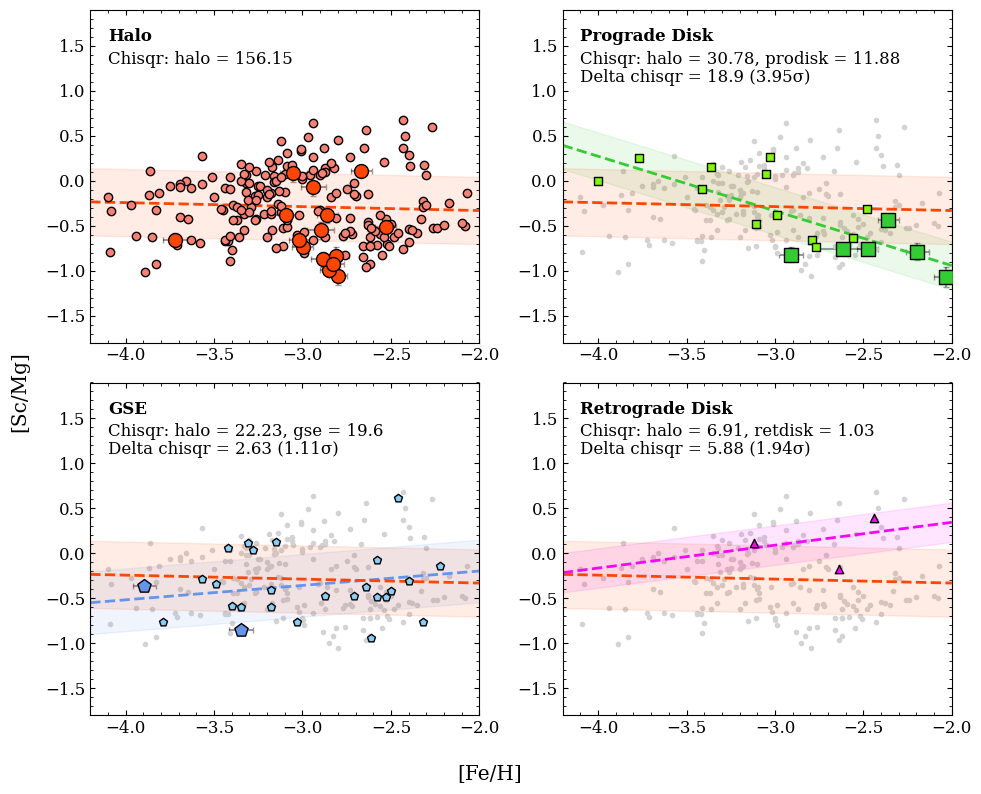

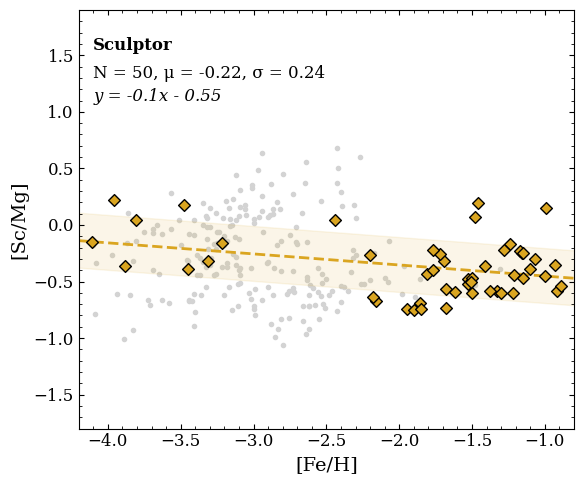

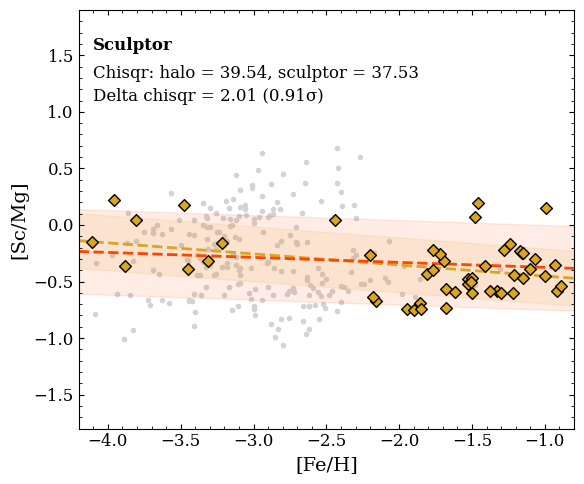

In [ ]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')

fig.supylabel(f"[Sc/Mg]")


axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)

# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)



# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                yline - std_prodisk,
                yline + std_prodisk,
                color='limegreen',
                alpha=0.1)

# # Plotting the prograde disk ±m_err lines
# ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['feh'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)

# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                yline - std_gse,
                yline + std_gse,
                color='cornflowerblue',
                alpha=0.1)

# # Plotting the GSE ±m_err lines
# ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)


# --RETROGRADE DISK--- #
# Calculating the chi-square value for the retrograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
if len(comb_retdisk_df) > 0:
        retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
        retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
        retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
        n_params = 0
        retdisk_halofit_dof = len(comb_retdisk_df) - n_params
        retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
        retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)

        # Now doing this for the retrograde disk fit
        retdisk_origfit_model = fit_retdisk(comb_retdisk_df['feh'])
        retdisk_origfit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
        retdisk_origfit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_origfit_model) ** 2) / (retdisk_origfit_error ** 2))
        n_params = 2
        retdisk_origfit_dof = len(comb_retdisk_df) - n_params # Number of parameters is the degree
        retdisk_origfit_redchisqr = retdisk_origfit_chisqr / retdisk_origfit_dof
        retdisk_origfit_pvalue = gammaincc(retdisk_origfit_dof / 2, retdisk_origfit_chisqr / 2)
                
        # Calculating the delta chisquare
        retdisk_delta_chisqr = retdisk_halofit_chisqr - retdisk_origfit_chisqr
        retdisk_delta_chisqr_pvalue = stats.chi2.sf(retdisk_delta_chisqr, 2)
        retdisk_delta_chisqr_siglevel = stats.norm.isf(retdisk_delta_chisqr_pvalue/2)

        # Plotting the retrograde disk stars (literature)
        ax = axs[1,1]
        ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                        edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')

        # Plotting the background data
        if halo_background:
                ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

        # Plotting the retrograde disk fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_retdisk(xline)
        ax.plot(xline, yline, color='fuchsia', linestyle='--', linewidth=2, label='Retrograde Disk Fit')
        ax.fill_between(xline, 
                                yline - std_retdisk,
                                yline + std_retdisk,
                                color='fuchsia',
                                alpha=0.1)

        # # Plotting the retrograde disk ±m_err lines
        # if len(comb_retdisk_df) > 2:
        #     ax.plot(xline_retdisk, yline_retdisk_pmerr, color='fuchsia', linestyle='--', linewidth=1)
        #     ax.plot(xline_retdisk, yline_retdisk_mmerr, color='fuchsia', linestyle='--', linewidth=1)
                
        # Plotting the halo fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_halo(xline)
        ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
        ax.fill_between(xline, 
                                yline - std_halo,
                                yline + std_halo,
                                color='orangered',
                                alpha=0.1)

        # # Plotting the halo ±m_err lines
        # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
        # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
                
        # Making the text
        ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(retdisk_halofit_chisqr, 2)}, retdisk = {round(retdisk_origfit_chisqr, 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(retdisk_delta_chisqr, 2)} ({round(retdisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
else:
        ax = axs[1,1]
        ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = N/A, retdisk = N/A", 
                fontsize=12, horizontalalignment=text_hozalign)
        ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = N/A", fontsize=12, horizontalalignment=text_hozalign)

if delta_chisqr_save_path is not None:
        plt.savefig(delta_chisqr_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(delta_chisqr_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()


# Saving the chi-square values into a csv file
chisq_all_dict = {
'Region': ['pro_disk', 'halo', 'gse', 'ret_disk'],
'halofit_chisqr': [prodisk_halofit_chisqr, halo_halofit_chisqr, gse_halofit_chisqr, retdisk_halofit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
'halofit_chisqr_red': [prodisk_halofit_redchisqr, halo_halofit_redchisqr, gse_halofit_redchisqr, retdisk_halofit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
'halofit_pvalue': [prodisk_halofit_pvalue, halo_halofit_pvalue, gse_halofit_pvalue, retdisk_halofit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
'origfit_chisqr': [prodisk_origfit_chisqr, np.nan, gse_origfit_chisqr, retdisk_origfit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
'origfit_chisqr_red': [prodisk_origfit_redchisqr, np.nan, gse_origfit_redchisqr, retdisk_origfit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
'origfit_pvalue': [prodisk_origfit_pvalue, np.nan, gse_origfit_pvalue, retdisk_origfit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
'delta_chisqr': [prodisk_delta_chisqr, np.nan, gse_delta_chisqr, retdisk_delta_chisqr if len(comb_retdisk_df) > 0 else np.nan]
}
chisq_all_df = pd.DataFrame(chisq_all_dict)
if delta_chisqr_save_path is not None:
        chisq_all_df.to_csv(delta_chisqr_save_path + '_chisqr.csv', index=False)


# ---SCULPTOR GALAXY--- #
if sculptor is not None:
        sculptor_el = 'scmg'                

        sculp_el_df = sculp_df.dropna(subset=[sculptor_el])

        # Fitting polynomial to the Sculptor data
        xlim_sculp = (-4.2, -0.8)
        ylim_sculp = ylim
        
        weights_sculp = 1 / np.sqrt(sculp_el_df[sculptor_el + '_err']**2 + np.std(sculp_el_df[sculptor_el]) ** 2)
        p_sculp = np.polyfit(sculp_el_df['feh'], sculp_el_df[sculptor_el], deg=1, w=weights_sculp)
        fit_sculp = np.poly1d(p_sculp)
        xline_sculp = np.linspace(xlim_sculp[0], ylim_sculp[1], 100)
        yline_sculp = fit_sculp(xline_sculp)
        res_sculp = sculp_el_df[sculptor_el] - fit_sculp(sculp_el_df['feh'])
        std_sculp = np.std(res_sculp)

        # Plotting the Sculptor data
        plt.figure(figsize=[6,5])
        plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
                        edgecolor='black', zorder=10, linewidths=1)

        # Plotting the background halo data
        if halo_background:
                plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

        # Plotting the polynomial fit and 1-sigma bounds
        plt.plot(xline_sculp, yline_sculp, color='goldenrod', linestyle='--', linewidth=2)
        plt.fill_between(xline_sculp, 
                                yline_sculp - std_sculp, 
                                yline_sculp + std_sculp, 
                                color='goldenrod', 
                                alpha=0.1)

        # Making the text
        plt.text(text_pos1[0], text_pos1[1], f'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df['scfe']), 2)}, σ = {round(np.std(sculp_el_df['scfe']), 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        if fit_sculp[0] > 0:
                plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x + {round(p_sculp[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        else:
                plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x - {abs(round(p_sculp[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

        plt.xlim(xlim_sculp)
        plt.ylim(ylim_sculp)
        plt.xlabel('[Fe/H]')
        plt.ylabel(f'[Sc/Mg]')
        plt.tight_layout()

        if save_path is not None:
                plt.savefig(save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
                plt.savefig(save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        # plt.close()


        # Calculating the chi-square value for the Sculptor data using the halo fit
        # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
        # Adding the scatter in quadrature to the abundance error
        sculp_halofit_model = fit_halo(sculp_el_df['feh'])
        sculp_halofit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2) 
        sculp_halofit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_halofit_model) ** 2) / (sculp_halofit_error ** 2))
        n_params = 0
        sculp_halofit_dof = len(sculp_el_df) - n_params
        sculp_halofit_redchisqr = sculp_halofit_chisqr / sculp_halofit_dof
        sculp_halofit_pvalue = gammaincc(sculp_halofit_dof / 2, sculp_halofit_chisqr / 2)

        # Now doing this for the Sculptor fit
        sculp_origfit_model = fit_sculp(sculp_el_df['feh'])
        sculp_origfit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2)
        sculp_origfit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_origfit_model) ** 2) / (sculp_origfit_error ** 2))
        n_params = 2
        sculp_origfit_dof = len(sculp_el_df) - n_params # Number of parameters is the degree
        sculp_origfit_redchisqr = sculp_origfit_chisqr / sculp_origfit_dof
        sculp_origfit_pvalue = gammaincc(sculp_origfit_dof / 2, sculp_origfit_chisqr / 2)

        # Calculating the delta chisquare
        sculp_delta_chisqr = sculp_halofit_chisqr - sculp_origfit_chisqr
        sculp_delta_chisqr_pvalue = stats.chi2.sf(sculp_delta_chisqr, 2)
        sculp_delta_chisqr_siglevel = stats.norm.isf(sculp_delta_chisqr_pvalue/2)

        # Plotting 
        plt.figure(figsize=[6,5])
        plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
                        edgecolor='black', zorder=10, linewidths=1)

        # Plotting the background halo data
        if halo_background:
                plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

        # Plotting the Sculptor fit
        xline = np.linspace(xlim_sculp[0], xlim_sculp[1], 100)
        yline = fit_sculp(xline)
        plt.plot(xline, yline, color='goldenrod', linestyle='--', linewidth=2, label='Sculptor Fit')
        plt.fill_between(xline, 
                                yline - std_sculp,
                                yline + std_sculp,
                                color='goldenrod',
                                alpha=0.1)

        # Plotting the halo fit
        xline = np.linspace(xlim_sculp[0], xlim_sculp[1], 100)
        yline = fit_halo(xline)
        plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
        plt.fill_between(xline, 
                                yline - std_halo,
                                yline + std_halo,
                                color='orangered',
                                alpha=0.1)

        # Making the text
        plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        plt.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(sculp_halofit_chisqr, 2)}, sculptor = {round(sculp_origfit_chisqr, 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        plt.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(sculp_delta_chisqr, 2)} ({round(sculp_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)

        plt.xlim(xlim_sculp)
        plt.ylim(ylim_sculp)
        plt.xlabel('[Fe/H]')
        plt.ylabel(f'[Sc/Mg]')
        plt.tight_layout()

        if delta_chisqr_save_path is not None:
                plt.savefig(delta_chisqr_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
                plt.savefig(delta_chisqr_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        # plt.close()


        # Saving the chi-square values into a csv file
        chisq_sculp_dict = {
                'Region': ['sculptor'],
                'halofit_chisqr': [sculp_halofit_chisqr],
                'halofit_chisqr_red': [sculp_halofit_redchisqr],
                'halofit_pvalue': [sculp_halofit_pvalue],
                'origfit_chisqr': [sculp_origfit_chisqr],
                'origfit_chisqr_red': [sculp_origfit_redchisqr],
                'origfit_pvalue': [sculp_origfit_pvalue],
                'delta_chisqr': [sculp_delta_chisqr]
        }
        chisq_sculp_df = pd.DataFrame(chisq_sculp_dict)
        if delta_chisqr_save_path is not None:
                chisq_sculp_df.to_csv(delta_chisqr_save_path + '_sculptor_chisqr.csv', index=False)
        # ------------------------------------------------------------------------------------------------------------ #


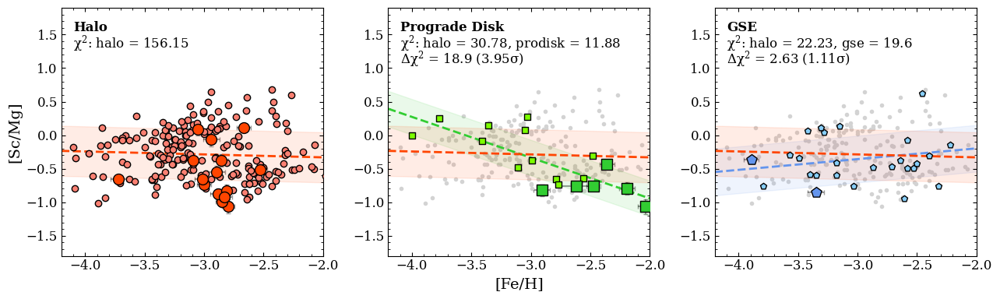

In [37]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
axs[1].set_xlabel('[Fe/H]')
axs[0].set_ylabel(f"[Sc/Mg]")    
axs[0].set_xlim(xlim)
axs[0].set_ylim(ylim)
axs[1].set_xlim(xlim)
axs[1].set_ylim(ylim)
axs[2].set_xlim(xlim)
axs[2].set_ylim(ylim)    

# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0]
ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)



# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[1]
ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                yline - std_prodisk,
                yline + std_prodisk,
                color='limegreen',
                alpha=0.1)

# # Plotting the prograde disk ±m_err lines
# ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['feh'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)

# Plotting the GSE stars (literature and x-shooter)
ax = axs[2]
ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
        xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                yline - std_gse,
                yline + std_gse,
                color='cornflowerblue',
                alpha=0.1)

# # Plotting the GSE ±m_err lines
# ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)


if delta_chisqr_save_path is not None:
        plt.savefig(delta_chisqr_save_path + '_no_retdisk.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(delta_chisqr_save_path + '_no_retdisk.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()

In [92]:
comb_gse_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/comb_gse_df.csv", index=False)
comb_prodisk_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/comb_prodisk_df.csv", index=False)
comb_halo_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/comb_halo_df.csv", index=False)
comb_retdisk_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/comb_retdisk_df.csv", index=False)

Will now try and do a **Monte Carlo Resampling** that will involve binning the data by metallicity, count the number of e.g. prograde disk stars in that bin, then randomly select halo stars in that bin. This will be done for all bins, then a fit will be done. The delta chisquared test will be calcualted for this, and will be repated n times. We will then calculate the percentage of those n tests that are like what we see in the prograde disk.

In [ ]:
def calc_delta_chisqr(comb_halo_df, comb_other_df, other_label, other_marker, other_color, n_iter, save_path=None, plot=True):
        
    # Setting up figure
    xlim = (-4.2, -2.0)
    ylim = (-1.8, 1.9)

    text_pos1 = (-4.1, 1.55)
    text_pos2 = (-4.1, 1.3)
    text_pos3 = (-4.1, 1.1)
    text_hozalign = 'left'
    
    
    # ---PERFORMING THE FITS--- #
    # Fitting polynomial to the halo data (both literature and x-shooter)
    weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
    p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=False)
    fit_halo = np.poly1d(p_halo)
    xline_halo = np.linspace(xlim[0], xlim[1], 100)
    yline_halo = fit_halo(xline_halo)
    res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
    std_halo = np.std(res_halo)
    
    # Fitting polynomial to the other data (both literature and x-shooter)
    weights_other = 1 / np.sqrt(comb_other_df['abund_err']**2 + np.std(comb_other_df['bestfit_abund_xfe'])**2)
    p_other = np.polyfit(comb_other_df['feh'], comb_other_df['bestfit_abund_xfe'], deg=1, w=weights_other, cov=False)
    fit_other = np.poly1d(p_other)
    xline_other = np.linspace(xlim[0], xlim[1], 100)
    yline_other = fit_other(xline_other)
    res_other = comb_other_df['bestfit_abund_xfe'] - fit_other(comb_other_df['feh'])
    std_other = np.std(res_other)
    
    
    # ---CALCULATING THE CHI-SQUARE VALUES--- #
    # Calculating the chi-square value for the other data using the halo fit
    # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # Adding the scatter in quadrature to the abundance error
    other_halofit_model = fit_halo(comb_other_df['feh'])
    other_halofit_error = np.sqrt(comb_other_df['abund_err'] ** 2 + std_other ** 2)
    other_halofit_chisqr = np.sum(((comb_other_df['bestfit_abund_xfe'] - other_halofit_model) ** 2) / (other_halofit_error ** 2))
    n_params = 0
    other_halofit_dof = len(comb_other_df) - n_params
    other_halofit_redchisqr = other_halofit_chisqr / other_halofit_dof
    other_halofit_pvalue = gammaincc(other_halofit_dof / 2, other_halofit_chisqr / 2)
    
    # Now doing this for the other fit    
    other_origfit_model = fit_other(comb_other_df['feh'])
    other_origfit_error = np.sqrt(comb_other_df['abund_err'] ** 2 + std_other ** 2)
    other_origfit_chisqr = np.sum(((comb_other_df['bestfit_abund_xfe'] - other_origfit_model) ** 2) / (other_origfit_error ** 2))
    n_params = 2
    other_origfit_dof = len(comb_other_df) - n_params # Number of parameters is the degree
    other_origfit_redchisqr = other_origfit_chisqr / other_origfit_dof
    other_origfit_pvalue = gammaincc(other_origfit_dof / 2, other_origfit_chisqr / 2)
    
    # Calculating the delta chisquare
    delta_chisqr = other_halofit_chisqr - other_origfit_chisqr
    
    # Storing the chi-square values in a dictionary
    chisq_dict = {
        'region': other_label,
        'iter': n_iter,
        'halofit_chisqr': other_halofit_chisqr,
        'halofit_chisqr_red': other_halofit_redchisqr,
        'halofit_pvalue': other_halofit_pvalue,
        'origfit_chisqr': other_origfit_chisqr,
        'origfit_chisqr_red': other_origfit_redchisqr,
        'origfit_pvalue': other_origfit_pvalue,
        'delta_chisqr': delta_chisqr}
    chisqr_df = pd.DataFrame(chisq_dict, index=[0])
    
    
    # ---PLOTTING--- #
    if plot:
        plt.figure(figsize=[6,5])
        plt.scatter(comb_other_df['feh'], comb_other_df['bestfit_abund_xfe'], color=other_color, marker=other_marker, 
                        edgecolor='black', zorder=10, linewidths=1, label=other_label)
        plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1, label='Halo Background')

        # Plotting the other fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_other(xline)
        plt.plot(xline, yline, color=other_color, linestyle='--', linewidth=2, label=f'{other_label} Fit')
        plt.fill_between(xline, 
                                yline - std_other,
                                yline + std_other,
                                color=other_color,
                                alpha=0.1)
        
        # Plotting the halo fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_halo(xline)
        plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
        plt.fill_between(xline, 
                                yline - std_halo,
                                yline + std_halo,
                                color='orangered',
                                alpha=0.1)
        
        # Making the text
        plt.text(text_pos1[0], text_pos1[1], other_label, fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        plt.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(other_halofit_chisqr, 2)}, {other_label} = {round(other_origfit_chisqr, 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        plt.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)
        
        plt.xlim(xlim)
        plt.ylim(ylim)
        plt.xlabel('[Fe/H]')
        plt.ylabel('[Sc/Mg]')
        
    if save_path is not None:
        chisqr_df.to_csv(save_path + f'deltachisqr_niter{n_iter}.csv', index=False)
        
        if plot:
            plt.savefig(save_path + f'deltachisqr_plot_niter{n_iter}.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        
    return chisqr_df

In [ ]:
# Performing the Monte Carlo resampling on the binned data
def resample_group(halo_df, other_df):
    """"For a given other_df (e.g. prograde disk or GSE), randomly resample stars in halo_df based on the number of stars
    in each bin in other_df. This returns a new dataframe of randomly resampled halo stars that has the same number of stars 
    as the other_df, but with the same distribution as the original halo_df.
    
    Parameters:
    -----------
    halo_df: pd.DataFrame
        The dataframe containing the halo stars, which should have a column 'feh_bin' for the metallicity bins.
    other_df: pd.DataFrame
        The dataframe containing the other group of stars (e.g. prograde disk or GSE), which should also have 
        a column 'feh_bin' for the metallicity bins.
        
    Returns:
    --------
    resampled_halo_df: pd.DataFrame
        A new dataframe containing the randomly resampled halo stars based on the distribution of the other_df
    """""
    
    # Extracting the randomly resampled data for the halo based on the number of stars in each bin in other_df
    resampled_halo_df = pd.DataFrame()  
    for bin_interval, count in other_df['feh_bin'].value_counts().items():
        
        # Getting the halo stars in the same bin
        halo_bin_stars = halo_df[halo_df['feh_bin'] == bin_interval]
        
        # Resample the halo stars based on the count in the other_df
        if len(halo_bin_stars) > 0 and count > 0:
            resampled_halo_bin_stars = halo_bin_stars.sample(n=count, replace=True)
            resampled_halo_df = pd.concat([resampled_halo_df, resampled_halo_bin_stars], ignore_index=True)
    
    return resampled_halo_df

n_iterations = 10
# resample_save_path = "/data/misfit/benlowe/xshooter/p115/chisqrs_resample/prodisk_resample/"
all_prodisk_deltachisqr_dfs = []
all_gse_deltachisqr_dfs = []
for n in range(n_iterations):
    
    # Only taking stars with [Fe/H] < -1.8 (to help with binning)
    comb_halo_feh180_df = comb_halo_df[comb_halo_df['feh'] < -1.8].copy()
    comb_prodisk_feh180_df = comb_prodisk_df[comb_prodisk_df['feh'] < -1.8].copy()
    comb_gse_feh180_df = comb_gse_df[comb_gse_df['feh'] < -1.8].copy()
    comb_retdisk_feh180_df = comb_retdisk_df[comb_retdisk_df['feh'] < -1.8].copy()

    # Binning the data by metallicity (0.5 dex bins), then adding jitter
    bin_size = 0.5 
    bins = np.arange(-4.0, -2.0 + bin_size, bin_size)
    shift = np.random.uniform(-0.2, 0.2)
    jittered_bins = bins + shift
        
    comb_halo_feh180_df['feh_bin'] = pd.cut(comb_halo_feh180_df['feh'], bins=jittered_bins, right=False)
    comb_prodisk_feh180_df['feh_bin'] = pd.cut(comb_prodisk_feh180_df['feh'], bins=jittered_bins, right=False)
    comb_gse_feh180_df['feh_bin'] = pd.cut(comb_gse_feh180_df['feh'], bins=jittered_bins, right=False)
    comb_retdisk_feh180_df['feh_bin'] = pd.cut(comb_retdisk_feh180_df['feh'], bins=jittered_bins, right=False)
    
    print(f"Performing iteration {n+1}/{n_iterations}...")
    # Extacting the randomly resampled data for the halo based on the number of prograde and GSE stars in each bin
    resampled_prodisk_df = resample_group(halo_df=comb_halo_feh180_df, other_df=comb_prodisk_feh180_df)
    resampled_gse_df = resample_group(halo_df=comb_halo_feh180_df, other_df=comb_gse_feh180_df)
    
    # Performing the delta chi-square calculation
    prodisk_chisqr_df = calc_delta_chisqr(comb_halo_df=comb_halo_feh180_df, comb_other_df=resampled_prodisk_df, other_label='Resampled Halo', 
                                  other_marker='s', other_color='lawngreen', plot=False, n_iter=n, save_path=None)
    gse_chisqr_df = calc_delta_chisqr(comb_halo_df=comb_halo_feh180_df, comb_other_df=resampled_gse_df, other_label='Resampled Halo',
                                  other_marker='p', other_color='cornflowerblue', plot=False, n_iter=n, save_path=None)
    
    all_prodisk_deltachisqr_dfs.append(prodisk_chisqr_df)
    all_gse_deltachisqr_dfs.append(gse_chisqr_df)

# Concatenating all the delta chi-square dataframes into one dataframe
all_prodisk_deltachisqr_df = pd.concat(all_prodisk_deltachisqr_dfs, ignore_index=True)
all_gse_deltachisqr_df = pd.concat(all_gse_deltachisqr_dfs, ignore_index=True)
    
        

Performing iteration 1/10...
Performing iteration 2/10...
Performing iteration 3/10...
Performing iteration 4/10...
Performing iteration 5/10...
Performing iteration 6/10...
Performing iteration 7/10...
Performing iteration 8/10...
Performing iteration 9/10...
Performing iteration 10/10...


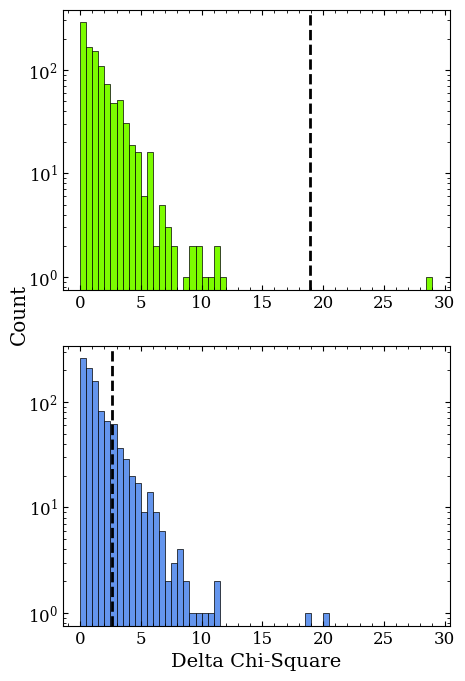

In [85]:
# Setting up the bins for the histogram
bin_size = 0.5
min_val = 0.0 
# max_val = np.max(all_prodisk_deltachisqr_df['delta_chisqr'])
max_val = np.max(pd.concat([all_prodisk_deltachisqr_df['delta_chisqr'], all_gse_deltachisqr_df['delta_chisqr']]))
custom_bins = np.arange(min_val, max_val + bin_size, bin_size)

# Plotting the histogram of the delta chi-square values
fig, axs = plt.subplots(2, 1, figsize=[5,8])
fig.supylabel('Count')
axs[1].set_xlabel('Delta Chi-Square')

# Resampled prograde disk
ax = axs[0]
ax.hist(all_prodisk_deltachisqr_df['delta_chisqr'], bins=custom_bins, color='lawngreen', edgecolor='black', log=True, linewidth=0.5)
ax.axvline(x=prodisk_delta_chisqr, color='black', linestyle='--', linewidth=2, label='Original Prograde Disk Delta Chisqr')

# Resampled GSE
ax = axs[1]
ax.hist(all_gse_deltachisqr_df['delta_chisqr'], bins=custom_bins, color='cornflowerblue', edgecolor='black', log=True, linewidth=0.5)
ax.axvline(x=gse_delta_chisqr, color='black', linestyle='--', linewidth=2, label='Original GSE Delta Chisqr')


##### 1D K-S Test

Halo: t-statistic = 0.31, p-value = 0.7586, sigma = 0.31
Prograde Disk: t-statistic = -1.14, p-value = 0.2700, sigma = 1.10
GSE: t-statistic = -0.61, p-value = 0.5488, sigma = 0.60
Retrograde Disk: t-statistic = 2.49, p-value = 0.1308, sigma = 1.51


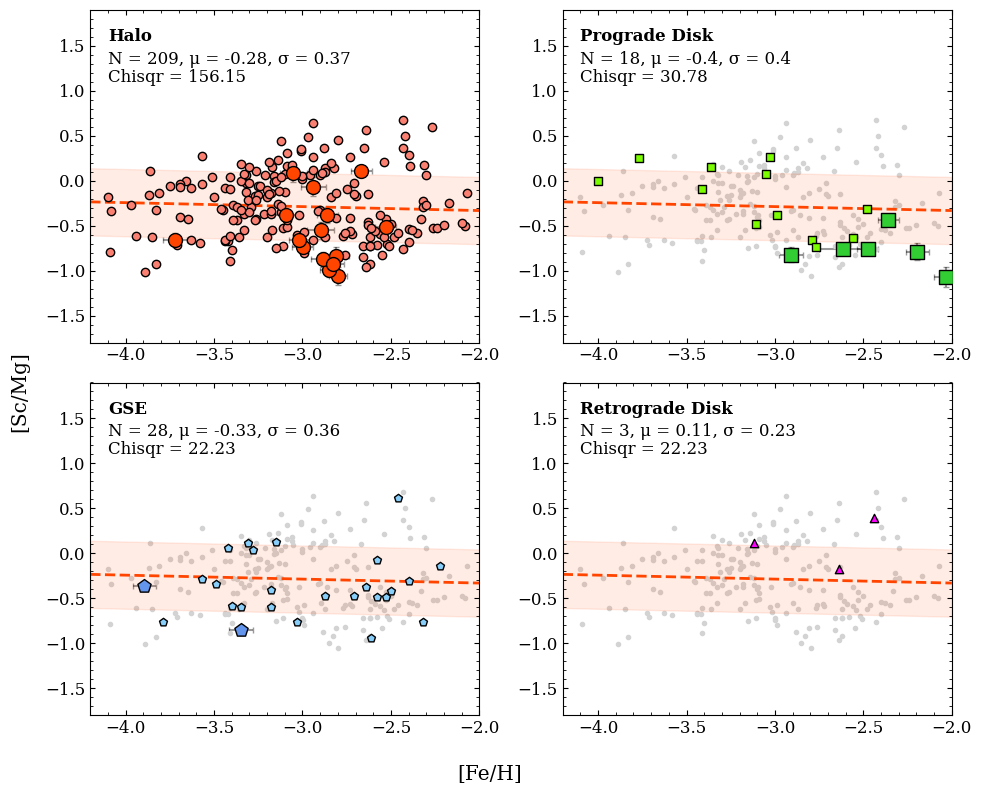

Sculptor: t-statistic = 2.12, p-value = 0.0669, sigma = 1.83


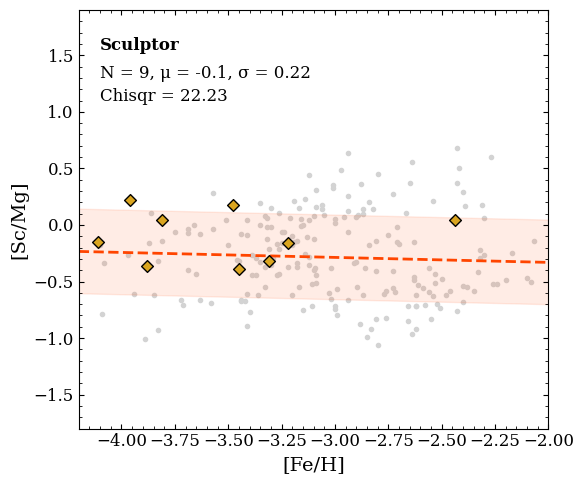

In [50]:
# ---PLOT 3: PLOTTING JUST HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')

fig.supylabel(f"[Sc/Mg]")
    
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Computing the residual z-score, then the 1-Sample t-test
res_halo = comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model
z_scores_halo = res_halo / std_halo
t_stat_halo, p_value_halo = stats.ttest_1samp(z_scores_halo, popmean=0.0)
sigma_halo = stats.norm.ppf(1 - p_value_halo / 2)
print(f"Halo: t-statistic = {t_stat_halo:.2f}, p-value = {p_value_halo:.4f}, sigma = {sigma_halo:.2f}")


# Plotting the halo stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(lit_orbabund_halo['feh'], lit_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_halo['feh'], el_xshooter_abund_halo['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_halo['feh_err'], yerr=el_xshooter_abund_halo['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
    fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, z-score = {round(t_stat_halo, 2)}, p-value = {round(p_value_halo, 4)}", 
#     fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_halo, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)


# Computing the residual z-score, then the 1-Sample t-test
res_prodisk = comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model
z_scores_prodisk = res_prodisk / std_halo
t_stat_prodisk, p_value_prodisk = stats.ttest_1samp(z_scores_prodisk, popmean=0.0)
sigma_prodisk = stats.norm.ppf(1 - p_value_prodisk / 2)
print(f"Prograde Disk: t-statistic = {t_stat_prodisk:.2f}, p-value = {p_value_prodisk:.4f}, sigma = {sigma_prodisk:.2f}")
    
# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)
    
# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)
        
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
    fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(prodisk_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, z-score = {round(t_stat_prodisk, 2)}, p-value = {round(p_value_prodisk, 4)}", 
#     fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_prodisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)    


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Computing the residual z-score, then the 1-Sample t-test
res_gse = comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model
z_scores_gse = res_gse / std_halo
t_stat_gse, p_value_gse = stats.ttest_1samp(z_scores_gse, popmean=0.0)
sigma_gse = stats.norm.ppf(1 - p_value_gse / 2)
print(f"GSE: t-statistic = {t_stat_gse:.2f}, p-value = {p_value_gse:.4f}, sigma = {sigma_gse:.2f}")
    
# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)
    
# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
    fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, z-score = {round(t_stat_gse, 2)}, p-value = {round(p_value_gse, 4)}", 
#     fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_gse, 2)}", fontsize=12, horizontalalignment=text_hozalign)        


# --RETROGRADE DISK--- #
# Calculating the chi-square value for the retrograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
if len(comb_retdisk_df) > 0:
    retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
    retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
    retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
    n_params = 0
    retdisk_halofit_dof = len(comb_retdisk_df) - n_params
    retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
    retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)
    
    # Computing the residual z-score, then the 1-Sample t-test
    res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model
    z_scores_retdisk = res_retdisk / std_halo
    t_stat_retdisk, p_value_retdisk = stats.ttest_1samp(z_scores_retdisk, popmean=0.0)
    sigma_retdisk = stats.norm.ppf(1 - p_value_retdisk / 2)
    print(f"Retrograde Disk: t-statistic = {t_stat_retdisk:.2f}, p-value = {p_value_retdisk:.4f}, sigma = {sigma_retdisk:.2f}")
                            
    # Plotting the retrograde disk stars (literature)
    ax = axs[1,1]
    ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
            
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)
    
    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, z-score = {round(t_stat_retdisk, 2)}, p-value = {round(p_value_retdisk, 4)}", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_retdisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)
else:
    ax = axs[1,1]
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], f"Chisqr = N/A", 
            fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, z-score = N/A, p-value = N/A", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Sigma = N/A", fontsize=12, horizontalalignment=text_hozalign)

if halo_fit_save_path is not None:
    plt.savefig(halo_fit_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(halo_fit_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()

# Saving the chi-square values into a csv file
chisq_all_dict = {
    'Region': ['pro_disk', 'halo', 'gse', 'ret_disk'],
    'halofit_chisqr': [prodisk_halofit_chisqr, halo_halofit_chisqr, gse_halofit_chisqr, retdisk_halofit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    'halofit_chisqr_red': [prodisk_halofit_redchisqr, halo_halofit_redchisqr, gse_halofit_redchisqr, retdisk_halofit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    'halofit_pvalue': [prodisk_halofit_pvalue, halo_halofit_pvalue, gse_halofit_pvalue, retdisk_halofit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    'origfit_chisqr': [prodisk_origfit_chisqr, np.nan, gse_origfit_chisqr, retdisk_origfit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
    'origfit_chisqr_red': [prodisk_origfit_redchisqr, np.nan, gse_origfit_redchisqr, retdisk_origfit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
    'origfit_pvalue': [prodisk_origfit_pvalue, np.nan, gse_origfit_pvalue, retdisk_origfit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
    'delta_chisqr': [prodisk_delta_chisqr, np.nan, gse_delta_chisqr, retdisk_delta_chisqr if len(comb_retdisk_df) > 0 else np.nan]
}
chisq_all_df = pd.DataFrame(chisq_all_dict)
if halo_fit_save_path is not None:
    chisq_all_df.to_csv(halo_fit_save_path + '_chisqrs.csv', index=False)
    

# ---SCULPTOR GALAXY--- #
if sculptor is not None:
    sculptor_el = 'scmg'        
    
    sculp_el_df = sculp_df.dropna(subset=[sculptor_el])

    # Calculating the chi-square value for the Sculptor data using the halo fit
    # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
    # Adding the scatter in quadrature to the abundance error
    sculp_halofit_model = fit_halo(sculp_el_df['feh'])
    sculp_halofit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2) 
    sculp_halofit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_halofit_model) ** 2) / (sculp_halofit_error ** 2))
    n_params = 0
    sculp_halofit_dof = len(sculp_el_df) - n_params
    sculp_halofit_redchisqr = sculp_halofit_chisqr / sculp_halofit_dof
    sculp_halofit_pvalue = gammaincc(sculp_halofit_dof / 2, sculp_halofit_chisqr / 2)
    
    # Computing the residual z-score, then the 1-Sample t-test
    res_sculp = sculp_el_df[sculptor_el] - sculp_halofit_model
    z_scores_sculp = res_sculp / std_halo
    t_stat_sculp, p_value_sculp = stats.ttest_1samp(z_scores_sculp, popmean=0.0)
    sigma_sculp = stats.norm.ppf(1 - p_value_sculp / 2)
    print(f"Sculptor: t-statistic = {t_stat_sculp:.2f}, p-value = {p_value_sculp:.4f}, sigma = {sigma_sculp:.2f}")
            
    # Plotting 
    plt.figure(figsize=[6,5])
    plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
                    edgecolor='black', zorder=10, linewidths=1)
    
    # Plotting the background halo data
    if halo_background:
        plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
            
    # Plotting the halo fit
    xline = np.linspace(-4.2, -1.2, 100)
    yline = fit_halo(xline)
    plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    plt.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)
    
    # Making the text
    plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df[sculptor_el]), 2)}, σ = {round(np.std(sculp_el_df[sculptor_el]), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
    plt.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    # plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, z-score = {round(t_stat_sculp, 2)}, p-value = {round(p_value_sculp, 4)}", 
    #     fontsize=12, horizontalalignment=text_hozalign)
    # plt.text(text_pos3[0], text_pos3[1], f"Sigma = {round(sigma_sculp, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.xlabel('[Fe/H]')
    plt.ylabel(f'[Sc/Mg]')
    plt.tight_layout()
    
    if halo_fit_save_path is not None:
        plt.savefig(halo_fit_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(halo_fit_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.show()
    
    # Saving the chi-square values into a csv file
    chisq_sculp_dict = {
        'Region': ['sculptor'],
        'halofit_chisqr': [sculp_halofit_chisqr],
        'halofit_chisqr_red': [sculp_halofit_redchisqr],
        'halofit_pvalue': [sculp_halofit_pvalue],
        'origfit_chisqr': [sculp_origfit_chisqr],
        'origfit_chisqr_red': [sculp_origfit_redchisqr],
        'origfit_pvalue': [sculp_origfit_pvalue],
        'delta_chisqr': [sculp_delta_chisqr]
    }
    chisq_sculp_df = pd.DataFrame(chisq_sculp_dict)
    if halo_fit_save_path is not None:
        chisq_sculp_df.to_csv(halo_fit_save_path + '_sculptor_chisqrs.csv', index=False)
# ------------------------------------------------------------------------------------------------------------ #        


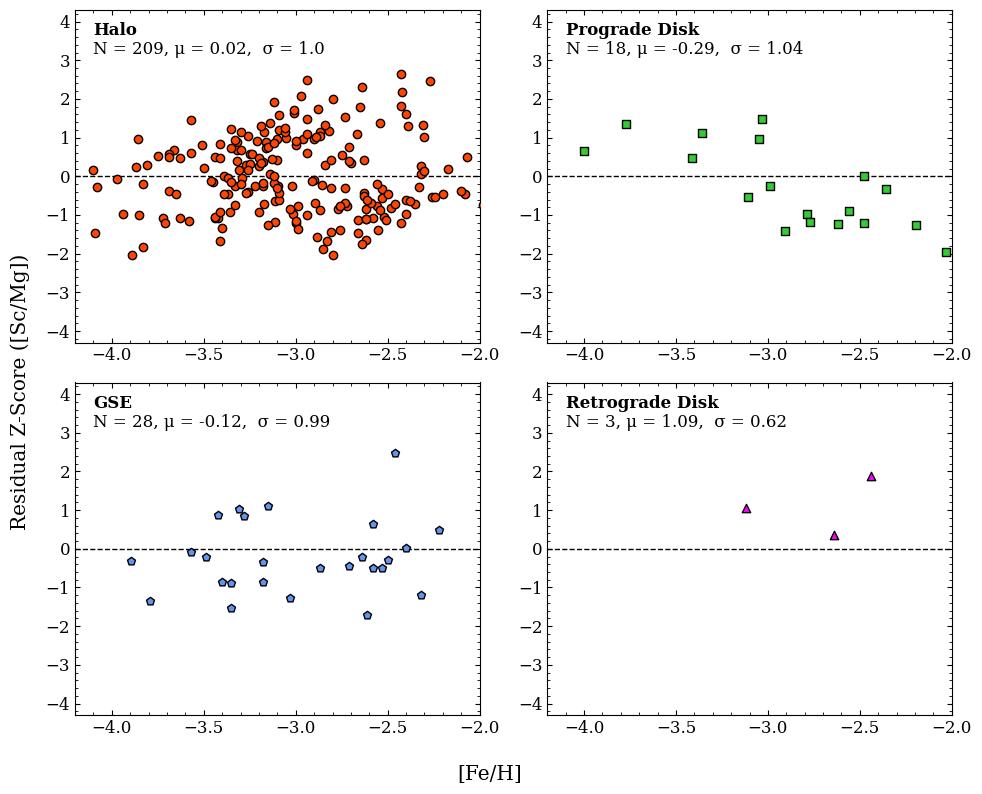

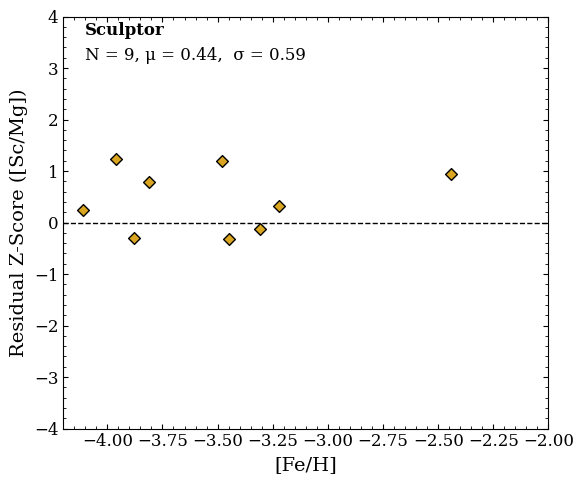

In [53]:
# ---PLOTTING THE Z-SCORES--- #
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')

fig.supylabel(f"Residual Z-Score ([Sc/Mg])")

    
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim((-4.3, 4.3))
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim((-4.3, 4.3))
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim((-4.3, 4.3))
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim((-4.3, 4.3))


# ---HALO--- #    
# Plotting the halo stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(comb_halo_df['feh'], z_scores_halo, color='orangered', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.axhline(0, color='black', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], 3.65, 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], 3.15, f"N = {len(comb_halo_df)}, μ = {round(np.mean(z_scores_halo), 2)},  σ = {round(np.std(z_scores_halo), 2)}",
    fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_halo, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# ---PROGRADE DISK--- #
# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(comb_prodisk_df['feh'], z_scores_prodisk, color='limegreen', marker='s', edgecolor='black', zorder=10, linewidths=1)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
# Making the text
ax.text(text_pos1[0], 3.65, 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_prodisk)}, μ = {round(np.mean(z_scores_prodisk), 2)},  σ = {round(np.std(z_scores_prodisk), 2)}",
    fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_prodisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)    


# ---GSE--- #        
# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(comb_gse_df['feh'], z_scores_gse, color='cornflowerblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.axhline(0, color='black', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], 3.65, 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_gse)}, μ = {round(np.mean(z_scores_gse), 2)},  σ = {round(np.std(z_scores_gse), 2)}",
    fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_gse, 2)}", fontsize=12, horizontalalignment=text_hozalign)    


# --RETROGRADE DISK--- #
if len(comb_retdisk_df) > 0:
                            
    # Plotting the retrograde disk stars (literature)
    ax = axs[1,1]
    ax.scatter(comb_retdisk_df['feh'], z_scores_retdisk, color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
            
    # Making the text
    ax.text(text_pos1[0], 3.65, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], 3.15, f"N = {len(z_scores_retdisk)}, μ = {round(np.mean(z_scores_retdisk), 2)},  σ = {round(np.std(z_scores_retdisk), 2)}",
            fontsize=12, horizontalalignment=text_hozalign)        
    # ax.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_retdisk, 2)}", fontsize=12, horizontalalignment=text_hozalign)
else:
    ax = axs[1,1]
    ax.axhline(0, color='black', linestyle='--', linewidth=1)

    # Making the text
    ax.text(text_pos1[0], 3.65, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], 3.15, f"N = {len(comb_retdisk_df)}, μ = N/A,  σ = N/A",
        fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], 2.7, f"Sigma = N/A", fontsize=12, horizontalalignment=text_hozalign)

if z_score_save_path is not None:
    plt.savefig(z_score_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(z_score_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()


if sculptor is not None:
    # Plotting the Sculptor data
    plt.figure(figsize=[6,5])
    plt.scatter(sculp_el_df['feh'], z_scores_sculp, color='goldenrod', marker='D', edgecolor='black', zorder=10, linewidths=1)
    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    plt.xlabel(f"[Fe/H]")
    plt.ylabel(f"Residual Z-Score ([Sc/Mg])")
    plt.xlim(xlim)
    plt.ylim((-4, 4))
    
    
    # Making the text
    plt.text(text_pos1[0], 3.65, 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    plt.text(text_pos2[0], 3.15, f"N = {len(z_scores_sculp)}, μ = {round(np.mean(z_scores_sculp), 2)},  σ = {round(np.std(z_scores_sculp), 2)}",
        fontsize=12, horizontalalignment=text_hozalign)
    # plt.text(text_pos3[0], 2.7, f"Sigma = {round(sigma_sculp, 2)}", fontsize=12, horizontalalignment=text_hozalign)
    
    plt.tight_layout()
    
    # Saving all individual residual z-score values into a .csv file (including sculptor)
    z_score_dict = {
        'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
        'z_scores': [z_scores_prodisk.to_numpy(), z_scores_gse.to_numpy(), z_scores_retdisk.to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), z_scores_sculp.to_numpy()],
        'feh': [comb_prodisk_df['feh'].to_numpy(), comb_gse_df['feh'].to_numpy(), comb_retdisk_df['feh'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), sculp_el_df['feh'].to_numpy()],
        'abund': [comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), comb_retdisk_df['bestfit_abund_xfe'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([]), sculp_el_df[sculptor_el].to_numpy()]
    }
    z_score_df = pd.DataFrame(z_score_dict)
    
    if z_score_save_path is not None:
        plt.savefig(z_score_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(z_score_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        
        z_score_df.to_csv(z_score_save_path + "_results.csv", index=False)
    plt.show()
    
else:
    # Saving all individual residual z-score values into a .csv file (excluding sculptor)
    z_score_dict = {
        'region': ['prodisk', 'gse', 'retdisk'],
        'z_scores': [z_scores_prodisk.to_numpy(), z_scores_gse.to_numpy(), z_scores_retdisk.to_numpy() if len(comb_retdisk_df) > 0 else np.array([])],
        'feh': [comb_prodisk_df['feh'].to_numpy(), comb_gse_df['feh'].to_numpy(), comb_retdisk_df['feh'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([])],
        'abund': [comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), comb_retdisk_df['bestfit_abund_xfe'].to_numpy() if len(comb_retdisk_df) > 0 else np.array([])]
    }
    z_score_df = pd.DataFrame(z_score_dict)
    
    if z_score_save_path is not None:
        z_score_df.to_csv(z_score_save_path + "_results.csv", index=False)
# ------------------------------------------------------------------------------------------------------------ #


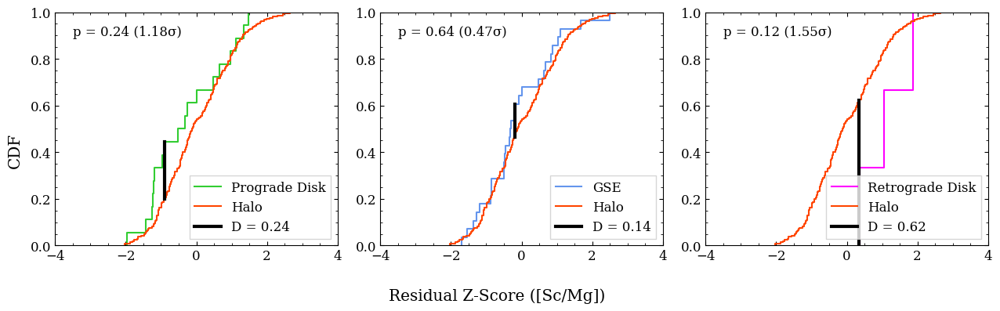

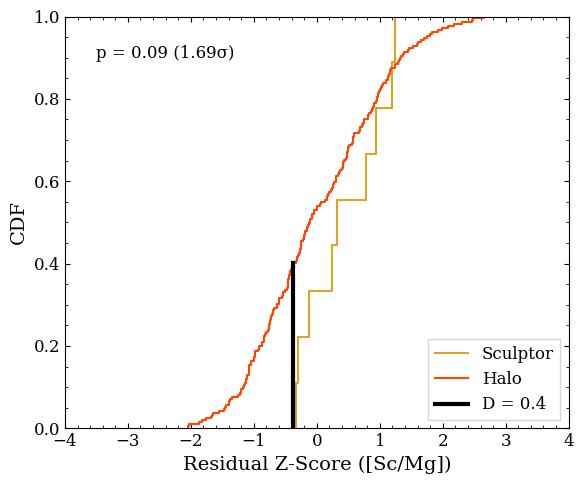

In [52]:
# ---PLOTTING THE CUMULATIVE DISTRIBUTION FUNCTIONS--- #
fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supylabel('CDF')    

fig.supxlabel(f"Residual Z-Score ([Sc/Mg])")


axs[0].set_xlim((-4, 4))
axs[1].set_xlim((-4, 4))
axs[2].set_xlim((-4, 4))


# ---PROGRADE DISK--- #
# Computing the K-S test
ks_res_prodisk = ks_2samp(z_scores_halo, z_scores_prodisk)
d_stat_1d_prodisk = ks_res_prodisk.statistic
p_val_1d_prodisk = ks_res_prodisk.pvalue
x_max_gap = ks_res_prodisk.statistic_location
sigma_1d_prodisk = stats.norm.ppf(1 - p_val_1d_prodisk / 2)

# Using x_max_gap, find corresponding y-value
y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
y_prodisk = np.sum(z_scores_prodisk.to_numpy() <= x_max_gap) / len(z_scores_prodisk.to_numpy())

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0]
ax.ecdf(z_scores_prodisk.to_numpy(), label='Prograde Disk', color='limegreen')       
ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')

# Plotting the maximum gap line
ax.plot([x_max_gap, x_max_gap], [y_halo, y_prodisk], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_prodisk, 2)}")

# Making the text
ax.text(-3.5, 0.9, f"p = {round(p_val_1d_prodisk, 2)} ({round(sigma_1d_prodisk, 2)}σ)", 
        fontsize=12, horizontalalignment='left')

ax.legend(fancybox=False, loc='lower right')


# ---GSE--- #        
# Computing the K-S test
ks_res_gse = ks_2samp(z_scores_halo, z_scores_gse)
d_stat_1d_gse = ks_res_gse.statistic
p_val_1d_gse = ks_res_gse.pvalue
x_max_gap = ks_res_gse.statistic_location
sigma_1d_gse = stats.norm.ppf(1 - p_val_1d_gse / 2)

# Using x_max_gap, find corresponding y-value
y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
y_gse = np.sum(z_scores_gse.to_numpy() <= x_max_gap) / len(z_scores_gse.to_numpy())

# Plotting the GSE stars (literature and x-shooter)
ax = axs[1]
ax.ecdf(z_scores_gse.to_numpy(), label='GSE', color='cornflowerblue')
ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')

# Plotting the maximum gap line
ax.plot([x_max_gap, x_max_gap], [y_halo, y_gse], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_gse, 2)}")

# Making the text
ax.text(-3.5, 0.9, f"p = {round(p_val_1d_gse, 2)} ({round(sigma_1d_gse, 2)}σ)", 
        fontsize=12, horizontalalignment='left')

ax.legend(fancybox=False, loc='lower right')


# --RETROGRADE DISK--- #
if len(comb_retdisk_df) > 0:
    
    # Computing the K-S test
    ks_res_retdisk = ks_2samp(z_scores_halo, z_scores_retdisk)
    d_stat_1d_retdisk = ks_res_retdisk.statistic
    p_val_1d_retdisk = ks_res_retdisk.pvalue
    x_max_gap = ks_res_retdisk.statistic_location
    sigma_1d_retdisk = stats.norm.ppf(1 - p_val_1d_retdisk / 2)
    
    # Using x_max_gap, find the corresponding y-value
    y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    y_retdisk = np.sum(z_scores_retdisk.to_numpy() <= x_max_gap) / len(z_scores_retdisk.to_numpy())
                            
    # Plotting the retrograde disk stars (literature)
    ax = axs[2]
    ax.ecdf(z_scores_retdisk.to_numpy(), label='Retrograde Disk', color='fuchsia')
    ax.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')      
    ax.legend(fancybox=False, loc='lower right')
    
    # Plotting the maximum gap line
    ax.plot([x_max_gap, x_max_gap], [y_halo, y_retdisk], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_retdisk, 2)}")
    
    # Making the text
    ax.text(-3.5, 0.9, f"p = {round(p_val_1d_retdisk, 2)} ({round(sigma_1d_retdisk, 2)}σ)", 
            fontsize=12, horizontalalignment='left')
    
    ax.legend(fancybox=False, loc='lower right')
else:
    ax = axs[2]
    ax.text(-3.5, 0.9, f"p = N/A (N/Aσ)", 
            fontsize=12, horizontalalignment='left')


if cdf_save_path is not None:
    plt.savefig(cdf_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(cdf_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()

if sculptor is not None:
    
    # Computing the K-S test
    ks_res_sculp = ks_2samp(z_scores_halo, z_scores_sculp)
    d_stat_1d_sculp = ks_res_sculp.statistic
    p_val_1d_sculp = ks_res_sculp.pvalue
    x_max_gap = ks_res_sculp.statistic_location
    sigma_1d_sculp = stats.norm.ppf(1 - p_val_1d_sculp / 2)
    
    # Using x_max_gap, find the corresponding y-value
    y_halo = np.sum(z_scores_halo.to_numpy() <= x_max_gap) / len(z_scores_halo.to_numpy())
    y_sculp = np.sum(z_scores_sculp.to_numpy() <= x_max_gap) / len(z_scores_sculp.to_numpy())
    
    # Plotting the Sculptor data
    plt.figure(figsize=[6,5])
    plt.ecdf(z_scores_sculp.to_numpy(), label='Sculptor', color='goldenrod')
    plt.ecdf(z_scores_halo.to_numpy(), label='Halo', color='orangered')
    
    # Plotting the maximum line
    plt.plot([x_max_gap, x_max_gap], [y_halo, y_sculp], color='black', linestyle='-', linewidth=3, label=f"D = {round(d_stat_1d_sculp, 2)}")
    
    # Making the text
    plt.text(-3.5, 0.9, f"p = {round(p_val_1d_sculp, 2)} ({round(sigma_1d_sculp, 2)}σ)", 
            fontsize=12, horizontalalignment='left')
    
    plt.legend(fancybox=False, loc='lower right')
    plt.xlabel(f"Residual Z-Score ([Sc/Mg])")
    plt.ylabel('CDF')
    plt.xlim((-4, 4))
    plt.ylim((0, 1))
    plt.tight_layout()
    
    # Storing and saving the 2D K-S test results into a dataframe and csv file (including sculptor)
    ks_1d_results_dict = {
        'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
        'D_statistic': [d_stat_1d for d_stat_1d in [d_stat_1d_prodisk, d_stat_1d_gse, d_stat_1d_retdisk, d_stat_1d_sculp]],
        'p_value': [p_val_1d for p_val_1d in [p_val_1d_prodisk, p_val_1d_gse, p_val_1d_retdisk, p_val_1d_sculp]],
        'sigma': [sigma_1d for sigma_1d in [sigma_1d_prodisk, sigma_1d_gse, sigma_1d_retdisk, sigma_1d_sculp]]}
    ks_1d_results_df = pd.DataFrame(ks_1d_results_dict)

            
    if cdf_save_path is not None:
        plt.savefig(cdf_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(cdf_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')

        ks_1d_results_df.to_csv(cdf_save_path + "_results.csv", index=False)
    plt.show()
# ------------------------------------------------------------------------------------------------------------ #


##### 2D K-S Test

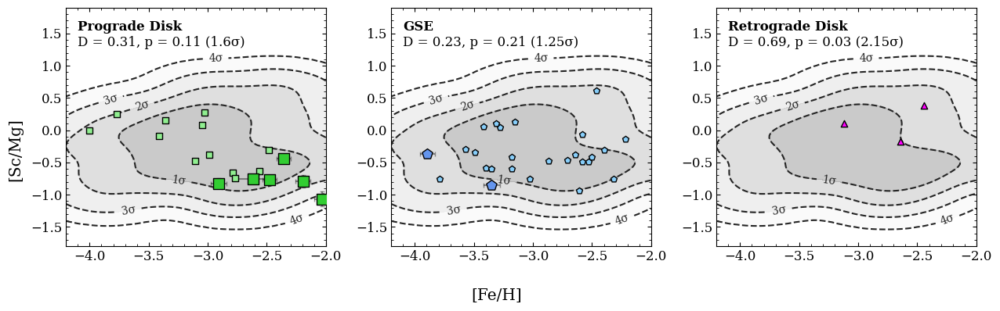

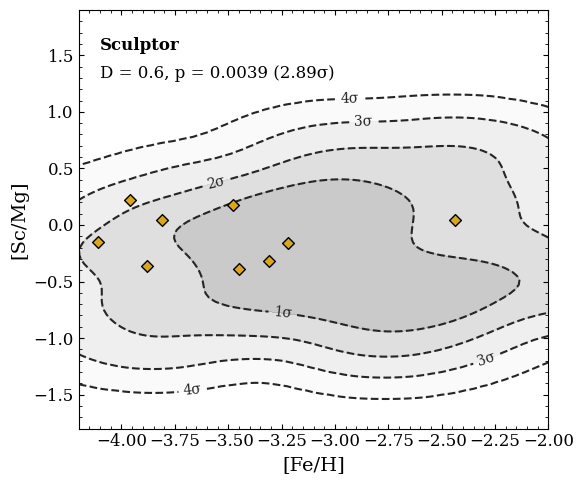

In [54]:
# ---PLOTTING 2D CUMULATIVE DISTRIBUTION FUNCTION PLOT--- #
fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')    

fig.supylabel(f"[Sc/Mg]")

    
axs[0].set_xlim(xlim)
axs[0].set_ylim(ylim)
axs[1].set_xlim(xlim)
axs[1].set_ylim(ylim)
axs[2].set_xlim(xlim)
axs[2].set_ylim(ylim)    



# Compute the KDE
xy_halo = np.vstack([comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe']])
kde_halo = gaussian_kde(xy_halo)

# Creating the grid for the KDE plot
x_grid = np.linspace(xlim[0], xlim[1], 100)
y_grid = np.linspace(ylim[0], ylim[1], 100)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
positions = np.vstack([X_grid.ravel(), Y_grid.ravel()])

# Computing the KDE values on the grid
Z_halo = np.reshape(kde_halo(positions).T, X_grid.shape)

# Finding the sigma thresholds
Z_halo_flat = Z_halo.flatten()
Z_halo_sorted = np.sort(Z_halo_flat)
cum_Z_halo = np.cumsum(Z_halo_sorted) / np.sum(Z_halo_sorted)

level_1sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.3173)]
level_2sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.0455)]
level_3sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.0027)]
level_4sigma = Z_halo_sorted[np.searchsorted(cum_Z_halo, 0.000063)]

sigma_levels = [level_4sigma, level_3sigma, level_2sigma, level_1sigma]
sigma_labels = {level_4sigma: '4σ', level_3sigma: '3σ', level_2sigma: '2σ', level_1sigma: '1σ'}

fill_levels = [level_4sigma, level_3sigma, level_2sigma, level_1sigma, Z_halo.max()]
fill_colors = ['#f0f0f0', '#cccccc', '#969696', '#525252']
line_colors = ['#252525', '#252525', '#252525', '#252525']


# ---PROGRADE DISK WITH HALO--- #
ax = axs[0]

# Plotting the halo contours with KDE
ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)

# Performing the 2D K-S test
p_val_2d_prodisk, d_stat_2d_prodisk = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
                                    comb_prodisk_df['feh'].to_numpy(), comb_prodisk_df['bestfit_abund_xfe'].to_numpy(), extra=True)
sigma_2d_prodisk = stats.norm.ppf(1 - p_val_2d_prodisk / 2)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_orbabund_prodisk['feh'], lit_orbabund_prodisk['abund'], color='lightgreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_prodisk['feh'], el_xshooter_abund_prodisk['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_prodisk['feh_err'], yerr=el_xshooter_abund_prodisk['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_prodisk, 2)}, p = {round(p_val_2d_prodisk, 2)} ({round(sigma_2d_prodisk, 2)}σ)", 
    fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(prodisk_halofit_chisqr, 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)


# ---GSE WITH HALO--- #        
ax = axs[1]

# Plotting the halo contours with KDE 
ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)

# Performing the 2D K-S test
p_val_2d_gse, d_stat_2d_gse = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
                                    comb_gse_df['feh'].to_numpy(), comb_gse_df['bestfit_abund_xfe'].to_numpy(), extra=True)
sigma_2d_gse = stats.norm.ppf(1 - p_val_2d_gse / 2)
    
# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_orbabund_gse['feh'], lit_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_abund_gse['feh'], el_xshooter_abund_gse['bestfit_abund_xfe'], 
            xerr=el_xshooter_abund_gse['feh_err'], yerr=el_xshooter_abund_gse['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_gse, 2)}, p = {round(p_val_2d_gse, 2)} ({round(sigma_2d_gse, 2)}σ)", 
    fontsize=12, horizontalalignment=text_hozalign)
# ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(gse_halofit_chisqr, 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)


# --RETROGRADE DISK WITH HALO--- #
if len(comb_retdisk_df) > 0:
                            
    # Plotting the retrograde disk stars (literature)
    ax = axs[2]
    
    # Plotting the halo contours with KDE 
    ax.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    cs = ax.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    ax.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
    
    # Performing the 2D K-S test
    p_val_2d_retdisk, d_stat_2d_retdisk = ndtest.ks2d2s(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], 
                                        comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], extra=True)
    sigma_2d_retdisk = stats.norm.ppf(1 - p_val_2d_retdisk / 2)
        
    # Plotting the retrograde disk stars (literature)
    ax.scatter(lit_orbabund_retdisk['feh'], lit_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_retdisk, 2)}, p = {round(p_val_2d_retdisk, 2)} ({round(sigma_2d_retdisk, 2)}σ)", 
        fontsize=12, horizontalalignment=text_hozalign)
    # ax.text(text_pos3[0], text_pos3[1], f"Chisqr = {round(retdisk_halofit_chisqr, 2)}", 
    #         fontsize=12, horizontalalignment=text_hozalign)
    
else:
    ax = axs[2]
    
    p_val_2d_retdisk =  np.nan
    d_stat_2d_retdisk = np.nan
    sigma_2d_retdisk = np.nan
    
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"D = N/A, p = N/A", 
        fontsize=12, horizontalalignment=text_hozalign)


if stat_save_path is not None:
    plt.savefig(stat_save_path + '_v2.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(stat_save_path + '_v2.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()


if sculptor is not None:
    sculptor_el = 'scmg'
    
    sculp_el_df = sculp_df.dropna(subset=[sculptor_el])
    
    # Plotting the data
    plt.figure(figsize=[6,5])
    plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
                    edgecolor='black', zorder=10, linewidths=1)

    # Plotting the halo contours with KDE
    plt.contourf(X_grid, Y_grid, Z_halo, levels=fill_levels, alpha=0.3, colors=fill_colors)
    cs = plt.contour(X_grid, Y_grid, Z_halo, levels=sigma_levels, linestyles='--', colors=line_colors)
    plt.clabel(cs, inline=True, fontsize=10, fmt=sigma_labels)
    
    
    # Performing the 2D K-S test
    p_val_2d_sculp, d_stat_2d_sculp = ndtest.ks2d2s(comb_halo_df['feh'].to_numpy(), comb_halo_df['bestfit_abund_xfe'].to_numpy(), 
                                        sculp_el_df['feh'].to_numpy(), sculp_el_df[sculptor_el].to_numpy(), extra=True)
    sigma_2d_sculp = stats.norm.ppf(1 - p_val_2d_sculp / 2)
            
    # Making the text
    plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    plt.text(text_pos2[0], text_pos2[1], f"D = {round(d_stat_2d_sculp, 2)}, p = {round(p_val_2d_sculp, 4)} ({round(sigma_2d_sculp, 2)}σ)", 
        fontsize=12, horizontalalignment=text_hozalign)
    
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.xlabel('[Fe/H]')
    plt.ylabel(f'[Sc/Mg]')
    plt.tight_layout()
    
    # Storing and saving the 2D K-S test results into a dataframe and csv file (including sculptor)
    ks_2d_results_dict = {
        'region': ['prodisk', 'gse', 'retdisk', 'sculptor'],
        'D_statistic': [d_stat_2d for d_stat_2d in [d_stat_2d_prodisk, d_stat_2d_gse, d_stat_2d_retdisk, d_stat_2d_sculp]],
        'p_value': [p_val_2d for p_val_2d in [p_val_2d_prodisk, p_val_2d_gse, p_val_2d_retdisk, p_val_2d_sculp]],
        'sigma': [sigma_2d for sigma_2d in [sigma_2d_prodisk, sigma_2d_gse, sigma_2d_retdisk, sigma_2d_sculp]]}
    ks_2d_results_df = pd.DataFrame(ks_2d_results_dict)
    
    if stat_save_path is not None:
        plt.savefig(stat_save_path + "_sculptor_v2.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(stat_save_path + "_sculptor_v2.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        
        ks_2d_results_df.to_csv(stat_save_path + "_results.csv", index=False)
    plt.show()

else:
    # Storing and saving the 2D K-S test results into a dataframe and csv file (not including sculptor)
    ks_2d_results_dict = {
        'region': ['prodisk', 'gse', 'retdisk'],
        'D_statistic': [d_stat_2d for d_stat_2d in [d_stat_2d_prodisk, d_stat_2d_gse, d_stat_2d_retdisk]],
        'p_value': [p_val_2d for p_val_2d in [p_val_2d_prodisk, p_val_2d_gse, p_val_2d_retdisk]],
        'sigma': [sigma_2d for sigma_2d in [sigma_2d_prodisk, sigma_2d_gse, sigma_2d_retdisk]]}
    ks_2d_results_df = pd.DataFrame(ks_2d_results_dict)
    
    if stat_save_path is not None:
        ks_2d_results_df.to_csv(stat_save_path + "_results.csv", index=False)
# ------------------------------------------------------------------------------------------------------------ #


With GALAH DR4 data

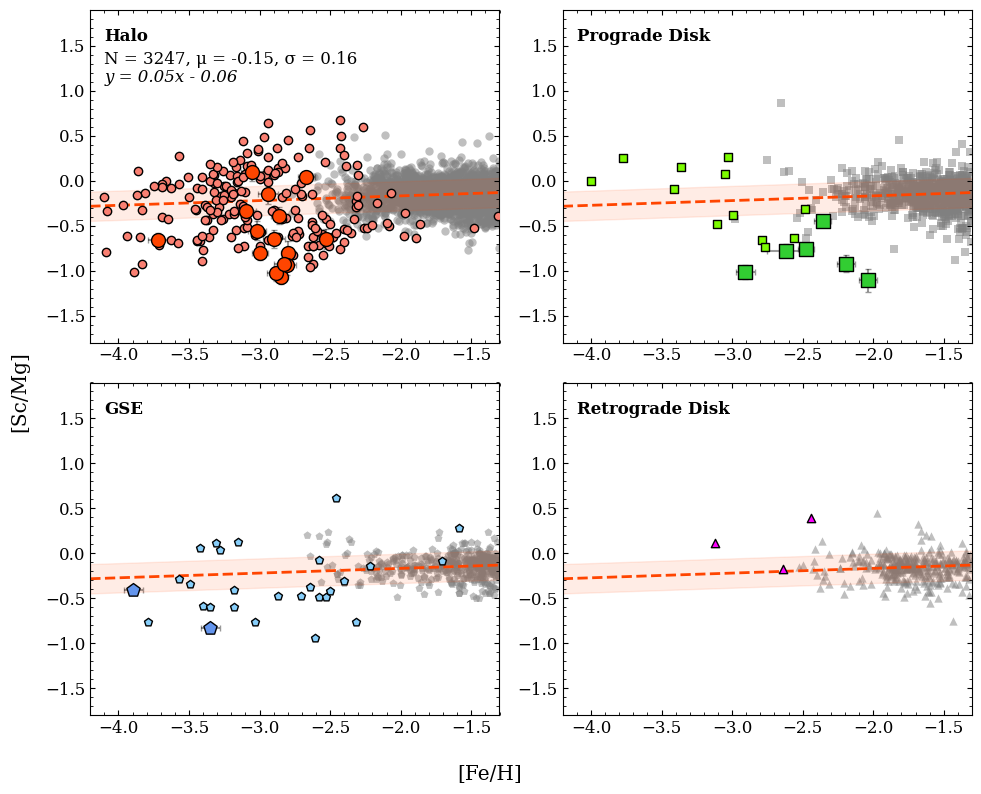

In [77]:
# Setting up figure
xlim = (-4.2, -1.3)
ylim = (-1.8, 1.9)

text_pos1 = (-4.1, 1.55)
text_pos2 = (-4.1, 1.3)
text_pos3 = (-4.1, 1.1)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Sc/Mg]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# --SUBPLOT 1: HALO--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo, scmg_galah_halo[['star_id', 'feh', 'abund_scmg', 'abund_scmg_err']]], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['abund_scmg'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_scmg'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['feh'], lit_halo['abund_scmg'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_scmg'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_scmg'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_scmg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH halo stars
ax.scatter(scmg_galah_halo['feh'], scmg_galah_halo['abund_scmg'], color='grey', marker='o', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_scmg']), 2)}, σ = {round(np.std(comb_halo_df['abund_scmg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# ---SUBPLOT 2: PROGRADE DISK--- #
ax = axs[0,1]

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_scmg'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_scmg'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_scmg'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_scmg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH stars
ax.scatter(scmg_galah_prodisk['feh'], scmg_galah_prodisk['abund_scmg'], color='grey', marker='s', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_scmg']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_scmg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_prodisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
comb_gse_df = pd.concat([xshooter_gse, lit_gse], ignore_index=True)

p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['abund_scmg'], deg=1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['abund_scmg'] - fit_gse(comb_gse_df['feh'])
std_gse = np.std(res_gse)

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['feh'], lit_gse['abund_scmg'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_scmg'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_scmg'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_scmg_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH stars
ax.scatter(scmg_galah_gse['feh'], scmg_galah_gse['abund_scmg'], color='grey', marker='p', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_scmg']), 2)}, σ = {round(np.std(comb_gse_df['abund_scmg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_gse[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_scmg'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the GALAH stars
ax.scatter(scmg_galah_retdisk['feh'], scmg_galah_retdisk['abund_scmg'], color='grey', marker='^', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_scmg']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_scmg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_retdisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/galah_v2/scmg_compare.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/galah_v2/scmg_compare.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

#### [Mg/Fe] vs [Sc/Fe]

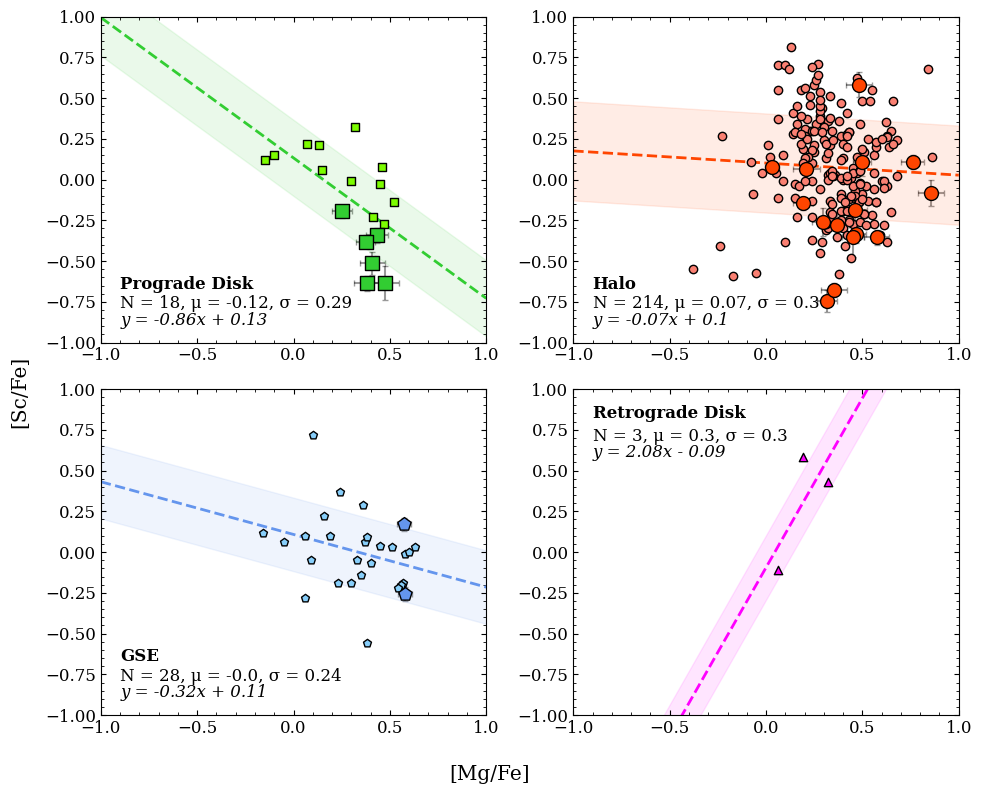

In [62]:
# Setting up figure
xlim = (-1.0, 1.0)
ylim = (-1.0, 1.0)

text_pos1 = (-0.9, -0.67)
text_pos2 = (-0.9, -0.79)
text_pos3 = (-0.9, -0.89)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Mg/Fe]')
fig.supylabel(f"[Sc/Fe]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---SUBPLOT 1: PROGRADE DISK--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_prodisk_df = pd.concat([xshooter_prodisk, lit_prodisk], ignore_index=True)

p_prodisk = np.polyfit(comb_prodisk_df['abund_mgfe'], comb_prodisk_df['abund_scfe'], deg=1)
fit_prodisk = np.poly1d(p_prodisk)
xline_prodisk = np.linspace(xlim[0], xlim[1], 100)
yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['abund_scfe'] - fit_prodisk(comb_prodisk_df['abund_mgfe'])
std_prodisk = np.std(res_prodisk)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['abund_mgfe'], lit_prodisk['abund_scfe'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['abund_mgfe'], xshooter_prodisk['abund_scfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['abund_mgfe'], xshooter_prodisk['abund_scfe'], 
            xerr=xshooter_prodisk['abund_mgfe_err'], yerr=xshooter_prodisk['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_scfe']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 2: HALO--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['abund_mgfe'], comb_halo_df['abund_scfe'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_scfe'] - fit_halo(comb_halo_df['abund_mgfe'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['abund_mgfe'], lit_halo['abund_scfe'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['abund_mgfe'], xshooter_halo['abund_scfe'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['abund_mgfe'], xshooter_halo['abund_scfe'], 
            xerr=xshooter_halo['abund_mgfe_err'], yerr=xshooter_halo['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_scfe']), 2)}, σ = {round(np.std(comb_halo_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
comb_gse_df = pd.concat([xshooter_gse, lit_gse], ignore_index=True)

p_gse = np.polyfit(comb_gse_df['abund_mgfe'], comb_gse_df['abund_scfe'], deg=1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['abund_scfe'] - fit_gse(comb_gse_df['abund_mgfe'])
std_gse = np.std(res_gse)

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['abund_mgfe'], lit_gse['abund_scfe'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['abund_mgfe'], xshooter_gse['abund_scfe'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['abund_mgfe'], xshooter_gse['abund_scfe'], 
            xerr=xshooter_gse['abund_mgfe_err'], yerr=xshooter_gse['abund_scfe_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse,
                    yline_gse + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_scfe']), 2)}, σ = {round(np.std(comb_gse_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
comb_retdisk_df = lit_retdisk

p_retdisk = np.polyfit(comb_retdisk_df['abund_mgfe'], comb_retdisk_df['abund_scfe'], deg=1)
fit_retdisk = np.poly1d(p_retdisk)
xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
yline_retdisk = fit_retdisk(xline_retdisk)
res_retdisk = comb_retdisk_df['abund_scfe'] - fit_retdisk(comb_retdisk_df['abund_mgfe'])
std_retdisk = np.std(res_retdisk)

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['abund_mgfe'], lit_retdisk['abund_scfe'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
ax.fill_between(xline_retdisk, 
                    yline_retdisk - std_retdisk,
                    yline_retdisk + std_retdisk,
                    color='fuchsia',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], 0.82, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], 0.68, f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_scfe']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_retdisk[0] > 0:
    ax.text(text_pos3[0], 0.58, f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], 0.58, f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_mgfe_scfe_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_mgfe_scfe_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

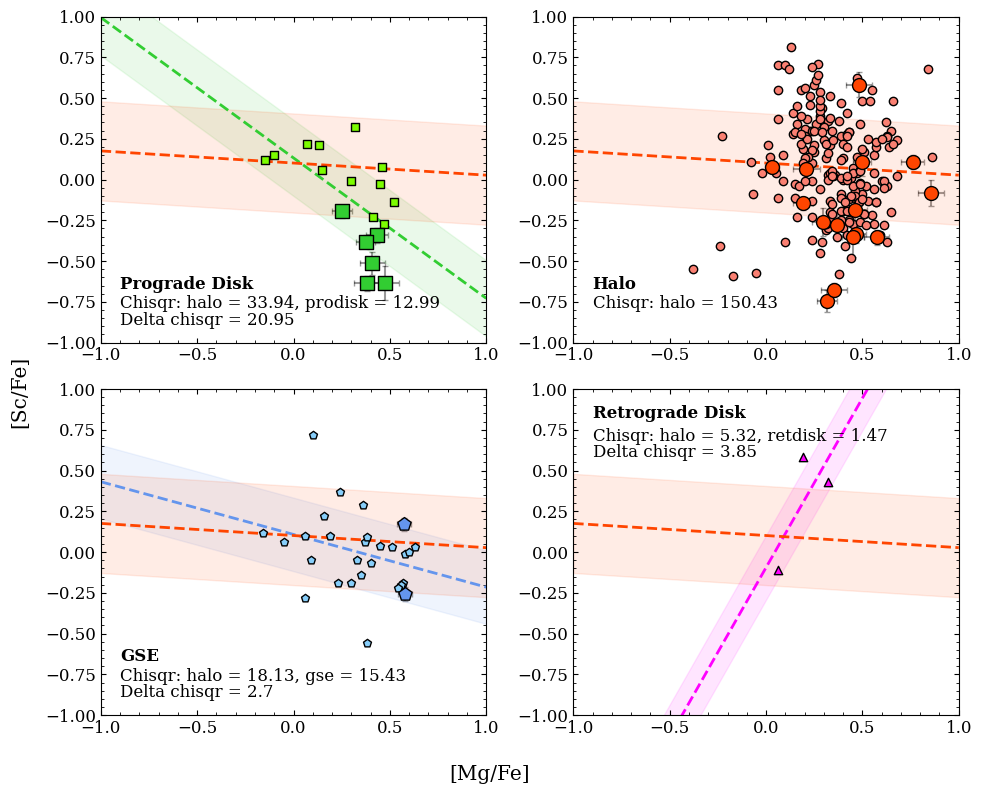

In [63]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Mg/Fe]')
fig.supylabel(f"[Sc/Fe]")
    
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['abund_mgfe'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_scfe_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['abund_scfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['abund_mgfe'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_scfe_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['abund_scfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(lit_prodisk['abund_mgfe'], lit_prodisk['abund_scfe'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['abund_mgfe'], xshooter_prodisk['abund_scfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['abund_mgfe'], xshooter_prodisk['abund_scfe'], 
            xerr=xshooter_prodisk['abund_mgfe_err'], yerr=xshooter_prodisk['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                    yline - std_prodisk,
                    yline + std_prodisk,
                    color='limegreen',
                    alpha=0.1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(prodisk_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['abund_mgfe'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_scfe_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['abund_scfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(lit_halo['abund_mgfe'], lit_halo['abund_scfe'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['abund_mgfe'], xshooter_halo['abund_scfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['abund_mgfe'], xshooter_halo['abund_scfe'], 
            xerr=xshooter_halo['abund_mgfe_err'], yerr=xshooter_halo['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['abund_mgfe'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_scfe_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['abund_scfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['abund_mgfe'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_scfe_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['abund_scfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr

# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(lit_gse['abund_mgfe'], lit_gse['abund_scfe'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['abund_mgfe'], xshooter_gse['abund_scfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['abund_mgfe'], xshooter_gse['abund_scfe'], 
            xerr=xshooter_gse['abund_mgfe_err'], yerr=xshooter_gse['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                    yline - std_gse,
                    yline + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(gse_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# --RETROGRADE DISK--- #
# Calculating the chi-square value for the retrograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
if len(comb_retdisk_df) > 0:
    retdisk_halofit_model = fit_halo(comb_retdisk_df['abund_mgfe'])
    retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_scfe_err'] ** 2 + std_retdisk ** 2)
    retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['abund_scfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
    n_params = 0
    retdisk_halofit_dof = len(comb_retdisk_df) - n_params
    retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
    retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)
    
    # Now doing this for the retrograde disk fit
    retdisk_origfit_model = fit_retdisk(comb_retdisk_df['abund_mgfe'])
    retdisk_origfit_error = np.sqrt(comb_retdisk_df['abund_scfe_err'] ** 2 + std_retdisk ** 2)
    retdisk_origfit_chisqr = np.sum(((comb_retdisk_df['abund_scfe'] - retdisk_origfit_model) ** 2) / (retdisk_origfit_error ** 2))
    n_params = 2
    retdisk_origfit_dof = len(comb_retdisk_df) - n_params # Number of parameters is the degree
    retdisk_origfit_redchisqr = retdisk_origfit_chisqr / retdisk_origfit_dof
    retdisk_origfit_pvalue = gammaincc(retdisk_origfit_dof / 2, retdisk_origfit_chisqr / 2)
    
    # Calculating the delta chisquare
    retdisk_delta_chisqr = retdisk_halofit_chisqr - retdisk_origfit_chisqr
    
    # Plotting the retrograde disk stars (literature)
    ax = axs[1,1]
    ax.scatter(lit_retdisk['abund_mgfe'], lit_retdisk['abund_scfe'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    # Plotting the retrograde disk fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_retdisk(xline)
    ax.plot(xline, yline, color='fuchsia', linestyle='--', linewidth=2, label='Retrograde Disk Fit')
    ax.fill_between(xline, 
                        yline - std_retdisk,
                        yline + std_retdisk,
                        color='fuchsia',
                        alpha=0.1)
    
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)
    
    # Making the text
    ax.text(text_pos1[0], 0.82, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], 0.68, f"Chisqr: halo = {round(retdisk_halofit_chisqr, 2)}, retdisk = {round(retdisk_origfit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], 0.58, f"Delta chisqr = {round(retdisk_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)
else:
    ax = axs[1,1]
    ax.text(text_pos1[0], 0.82, 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], 0.68, f"Chisqr: halo = N/A, retdisk = N/A", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], 0.58, f"Delta chisqr = N/A", fontsize=12, horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_mgfe_scfe_comparison_chisqr.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_mgfe_scfe_comparison_chisqr.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')


### Looking at Mn and Sc abundances

Getting the data sorted

In [10]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
mn_xshooter_abunds = all_xshooter_abunds[10]
sc_xshooter_abunds = all_xshooter_abunds[7]

# Calculating [Mn/Sc]
mnsc_xshooter_abunds = []
for i, row in mn_xshooter_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    feh = row['feh']
    feh_err = row['feh_err']
    mn_xfe = row['bestfit_abund_xfe']
    mn_xfe_err = row['bestfit_abund_comberr_xfe']
    mn_detect = row['detection']
    
    if mn_detect == 'Y':
        orb_row = comb_df[comb_df['star_id'] == star_id]
        if not orb_row.empty:
            # Retrieving the following:
            # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
            rmax = orb_row['rmax'].values[0]
            zmax = orb_row['zmax'].values[0]
            E = orb_row['E'].values[0]
            jp = orb_row['jp'].values[0]
            jr = orb_row['jr'].values[0]
            jz = orb_row['jz'].values[0]
            jtot = orb_row['jtot'].values[0]
            e = orb_row['e'].values[0]
            dist = orb_row['dist'].values[0]
            Vr = orb_row['Vr'].values[0]
            Vphi = orb_row['Vphi'].values[0]
            X = orb_row['X'].values[0]
            Y = orb_row['Y'].values[0]
        
        sc_row = sc_xshooter_abunds[sc_xshooter_abunds['star_id'] == star_id]
        
        
        if sc_row['detection'].values[0] == 'Y':
            sc_xfe = sc_row['bestfit_abund_xfe'].values[0]
            sc_xfe_err = sc_row['bestfit_abund_comberr_xfe'].values[0]
            
            mnsc_xfe = mn_xfe - sc_xfe
            mnsc_xfe_err = np.sqrt(sc_xfe_err**2 + mn_xfe_err**2)
            
            mnsc_xshooter_abunds.append({
                'star_id': star_id,
                'orbit': orbit,
                'feh': feh,
                'feh_err': feh_err,
                'abund_mnfe': mn_xfe,
                'abund_mnfe_err': mn_xfe_err,
                'abund_scfe': sc_xfe,
                'abund_scfe_err': sc_xfe_err,
                'abund_mnsc': mnsc_xfe,
                'abund_mnsc_err': mnsc_xfe_err,
                'rmax': rmax,
                'zmax': zmax,
                'E': E,
                'jp': jp,
                'jr': jr,
                'jz': jz,
                'jtot': jtot,
                'e': e,
                'dist': dist,
                'Vr': Vr,
                'Vphi': Vphi,
                'X': X,
                'Y': Y
            })
mnsc_xshooter_abunds = pd.DataFrame(mnsc_xshooter_abunds)


# For literature orbital groups
mn_lit_orbabunds = all_lit_orbabunds[10]
sc_lit_orbabunds = all_lit_orbabunds[7]

# Calculating [Mg/Mn]
mnsc_lit_orbabunds_list = []
for i, row in mn_lit_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    mn_abund = row['abund']
    mn_abund_err = row['abund_err']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    sc_row = sc_lit_orbabunds[sc_lit_orbabunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        sc_abund_err = sc_row['abund_err'].values[0]
        
        mnsc_abund = mn_abund - sc_abund
        mnsc_abund_err = np.sqrt(sc_abund_err**2 + mn_abund_err**2)
        
        mnsc_lit_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit': orbit,
            'abund_mnfe': mn_abund,
            'abund_mnfe_err': mn_abund_err,
            'abund_scfe': sc_abund,
            'abund_scfe_err': sc_abund_err,
            'abund_mnsc': mnsc_abund,
            'abund_mnsc_err': mnsc_abund_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
mnsc_lit_orbabunds = pd.DataFrame(mnsc_lit_orbabunds_list)

Separating by kinematic group

In [11]:
# X-Shooter
xshooter_prodisk = mnsc_xshooter_abunds[mnsc_xshooter_abunds['orbit'] == 'pro_disk']
xshooter_halo = mnsc_xshooter_abunds[mnsc_xshooter_abunds['orbit'] == 'halo']
xshooter_gse = mnsc_xshooter_abunds[mnsc_xshooter_abunds['orbit'] == 'gse']

# Literature
lit_prodisk = mnsc_lit_orbabunds[mnsc_lit_orbabunds['orbit'] == 'pro_disk']
lit_halo = mnsc_lit_orbabunds[mnsc_lit_orbabunds['orbit'] == 'halo']
lit_gse = mnsc_lit_orbabunds[mnsc_lit_orbabunds['orbit'] == 'gse']
lit_retdisk = mnsc_lit_orbabunds[mnsc_lit_orbabunds['orbit'] == 'ret_disk']

Loading in the GALAH DR4 [Mn/Sc] data

In [57]:
mnsc_galah_data = pd.read_csv(f"/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_mnsc_orbits.csv")
mnsc_galah_data['abund_mnsc'] = mnsc_galah_data['mn_fe'] - mnsc_galah_data['sc_fe']
mnsc_galah_data['abund_mnsc_err'] = np.sqrt(mnsc_galah_data['e_mn_fe']**2 + mnsc_galah_data['e_sc_fe']**2)
mnsc_galah_data = mnsc_galah_data.rename(columns={'fe_h': 'feh', 'sobject_id': 'star_id'})

mnsc_galah_prodisk = mnsc_galah_data[mnsc_galah_data['orbit'] == 'prodisk']
mnsc_galah_halo = mnsc_galah_data[mnsc_galah_data['orbit'] == 'halo']
mnsc_galah_gse = mnsc_galah_data[mnsc_galah_data['orbit'] == 'gse']
mnsc_galah_retdisk = mnsc_galah_data[mnsc_galah_data['orbit'] == 'retdisk']

#### [Fe/H] vs [Mn/Sc]

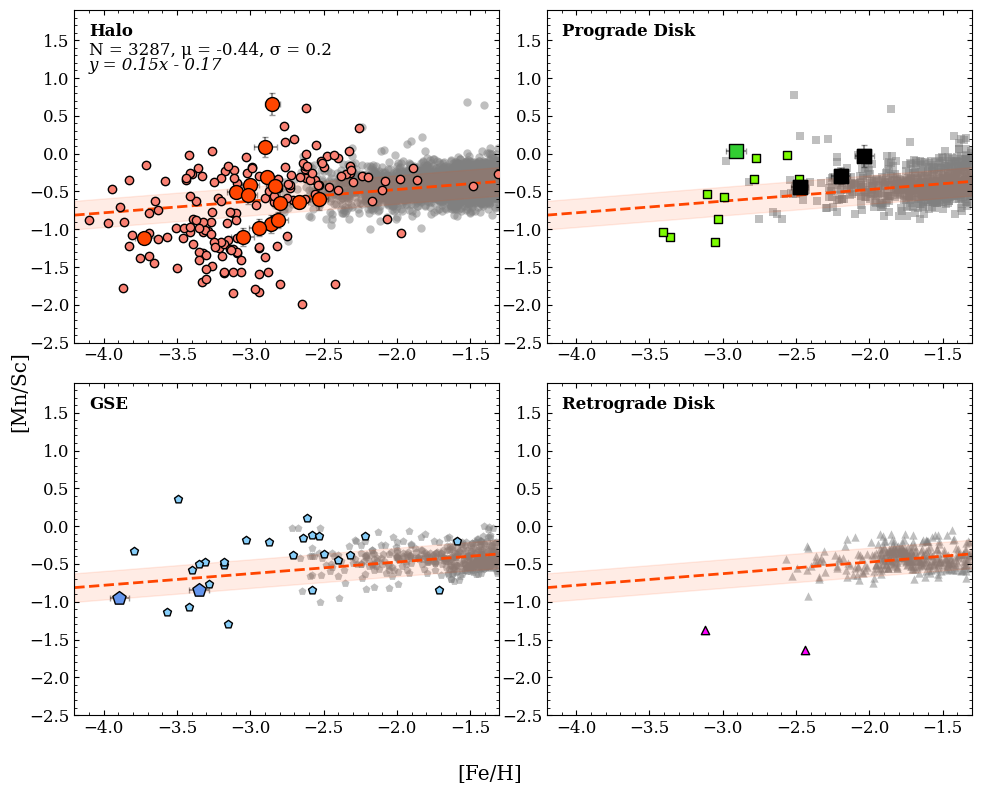

In [ ]:
# Setting up figure
xlim = (-4.2, -1.3)
ylim = (-2.5, 1.9)

text_pos1 = (-4.1, 1.55)
text_pos2 = (-4.1, 1.3)
text_pos3 = (-4.1, 1.1)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Mn/Sc]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# --SUBPLOT 1: HALO--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo, mnsc_galah_halo[['star_id', 'feh', 'abund_mnsc', 'abund_mnsc_err']]], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['abund_mnsc'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_mnsc'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['feh'], lit_halo['abund_mnsc'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_mnsc'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_mnsc'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_mnsc_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH halo stars
ax.scatter(mnsc_galah_halo['feh'], mnsc_galah_halo['abund_mnsc'], color='grey', marker='o', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_mnsc']), 2)}, σ = {round(np.std(comb_halo_df['abund_mnsc']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# ---SUBPLOT 2: PROGRADE DISK--- #
ax = axs[0,1]

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_mnsc'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_mnsc'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_mnsc'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_mnsc_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# For stars with weird [Mn/Fe] abundances, identify them as black squares
weird_mn_stars = ['ra_1648-0653_s38', 'ra_1639-2632_s419', 'ra_1659-2154_s261']
weird_mn_stars_df = xshooter_prodisk[xshooter_prodisk['star_id'].isin(weird_mn_stars)]
ax.scatter(weird_mn_stars_df['feh'], weird_mn_stars_df['abund_mnsc'], color='black', 
    label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)


# Plotting the GALAH prograde disk stars
ax.scatter(mnsc_galah_prodisk['feh'], mnsc_galah_prodisk['abund_mnsc'], color='grey', marker='s', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the halo polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_mnsc']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_mnsc']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_prodisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['feh'], lit_gse['abund_mnsc'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_mnsc'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_mnsc'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_mnsc_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH GSE stars
ax.scatter(mnsc_galah_gse['feh'], mnsc_galah_gse['abund_mnsc'], color='grey', marker='p', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the halo polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_mnsc']), 2)}, σ = {round(np.std(comb_gse_df['abund_mnsc']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_gse[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_mnsc'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the GALAH retrograde disk stars
ax.scatter(mnsc_galah_retdisk['feh'], mnsc_galah_retdisk['abund_mnsc'], color='grey', marker='^', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the halo polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_mnsc']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_mnsc']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_retdisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mnsc_compare.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr/mnsc_compare.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

### Looking at Mg and Al abundances

Getting the data sorted

In [78]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
mg_xshooter_abunds = all_xshooter_abunds[3]
al_xshooter_abunds = all_xshooter_abunds[4]

# Calculating [Sc/Mg]
almg_xshooter_abunds = []
for i, row in mg_xshooter_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    feh = row['feh']
    feh_err = row['feh_err']
    mg_xfe = row['bestfit_abund_xfe']
    mg_xfe_err = row['bestfit_abund_comberr_xfe']
    
    orb_row = comb_df[comb_df['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['Vr'].values[0]
        Vphi = orb_row['Vphi'].values[0]
        X = orb_row['X'].values[0]
        Y = orb_row['Y'].values[0]
    
    al_row = al_xshooter_abunds[al_xshooter_abunds['star_id'] == star_id]
    
    
    if al_row['detection'].values[0] == 'Y':
        al_xfe = al_row['bestfit_abund_xfe'].values[0]
        al_xfe_err = al_row['bestfit_abund_comberr_xfe'].values[0]
        
        almg_xfe = al_xfe - mg_xfe
        almg_xfe_err = np.sqrt(al_xfe_err**2 + mg_xfe_err**2)
        
        almg_xshooter_abunds.append({
            'star_id': star_id,
            'orbit': orbit,
            'feh': feh,
            'feh_err': feh_err,
            'abund_mgfe': mg_xfe,
            'abund_mgfe_err': mg_xfe_err,
            'abund_alfe': al_xfe,
            'abund_alfe_err': al_xfe_err,
            'abund_almg': almg_xfe,
            'abund_almg_err': almg_xfe_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
almg_xshooter_abunds = pd.DataFrame(almg_xshooter_abunds)

# For literature
mg_lit_abunds = all_lit_abunds[3]
al_lit_abunds = all_lit_abunds[4]

# Calculating [al/Mg]
almg_lit_abunds_list = []
for i, row in mg_lit_abunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    mg_abund = row['abund']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    al_row = al_lit_abunds[al_lit_abunds['star_id'] == star_id]
    if not al_row.empty:
        al_abund = al_row['abund'].values[0]
        
        almg_abund = al_abund - mg_abund
        
        almg_lit_abunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'abund_mgfe': mg_abund,
            'abund_alfe': al_abund,
            'abund_almg': almg_abund,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
almg_lit_abunds = pd.DataFrame(almg_lit_abunds_list)

# comb_df = pd.merge(al_lit_abunds, scal_lit_abunds, on=['star_id', 'feh'])
# comb_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)


# For literature orbital groups
mg_lit_orbabunds = all_lit_orbabunds[3]
al_lit_orbabunds = all_lit_orbabunds[4]

# Calculating [Mg/Mn]
almg_lit_orbabunds_list = []
for i, row in mg_lit_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    mg_abund = row['abund']
    mg_abund_err = row['abund_err']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    al_row = al_lit_orbabunds[al_lit_orbabunds['star_id'] == star_id]
    if not al_row.empty:
        al_abund = al_row['abund'].values[0]
        al_abund_err = al_row['abund_err'].values[0]
        
        almg_abund = al_abund - mg_abund
        almg_abund_err = np.sqrt(al_abund_err**2 + mg_abund_err**2)
        
        almg_lit_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit': orbit,
            'abund_mgfe': mg_abund,
            'abund_mgfe_err': mg_abund_err,
            'abund_alfe': al_abund,
            'abund_alfe_err': al_abund_err,
            'abund_almg': almg_abund,
            'abund_almg_err': almg_abund_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
almg_lit_orbabunds = pd.DataFrame(almg_lit_orbabunds_list)

Separating by kinematic group

In [79]:
# X-Shooter
xshooter_prodisk = almg_xshooter_abunds[almg_xshooter_abunds['orbit'] == 'pro_disk']
xshooter_halo = almg_xshooter_abunds[almg_xshooter_abunds['orbit'] == 'halo']
xshooter_gse = almg_xshooter_abunds[almg_xshooter_abunds['orbit'] == 'gse']

# Literature
lit_prodisk = almg_lit_orbabunds[almg_lit_orbabunds['orbit'] == 'pro_disk']
lit_halo = almg_lit_orbabunds[almg_lit_orbabunds['orbit'] == 'halo']
lit_gse = almg_lit_orbabunds[almg_lit_orbabunds['orbit'] == 'gse']
lit_retdisk = almg_lit_orbabunds[almg_lit_orbabunds['orbit'] == 'ret_disk']


Loading in the GALAH DR4 data

In [81]:
almg_galah_data = pd.read_csv(f"/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_almg_orbits.csv")
almg_galah_data['abund_almg'] = almg_galah_data['mn_fe'] - almg_galah_data['sc_fe']
almg_galah_data['abund_almg_err'] = np.sqrt(almg_galah_data['e_mn_fe']**2 + almg_galah_data['e_sc_fe']**2)
almg_galah_data = almg_galah_data.rename(columns={'fe_h': 'feh', 'sobject_id': 'star_id'})

almg_galah_prodisk = almg_galah_data[almg_galah_data['orbit'] == 'prodisk']
almg_galah_halo = almg_galah_data[almg_galah_data['orbit'] == 'halo']
almg_galah_gse = almg_galah_data[almg_galah_data['orbit'] == 'gse']
almg_galah_retdisk = almg_galah_data[almg_galah_data['orbit'] == 'retdisk']

#### [Fe/H] vs [Al/Mg]

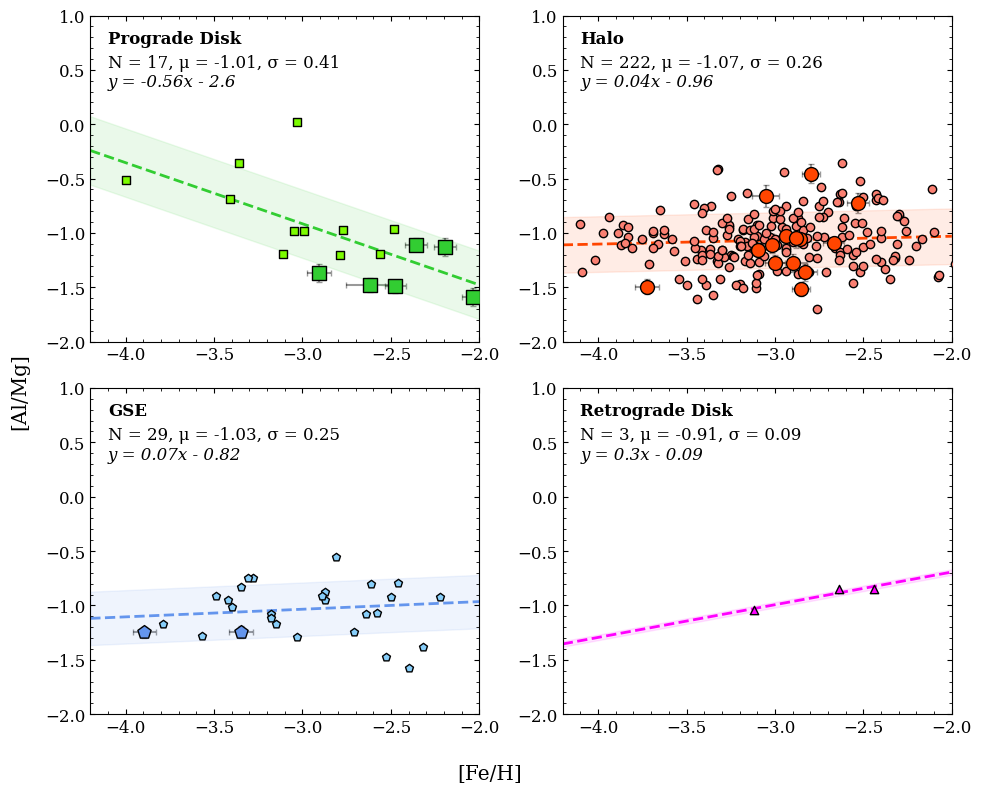

In [21]:
# Setting up figure
xlim = (-4.2, -2.0)
ylim = (-2.0, 1.0)

text_pos1 = (-4.1, 0.75)
text_pos2 = (-4.1, 0.53)
text_pos3 = (-4.1, 0.35)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Al/Mg]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---SUBPLOT 1: PROGRADE DISK--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_prodisk_df = pd.concat([xshooter_prodisk, lit_prodisk], ignore_index=True)

p_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['abund_almg'], deg=1)
fit_prodisk = np.poly1d(p_prodisk)
xline_prodisk = np.linspace(xlim[0], xlim[1], 100)
yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['abund_almg'] - fit_prodisk(comb_prodisk_df['feh'])
std_prodisk = np.std(res_prodisk)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_almg'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_almg']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_almg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 2: HALO--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['abund_almg'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_almg'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['feh'], lit_halo['abund_almg'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_almg'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_almg'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_almg']), 2)}, σ = {round(np.std(comb_halo_df['abund_almg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
comb_gse_df = pd.concat([xshooter_gse, lit_gse], ignore_index=True)

p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['abund_almg'], deg=1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['abund_almg'] - fit_gse(comb_gse_df['feh'])
std_gse = np.std(res_gse)

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['feh'], lit_gse['abund_almg'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_almg'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_almg'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_almg_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse,
                    yline_gse + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_almg']), 2)}, σ = {round(np.std(comb_gse_df['abund_almg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
comb_retdisk_df = lit_retdisk

p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['abund_almg'], deg=1)
fit_retdisk = np.poly1d(p_retdisk)
xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
yline_retdisk = fit_retdisk(xline_retdisk)
res_retdisk = comb_retdisk_df['abund_almg'] - fit_retdisk(comb_retdisk_df['feh'])
std_retdisk = np.std(res_retdisk)

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_almg'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
ax.fill_between(xline_retdisk, 
                    yline_retdisk - std_retdisk,
                    yline_retdisk + std_retdisk,
                    color='fuchsia',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_almg']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_almg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_retdisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_almg_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_almg_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

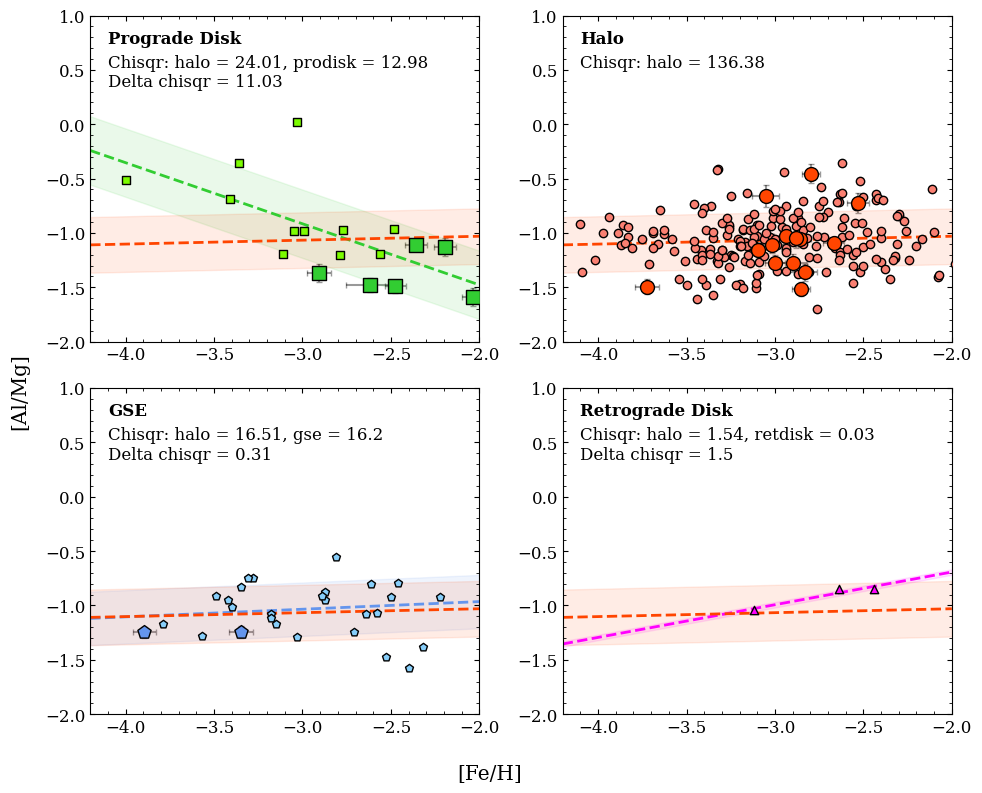

In [24]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Al/Mg]")
    
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_almg_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['abund_almg'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_almg_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['abund_almg'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_almg'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                    yline - std_prodisk,
                    yline + std_prodisk,
                    color='limegreen',
                    alpha=0.1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(prodisk_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_almg_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['abund_almg'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(lit_halo['feh'], lit_halo['abund_almg'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_almg'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_almg'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_almg_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['abund_almg'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['feh'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_almg_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['abund_almg'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr

# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(lit_gse['feh'], lit_gse['abund_almg'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_almg'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_almg'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                    yline - std_gse,
                    yline + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                    yline - std_halo,
                    yline + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(gse_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)


# --RETROGRADE DISK--- #
# Calculating the chi-square value for the retrograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
if len(comb_retdisk_df) > 0:
    retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
    retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_almg_err'] ** 2 + std_retdisk ** 2)
    retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['abund_almg'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
    n_params = 0
    retdisk_halofit_dof = len(comb_retdisk_df) - n_params
    retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
    retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)
    
    # Now doing this for the retrograde disk fit
    retdisk_origfit_model = fit_retdisk(comb_retdisk_df['feh'])
    retdisk_origfit_error = np.sqrt(comb_retdisk_df['abund_almg_err'] ** 2 + std_retdisk ** 2)
    retdisk_origfit_chisqr = np.sum(((comb_retdisk_df['abund_almg'] - retdisk_origfit_model) ** 2) / (retdisk_origfit_error ** 2))
    n_params = 2
    retdisk_origfit_dof = len(comb_retdisk_df) - n_params # Number of parameters is the degree
    retdisk_origfit_redchisqr = retdisk_origfit_chisqr / retdisk_origfit_dof
    retdisk_origfit_pvalue = gammaincc(retdisk_origfit_dof / 2, retdisk_origfit_chisqr / 2)
    
    # Calculating the delta chisquare
    retdisk_delta_chisqr = retdisk_halofit_chisqr - retdisk_origfit_chisqr
    
    # Plotting the retrograde disk stars (literature)
    ax = axs[1,1]
    ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_almg'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    # Plotting the retrograde disk fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_retdisk(xline)
    ax.plot(xline, yline, color='fuchsia', linestyle='--', linewidth=2, label='Retrograde Disk Fit')
    ax.fill_between(xline, 
                        yline - std_retdisk,
                        yline + std_retdisk,
                        color='fuchsia',
                        alpha=0.1)
    
    # Plotting the halo fit
    xline = np.linspace(xlim[0], xlim[1], 100)
    yline = fit_halo(xline)
    ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
    ax.fill_between(xline, 
                        yline - std_halo,
                        yline + std_halo,
                        color='orangered',
                        alpha=0.1)
    
    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(retdisk_halofit_chisqr, 2)}, retdisk = {round(retdisk_origfit_chisqr, 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(retdisk_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)
else:
    ax = axs[1,1]
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = N/A, retdisk = N/A", 
            fontsize=12, horizontalalignment=text_hozalign)
    ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = N/A", fontsize=12, horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_almg_comparison_chisqr.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_almg_comparison_chisqr.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')


With GALAH DR4 data

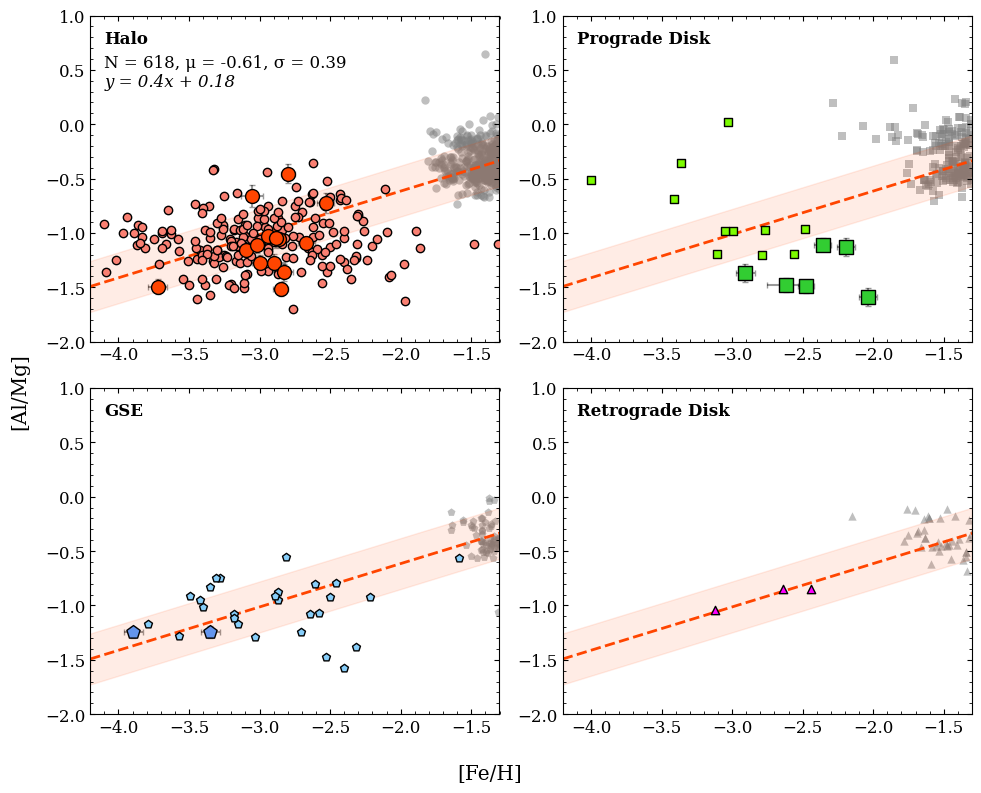

In [84]:
# Setting up figure
xlim = (-4.2, -1.3)
ylim = (-2.0, 1.0)

text_pos1 = (-4.1, 0.75)
text_pos2 = (-4.1, 0.53)
text_pos3 = (-4.1, 0.35)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Al/Mg]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# --SUBPLOT 1: HALO--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo, almg_galah_halo[['star_id', 'feh', 'abund_almg', 'abund_almg_err']]], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['abund_almg'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_almg'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['feh'], lit_halo['abund_almg'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_almg'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_almg'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH halo stars
ax.scatter(almg_galah_halo['feh'], almg_galah_halo['abund_almg'], color='grey', marker='o', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_almg']), 2)}, σ = {round(np.std(comb_halo_df['abund_almg']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# ---SUBPLOT 2: PROGRADE DISK--- #
ax = axs[0,1]

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_almg'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_almg'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_almg_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH prograde disk stars
ax.scatter(almg_galah_prodisk['feh'], almg_galah_prodisk['abund_almg'], color='grey', marker='s', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_almg']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_almg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_prodisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)


# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['feh'], lit_gse['abund_almg'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_almg'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_almg'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_almg_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the GALAH GSE stars
ax.scatter(almg_galah_gse['feh'], almg_galah_gse['abund_almg'], color='grey', marker='p', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_almg']), 2)}, σ = {round(np.std(comb_gse_df['abund_almg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_gse[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_almg'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the GALAH retrograde disk stars
ax.scatter(almg_galah_retdisk['feh'], almg_galah_retdisk['abund_almg'], color='grey', marker='^', edgecolor='black',
                   zorder=0, linewidths=0, alpha=0.5)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
# ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_almg']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_almg']), 2)}", 
#         fontsize=12, horizontalalignment=text_hozalign)
# if fit_retdisk[0] > 0:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
# else:
#     ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/galah_v2/almg_compare.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/galah_v2/almg_compare.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

### Looking at Al and Sc abundances

Getting the data sorted

In [ ]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
al_xshooter_abunds = all_xshooter_abunds[4]
sc_xshooter_abunds = all_xshooter_abunds[7]

# Calculating [Sc/Al]
scal_xshooter_abunds = []
for i, row in al_xshooter_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    feh = row['feh']
    feh_err = row['feh_err']
    al_xfe = row['bestfit_abund_xfe']
    al_xfe_err = row['bestfit_abund_comberr_xfe']
    
    orb_row = comb_df[comb_df['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['Vr'].values[0]
        Vphi = orb_row['Vphi'].values[0]
        X = orb_row['X'].values[0]
        Y = orb_row['Y'].values[0]
    
    sc_row = sc_xshooter_abunds[sc_xshooter_abunds['star_id'] == star_id]
    
    
    if sc_row['detection'].values[0] == 'Y':
        sc_xfe = sc_row['bestfit_abund_xfe'].values[0]
        sc_xfe_err = sc_row['bestfit_abund_comberr_xfe'].values[0]
        
        scal_xfe = sc_xfe - al_xfe
        scal_xfe_err = np.sqrt(sc_xfe_err**2 + al_xfe_err**2)
        
        scal_xshooter_abunds.append({
            'star_id': star_id,
            'orbit': orbit,
            'feh': feh,
            'feh_err': feh_err,
            'abund_alfe': al_xfe,
            'abund_alfe_err': al_xfe_err,
            'abund_scfe': sc_xfe,
            'abund_scfe_err': sc_xfe_err,
            'abund_scal': scal_xfe,
            'abund_scal_err': scal_xfe_err,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
scal_xshooter_abunds = pd.DataFrame(scal_xshooter_abunds)

# For literature
al_lit_abunds = all_lit_abunds[4]
sc_lit_abunds = all_lit_abunds[7]

# Calculating [Sc/Al]
scal_lit_abunds_list = []
for i, row in al_lit_abunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    al_abund = row['abund']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    sc_row = sc_lit_abunds[sc_lit_abunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        
        scal_abund = sc_abund - al_abund
        
        scal_lit_abunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'abund_alfe': al_abund,
            'abund_scfe': sc_abund,
            'abund_scal': scal_abund,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
scal_lit_abunds = pd.DataFrame(scal_lit_abunds_list)

# comb_df = pd.merge(al_lit_abunds, scal_lit_abunds, on=['star_id', 'feh'])
# comb_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)


# For literature orbital groups
al_lit_orbabunds = all_lit_orbabunds[4]
sc_lit_orbabunds = all_lit_orbabunds[7]

# Calculating [Mg/Mn]
scal_lit_orbabunds_list = []
for i, row in al_lit_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    al_abund = row['abund']
    
    orb_row = lit_combined[lit_combined['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        rmax = orb_row['rmax'].values[0]
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
        Vr = orb_row['vR'].values[0]
        Vphi = orb_row['vphi'].values[0]
        X = orb_row['xpos'].values[0]
        Y = orb_row['ypos'].values[0]
    
    sc_row = sc_lit_orbabunds[sc_lit_orbabunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        
        scal_abund = sc_abund - al_abund
        
        scal_lit_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit': orbit,
            'abund_alfe': al_abund,
            'abund_scfe': sc_abund,
            'abund_scal': scal_abund,
            'rmax': rmax,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
            'Vr': Vr,
            'Vphi': Vphi,
            'X': X,
            'Y': Y
        })
        
scal_lit_orbabunds = pd.DataFrame(scal_lit_orbabunds_list)


,star_id,feh,orbit,abund_mgfe,abund_scfe,abund_scmg,rmax,zmax,E,jp,jr,jz,jtot,e,dist,Vr,Vphi,X,Y
0,HE 0102-1213,-3.28,gse,-0.69,0.10,0.79,4.063906,43.201453,1583.358139,-71.812252,2311.843611,1652.472585,2842.612096,0.827774,1.255206,-304.096908,-1.006331,8.444094,0.233958
1,53327-2044-515,-4.00,pro_disk,-0.19,0.32,0.51,1.724765,1.755441,-48286.687478,684.633842,576.488135,33.729302,895.656035,0.737729,0.940910,-142.117574,8.916622,8.748194,0.506281
2,HE 0231-6025,-3.10,halo,-0.64,0.27,0.91,3.218046,7.417916,-52211.778900,-474.603158,180.657225,589.768810,778.275298,0.459533,1.195857,-55.535980,-7.273637,8.046947,-0.705018
3,HE 0253-1331,-3.01,halo,-0.61,0.58,1.19,0.591457,4.331293,-54864.817216,81.671200,688.767517,93.336776,699.844719,0.888734,2.199441,-72.010020,0.934934,9.340202,-0.279238
4,54142-2667-094,-2.96,halo,-0.72,0.30,1.02,2.812805,8.269945,-48021.925225,497.906984,295.658228,523.461343,780.600366,0.567211,2.364915,3.806107,5.077056,9.826006,-1.242327
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223,J224145.62-064643.0,-3.19,halo,-0.70,0.27,0.97,8.354303,16.644608,-20148.545575,-802.043545,307.002879,1037.289721,1346.660529,0.547180,15.665713,-86.304988,-5.167000,3.496375,8.349136
224,J230525.31-213807.0,-3.35,halo,-1.07,0.11,1.18,0.655420,4.798721,-58047.249975,158.474035,530.576736,178.389902,581.763397,0.863080,3.483409,-117.268660,3.094299,7.095932,0.931983
225,J230702.22-693718.5,-2.89,halo,-0.75,0.37,1.12,20.070526,387.618695,81050.904535,-421.262383,237.457551,1253.862221,1343.881897,0.932173,22.774664,396.740294,9.361148,-3.323902,-11.396652
226,J232121.57-160505.4,-3.03,pro_disk,-0.13,0.12,0.25,3.792694,2.673879,-33538.215933,1316.036011,511.331889,89.566476,1414.720198,0.602475,2.198561,186.904820,21.920773,7.714033,0.733210


Separating by kinematic group

In [13]:
# X-Shooter
xshooter_prodisk = scal_xshooter_abunds[scal_xshooter_abunds['orbit'] == 'pro_disk']
xshooter_halo = scal_xshooter_abunds[scal_xshooter_abunds['orbit'] == 'halo']
xshooter_gse = scal_xshooter_abunds[scal_xshooter_abunds['orbit'] == 'gse']

# Literature
lit_prodisk = scal_lit_orbabunds[scal_lit_orbabunds['orbit'] == 'pro_disk']
lit_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
lit_halo = scal_lit_orbabunds[scal_lit_orbabunds['orbit'] == 'halo']
lit_halo.drop_duplicates(subset=['star_id'], inplace=True)
lit_gse = scal_lit_orbabunds[scal_lit_orbabunds['orbit'] == 'gse']
lit_gse.drop_duplicates(subset=['star_id'], inplace=True)
lit_retdisk = scal_lit_orbabunds[scal_lit_orbabunds['orbit'] == 'ret_disk']
lit_retdisk.drop_duplicates(subset=['star_id'], inplace=True)

/tmp/ipykernel_754469/3849641994.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_754469/3849641994.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_halo.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_754469/3849641994.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_gse.drop_duplicates(subset=['star_id'], inplace=True)
/tm

#### [Fe/H] vs [Sc/Al]

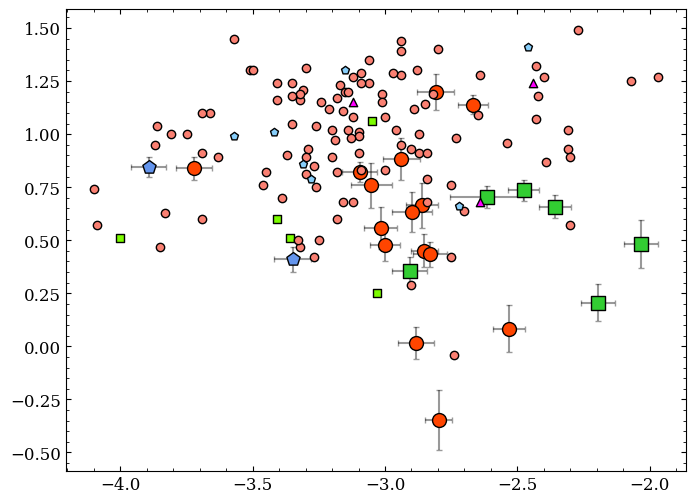

In [60]:
plt.figure(figsize=(8,6))

# Plotting X-Shooter data
plt.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_scal'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_scal'], 
             xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_scal_err'], 
             fmt='s', color='black', zorder=1, alpha=0.4)
plt.scatter(xshooter_halo['feh'], xshooter_halo['abund_scal'], color='orangered', marker='o',
            s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_halo['feh'], xshooter_halo['abund_scal'], 
             xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_scal_err'], 
             fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(xshooter_gse['feh'], xshooter_gse['abund_scal'], color='cornflowerblue', marker='p',
            s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_gse['feh'], xshooter_gse['abund_scal'], 
             xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_scal_err'],
                fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting literature data
plt.scatter(lit_prodisk['feh'], lit_prodisk['abund_scal'], color='lawngreen', marker='s', edgecolor='black', zorder=10, 
            linewidths=1, label='Prograde Disk')
plt.scatter(lit_halo['feh'], lit_halo['abund_scal'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1, label='Halo')
plt.scatter(lit_gse['feh'], lit_gse['abund_scal'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1, label='GSE')
plt.scatter(lit_retdisk['feh'], lit_retdisk['abund_scal'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')



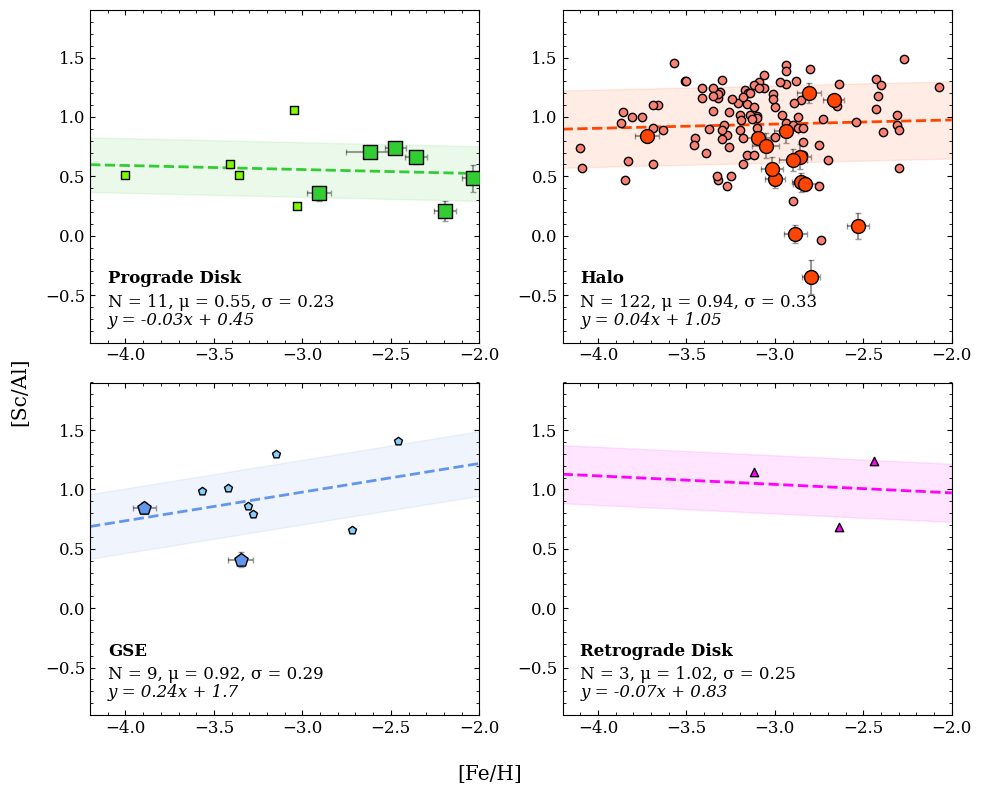

In [54]:
# Setting up figure
xlim = (-4.2, -2.0)
ylim = (-0.9, 1.9)

text_pos1 = (-4.1, -0.4)
text_pos2 = (-4.1, -0.6)
text_pos3 = (-4.1, -0.75)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Sc/Al]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---SUBPLOT 1: PROGRADE DISK--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_prodisk_df = pd.concat([xshooter_prodisk, lit_prodisk], ignore_index=True)

p_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['abund_scal'], deg=1)
fit_prodisk = np.poly1d(p_prodisk)
xline_prodisk = np.linspace(xlim[0], xlim[1], 100)
yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['abund_scal'] - fit_prodisk(comb_prodisk_df['feh'])
std_prodisk = np.std(res_prodisk)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['feh'], lit_prodisk['abund_scal'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['feh'], xshooter_prodisk['abund_scal'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['feh'], xshooter_prodisk['abund_scal'], 
            xerr=xshooter_prodisk['feh_err'], yerr=xshooter_prodisk['abund_scal_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_scal']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_scal']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 2: HALO--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['abund_scal'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_scal'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['feh'], lit_halo['abund_scal'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['feh'], xshooter_halo['abund_scal'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['feh'], xshooter_halo['abund_scal'], 
            xerr=xshooter_halo['feh_err'], yerr=xshooter_halo['abund_scal_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_scal']), 2)}, σ = {round(np.std(comb_halo_df['abund_scal']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
comb_gse_df = pd.concat([xshooter_gse, lit_gse], ignore_index=True)

p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['abund_scal'], deg=1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['abund_scal'] - fit_gse(comb_gse_df['feh'])
std_gse = np.std(res_gse)

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['feh'], lit_gse['abund_scal'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['feh'], xshooter_gse['abund_scal'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['feh'], xshooter_gse['abund_scal'], 
            xerr=xshooter_gse['feh_err'], yerr=xshooter_gse['abund_scal_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse,
                    yline_gse + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_scal']), 2)}, σ = {round(np.std(comb_gse_df['abund_scal']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
comb_retdisk_df = lit_retdisk

p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['abund_scal'], deg=1)
fit_retdisk = np.poly1d(p_retdisk)
xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
yline_retdisk = fit_retdisk(xline_retdisk)
res_retdisk = comb_retdisk_df['abund_scal'] - fit_retdisk(comb_retdisk_df['feh'])
std_retdisk = np.std(res_retdisk)

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['feh'], lit_retdisk['abund_scal'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
ax.fill_between(xline_retdisk, 
                    yline_retdisk - std_retdisk,
                    yline_retdisk + std_retdisk,
                    color='fuchsia',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_scal']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_scal']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_retdisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_scal_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/feh_scal_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

Doing this for Sculptor

/tmp/ipykernel_692493/2773554397.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sculp_scal['scal'] = sculp_scal['scfe'] - sculp_scal['alfe']


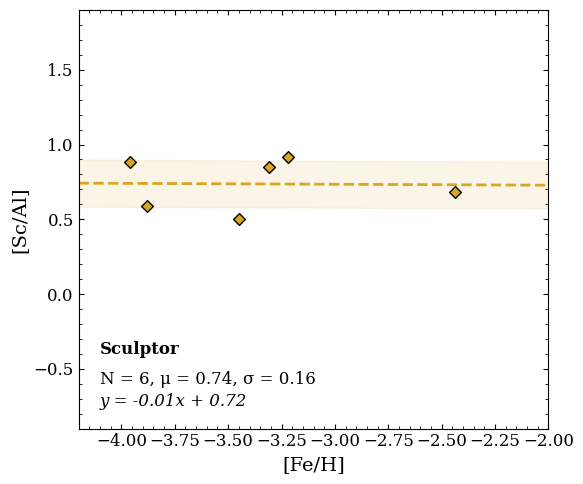

In [56]:
sculp_scal = sculp_df.dropna()
sculp_scal['scal'] = sculp_scal['scfe'] - sculp_scal['alfe']

xlim = (-4.2, -2.0)
ylim = (-0.9, 1.9)
text_pos1 = (-4.1, -0.4)
text_pos2 = (-4.1, -0.6)
text_pos3 = (-4.1, -0.75)
text_hozalign = 'left'

# Fitting polynomial
p_sculp = np.polyfit(sculp_scal['feh'], sculp_scal['scal'], deg=1)
fit_sculp = np.poly1d(p_sculp)
xline_sculp = np.linspace(xlim[0], xlim[1], 100)
yline_sculp = fit_sculp(xline_sculp)
res_sculp = sculp_scal['scal'] - fit_sculp(sculp_scal['feh'])
std_sculp = np.std(res_sculp)

plt.figure(figsize=[6,5])
plt.scatter(sculp_scal['feh'], sculp_scal['scal'], color='goldenrod', marker='D', 
                edgecolor='black', zorder=10, linewidths=1)
plt.plot(xline_sculp, yline_sculp, color='goldenrod', linestyle='--', linewidth=2)
plt.fill_between(xline_sculp, 
                    yline_sculp - std_sculp,
                    yline_sculp + std_sculp,
                    color='goldenrod',
                    alpha=0.1)



plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_scal)}, μ = {round(np.mean(sculp_scal['scal']), 2)}, σ = {round(np.std(sculp_scal['scal']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_sculp[0] > 0:
    plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x + {round(p_sculp[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x - {abs(round(p_sculp[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel('[Fe/H]')
plt.ylabel('[Sc/Al]')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sculptor_feh_scal_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sculptor_feh_scal_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

#### [Al/Fe] vs [Sc/Fe]

In [91]:
comb_halo_df

,star_id,orbit,feh,feh_err,abund_alfe,abund_alfe_err,abund_scfe,abund_scfe_err,abund_scal,abund_scal_err,...,xhelio,xhelio_err,yhelio,yhelio_err,zhelio,zhelio_err,teff,logg,source_id,catalog
0,ra_1604-2712_s24,halo,-2.530153,0.060214,-0.268448,0.064313,-0.185999,0.090635,0.082449,0.111134,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ra_1604-2712_s292,halo,-3.095019,0.066494,-0.967741,0.029978,-0.146403,0.038101,0.821338,0.048481,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ra_1624-2150_s278,halo,-2.667603,0.058084,-1.061190,0.027404,0.077999,0.037467,1.139188,0.046420,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ra_1656-1433_s143,halo,-2.858919,0.060508,-0.555566,0.062233,0.109177,0.086948,0.664743,0.106924,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ra_1658-2454_s22,halo,-2.897767,0.076858,-0.910548,0.052289,-0.277062,0.076597,0.633486,0.092742,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271,J215842.28-202915.8,halo,-3.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.736873,0.211806,3.208844,0.037384,-7.059286,0.137291,4975.0,1.92,6.823220e+18,yong2021
272,J222323.36-482451.3,halo,-2.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.388336,0.216835,-0.144691,0.039777,-0.828815,0.130454,5250.0,2.70,6.517965e+18,yong2021
273,J224145.62-064643.0,halo,-3.190000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.503625,0.218535,8.349136,0.042025,-12.782991,0.140776,4800.0,1.46,2.623364e+18,yong2021
274,J230525.31-213807.0,halo,-3.350000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.904068,0.181503,0.931983,0.042025,-3.135718,0.137609,5100.0,2.26,2.398203e+18,yong2021


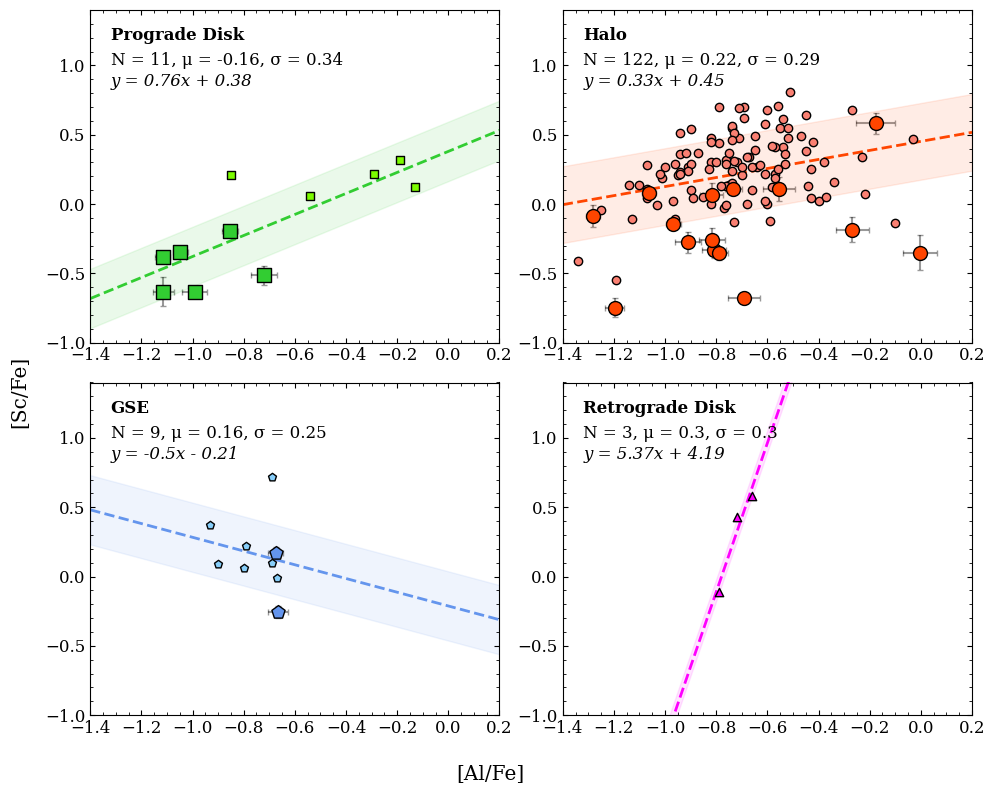

In [14]:
# Setting up figure
xlim = (-1.4, 0.2)
ylim = (-1., 1.4)

text_pos1 = (-1.32, 1.18)
text_pos2 = (-1.32, 1.0)
text_pos3 = (-1.32, 0.85)
text_hozalign = 'left'

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Al/Fe]')
fig.supylabel(f"[Sc/Fe]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# ---SUBPLOT 1: PROGRADE DISK--- #
ax = axs[0,0]

# Fitting polynomial (both literature and x-shooter)
comb_prodisk_df = pd.concat([xshooter_prodisk, lit_prodisk], ignore_index=True)

p_prodisk = np.polyfit(comb_prodisk_df['abund_alfe'], comb_prodisk_df['abund_scfe'], deg=1)
fit_prodisk = np.poly1d(p_prodisk)
xline_prodisk = np.linspace(xlim[0], xlim[1], 100)
yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['abund_scfe'] - fit_prodisk(comb_prodisk_df['abund_alfe'])
std_prodisk = np.std(res_prodisk)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_prodisk['abund_alfe'], lit_prodisk['abund_scfe'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_prodisk['abund_alfe'], xshooter_prodisk['abund_scfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_prodisk['abund_alfe'], xshooter_prodisk['abund_scfe'], 
            xerr=xshooter_prodisk['abund_alfe_err'], yerr=xshooter_prodisk['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['abund_scfe']), 2)}, σ = {round(np.std(comb_prodisk_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 2: HALO--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
comb_halo_df = pd.concat([xshooter_halo, lit_halo], ignore_index=True)

p_halo = np.polyfit(comb_halo_df['abund_alfe'], comb_halo_df['abund_scfe'], deg=1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['abund_scfe'] - fit_halo(comb_halo_df['abund_alfe'])
std_halo = np.std(res_halo)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_halo['abund_alfe'], lit_halo['abund_scfe'], color='salmon', marker='o', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_halo['abund_alfe'], xshooter_halo['abund_scfe'], color='orangered', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_halo['abund_alfe'], xshooter_halo['abund_scfe'], 
            xerr=xshooter_halo['abund_alfe_err'], yerr=xshooter_halo['abund_scfe_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo,
                    yline_halo + std_halo,
                    color='orangered',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['abund_scfe']), 2)}, σ = {round(np.std(comb_halo_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
comb_gse_df = pd.concat([xshooter_gse, lit_gse], ignore_index=True)

p_gse = np.polyfit(comb_gse_df['abund_alfe'], comb_gse_df['abund_scfe'], deg=1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['abund_scfe'] - fit_gse(comb_gse_df['abund_alfe'])
std_gse = np.std(res_gse)

# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_gse['abund_alfe'], lit_gse['abund_scfe'], color='lightskyblue', marker='p', edgecolor='black', zorder=10, linewidths=1)
ax.scatter(xshooter_gse['abund_alfe'], xshooter_gse['abund_scfe'], color='cornflowerblue', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(xshooter_gse['abund_alfe'], xshooter_gse['abund_scfe'], 
            xerr=xshooter_gse['abund_alfe_err'], yerr=xshooter_gse['abund_scfe_err'], 
            fmt='p', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse,
                    yline_gse + std_gse,
                    color='cornflowerblue',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['abund_scfe']), 2)}, σ = {round(np.std(comb_gse_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)



# --SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
comb_retdisk_df = lit_retdisk

p_retdisk = np.polyfit(comb_retdisk_df['abund_alfe'], comb_retdisk_df['abund_scfe'], deg=1)
fit_retdisk = np.poly1d(p_retdisk)
xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
yline_retdisk = fit_retdisk(xline_retdisk)
res_retdisk = comb_retdisk_df['abund_scfe'] - fit_retdisk(comb_retdisk_df['abund_alfe'])
std_retdisk = np.std(res_retdisk)

# Plotting the retrograde disk stars (literature only since we have no x-shooter data for this group)
ax.scatter(lit_retdisk['abund_alfe'], lit_retdisk['abund_scfe'], color='fuchsia', marker='^', edgecolor='black', zorder=10, linewidths=1)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
ax.fill_between(xline_retdisk, 
                    yline_retdisk - std_retdisk,
                    yline_retdisk + std_retdisk,
                    color='fuchsia',
                    alpha=0.1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['abund_scfe']), 2)}, σ = {round(np.std(comb_retdisk_df['abund_scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_retdisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_alfe_scfe_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/abund_alfe_scfe_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

Doing this for Sculptor

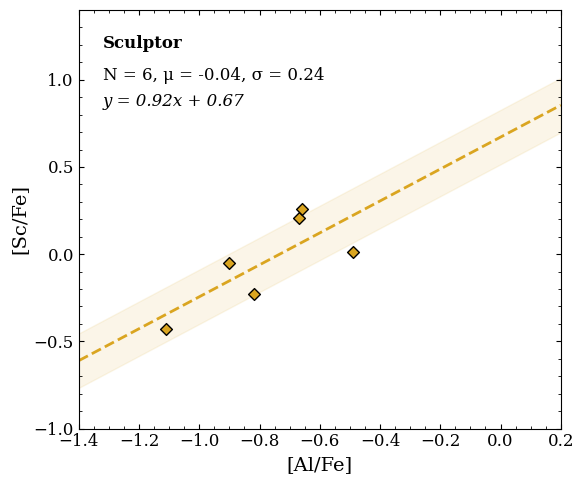

In [15]:
sculp_alfe_scfe = sculp_df.dropna()

xlim = (-1.4, 0.2)
ylim = (-1., 1.4)
text_pos1 = (-1.32, 1.18)
text_pos2 = (-1.32, 1.0)
text_pos3 = (-1.32, 0.85)
text_hozalign = 'left'

# Fitting polynomial
p_sculp = np.polyfit(sculp_alfe_scfe['alfe'], sculp_alfe_scfe['scfe'], deg=1)
fit_sculp = np.poly1d(p_sculp)
xline_sculp = np.linspace(xlim[0], xlim[1], 100)
yline_sculp = fit_sculp(xline_sculp)
res_sculp = sculp_alfe_scfe['scfe'] - fit_sculp(sculp_alfe_scfe['alfe'])
std_sculp = np.std(res_sculp)

plt.figure(figsize=[6,5])
plt.scatter(sculp_alfe_scfe['alfe'], sculp_alfe_scfe['scfe'], color='goldenrod', marker='D', 
                edgecolor='black', zorder=10, linewidths=1)
plt.plot(xline_sculp, yline_sculp, color='goldenrod', linestyle='--', linewidth=2)
plt.fill_between(xline_sculp, 
                    yline_sculp - std_sculp,
                    yline_sculp + std_sculp,
                    color='goldenrod',
                    alpha=0.1)



plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_alfe_scfe)}, μ = {round(np.mean(sculp_alfe_scfe['scfe']), 2)}, σ = {round(np.std(sculp_alfe_scfe['scfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_sculp[0] > 0:
    plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x + {round(p_sculp[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x - {abs(round(p_sculp[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel('[Al/Fe]')
plt.ylabel('[Sc/Fe]')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sculptor_alfe_scfe_comparison.png", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/orbit_groups/sculptor_alfe_scfe_comparison.pdf", dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
plt.show()

#### E vs e

(0.0, 20.0)

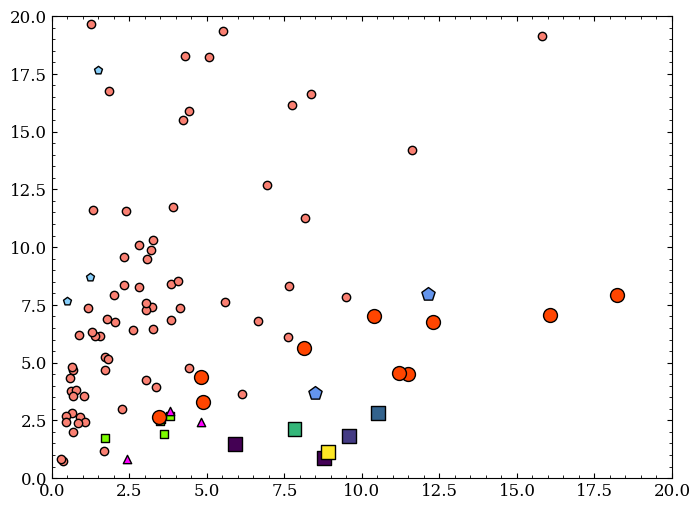

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(xshooter_prodisk['rmax'], xshooter_prodisk['zmax'], c=xshooter_prodisk['abund_scfe'], marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='Prograde Disk')
plt.scatter(xshooter_halo['rmax'], xshooter_halo['zmax'], c=xshooter_prodisk['abund_scfe'], marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='Halo')
plt.scatter(xshooter_gse['rmax'], xshooter_gse['zmax'], c=xshooter_prodisk['abund_scfe'], marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1, label='GSE')

plt.scatter(lit_prodisk['rmax'], lit_prodisk['zmax'], c=xshooter_prodisk['abund_scfe'], marker='s', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_halo['rmax'], lit_halo['zmax'], c=xshooter_prodisk['abund_scfe'], marker='o', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_gse['rmax'], lit_gse['zmax'], c=xshooter_prodisk['abund_scfe'], marker='p', edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_retdisk['rmax'], lit_retdisk['zmax'], c=xshooter_prodisk['abund_scfe'], marker='^', edgecolor='black', zorder=5, linewidths=1)

plt.ylim(0, 20)
plt.xlim(0, 20)

### [Al/Fe] vs [Mg/Mn]

Getting the abundances sorted

In [ ]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
al_xshooter_abunds = all_xshooter_abunds[4]
mg_xshooter_abunds = all_xshooter_abunds[3]
mn_xshooter_abunds = all_xshooter_abunds[10]

# Calculating [Mg/Mn]
mgmn_xshooter_abunds = []
for i, row in mg_xshooter_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    feh = row['feh']
    feh_err = row['feh_err']
    mg_xfe = row['bestfit_abund_xfe']
    mg_xfe_err = row['bestfit_abund_comberr_xfe']
    
    mn_row = mn_xshooter_abunds[mn_xshooter_abunds['star_id'] == star_id]
    if mn_row['detection'].values[0] == 'Y':
        mn_xfe = mn_row['bestfit_abund_xfe'].values[0]
        mn_xfe_err = mn_row['bestfit_abund_comberr_xfe'].values[0]
        
        mgmn_xfe = mg_xfe - mn_xfe
        mgmn_xfe_err = np.sqrt(mg_xfe_err**2 + mn_xfe_err**2)
        
        mgmn_xshooter_abunds.append({
            'star_id': star_id,
            'orbit': orbit,
            'feh': feh,
            'feh_err': feh_err,
            'abund_mgmn': mgmn_xfe,
            'abund_mgmn_err': mgmn_xfe_err
        })
mgmn_xshooter_abunds = pd.DataFrame(mgmn_xshooter_abunds)
al_xshooter_abunds = al_xshooter_abunds[al_xshooter_abunds['star_id'].isin(mg_xshooter_abunds['star_id'])]
al_xshooter_abunds = al_xshooter_abunds.rename(columns={'bestfit_abund_xfe': 'abund_scfe', 'bestfit_abund_comberr_xfe': 'abund_scfe_err'})
comb_xshooter_abunds = pd.merge(al_xshooter_abunds[['star_id', 'orbit', 'feh', 'feh_err', 'abund_scfe', 'abund_scfe_err']], 
                                mgmn_xshooter_abunds[['star_id', 'orbit', 'feh', 'feh_err', 'abund_mgmn', 'abund_mgmn_err']], on=['star_id', 'orbit', 'feh', 'feh_err'])


# For literature
al_lit_abunds = all_lit_abunds[4]
mg_lit_abunds = all_lit_abunds[3]
mn_lit_abunds = all_lit_abunds[10]

# Calculating [Mg/Mn]
mgmn_lit_abunds_list = []
for i, row in mg_lit_abunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    mg_abund = row['abund']
    
    mn_row = mn_lit_abunds[mn_lit_abunds['star_id'] == star_id]
    if not mn_row.empty:
        mn_abund = mn_row['abund'].values[0]
        
        mgmn_abund = mg_abund - mn_abund
        
        mgmn_lit_abunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'abund_mgmn': mgmn_abund
        })
        
mgmn_lit_abunds = pd.DataFrame(mgmn_lit_abunds_list)

comb_df = pd.merge(al_lit_abunds, mgmn_lit_abunds, on=['star_id', 'feh'])
comb_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)


# For literature orbital groups
al_lit_orbabunds = all_lit_orbabunds[4]
mg_lit_orbabunds = all_lit_orbabunds[3]
mn_lit_orbabunds = all_lit_orbabunds[10]

# Calculating [Mg/Mn]
mgmn_lit_orbabunds_list = []
for i, row in mg_lit_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    mg_abund = row['abund']
    
    mn_row = mn_lit_orbabunds[mn_lit_orbabunds['star_id'] == star_id]
    if not mn_row.empty:
        mn_abund = mn_row['abund'].values[0]
        
        mgmn_abund = mg_abund - mn_abund
        
        mgmn_lit_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit': orbit,
            'abund_mgmn': mgmn_abund
        })
        
mgmn_lit_orbabunds = pd.DataFrame(mgmn_lit_orbabunds_list)
comb_orbabunds_df = pd.merge(al_lit_orbabunds, mgmn_lit_orbabunds, on=['star_id', 'feh', 'orbit'])
comb_orbabunds_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)

Separating by kinematic group

In [70]:
# X-Shooter
xshooter_prodisk = comb_xshooter_abunds[comb_xshooter_abunds['orbit'] == 'pro_disk']
xshooter_halo = comb_xshooter_abunds[comb_xshooter_abunds['orbit'] == 'halo']
xshooter_gse = comb_xshooter_abunds[comb_xshooter_abunds['orbit'] == 'gse']

# Literature
lit_prodisk = comb_orbabunds_df[comb_orbabunds_df['orbit'] == 'pro_disk']
lit_halo = comb_orbabunds_df[comb_orbabunds_df['orbit'] == 'halo']
lit_gse = comb_orbabunds_df[comb_orbabunds_df['orbit'] == 'gse']
lit_retdisk = comb_orbabunds_df[comb_orbabunds_df['orbit'] == 'ret_disk']

In [65]:
xshooter_prodisk

,star_id,orbit,feh,feh_err,abund_alfe,abund_alfe_err,abund_mgmn,abund_mgmn_err
0,ra_0103-7050_s163,pro_disk,-2.359003,0.060794,-0.854418,0.032406,1.308332,0.066993
6,ra_1648-0653_s38,pro_disk,-2.475968,0.059728,-1.116179,0.028976,1.199505,0.064655
17,ra_1639-2632_s419,pro_disk,-2.034058,0.063943,-1.113786,0.040947,1.135787,0.124969
19,ra_1659-2154_s261,pro_disk,-2.194068,0.064467,-0.720895,0.049934,1.215704,0.104092
21,ra_1752-4300_s155,pro_disk,-2.907340,0.067832,-0.991605,0.048096,0.979652,0.094700


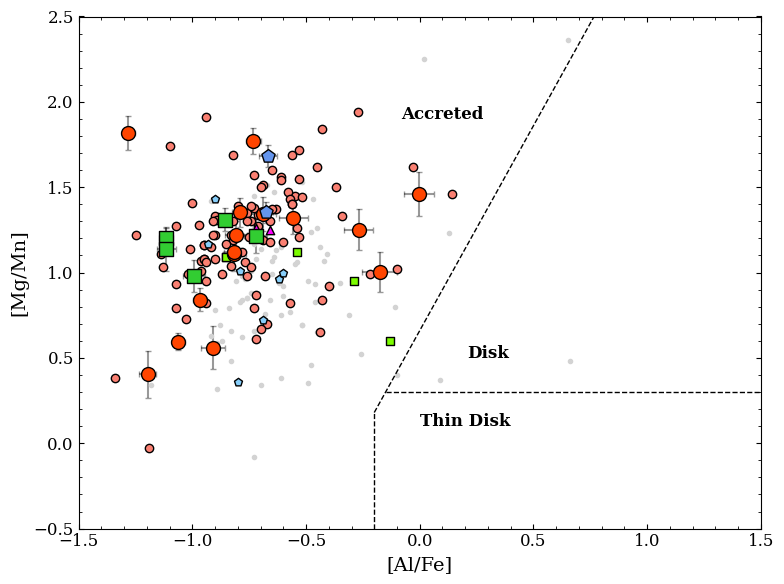

In [ ]:
plt.figure(figsize=(8,6))

# X-Shooter data
plt.scatter(xshooter_prodisk['abund_scfe'], xshooter_prodisk['abund_mgmn'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_prodisk['abund_scfe'], xshooter_prodisk['abund_mgmn'], 
                xerr=xshooter_prodisk['abund_scfe_err'], yerr=xshooter_prodisk['abund_mgmn_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)

plt.scatter(xshooter_halo['abund_scfe'], xshooter_halo['abund_mgmn'], color='orangered', 
            label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_halo['abund_scfe'], xshooter_halo['abund_mgmn'], 
                xerr=xshooter_halo['abund_scfe_err'], yerr=xshooter_halo['abund_mgmn_err'], 
                fmt='o', color='black', zorder=1, alpha=0.4)

plt.scatter(xshooter_gse['abund_scfe'], xshooter_gse['abund_mgmn'], color='cornflowerblue', 
            label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(xshooter_gse['abund_scfe'], xshooter_gse['abund_mgmn'], 
             xerr=xshooter_gse['abund_scfe_err'], yerr=xshooter_gse['abund_mgmn_err'], 
             fmt='o', color='black', zorder=1, alpha=0.4)


# Literature data
plt.scatter(comb_df['abund_scfe'], comb_df['abund_mgmn'], c="lightgrey", marker='.', zorder=1)


# Orbital literature data
plt.scatter(lit_prodisk['abund_scfe'], lit_prodisk['abund_mgmn'], color='lawngreen', marker='s', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_halo['abund_scfe'], lit_halo['abund_mgmn'], color='salmon', marker='o', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_gse['abund_scfe'], lit_gse['abund_mgmn'], color='lightskyblue', marker='p', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(lit_retdisk['abund_scfe'], lit_retdisk['abund_mgmn'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=5, linewidths=1)


# Plotting lines
# plt.axvline(x=-0.2, ymax=0.2, color='black', linestyle='--', linewidth=1)
# plt.axhline(y=0.3, xmin=0.5, color='black', linestyle='--', linewidth=1)

plt.vlines(x=-0.2, ymin=-0.5, ymax=0.18, color='black', linestyle='--', linewidth=1)
plt.hlines(y=0.3, xmin=-0.15, xmax=1.5, color='black', linestyle='--', linewidth=1)

xrange = np.linspace(-0.2, 1.5, 100)
m = (0.3 - 0.18) / (-0.15 - -0.2)

c = 0.18 - m * -0.2
y_vals = m * xrange + c

plt.plot(xrange, y_vals, color='black', linestyle='--', linewidth=1)

plt.xlim(-1.5, 1.5)
plt.ylim(-0.5, 2.5)
plt.text(0.2, 0.1, 'Thin Disk', fontsize=12, horizontalalignment='center', fontweight='bold')
plt.text(0.3, 0.5, 'Disk', fontsize=12, horizontalalignment='center', fontweight='bold')
plt.text(0.1, 1.9, 'Accreted', fontsize=12, horizontalalignment='center', fontweight='bold')

plt.xlabel('[Al/Fe]')
plt.ylabel('[Mg/Mn]')
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_mgmn.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_mgmn.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()

### MDF

Getting data sorted

### Kinematic values vs [Al/Fe]

Getting data sorted

In [9]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# Getting the data for X-Shooter
al_xshooter_abunds = all_xshooter_abunds[4]
al_xshooter_abunds = comb_df.merge(al_xshooter_abunds, on='star_id', how='inner')
al_xshooter_prodisk = al_xshooter_abunds[al_xshooter_abunds['orbit_x'] == 'pro_disk']
al_xshooter_halo = al_xshooter_abunds[al_xshooter_abunds['orbit_x'] == 'halo']
al_xshooter_gse = al_xshooter_abunds[al_xshooter_abunds['orbit_x'] == 'gse']

# Getting the data for literature
al_lit_orbabunds = all_lit_orbabunds[4]
al_lit_orbabunds = al_lit_orbabunds.merge(lit_combined, on='star_id', how='inner')

al_lit_prodisk = al_lit_orbabunds[al_lit_orbabunds['orbit_x'] == 'pro_disk']
al_lit_halo = al_lit_orbabunds[al_lit_orbabunds['orbit_x'] == 'halo']
al_lit_gse = al_lit_orbabunds[al_lit_orbabunds['orbit_x'] == 'gse']
al_lit_retdisk = al_lit_orbabunds[al_lit_orbabunds['orbit_x'] == 'ret_disk']

#### [Al/Fe] vs Jp

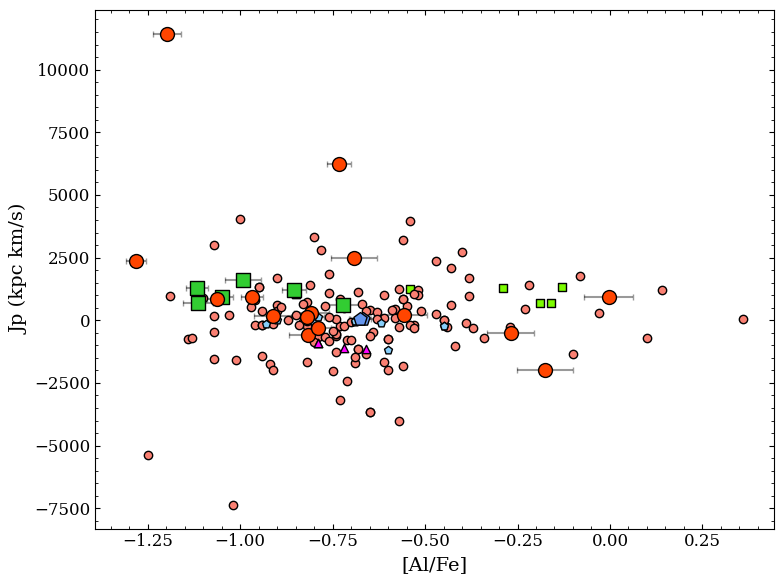

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(al_xshooter_prodisk['bestfit_abund_xfe'], al_xshooter_prodisk['Jp'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_prodisk['bestfit_abund_xfe'], al_xshooter_prodisk['Jp'], xerr=al_xshooter_prodisk['bestfit_abund_comberr_xfe'], 
             fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(al_xshooter_halo['bestfit_abund_xfe'], al_xshooter_halo['Jp'], color='orangered', 
            label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_halo['bestfit_abund_xfe'], al_xshooter_halo['Jp'], xerr=al_xshooter_halo['bestfit_abund_comberr_xfe'], 
             fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(al_xshooter_gse['bestfit_abund_xfe'], al_xshooter_gse['Jp'], color='cornflowerblue', 
            label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_gse['bestfit_abund_xfe'], al_xshooter_gse['Jp'], xerr=al_xshooter_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)

plt.scatter(al_lit_prodisk['abund'], al_lit_prodisk['jp'], color='lawngreen', marker='s', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_halo['abund'], al_lit_halo['jp'], color='salmon', marker='o', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_gse['abund'], al_lit_gse['jp'], color='lightskyblue', marker='p', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_retdisk['abund'], al_lit_retdisk['jp'], color='fuchsia', marker='^',
                    edgecolor='black', zorder=5, linewidths=1)

plt.xlabel('[Al/Fe]')
plt.ylabel('Jp (kpc km/s)')
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_jp.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_jp.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()

#### Vphi vs [Al/Fe]

In [162]:
al_xshooter_prodisk.keys()

Index(['star_id', 'teff', 'logg', 'vmic', 'vsini', 'feh', 'feh_err', 'el',
       'detection', 'upper_limit_xfe', 'upper_limit_xh', 'bestfit_abund_xfe',
       'bestfit_abund_xh', 'bestfit_abund_comberr_xfe',
       'bestfit_abund_comberr_xh', 'bestfit_abund_tefferr_xfe',
       'bestfit_abund_tefferr_xh', 'bestfit_abund_loggerr_xfe',
       'bestfit_abund_loggerr_xh', 'bestfit_abund_vmicerr_xfe',
       'bestfit_abund_vmicerr_xh', 'Jp', 'Jtot', 'Jz', 'Jr', 'zmax', 'orbit',
       'p#'],
      dtype='object')

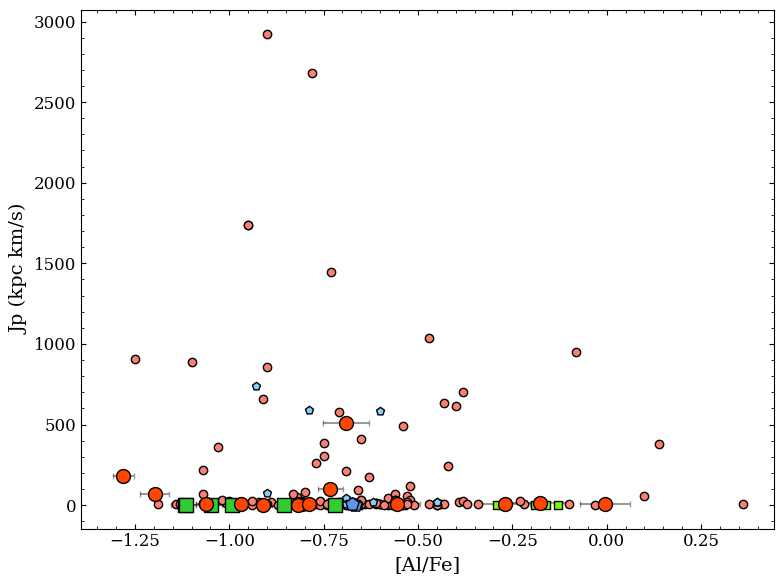

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(al_xshooter_prodisk['bestfit_abund_xfe'], al_xshooter_prodisk['zmax_x'], color='limegreen', 
            label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_prodisk['bestfit_abund_xfe'], al_xshooter_prodisk['zmax_x'], xerr=al_xshooter_prodisk['bestfit_abund_comberr_xfe'], 
             fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(al_xshooter_halo['bestfit_abund_xfe'], al_xshooter_halo['zmax_x'], color='orangered', 
            label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_halo['bestfit_abund_xfe'], al_xshooter_halo['zmax_x'], xerr=al_xshooter_halo['bestfit_abund_comberr_xfe'], 
             fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(al_xshooter_gse['bestfit_abund_xfe'], al_xshooter_gse['zmax_x'], color='cornflowerblue', 
            label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
plt.errorbar(al_xshooter_gse['bestfit_abund_xfe'], al_xshooter_gse['zmax_x'], xerr=al_xshooter_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)

plt.scatter(al_lit_prodisk['abund'], al_lit_prodisk['zmax'], color='lawngreen', marker='s', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_halo['abund'], al_lit_halo['zmax'], color='salmon', marker='o', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_gse['abund'], al_lit_gse['zmax'], color='lightskyblue', marker='p', 
                    edgecolor='black', zorder=5, linewidths=1)
plt.scatter(al_lit_retdisk['abund'], al_lit_retdisk['zmax'], color='fuchsia', marker='^',
                    edgecolor='black', zorder=5, linewidths=1)

plt.xlabel('[Al/Fe]')
plt.ylabel('Jp (kpc km/s)')
plt.tight_layout()
# plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_vp.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/scfe_vp.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
plt.show()

# Orbital analysis with McMillan2017 potential

Testing X-Shooter and literature stars with the McMillan2017 potential

For X-Shooter

Getting input for orbital parameters

In [8]:
# Loading the P113 and P115 Gaia DR3 data
p113_gaia = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')[['star_id', 'ra', 'dec', 'randdist_med', 'randdist_std', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'rv', 'rv_err']]
p115_gaia = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')[['star_id', 'ra', 'dec', 'randdist_med', 'randdist_std', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'rv', 'rv_err']]

comb_gaia = pd.concat([p113_gaia, p115_gaia], ignore_index=True)
comb_gaia.rename(columns={'star_id': 'star',
                         'randdist_med': 'dist',
                         'randdist_std': 'dist_err',
                         'pmra_error': 'pmra_err',
                         'pmdec_error': 'pmdec_err'}, inplace=True)

# comb_gaia.to_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_orb_inputs_ALL.csv', index=False)

Loading in the final orbit results, then classifying

In [11]:
xshooter_orbs = Table.read("/data/misfit/benlowe/xshooter/p115/orbits_mcmillan17/xshooter_orbits.fits").to_pandas()
xshooter_orbs['star'] = xshooter_orbs['star'].str.decode('utf-8')
xshooter_orbs['jtot'] = np.sqrt(xshooter_orbs['jp']**2 + xshooter_orbs['jz']**2 + xshooter_orbs['jr']**2)

# Separating stars into different orbit types
disk_pro = xshooter_orbs[(xshooter_orbs['jp']/xshooter_orbs['jtot'] >= 0.75) & (xshooter_orbs['zmax'] < 3)]
disk_pro['orbit'] = 'pro_disk'

disk_ret = xshooter_orbs[(xshooter_orbs['jp']/xshooter_orbs['jtot'] <= -0.75) & (xshooter_orbs['zmax'] < 3)]
disk_ret['orbit'] = 'ret_disk'

ges = xshooter_orbs[(xshooter_orbs['jp']/xshooter_orbs['jtot'] > -0.25) & (xshooter_orbs['jp']/xshooter_orbs['jtot'] < 0.25) 
                 & ((xshooter_orbs['jz']-xshooter_orbs['jr'])/xshooter_orbs['jtot'] > -0.75) & ((xshooter_orbs['jz']-xshooter_orbs['jr'])/xshooter_orbs['jtot'] < 0.25)]
ges['orbit'] = 'gse'

halo = xshooter_orbs[~xshooter_orbs['star'].isin(ges['star']) & ~xshooter_orbs['star'].isin(disk_pro['star']) & ~xshooter_orbs['star'].isin(disk_ret['star'])]
halo['orbit'] = 'halo'

combined = pd.concat([disk_pro, disk_ret, ges, halo], ignore_index=True)

mcmillan17_orbs = combined[['star', 'orbit']]
mcmillan17_orbs.rename(columns={'star': 'star_id'}, inplace=True)

/tmp/ipykernel_1407371/3856593456.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disk_pro['orbit'] = 'pro_disk'
/tmp/ipykernel_1407371/3856593456.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ges['orbit'] = 'gse'
/tmp/ipykernel_1407371/3856593456.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/ind

In [ ]:
mwpot14 = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Al_I_allabunds.csv')[['star_id', 'orbit']]

comb_orbs = mcmillan17_orbs.merge(mwpot14, on='star_id', how='outer', suffixes=('_mcmillan17', '_mwpot14'))
# comb_orbs.to_csv('/data/misfit/benlowe/xshooter/p115/orbits/orbit_classification_compare.csv', index=False)

For literature stars

In [12]:
lit_orbs = Table.read("/data/misfit/benlowe/xshooter/lit_abund_data/orbits_mcmillan2017/lit_orbits_mcmillan17.fits").to_pandas()
lit_orbs['star'] = lit_orbs['star'].str.decode('utf-8')
lit_orbs['jtot'] = np.sqrt(lit_orbs['jp']**2 + lit_orbs['jz']**2 + lit_orbs['jr']**2)

# Separating stars into different orbit types
lit_disk_pro = lit_orbs[(lit_orbs['jp']/lit_orbs['jtot'] >= 0.75) & (lit_orbs['zmax'] < 3)]
lit_disk_pro['orbit'] = 'pro_disk'

lit_disk_ret = lit_orbs[(lit_orbs['jp']/lit_orbs['jtot'] <= -0.75) & (lit_orbs['zmax'] < 3)]
lit_disk_ret['orbit'] = 'ret_disk'

lit_ges = lit_orbs[(lit_orbs['jp']/lit_orbs['jtot'] > -0.25) & (lit_orbs['jp']/lit_orbs['jtot'] < 0.25) 
                 & ((lit_orbs['jz']-lit_orbs['jr'])/lit_orbs['jtot'] > -0.75) & ((lit_orbs['jz']-lit_orbs['jr'])/lit_orbs['jtot'] < 0.25)]
lit_ges['orbit'] = 'gse'

lit_halo = lit_orbs[~lit_orbs['star'].isin(lit_ges['star']) & ~lit_orbs['star'].isin(lit_disk_pro['star']) & ~lit_orbs['star'].isin(lit_disk_ret['star'])]
lit_halo['orbit'] = 'halo'

lit_combined = pd.concat([lit_disk_pro, lit_disk_ret, lit_ges, lit_halo], ignore_index=True)

lit_mcmillan17_orbs = lit_combined[['star', 'orbit']]
lit_mcmillan17_orbs.rename(columns={'star': 'star_id'}, inplace=True)

/tmp/ipykernel_1407371/1359576597.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_pro['orbit'] = 'pro_disk'
/tmp/ipykernel_1407371/1359576597.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_ret['orbit'] = 'ret_disk'
/tmp/ipykernel_1407371/1359576597.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/sta

In [ ]:
print(f"Number of prograde disk stars: {len(lit_disk_pro)}")
print(f"Number of retrograde disk stars: {len(lit_disk_ret)}")
print(f"Number of GES stars: {len(lit_ges)}")
print(f"Number of halo stars: {len(lit_halo)}")

Number of prograde disk stars: 17
Number of retrograde disk stars: 6
Number of GES stars: 28
Number of halo stars: 264


## Loading in the data

Loading in literature data

In [13]:
# Loading in the literature orbits and the Gaia data
lit_orbs_mcmillan17 = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/orbits_mcmillan2017/lit_orbits_mcmillan17.fits')
lit_orbs_mcmillan17_df = lit_orbs_mcmillan17.to_pandas()
lit_orbs_mcmillan17_df['star'] = lit_orbs_mcmillan17_df['star'].str.decode('utf-8')  # Decode bytes to string
lit_orbs_mcmillan17_df['jtot'] = np.sqrt(lit_orbs_mcmillan17_df['jp']**2 + lit_orbs_mcmillan17_df['jz']**2 + lit_orbs_mcmillan17_df['jr']**2)

lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_v2.csv')

# # For Jacobson+2015, only taking stars present in Cordoni+2021.
# cordoni2021_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/cordoni2021_gaia_ids.csv')
# leftover = []
# for i, row in lit_gaia_df.iterrows():
#     catalog = row['catalog']
#     if catalog == 'jacobson2015':
#         if row['target_id'] not in cordoni2021_df['gaia_id'].values:
#             lit_gaia_df.drop(i, inplace=True)
#             lit_orbs_df.drop(i, inplace=True)
            
#             # Adding the dropped star to the leftover list
#             leftover.append({'star_id': row['target_id'], 'ra': row['ra'], 'dec': row['dec']})
# leftover_df = pd.DataFrame(leftover)
# leftover_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_leftover_stars.csv', index=False)

# For stars dropped, update the lit_orbs_df and lit_gaia_df with the updated leftover data
leftover_lit_orbs_mcmillan17 = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/orbits_leftover_mcmillan2017/lit_orbits_mcmillan17.fits')
leftover_lit_orbs_mcmillan17_df = leftover_lit_orbs_mcmillan17.to_pandas()
leftover_lit_orbs_mcmillan17_df['star'] = leftover_lit_orbs_mcmillan17_df['star'].str.decode('utf-8')  # Decode bytes to string
leftover_lit_orbs_mcmillan17_df['jtot'] = np.sqrt(leftover_lit_orbs_mcmillan17_df['jp']**2 + leftover_lit_orbs_mcmillan17_df['jz']**2 + leftover_lit_orbs_mcmillan17_df['jr']**2)

leftover_lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_leftover.csv')

for i, row in leftover_lit_gaia_df.iterrows():
    star_id = row['star_id']
    if star_id in lit_gaia_df['star_id'].values:
        # Update the corresponding row in lit_gaia_df with the new rv and rv_err values
        lit_gaia_df.loc[lit_gaia_df['star_id'] == star_id, 'rv'] = row['rv']
        lit_gaia_df.loc[lit_gaia_df['star_id'] == star_id, 'rv_err'] = row['rv_err']
        
for i, row in leftover_lit_orbs_mcmillan17_df.iterrows():
    star_id = row['star']
    if star_id in lit_orbs_mcmillan17_df['star'].values:
        # Update the corresponding row in lit_orbs_df with the new orbital parameters
        lit_orbs_mcmillan17_df.loc[lit_orbs_mcmillan17_df['star'] == star_id, ['star', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'xhelio', 'xhelio_err', 'yhelio',
       'yhelio_err', 'zhelio', 'zhelio_err', 'U', 'U_err', 'V', 'V_err', 'W',
       'W_err', 'R', 'R_err', 'phi', 'phi_err', 'z', 'z_err', 'vR', 'vR_err',
       'vT', 'vT_err', 'vz', 'vz_err', 'jr', 'jr_err', 'jp', 'jp_err', 'jz',
       'jz_err', 'omega_R', 'omega_R_err', 'omega_phi', 'omega_phi_err',
       'omega_z', 'omega_z_err', 'angle_R', 'angle_R_err', 'alpha_phi',
       'alpha_phi_err', 'angle_z', 'angle_z_err', 'e', 'e_err', 'zmax',
       'zmax_err', 'R_peri', 'R_peri_err', 'R_ap', 'R_ap_err', 'E', 'E_err',
       'jtot']] = row[['star', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'xhelio', 'xhelio_err', 'yhelio',
       'yhelio_err', 'zhelio', 'zhelio_err', 'U', 'U_err', 'V', 'V_err', 'W',
       'W_err', 'R', 'R_err', 'phi', 'phi_err', 'z', 'z_err', 'vR', 'vR_err',
       'vT', 'vT_err', 'vz', 'vz_err', 'jr', 'jr_err', 'jp', 'jp_err', 'jz',
       'jz_err', 'omega_R', 'omega_R_err', 'omega_phi', 'omega_phi_err',
       'omega_z', 'omega_z_err', 'angle_R', 'angle_R_err', 'alpha_phi',
       'alpha_phi_err', 'angle_z', 'angle_z_err', 'e', 'e_err', 'zmax',
       'zmax_err', 'R_peri', 'R_peri_err', 'R_ap', 'R_ap_err', 'E', 'E_err',
       'jtot']].values

# lit_orbs_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_orbit_params.csv', index=False)
# lit_gaia_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data_v2.csv', index=False)

# Separating stars into different orbit types
lit_disk_pro_mcmillan17 = lit_orbs_mcmillan17_df[(lit_orbs_mcmillan17_df['jp']/lit_orbs_mcmillan17_df['jtot'] >= 0.75) & (lit_orbs_mcmillan17_df['zmax'] < 3)]
lit_disk_pro_mcmillan17['orbit'] = 'pro_disk'

lit_disk_ret_mcmillan17 = lit_orbs_mcmillan17_df[(lit_orbs_mcmillan17_df['jp']/lit_orbs_mcmillan17_df['jtot'] <= -0.75) & (lit_orbs_mcmillan17_df['zmax'] < 3)]
lit_disk_ret_mcmillan17['orbit'] = 'ret_disk'

lit_ges_mcmillan17 = lit_orbs_mcmillan17_df[(lit_orbs_mcmillan17_df['jp']/lit_orbs_mcmillan17_df['jtot'] > -0.25) & (lit_orbs_mcmillan17_df['jp']/lit_orbs_mcmillan17_df['jtot'] < 0.25) 
                 & ((lit_orbs_mcmillan17_df['jz']-lit_orbs_mcmillan17_df['jr'])/lit_orbs_mcmillan17_df['jtot'] > -0.75) & ((lit_orbs_mcmillan17_df['jz']-lit_orbs_mcmillan17_df['jr'])/lit_orbs_mcmillan17_df['jtot'] < 0.25)]
lit_ges_mcmillan17['orbit'] = 'gse'

lit_halo_mcmillan17 = lit_orbs_mcmillan17_df[~lit_orbs_mcmillan17_df['star'].isin(lit_ges_mcmillan17['star']) & ~lit_orbs_mcmillan17_df['star'].isin(lit_disk_pro_mcmillan17['star']) & ~lit_orbs_mcmillan17_df['star'].isin(lit_disk_ret_mcmillan17['star'])]
lit_halo_mcmillan17['orbit'] = 'halo'


# Combining all the orbit types into one DataFrame
lit_combined_mcmillan17 = pd.concat([lit_disk_pro_mcmillan17, lit_disk_ret_mcmillan17, lit_ges_mcmillan17, lit_halo_mcmillan17], ignore_index=True)
# lit_combined['star'] = lit_combined['star'].str.decode('utf-8')  # Decode bytes to string
lit_combined_mcmillan17.rename(columns={'star': 'star_id'}, inplace=True)  # Rename 'star' to 'star_id' for merging

lit_combined_mcmillan17 = lit_combined_mcmillan17.merge(lit_gaia_df[['star_id', 'teff', 'feh', 'logg', 'source_id', 'catalog']], left_on='star_id', right_on='star_id', how='left')
# lit_combined.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_orbits_v2.csv', index=False)


lit_disk_pro_mcmillan17 = lit_combined_mcmillan17[lit_combined_mcmillan17['orbit'] == 'pro_disk']
lit_disk_ret_mcmillan17 = lit_combined_mcmillan17[lit_combined_mcmillan17['orbit'] == 'ret_disk']
lit_ges_mcmillan17 = lit_combined_mcmillan17[lit_combined_mcmillan17['orbit'] == 'gse']
lit_halo_mcmillan17 = lit_combined_mcmillan17[lit_combined_mcmillan17['orbit'] == 'halo']

print(f"Number of prograde disk stars: {len(lit_disk_pro_mcmillan17)}")
print(f"Number of retrograde disk stars: {len(lit_disk_ret_mcmillan17)}")
print(f"Number of GES stars: {len(lit_ges_mcmillan17)}")
print(f"Number of halo stars: {len(lit_halo_mcmillan17)}")

Number of prograde disk stars: 17
Number of retrograde disk stars: 6
Number of GES stars: 28
Number of halo stars: 264


/tmp/ipykernel_1407371/2132419184.py:68: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_pro_mcmillan17['orbit'] = 'pro_disk'
/tmp/ipykernel_1407371/2132419184.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_disk_ret_mcmillan17['orbit'] = 'ret_disk'
/tmp/ipykernel_1407371/2132419184.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyd

In [59]:
compare_prodisk = pd.merge(lit_disk_pro_mcmillan17[['star_id']], lit_disk_pro[['star_id']])
compare_prodisk_leftover = pd.merge(lit_disk_pro_mcmillan17[['star_id']], lit_disk_pro[['star_id']], how='left', indicator="prodisk_membership")
display(compare_prodisk_leftover)
print(f"Number of prograde disk stars in Mcmillan17: {len(lit_disk_pro_mcmillan17)}")
print(f"Number of prograde disk stars in Mcmillan17 that are also in the original prograde disk sample: {len(compare_prodisk)}")
print(f"Number of prograde disk stars in Mcmillan17 that are NOT in the original prograde disk sample: {len(compare_prodisk_leftover[compare_prodisk_leftover['prodisk_membership'] == 'left_only'])}")
print()
print(f"Number of prograde disk stars in mwpotential2014: {len(lit_disk_pro)}")

,star_id,prodisk_membership
0,53327-2044-515,both
1,HE 0945-1435,both
2,SMSS J125125.64-340343.4,left_only
3,SMSS J135217.78-151405.7,both
4,SMSS J155628.74-165533.4,both
5,SMSS J165023.82-252948.7,both
6,SMSS J174922.26-455103.8,both
7,SMSS J185628.44-231809.8,both
8,SMSS J190549.33-214945.0,both
9,J081627.99-055913.3,both


Number of prograde disk stars in Mcmillan17: 17
Number of prograde disk stars in Mcmillan17 that are also in the original prograde disk sample: 15
Number of prograde disk stars in Mcmillan17 that are NOT in the original prograde disk sample: 2

Number of prograde disk stars in mwpotential2014: 16


Loading in the X-Shooter data

In [14]:
comb_mcmillan17_table = Table.read("/data/misfit/benlowe/xshooter/p115/orbits_mcmillan17/xshooter_orbits.fits")
comb_mcmillan17_df = comb_mcmillan17_table.to_pandas()
comb_mcmillan17_df['star'] = comb_mcmillan17_df['star'].str.decode('utf-8')  # Decode bytes to string
comb_mcmillan17_df.rename(columns={'star': 'star_id'}, inplace=True)  

comb_mcmillan17_df['jtot'] = np.sqrt(comb_mcmillan17_df['jp']**2 + comb_mcmillan17_df['jz']**2 + comb_mcmillan17_df['jr']**2)
comb_mcmillan17_df.rename(columns={'Jp': 'jp', 'Jz': 'jz', 'Jr': 'jr', 'Jtot': 'jtot'}, inplace=True)

# Separating the orbits into different types
pro_disk_mcmillan17 = comb_mcmillan17_df[(comb_mcmillan17_df['jp']/comb_mcmillan17_df['jtot'] >= 0.75) & (comb_mcmillan17_df['zmax'] < 3)]
pro_disk_mcmillan17['orbit'] = 'pro_disk'
ret_disk_mcmillan17 = comb_mcmillan17_df[(comb_mcmillan17_df['jp']/comb_mcmillan17_df['jtot'] <= -0.75) & (comb_mcmillan17_df['zmax'] < 3)]
ret_disk_mcmillan17['orbit'] = 'ret_disk'
gse_mcmillan17 = comb_mcmillan17_df[(comb_mcmillan17_df['jp']/comb_mcmillan17_df['jtot'] > -0.25) & (comb_mcmillan17_df['jp']/comb_mcmillan17_df['jtot'] < 0.25)
                 & ((comb_mcmillan17_df['jz']-comb_mcmillan17_df['jr'])/comb_mcmillan17_df['jtot'] > -0.75) & ((comb_mcmillan17_df['jz']-comb_mcmillan17_df['jr'])/comb_mcmillan17_df['jtot'] < 0.25)]
gse_mcmillan17['orbit'] = 'gse'
halo_mcmillan17 = comb_mcmillan17_df[~comb_mcmillan17_df['star_id'].isin(gse_mcmillan17['star_id']) & ~comb_mcmillan17_df['star_id'].isin(pro_disk_mcmillan17['star_id']) & ~comb_mcmillan17_df['star_id'].isin(ret_disk_mcmillan17['star_id'])]
halo_mcmillan17['orbit'] = 'halo'

# Combining back together
comb_mcmillan17_df = pd.concat([pro_disk_mcmillan17, ret_disk_mcmillan17, gse_mcmillan17, halo_mcmillan17], ignore_index=True)

print(f"Number of prograde disk stars: {len(pro_disk_mcmillan17)}")
print(f"Number of retrograde disk stars: {len(ret_disk_mcmillan17)}")
print(f"Number of GES stars: {len(gse_mcmillan17)}")
print(f"Number of halo stars: {len(halo_mcmillan17)}")

Number of prograde disk stars: 2
Number of retrograde disk stars: 0
Number of GES stars: 2
Number of halo stars: 19


/tmp/ipykernel_1407371/3535071730.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pro_disk_mcmillan17['orbit'] = 'pro_disk'
/tmp/ipykernel_1407371/3535071730.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gse_mcmillan17['orbit'] = 'gse'
/tmp/ipykernel_1407371/3535071730.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-doc

In [71]:
pro_disk_mcmillan17

,star_id,ra,dec,dist,dist_err,pmRA,pmRA_err,pmdec,pmdec_err,Vlos,...,zmax,zmax_err,R_peri,R_peri_err,R_ap,R_ap_err,E,E_err,jtot,orbit
1,ra_0834-5220_s316,129.069598,-52.943230,1.538664,0.147587,-17.024315,0.063436,10.444104,0.053913,143.216454,...,1.863424,0.145224,3.370088,0.285762,9.709497,0.217716,-166051.488343,735.085082,1164.855437,pro_disk
20,ra_1659-2154_s261,254.564407,-21.617627,3.047775,2.001123,-3.316240,0.083514,-9.794129,0.060467,182.174054,...,1.700891,0.649792,1.123569,0.329177,8.479844,2.175861,-172374.297156,9715.543959,664.124198,pro_disk


Loading in the full AAT dataset

In [15]:
aat_orb_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/aat_params_FINAL.csv')
aat_orb_df.rename(columns={'Jp': 'jp', 'Jz': 'jz', 'Jr': 'jr', 'Jtot': 'jtot'}, inplace=True)

aat_orb_df_fehm20 = aat_orb_df[aat_orb_df['z'] < -2.0]
aat_orb_df_fehm25 = aat_orb_df[aat_orb_df['z'] < -2.5]

Loading in Sculptor data

In [60]:
dwarf_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/dwarf_abunds.csv')
sculp_df = dwarf_df[dwarf_df['galaxy'] == 'sculptor']

## Loading in chemical abundances

For literature

In [16]:
lit_abund_path = '/data/misfit/benlowe/xshooter/lit_abund_data/abundances'

def load_lit_abunds(lit_path, el):
    """Loads in the literature abundances for a given element.

    Parameters
    ----------
    lit_path : str
        Path to the literature abundances.
    el : str
         Element to load abundances for. Make sure to include the ionization state (e.g. 'feI' or 'mgII').

    Returns
    -------
    el_lit_abunds : pd.DataFrame
        DataFrame containing the literature abundances for the given element, along with the corresponding orbit classifications.
    el_lit_orb_abunds : pd.DataFrame
        DataFrame containing the literature abundances for the given element, but only for stars with orbit classifications. This is a subset of el_lit_abunds.
    """
    
    el_lit_abunds = pd.read_csv(os.path.join(lit_path, f'{el}_lit_abund.csv'))
    el_lit_abunds.dropna(subset=['abund'], inplace=True)  # Drop rows where abundance is NaN
    
    # For stars without orbits, drop the rows
    el_lit_orb_abunds = el_lit_abunds.merge(lit_combined_mcmillan17[['star_id', 'orbit']], left_on='star_id', right_on='star_id', how='left')
    el_lit_orb_abunds = el_lit_orb_abunds.dropna(subset=['orbit'])
    
    return el_lit_abunds, el_lit_orb_abunds
    

alI_lit_mcmillan17_abunds, alI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'alI')
baII_lit_mcmillan17_abunds, baII_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'baII')
caI_lit_mcmillan17_abunds, caI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'caI')
cI_lit_mcmillan17_abunds, cI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'cI')
nI_lit_mcmillan17_abunds, nI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'nI')
naI_lit_mcmillan17_abunds, naI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'naI')
coI_lit_mcmillan17_abunds, coI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'coI')
crI_lit_mcmillan17_abunds, crI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'crI')
euII_lit_mcmillan17_abunds, euII_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'euII')
mgI_lit_mcmillan17_abunds, mgI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'mgI')
mnI_lit_mcmillan17_abunds, mnI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'mnI')
niI_lit_mcmillan17_abunds, niI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'niI')
scII_lit_mcmillan17_abunds, scII_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'scII')
siI_lit_mcmillan17_abunds, siI_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'siI')
srII_lit_mcmillan17_abunds, srII_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'srII')
tiII_lit_mcmillan17_abunds, tiII_lit_mcmillan17_orbabunds = load_lit_abunds(lit_abund_path, 'tiII')

For X-Shooter data

In [17]:
# Loading in the P113 and P115 data
def get_data(path):
    
    # Getting list of all abundances files
    list_data = [path + f for f in os.listdir(path) if f.endswith('I_abunds.csv')]

    # Storing the dataframes in a dictionary, with the element as the key
    dict_data = {df['el'].iloc[0]: df for df in [pd.read_csv(f) for f in list_data]}
    
    # For each star in each dataframe, replacing the star's orbit classification with the mcmillan17 classification
    for el, df in dict_data.items():
        df = df.merge(comb_mcmillan17_df[['star_id', 'orbit']], left_on='star_id', right_on='star_id', how='left', suffixes=('', '_mcmillan17'))
        dict_data[el] = df

    # Rearranging the dictionary to have elements in order of atomic number
    el_order = ['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II',
            'Ti_II', 'Cr_I', 'Mn_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']
    dict_data = {el: dict_data[el] for el in el_order}

    return dict_data

p113_data = get_data('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/')
for el, df in p113_data.items():
    p113_data[el]['p#'] = 'p113'

p115_data = get_data('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/')
for el, df in p115_data.items():
    p115_data[el]['p#'] = 'p115'

# Combining the P113 and P115 data into one dictionary
comb_xshooter_data_mcmillan17 = {el: pd.concat([p113_data[el], p115_data[el]], ignore_index=True) for el in p113_data.keys()}

# Updating the orbit classifications with the teff, logg and feh values from X-Shooter
p113_params = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
p115_params = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')
comb_params = pd.concat([p113_params, p115_params], ignore_index=True)

# pro_disk_mcmillan17 = pro_disk_mcmillan17.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# pro_disk_mcmillan17.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# ret_disk_mcmillan17 = ret_disk_mcmillan17.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# ret_disk_mcmillan17.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# gse_mcmillan17 = gse_mcmillan17.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# gse_mcmillan17.rename(columns={'Fe_it1': 'feh'}, inplace=True)
# halo_mcmillan17 = halo_mcmillan17.merge(comb_params[['star_id', 'teff', 'Fe_it1', 'logg']], left_on='star_id', right_on='star_id', how='left')
# halo_mcmillan17.rename(columns={'Fe_it1': 'feh'}, inplace=True)


## Making abundance plots

In [18]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_xshooter_mcmillan17_abunds = [comb_xshooter_data_mcmillan17['C_I'], comb_xshooter_data_mcmillan17['N_I'], comb_xshooter_data_mcmillan17['Na_I'], comb_xshooter_data_mcmillan17['Mg_I'], comb_xshooter_data_mcmillan17['Al_I'], comb_xshooter_data_mcmillan17['Si_I'], comb_xshooter_data_mcmillan17['Ca_II'], comb_xshooter_data_mcmillan17['Sc_II'],
                  comb_xshooter_data_mcmillan17['Ti_II'], comb_xshooter_data_mcmillan17['Cr_I'], comb_xshooter_data_mcmillan17['Mn_I'], comb_xshooter_data_mcmillan17['Co_I'], comb_xshooter_data_mcmillan17['Ni_I'], 
                  comb_xshooter_data_mcmillan17['Sr_II'], comb_xshooter_data_mcmillan17['Ba_II'], comb_xshooter_data_mcmillan17['Eu_II']]

all_lit_mcmillan17_abunds = [cI_lit_mcmillan17_abunds, nI_lit_mcmillan17_abunds, naI_lit_mcmillan17_abunds, mgI_lit_mcmillan17_abunds, alI_lit_mcmillan17_abunds, siI_lit_mcmillan17_abunds, caI_lit_mcmillan17_abunds,
                  scII_lit_mcmillan17_abunds, tiII_lit_mcmillan17_abunds, crI_lit_mcmillan17_abunds, mnI_lit_mcmillan17_abunds, coI_lit_mcmillan17_abunds, niI_lit_mcmillan17_abunds, 
                  srII_lit_mcmillan17_abunds, baII_lit_mcmillan17_abunds, euII_lit_mcmillan17_abunds]

all_lit_mcmillan17_orbabunds = [cI_lit_mcmillan17_orbabunds, nI_lit_mcmillan17_orbabunds, naI_lit_mcmillan17_orbabunds, mgI_lit_mcmillan17_orbabunds, alI_lit_mcmillan17_orbabunds, siI_lit_mcmillan17_orbabunds, caI_lit_mcmillan17_orbabunds,
                     scII_lit_mcmillan17_orbabunds, tiII_lit_mcmillan17_orbabunds, crI_lit_mcmillan17_orbabunds, mnI_lit_mcmillan17_orbabunds, coI_lit_mcmillan17_orbabunds, niI_lit_mcmillan17_orbabunds,
                     srII_lit_mcmillan17_orbabunds, baII_lit_mcmillan17_orbabunds, euII_lit_mcmillan17_orbabunds]

### Looking at Mg and Sc abundances

Loading in the data

In [19]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
        'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']

# For X-Shooter
mg_xshooter_mcmillan17_abunds = all_xshooter_mcmillan17_abunds[3]
sc_xshooter_mcmillan17_abunds = all_xshooter_mcmillan17_abunds[7]

# Calculating [Sc/Mg]
scmg_xshooter_mcmillan17_abunds = []
for i, row in mg_xshooter_mcmillan17_abunds.iterrows():
    star_id = row['star_id']
    orbit = row['orbit']
    orbit_mcmillan17 = row['orbit_mcmillan17']
    feh = row['feh']
    feh_err = row['feh_err']
    mg_xfe = row['bestfit_abund_xfe']
    mg_xfe_err = row['bestfit_abund_comberr_xfe']
    
    orb_row = comb_mcmillan17_df[comb_mcmillan17_df['star_id'] == star_id]
    if not orb_row.empty:
        print(orb_row.keys())
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
    
    sc_row = sc_xshooter_mcmillan17_abunds[sc_xshooter_mcmillan17_abunds['star_id'] == star_id]
    
    
    if sc_row['detection'].values[0] == 'Y':
        sc_xfe = sc_row['bestfit_abund_xfe'].values[0]
        sc_xfe_err = sc_row['bestfit_abund_comberr_xfe'].values[0]
        
        scmg_xfe = sc_xfe - mg_xfe
        scmg_xfe_err = np.sqrt(sc_xfe_err**2 + mg_xfe_err**2)
        
        scmg_xshooter_mcmillan17_abunds.append({
            'star_id': star_id,
            'orbit': orbit,
            'orbit_mcmillan17': orbit_mcmillan17,
            'feh': feh,
            'feh_err': feh_err,
            'abund_mgfe': mg_xfe,
            'abund_mgfe_err': mg_xfe_err,
            'abund_scfe': sc_xfe,
            'abund_scfe_err': sc_xfe_err,
            'abund_scmg': scmg_xfe,
            'abund_scmg_err': scmg_xfe_err,
            'bestfit_abund_xfe': scmg_xfe,
            'abund_err': scmg_xfe_err,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
        })
scmg_xshooter_mcmillan17_abunds = pd.DataFrame(scmg_xshooter_mcmillan17_abunds)

# For literature
mg_lit_mcmillan17_abunds = all_lit_mcmillan17_abunds[3]
sc_lit_mcmillan17_abunds = all_lit_mcmillan17_abunds[7]

# Calculating [Sc/Mg]
scmg_lit_mcmillan17_abunds_list = []
for i, row in mg_lit_mcmillan17_abunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    mg_abund = row['abund']
    
    orb_row = lit_combined_mcmillan17[lit_combined_mcmillan17['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
    
    sc_row = sc_lit_mcmillan17_abunds[sc_lit_mcmillan17_abunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        
        scmg_abund = sc_abund - mg_abund
        
        scmg_lit_mcmillan17_abunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'abund_mgfe': mg_abund,
            'abund_scfe': sc_abund,
            'abund_scmg': scmg_abund,
            'bestfit_abund_xfe': scmg_abund,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
        })
        
scmg_lit_mcmillan17_abunds = pd.DataFrame(scmg_lit_mcmillan17_abunds_list)

# comb_df = pd.merge(al_lit_mcmillan17_abunds, scal_lit_mcmillan17_abunds, on=['star_id', 'feh'])
# comb_df.rename(columns={'abund': 'abund_scfe'}, inplace=True)


# For literature orbital groups
mg_lit_mcmillan17_orbabunds = all_lit_mcmillan17_orbabunds[3]
sc_lit_mcmillan17_orbabunds = all_lit_mcmillan17_orbabunds[7]

# Calculating [Mg/Mn]
scmg_lit_mcmillan17_orbabunds_list = []
for i, row in mg_lit_mcmillan17_orbabunds.iterrows():
    star_id = row['star_id']
    feh = row['feh']
    orbit = row['orbit']
    mg_abund = row['abund']
    mg_abund_err = row['abund_err']
    
    orb_row = lit_combined_mcmillan17[lit_combined_mcmillan17['star_id'] == star_id]
    if not orb_row.empty:
        # Retrieving the following:
        # 'rmax', 'zmax', 'E', 'jp', 'jr', 'jz', 'jtot', 'e', 'dist', 'Vr', 'Vphi', 'X', 'Y', 'i'
        zmax = orb_row['zmax'].values[0]
        E = orb_row['E'].values[0]
        jp = orb_row['jp'].values[0]
        jr = orb_row['jr'].values[0]
        jz = orb_row['jz'].values[0]
        jtot = orb_row['jtot'].values[0]
        e = orb_row['e'].values[0]
        dist = orb_row['dist'].values[0]
    
    sc_row = sc_lit_mcmillan17_orbabunds[sc_lit_mcmillan17_orbabunds['star_id'] == star_id]
    if not sc_row.empty:
        sc_abund = sc_row['abund'].values[0]
        sc_abund_err = sc_row['abund_err'].values[0]
        
        scmg_abund = sc_abund - mg_abund
        scmg_abund_err = np.sqrt(sc_abund_err**2 + mg_abund_err**2)
        
        scmg_lit_mcmillan17_orbabunds_list.append({
            'star_id': star_id,
            'feh': feh,
            'orbit_mcmillan17': orbit,
            'abund_mgfe': mg_abund,
            'abund_mgfe_err': mg_abund_err,
            'abund_scfe': sc_abund,
            'abund_scfe_err': sc_abund_err,
            'abund_scmg': scmg_abund,
            'abund_scmg_err': scmg_abund_err,
            'abund': scmg_abund,
            'abund_err': scmg_abund_err,
            'zmax': zmax,
            'E': E,
            'jp': jp,
            'jr': jr,
            'jz': jz,
            'jtot': jtot,
            'e': e,
            'dist': dist,
        })
        
scmg_lit_mcmillan17_orbabunds = pd.DataFrame(scmg_lit_mcmillan17_orbabunds_list)

Index(['star_id', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'xhelio', 'xhelio_err', 'yhelio',
       'yhelio_err', 'zhelio', 'zhelio_err', 'U', 'U_err', 'V', 'V_err', 'W',
       'W_err', 'R', 'R_err', 'phi', 'phi_err', 'z', 'z_err', 'vR', 'vR_err',
       'vT', 'vT_err', 'vz', 'vz_err', 'jr', 'jr_err', 'jp', 'jp_err', 'jz',
       'jz_err', 'omega_R', 'omega_R_err', 'omega_phi', 'omega_phi_err',
       'omega_z', 'omega_z_err', 'angle_R', 'angle_R_err', 'alpha_phi',
       'alpha_phi_err', 'angle_z', 'angle_z_err', 'e', 'e_err', 'zmax',
       'zmax_err', 'R_peri', 'R_peri_err', 'R_ap', 'R_ap_err', 'E', 'E_err',
       'jtot', 'orbit'],
      dtype='object')
Index(['star_id', 'ra', 'dec', 'dist', 'dist_err', 'pmRA', 'pmRA_err', 'pmdec',
       'pmdec_err', 'Vlos', 'eVlos', 'xhelio', 'xhelio_err', 'yhelio',
       'yhelio_err', 'zhelio', 'zhelio_err', 'U', 'U_err', 'V', 'V_err', 'W',
       'W_err', 'R', 'R_err', 'phi', 'phi_err'

Separating by kinematic group

In [20]:
# X-Shooter
el_xshooter_mcmillan17_abund_prodisk = scmg_xshooter_mcmillan17_abunds[scmg_xshooter_mcmillan17_abunds['orbit_mcmillan17'] == 'pro_disk']
el_xshooter_mcmillan17_abund_halo = scmg_xshooter_mcmillan17_abunds[scmg_xshooter_mcmillan17_abunds['orbit_mcmillan17'] == 'halo']
el_xshooter_mcmillan17_abund_gse = scmg_xshooter_mcmillan17_abunds[scmg_xshooter_mcmillan17_abunds['orbit_mcmillan17'] == 'gse']

# Literature
lit_mcmillan17_orbabund_prodisk = scmg_lit_mcmillan17_orbabunds[scmg_lit_mcmillan17_orbabunds['orbit_mcmillan17'] == 'pro_disk']
lit_mcmillan17_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
lit_mcmillan17_orbabund_prodisk.dropna(subset=['abund_err'], inplace=True)

lit_mcmillan17_orbabund_halo = scmg_lit_mcmillan17_orbabunds[scmg_lit_mcmillan17_orbabunds['orbit_mcmillan17'] == 'halo']
lit_mcmillan17_orbabund_halo.drop_duplicates(subset=['star_id'], inplace=True)
lit_mcmillan17_orbabund_halo.dropna(subset=['abund_err'], inplace=True)

lit_mcmillan17_orbabund_gse = scmg_lit_mcmillan17_orbabunds[scmg_lit_mcmillan17_orbabunds['orbit_mcmillan17'] == 'gse']
lit_mcmillan17_orbabund_gse.drop_duplicates(subset=['star_id'], inplace=True)
lit_mcmillan17_orbabund_gse.dropna(subset=['abund_err'], inplace=True)

lit_mcmillan17_orbabund_retdisk = scmg_lit_mcmillan17_orbabunds[scmg_lit_mcmillan17_orbabunds['orbit_mcmillan17'] == 'ret_disk']
lit_mcmillan17_orbabund_retdisk.drop_duplicates(subset=['star_id'], inplace=True)
lit_mcmillan17_orbabund_retdisk.dropna(subset=['abund_err'], inplace=True)

# Sculptor dwarf galaxy
sculp_df['scmg'] = sculp_df['scfe'] - sculp_df['mgfe']
sculp_df['scmg_err'] = np.sqrt(sculp_df['scfe_err']**2 + sculp_df['mgfe_err']**2)


/tmp/ipykernel_1407371/3887577030.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_mcmillan17_orbabund_prodisk.drop_duplicates(subset=['star_id'], inplace=True)
/tmp/ipykernel_1407371/3887577030.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_mcmillan17_orbabund_prodisk.dropna(subset=['abund_err'], inplace=True)
/tmp/ipykernel_1407371/3887577030.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_mcmillan17_orbabund

#### [Fe/H] vs [Sc/Mg]

In [25]:
# Save paths for [Sc/Mg] plots
save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/all_fit/scmg_abunds" 
delta_chisqr_save_path = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr_mcmillan17/scmg_abunds_mcmillan17" 
halo_fit_save_path = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/halo_fit/scmg_abunds_mcmillan17" 
z_score_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/zscore_plots/scmg_abunds_zscore" 
cdf_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/cdf_plots/scmg_abunds_cdf" 
stat_save_path = None # "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/ks_test_plots/scmg_abunds_ks"

##### Delta Chisquare

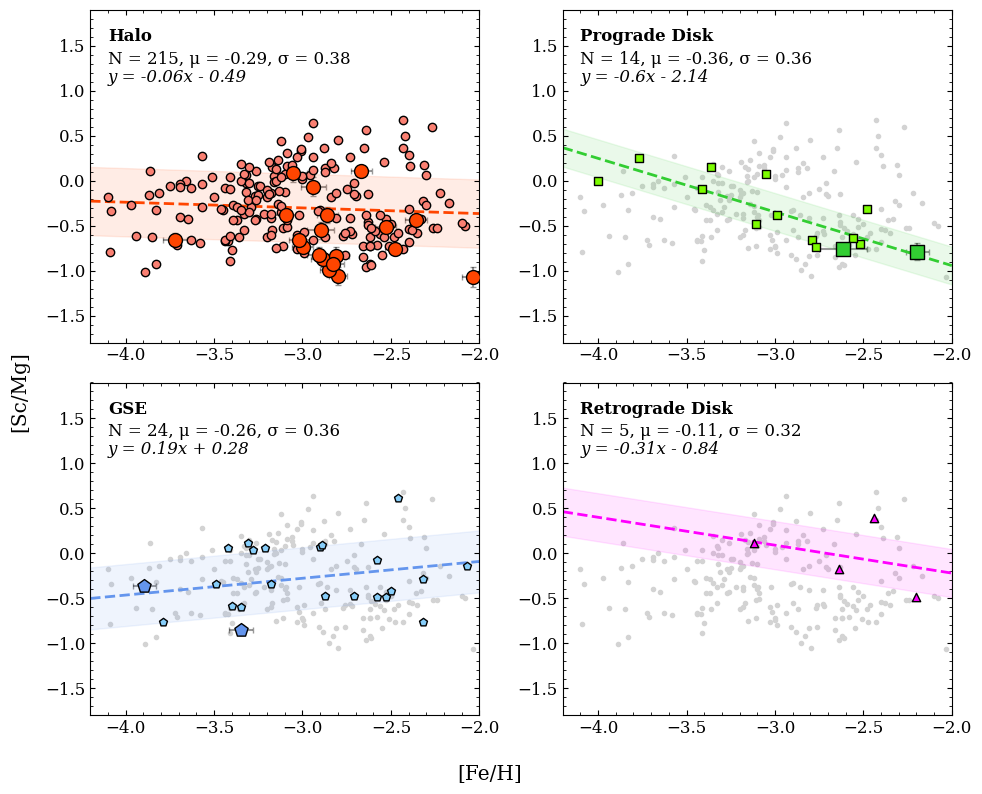

In [23]:
# Setting up figure
xlim = (-4.2, -2.0)
ylim = (-1.8, 1.9)

text_pos1 = (-4.1, 1.55)
text_pos2 = (-4.1, 1.3)
text_pos3 = (-4.1, 1.1)
text_hozalign = 'left'

halo_background = True
sculptor = sculp_df

fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel(f"[Sc/Mg]")
axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)


# --SUBPLOT 1: HALO--- #
ax = axs[0,0]
    
# Fitting polynomial (both literature and x-shooter)
halo_lit = lit_mcmillan17_orbabund_halo.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_halo_df = pd.concat([el_xshooter_mcmillan17_abund_halo, halo_lit], ignore_index=True)

weights_halo = 1 / np.sqrt(comb_halo_df['abund_err']**2 + np.std(comb_halo_df['bestfit_abund_xfe'])**2)
# p_halo, cov_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=True)
p_halo = np.polyfit(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], deg=1, w=weights_halo, cov=False)
fit_halo = np.poly1d(p_halo)

xline_halo = np.linspace(xlim[0], xlim[1], 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_halo_df['bestfit_abund_xfe'] - fit_halo(comb_halo_df['feh'])
std_halo = np.std(res_halo)

# # Getting uncertainty in gradient
# m_halo = p_halo[0]
# c_halo = p_halo[1]
# m_err_halo = np.sqrt(cov_halo[0,0])
# c_err_halo = np.sqrt(cov_halo[1,1])

# yline_halo_pmerr = (m_halo + m_err_halo) * xline_halo + c_halo
# yline_halo_mmerr = (m_halo - m_err_halo) * xline_halo + c_halo

# yline_halo_c_pmerr = m_halo * xline_halo + (c_halo + c_err_halo)
# yline_halo_c_pmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo + c_err_halo)
# yline_halo_c_pmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo + c_err_halo)

# yline_halo_c_mmerr = m_halo * xline_halo + (c_halo - c_err_halo)
# yline_halo_c_mmerr_m_pmerr = (m_halo + m_err_halo) * xline_halo + (c_halo - c_err_halo)
# yline_halo_c_mmerr_m_mmerr = (m_halo - m_err_halo) * xline_halo + (c_halo - c_err_halo)

# # Plotting the background data
# # (literature data, prograde disk and GSE stars)
# ax.scatter(el_lit_abund_all['feh'], el_lit_abund_all['abund'], c="lightgrey", marker='.', zorder=1)
# ax.scatter(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], color='grey', label='Prograde Disk', 
#             marker='s', s=100, zorder=2, alpha=0.9, linewidths=0)
# ax.errorbar(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], xerr=el_xshooter_mcmillan17_abund_prodisk['feh_err'],
#             yerr=el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)
# ax.scatter(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], color='grey', label='GSE', 
#             marker='p', s=100, zorder=2, alpha=0.9, linewidths=0)
# ax.errorbar(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], xerr=el_xshooter_mcmillan17_abund_gse['feh_err'],
#             yerr=el_xshooter_mcmillan17_abund_gse['bestfit_abund_comberr_xfe'], fmt='o', color='grey', zorder=1, alpha=0.4)

# Plotting the halo stars (literature and x-shooter)
ax.scatter(lit_mcmillan17_orbabund_halo['feh'], lit_mcmillan17_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], 
            xerr=el_xshooter_mcmillan17_abund_halo['feh_err'], yerr=el_xshooter_mcmillan17_abund_halo['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
ax.fill_between(xline_halo, 
                    yline_halo - std_halo, 
                    yline_halo + std_halo, 
                    color='orangered', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_halo, 
#                     yline_halo_pmerr, 
#                     yline_halo_mmerr, 
#                     color='orangered', 
#                     alpha=0.3)

# ax.plot(xline_halo, yline_halo_c_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.fill_between(xline_halo, 
#                 yline_halo_c_pmerr_m_pmerr, 
#                 yline_halo_c_pmerr_m_mmerr, 
#                 color='orangered', 
#                 alpha=0.15)

# ax.plot(xline_halo, yline_halo_c_mmerr, color='orangered', linestyle='--', linewidth=1)
# ax.fill_between(xline_halo, 
#                 yline_halo_c_mmerr_m_pmerr, 
#                 yline_halo_c_mmerr_m_mmerr, 
#                 color='orangered', 
#                 alpha=0.15)    


# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_halo_df)}, μ = {round(np.mean(comb_halo_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_halo_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_halo[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x + {round(p_halo[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_halo[0], 2)}x - {abs(round(p_halo[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    



# ---SUBPLOT 2: PROGRADE DISK--- #
ax = axs[0,1]

# Fitting polynomial (both literature and x-shooter)
prodisk_lit = lit_mcmillan17_orbabund_prodisk.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_prodisk_df = pd.concat([el_xshooter_mcmillan17_abund_prodisk, prodisk_lit], ignore_index=True)

weights_prodisk = 1 / np.sqrt(comb_prodisk_df['abund_err']**2 + np.std(comb_prodisk_df['bestfit_abund_xfe'])**2)    
# p_prodisk, cov_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=True)
p_prodisk = np.polyfit(comb_prodisk_df['feh'], comb_prodisk_df['bestfit_abund_xfe'], deg=1, w=weights_prodisk, cov=False)
fit_prodisk = np.poly1d(p_prodisk)

xline_prodisk = np.linspace(xlim[0], xlim[1], 100)

yline_prodisk = fit_prodisk(xline_prodisk)
res_prodisk = comb_prodisk_df['bestfit_abund_xfe'] - fit_prodisk(comb_prodisk_df['feh'])
std_prodisk = np.std(res_prodisk)

# # Getting uncertainty in gradient
# m_prodisk = p_prodisk[0]
# c_prodisk = p_prodisk[1]
# m_err_prodisk = np.sqrt(cov_prodisk[0,0])
# c_err_prodisk = np.sqrt(cov_prodisk[1,1])

# yline_prodisk_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + c_prodisk
# yline_prodisk_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + c_prodisk

# yline_prodisk_c_pmerr = m_prodisk * xline_prodisk + (c_prodisk + c_err_prodisk)
# yline_prodisk_c_pmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)
# yline_prodisk_c_pmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk + c_err_prodisk)

# yline_prodisk_c_mmerr = m_prodisk * xline_prodisk + (c_prodisk - c_err_prodisk)
# yline_prodisk_c_mmerr_m_pmerr = (m_prodisk + m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)
# yline_prodisk_c_mmerr_m_mmerr = (m_prodisk - m_err_prodisk) * xline_prodisk + (c_prodisk - c_err_prodisk)


# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk stars (literature and x-shooter)
ax.scatter(lit_mcmillan17_orbabund_prodisk['feh'], lit_mcmillan17_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], 
            xerr=el_xshooter_mcmillan17_abund_prodisk['feh_err'], yerr=el_xshooter_mcmillan17_abund_prodisk['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_prodisk, yline_prodisk, color='limegreen', linestyle='--', linewidth=2)
ax.fill_between(xline_prodisk, 
                    yline_prodisk - std_prodisk, 
                    yline_prodisk + std_prodisk, 
                    color='limegreen', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_prodisk, 
#                     yline_prodisk_pmerr, 
#                     yline_prodisk_mmerr, 
#                     color='limegreen', 
#                     alpha=0.3)

# ax.plot(xline_prodisk, yline_prodisk_c_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.fill_between(xline_prodisk, 
#                 yline_prodisk_c_pmerr_m_pmerr, 
#                 yline_prodisk_c_pmerr_m_mmerr, 
#                 color='limegreen', 
#                 alpha=0.15)

# ax.plot(xline_prodisk, yline_prodisk_c_mmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.fill_between(xline_prodisk, 
#                 yline_prodisk_c_mmerr_m_pmerr, 
#                 yline_prodisk_c_mmerr_m_mmerr, 
#                 color='limegreen', 
#                 alpha=0.15)    
    

# Making the text
# For Galah, if the horizontal alignment is right, need to adjust the x position of the text to accomodate the extended x-axis limits
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_prodisk_df)}, μ = {round(np.mean(comb_prodisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_prodisk_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_prodisk[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x + {round(p_prodisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_prodisk[0], 2)}x - {abs(round(p_prodisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

    
# ---SUBPLOT 3: GSE--- #
ax = axs[1,0]

# Fitting polynomial (both literature and x-shooter)
gse_lit = lit_mcmillan17_orbabund_gse.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_gse_df = pd.concat([el_xshooter_mcmillan17_abund_gse, gse_lit], ignore_index=True)

weights_gse = 1 / np.sqrt(comb_gse_df['abund_err']**2 + np.std(comb_gse_df['bestfit_abund_xfe'])**2)
# p_gse, cov_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=True)
p_gse = np.polyfit(comb_gse_df['feh'], comb_gse_df['bestfit_abund_xfe'], deg=1, w=weights_gse, cov=False)
fit_gse = np.poly1d(p_gse)

xline_gse = np.linspace(xlim[0], xlim[1], 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_gse_df['bestfit_abund_xfe'] - fit_gse(comb_gse_df['feh'])
std_gse = np.std(res_gse)

# # Getting uncertainty in gradient
# m_gse = p_gse[0]
# c_gse = p_gse[1]
# m_err_gse = np.sqrt(cov_gse[0,0])
# c_err_gse = np.sqrt(cov_gse[1,1])

# yline_gse_pmerr = (m_gse + m_err_gse) * xline_gse + c_gse
# yline_gse_mmerr = (m_gse - m_err_gse) * xline_gse + c_gse

# yline_gse_c_pmerr = m_gse * xline_gse + (c_gse + c_err_gse)
# yline_gse_c_pmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse + c_err_gse)
# yline_gse_c_pmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse + c_err_gse)

# yline_gse_c_mmerr = m_gse * xline_gse + (c_gse - c_err_gse)
# yline_gse_c_mmerr_m_pmerr = (m_gse + m_err_gse) * xline_gse + (c_gse - c_err_gse)
# yline_gse_c_mmerr_m_mmerr = (m_gse - m_err_gse) * xline_gse + (c_gse - c_err_gse)

# Plotting the background data
if halo_background:
    ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)
    
# Plotting the GSE stars (literature and x-shooter)
ax.scatter(lit_mcmillan17_orbabund_gse['feh'], lit_mcmillan17_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], 
            xerr=el_xshooter_mcmillan17_abund_gse['feh_err'], yerr=el_xshooter_mcmillan17_abund_gse['abund_err'], 
            fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the polynomial fit and 1-sigma bounds
ax.plot(xline_gse, yline_gse, color='cornflowerblue', linestyle='--', linewidth=2)
ax.fill_between(xline_gse, 
                    yline_gse - std_gse, 
                    yline_gse + std_gse, 
                    color='cornflowerblue', 
                    alpha=0.1)

# # Plotting the ±m_err lines
# ax.fill_between(xline_gse, 
#                     yline_gse_pmerr, 
#                     yline_gse_mmerr, 
#                     color='cornflowerblue', 
#                     alpha=0.3)

# ax.plot(xline_gse, yline_gse_c_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.fill_between(xline_gse, 
#                 yline_gse_c_pmerr_m_pmerr, 
#                 yline_gse_c_pmerr_m_mmerr, 
#                 color='cornflowerblue', 
#                 alpha=0.15)

# ax.plot(xline_gse, yline_gse_c_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.fill_between(xline_gse, 
#                 yline_gse_c_mmerr_m_pmerr, 
#                 yline_gse_c_mmerr_m_mmerr, 
#                 color='cornflowerblue', 
#                 alpha=0.15)    


# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_gse_df)}, μ = {round(np.mean(comb_gse_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_gse_df['bestfit_abund_xfe']), 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
if fit_gse[0] > 0:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x + {round(p_gse[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
else:
    ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_gse[0], 2)}x - {abs(round(p_gse[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    
    
# ---SUBPLOT 4: RETROGRADE DISK--- #
ax = axs[1,1]

# Fitting polynomial (both literature and x-shooter)
retdisk_lit = lit_mcmillan17_orbabund_retdisk.rename(columns={'abund': 'bestfit_abund_xfe'})
comb_retdisk_df = pd.concat([retdisk_lit], ignore_index=True)

# If there are no retrograde disk stars, just make the text with N, mean and stddev (which will be NaN)
if len(comb_retdisk_df) == 0:
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
else:
    
    weights_retdisk = 1 / np.sqrt(comb_retdisk_df['abund_err']**2 + np.std(comb_retdisk_df['bestfit_abund_xfe'])**2)
    
    # If there are too few stars (2 or less), the covariance will break. If this happens, then skip
    if len(comb_retdisk_df) <= 2:
        p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
        fit_retdisk = np.poly1d(p_retdisk)
        
        xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
        yline_retdisk = fit_retdisk(xline_retdisk)
        res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
        std_retdisk = np.std(res_retdisk)
    else:
        # p_retdisk, cov_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=True)
        p_retdisk = np.polyfit(comb_retdisk_df['feh'], comb_retdisk_df['bestfit_abund_xfe'], deg=1, w=weights_retdisk, cov=False)
        fit_retdisk = np.poly1d(p_retdisk)
        
        xline_retdisk = np.linspace(xlim[0], xlim[1], 100)
        yline_retdisk = fit_retdisk(xline_retdisk)
        res_retdisk = comb_retdisk_df['bestfit_abund_xfe'] - fit_retdisk(comb_retdisk_df['feh'])
        std_retdisk = np.std(res_retdisk)
    
        # # Getting uncertainty in gradient
        # m_retdisk = p_retdisk[0]
        # c_retdisk = p_retdisk[1]
        # m_err_retdisk = np.sqrt(cov_retdisk[0,0])
        # c_err_retdisk = np.sqrt(cov_retdisk[1,1])

        # yline_retdisk_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + c_retdisk
        # yline_retdisk_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + c_retdisk
        
        # yline_retdisk_c_pmerr = m_retdisk * xline_retdisk + (c_retdisk + c_err_retdisk)
        # yline_retdisk_c_pmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
        # yline_retdisk_c_pmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk + c_err_retdisk)
        
        # yline_retdisk_c_mmerr = m_retdisk * xline_retdisk + (c_retdisk - c_err_retdisk)
        # yline_retdisk_c_mmerr_m_pmerr = (m_retdisk + m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)
        # yline_retdisk_c_mmerr_m_mmerr = (m_retdisk - m_err_retdisk) * xline_retdisk + (c_retdisk - c_err_retdisk)

    # Plotting the background data
    if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

    
    # Plotting the retrograde disk stars (literature)
    ax.scatter(lit_mcmillan17_orbabund_retdisk['feh'], lit_mcmillan17_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                    edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')
    
    # Plotting the polynomial fit and 1-sigma bounds
    ax.plot(xline_retdisk, yline_retdisk, color='fuchsia', linestyle='--', linewidth=2)
    ax.fill_between(xline_retdisk, 
                        yline_retdisk - std_retdisk,
                        yline_retdisk + std_retdisk,
                        color='fuchsia',
                        alpha=0.1)
    
    # # Plotting the ±m_err lines
    # if len(comb_retdisk_df) > 2:
    #     ax.fill_between(xline_retdisk, 
    #                         yline_retdisk_pmerr, 
    #                         yline_retdisk_mmerr, 
    #                         color='fuchsia', 
    #                         alpha=0.3)
        
    #     ax.plot(xline_retdisk, yline_retdisk_c_pmerr, color='fuchsia', linestyle='--', linewidth=1)
    #     ax.fill_between(xline_retdisk, 
    #                     yline_retdisk_c_pmerr_m_pmerr, 
    #                     yline_retdisk_c_pmerr_m_mmerr, 
    #                     color='fuchsia', 
    #                     alpha=0.15)
        
    #     ax.plot(xline_retdisk, yline_retdisk_c_mmerr, color='fuchsia', linestyle='--', linewidth=1)
    #     ax.fill_between(xline_retdisk, 
    #                     yline_retdisk_c_mmerr_m_pmerr, 
    #                     yline_retdisk_c_mmerr_m_mmerr, 
    #                     color='fuchsia', 
    #                     alpha=0.15)    

    # Making the text
    ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
    ax.text(text_pos2[0], text_pos2[1], f"N = {len(comb_retdisk_df)}, μ = {round(np.mean(comb_retdisk_df['bestfit_abund_xfe']), 2)}, σ = {round(np.std(comb_retdisk_df['bestfit_abund_xfe']), 2)}", 
            fontsize=12, horizontalalignment=text_hozalign)
    if fit_retdisk[0] > 0:
        ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x + {round(p_retdisk[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
    else:
        ax.text(text_pos3[0], text_pos3[1], f"y = {round(p_retdisk[0], 2)}x - {abs(round(p_retdisk[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
        
    
    
plt.tight_layout()
if save_path is not None:
    plt.savefig(save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
    plt.savefig(save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')

# if galah_save_path is not None and galah:
#     plt.savefig(galah_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#     plt.savefig(galah_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()
# ------------------------------------------------------------------------------------------------------------ #


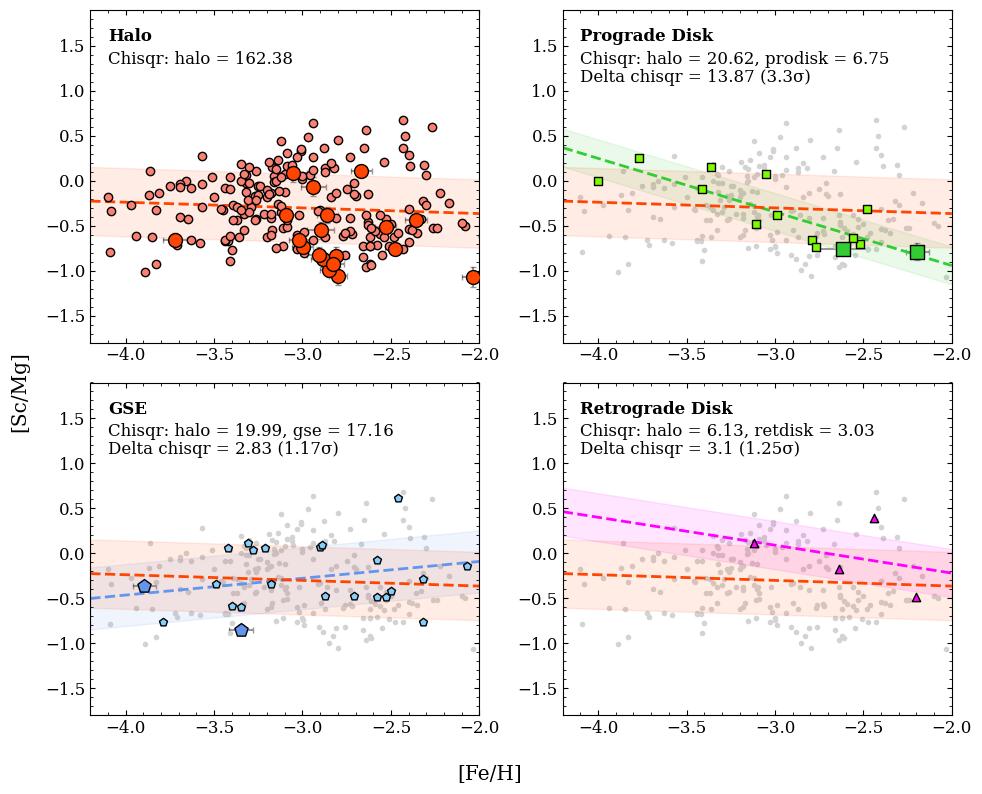

In [67]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(2, 2, figsize=[10,8], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')

fig.supylabel(f"[Sc/Mg]")


axs[0,0].set_xlim(xlim)
axs[0,0].set_ylim(ylim)
axs[0,1].set_xlim(xlim)
axs[0,1].set_ylim(ylim)
axs[1,0].set_xlim(xlim)
axs[1,0].set_ylim(ylim)
axs[1,1].set_xlim(xlim)
axs[1,1].set_ylim(ylim)

# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0,0]
ax.scatter(lit_mcmillan17_orbabund_halo['feh'], lit_mcmillan17_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_halo['feh_err'], yerr=el_xshooter_mcmillan17_abund_halo['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)



# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[0,1]
ax.scatter(lit_mcmillan17_orbabund_prodisk['feh'], lit_mcmillan17_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_prodisk['feh_err'], yerr=el_xshooter_mcmillan17_abund_prodisk['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                yline - std_prodisk,
                yline + std_prodisk,
                color='limegreen',
                alpha=0.1)

# # Plotting the prograde disk ±m_err lines
# ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['feh'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)

# Plotting the GSE stars (literature and x-shooter)
ax = axs[1,0]
ax.scatter(lit_mcmillan17_orbabund_gse['feh'], lit_mcmillan17_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_gse['feh_err'], yerr=el_xshooter_mcmillan17_abund_gse['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                yline - std_gse,
                yline + std_gse,
                color='cornflowerblue',
                alpha=0.1)

# # Plotting the GSE ±m_err lines
# ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)


# --RETROGRADE DISK--- #
# Calculating the chi-square value for the retrograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
if len(comb_retdisk_df) > 0:
        retdisk_halofit_model = fit_halo(comb_retdisk_df['feh'])
        retdisk_halofit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
        retdisk_halofit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_halofit_model) ** 2) / (retdisk_halofit_error ** 2))
        n_params = 0
        retdisk_halofit_dof = len(comb_retdisk_df) - n_params
        retdisk_halofit_redchisqr = retdisk_halofit_chisqr / retdisk_halofit_dof
        retdisk_halofit_pvalue = gammaincc(retdisk_halofit_dof / 2, retdisk_halofit_chisqr / 2)

        # Now doing this for the retrograde disk fit
        retdisk_origfit_model = fit_retdisk(comb_retdisk_df['feh'])
        retdisk_origfit_error = np.sqrt(comb_retdisk_df['abund_err'] ** 2 + std_retdisk ** 2)
        retdisk_origfit_chisqr = np.sum(((comb_retdisk_df['bestfit_abund_xfe'] - retdisk_origfit_model) ** 2) / (retdisk_origfit_error ** 2))
        n_params = 2
        retdisk_origfit_dof = len(comb_retdisk_df) - n_params # Number of parameters is the degree
        retdisk_origfit_redchisqr = retdisk_origfit_chisqr / retdisk_origfit_dof
        retdisk_origfit_pvalue = gammaincc(retdisk_origfit_dof / 2, retdisk_origfit_chisqr / 2)
                
        # Calculating the delta chisquare
        retdisk_delta_chisqr = retdisk_halofit_chisqr - retdisk_origfit_chisqr
        retdisk_delta_chisqr_pvalue = stats.chi2.sf(retdisk_delta_chisqr, 2)
        retdisk_delta_chisqr_siglevel = stats.norm.isf(retdisk_delta_chisqr_pvalue/2)

        # Plotting the retrograde disk stars (literature)
        ax = axs[1,1]
        ax.scatter(lit_mcmillan17_orbabund_retdisk['feh'], lit_mcmillan17_orbabund_retdisk['abund'], color='fuchsia', marker='^', 
                        edgecolor='black', zorder=10, linewidths=1, label='Retrograde Disk')

        # Plotting the background data
        if halo_background:
                ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

        # Plotting the retrograde disk fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_retdisk(xline)
        ax.plot(xline, yline, color='fuchsia', linestyle='--', linewidth=2, label='Retrograde Disk Fit')
        ax.fill_between(xline, 
                                yline - std_retdisk,
                                yline + std_retdisk,
                                color='fuchsia',
                                alpha=0.1)

        # # Plotting the retrograde disk ±m_err lines
        # if len(comb_retdisk_df) > 2:
        #     ax.plot(xline_retdisk, yline_retdisk_pmerr, color='fuchsia', linestyle='--', linewidth=1)
        #     ax.plot(xline_retdisk, yline_retdisk_mmerr, color='fuchsia', linestyle='--', linewidth=1)
                
        # Plotting the halo fit
        xline = np.linspace(xlim[0], xlim[1], 100)
        yline = fit_halo(xline)
        ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
        ax.fill_between(xline, 
                                yline - std_halo,
                                yline + std_halo,
                                color='orangered',
                                alpha=0.1)

        # # Plotting the halo ±m_err lines
        # ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
        # ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)
                
        # Making the text
        ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(retdisk_halofit_chisqr, 2)}, retdisk = {round(retdisk_origfit_chisqr, 2)}", 
                fontsize=12, horizontalalignment=text_hozalign)
        ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(retdisk_delta_chisqr, 2)} ({round(retdisk_delta_chisqr_siglevel, 2)}σ)", fontsize=12, horizontalalignment=text_hozalign)
else:
        ax = axs[1,1]
        ax.text(text_pos1[0], text_pos1[1], 'Retrograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
        ax.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = N/A, retdisk = N/A", 
                fontsize=12, horizontalalignment=text_hozalign)
        ax.text(text_pos3[0], text_pos3[1], f"Delta chisqr = N/A", fontsize=12, horizontalalignment=text_hozalign)

if delta_chisqr_save_path is not None:
        plt.savefig(delta_chisqr_save_path + '.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(delta_chisqr_save_path + '.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()


# Saving the chi-square values into a csv file
chisq_all_dict = {
'Region': ['pro_disk', 'halo', 'gse', 'ret_disk'],
'halofit_chisqr': [prodisk_halofit_chisqr, halo_halofit_chisqr, gse_halofit_chisqr, retdisk_halofit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
'halofit_chisqr_red': [prodisk_halofit_redchisqr, halo_halofit_redchisqr, gse_halofit_redchisqr, retdisk_halofit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
'halofit_pvalue': [prodisk_halofit_pvalue, halo_halofit_pvalue, gse_halofit_pvalue, retdisk_halofit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
'origfit_chisqr': [prodisk_origfit_chisqr, np.nan, gse_origfit_chisqr, retdisk_origfit_chisqr if len(comb_retdisk_df) > 0 else np.nan],
'origfit_chisqr_red': [prodisk_origfit_redchisqr, np.nan, gse_origfit_redchisqr, retdisk_origfit_redchisqr if len(comb_retdisk_df) > 0 else np.nan],
'origfit_pvalue': [prodisk_origfit_pvalue, np.nan, gse_origfit_pvalue, retdisk_origfit_pvalue if len(comb_retdisk_df) > 0 else np.nan],
'delta_chisqr': [prodisk_delta_chisqr, np.nan, gse_delta_chisqr, retdisk_delta_chisqr if len(comb_retdisk_df) > 0 else np.nan]
}
chisq_all_df = pd.DataFrame(chisq_all_dict)
if delta_chisqr_save_path is not None:
        chisq_all_df.to_csv(delta_chisqr_save_path + '_chisqr.csv', index=False)


# # ---SCULPTOR GALAXY--- #
# if sculptor is not None:
#         sculptor_el = 'scmg'                

#         sculp_el_df = sculp_df.dropna(subset=[sculptor_el])

#         # Fitting polynomial to the Sculptor data
#         weights_sculp = 1 / np.sqrt(sculp_el_df[sculptor_el + '_err']**2 + np.std(sculp_el_df[sculptor_el]) ** 2)
#         p_sculp = np.polyfit(sculp_el_df['feh'], sculp_el_df[sculptor_el], deg=1, w=weights_sculp)
#         fit_sculp = np.poly1d(p_sculp)
#         xline_sculp = np.linspace(xlim[0], xlim[1], 100)
#         yline_sculp = fit_sculp(xline_sculp)
#         res_sculp = sculp_el_df[sculptor_el] - fit_sculp(sculp_el_df['feh'])
#         std_sculp = np.std(res_sculp)

#         # Plotting the Sculptor data
#         plt.figure(figsize=[6,5])
#         plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
#                         edgecolor='black', zorder=10, linewidths=1)

#         # Plotting the background halo data
#         if halo_background:
#                 plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

#         # Plotting the polynomial fit and 1-sigma bounds
#         plt.plot(xline_sculp, yline_sculp, color='goldenrod', linestyle='--', linewidth=2)
#         plt.fill_between(xline_sculp, 
#                                 yline_sculp - std_sculp, 
#                                 yline_sculp + std_sculp, 
#                                 color='goldenrod', 
#                                 alpha=0.1)

#         # Making the text
#         plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
#         plt.text(text_pos2[0], text_pos2[1], f"N = {len(sculp_el_df)}, μ = {round(np.mean(sculp_el_df['scfe']), 2)}, σ = {round(np.std(sculp_el_df['scfe']), 2)}", 
#                 fontsize=12, horizontalalignment=text_hozalign)
#         if fit_sculp[0] > 0:
#                 plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x + {round(p_sculp[1], 2)}", fontsize=12, style='italic', horizontalalignment=text_hozalign)
#         else:
#                 plt.text(text_pos3[0], text_pos3[1], f"y = {round(p_sculp[0], 2)}x - {abs(round(p_sculp[1], 2))}", fontsize=12, style='italic', horizontalalignment=text_hozalign)

#         plt.xlim(xlim)
#         plt.ylim(ylim)
#         plt.xlabel('[Fe/H]')
#         plt.ylabel(f'[Sc/Mg]')
#         plt.tight_layout()

#         if save_path is not None:
#                 plt.savefig(save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#                 plt.savefig(save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#         # plt.close()


#         # Calculating the chi-square value for the Sculptor data using the halo fit
#         # First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
#         # Adding the scatter in quadrature to the abundance error
#         sculp_halofit_model = fit_halo(sculp_el_df['feh'])
#         sculp_halofit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2) 
#         sculp_halofit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_halofit_model) ** 2) / (sculp_halofit_error ** 2))
#         n_params = 0
#         sculp_halofit_dof = len(sculp_el_df) - n_params
#         sculp_halofit_redchisqr = sculp_halofit_chisqr / sculp_halofit_dof
#         sculp_halofit_pvalue = gammaincc(sculp_halofit_dof / 2, sculp_halofit_chisqr / 2)

#         # Now doing this for the Sculptor fit
#         sculp_origfit_model = fit_sculp(sculp_el_df['feh'])
#         sculp_origfit_error = np.sqrt(std_sculp ** 2 + sculp_el_df[sculptor_el + '_err'] ** 2)
#         sculp_origfit_chisqr = np.sum(((sculp_el_df[sculptor_el] - sculp_origfit_model) ** 2) / (sculp_origfit_error ** 2))
#         n_params = 2
#         sculp_origfit_dof = len(sculp_el_df) - n_params # Number of parameters is the degree
#         sculp_origfit_redchisqr = sculp_origfit_chisqr / sculp_origfit_dof
#         sculp_origfit_pvalue = gammaincc(sculp_origfit_dof / 2, sculp_origfit_chisqr / 2)

#         # Calculating the delta chisquare
#         sculp_delta_chisqr = sculp_halofit_chisqr - sculp_origfit_chisqr

#         # Plotting 
#         plt.figure(figsize=[6,5])
#         plt.scatter(sculp_el_df['feh'], sculp_el_df[sculptor_el], color='goldenrod', marker='D', 
#                         edgecolor='black', zorder=10, linewidths=1)

#         # Plotting the background halo data
#         if halo_background:
#                 plt.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

#         # Plotting the Sculptor fit
#         xline = np.linspace(xlim[0], xlim[1], 100)
#         yline = fit_sculp(xline)
#         plt.plot(xline, yline, color='goldenrod', linestyle='--', linewidth=2, label='Sculptor Fit')
#         plt.fill_between(xline, 
#                                 yline - std_sculp,
#                                 yline + std_sculp,
#                                 color='goldenrod',
#                                 alpha=0.1)

#         # Plotting the halo fit
#         xline = np.linspace(xlim[0], xlim[1], 100)
#         yline = fit_halo(xline)
#         plt.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
#         plt.fill_between(xline, 
#                                 yline - std_halo,
#                                 yline + std_halo,
#                                 color='orangered',
#                                 alpha=0.1)

#         # Making the text
#         plt.text(text_pos1[0], text_pos1[1], 'Sculptor', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
#         plt.text(text_pos2[0], text_pos2[1], f"Chisqr: halo = {round(sculp_halofit_chisqr, 2)}, sculptor = {round(sculp_origfit_chisqr, 2)}", 
#                 fontsize=12, horizontalalignment=text_hozalign)
#         plt.text(text_pos3[0], text_pos3[1], f"Delta chisqr = {round(sculp_delta_chisqr, 2)}", fontsize=12, horizontalalignment=text_hozalign)

#         plt.xlim(xlim)
#         plt.ylim(ylim)
#         plt.xlabel('[Fe/H]')
#         plt.ylabel(f'[Sc/Mg]')
#         plt.tight_layout()

#         if delta_chisqr_save_path is not None:
#                 plt.savefig(delta_chisqr_save_path + "_sculptor.png", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#                 plt.savefig(delta_chisqr_save_path + "_sculptor.pdf", dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
#         # plt.close()


#         # Saving the chi-square values into a csv file
#         chisq_sculp_dict = {
#                 'Region': ['sculptor'],
#                 'halofit_chisqr': [sculp_halofit_chisqr],
#                 'halofit_chisqr_red': [sculp_halofit_redchisqr],
#                 'halofit_pvalue': [sculp_halofit_pvalue],
#                 'origfit_chisqr': [sculp_origfit_chisqr],
#                 'origfit_chisqr_red': [sculp_origfit_redchisqr],
#                 'origfit_pvalue': [sculp_origfit_pvalue],
#                 'delta_chisqr': [sculp_delta_chisqr]
#         }
#         chisq_sculp_df = pd.DataFrame(chisq_sculp_dict)
#         if delta_chisqr_save_path is not None:
#                 chisq_sculp_df.to_csv(delta_chisqr_save_path + '_sculptor_chisqr.csv', index=False)
#         # ------------------------------------------------------------------------------------------------------------ #


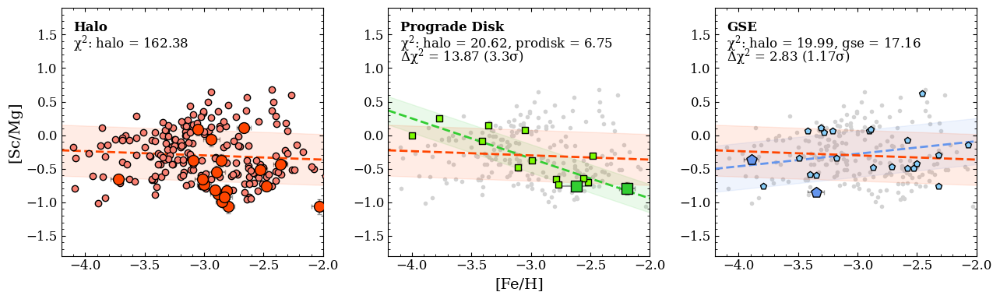

In [26]:
# ---PLOT 2: REDUCED CHISQUARE WITH HALO FIT--- #
# Running the code again, this time using the halo fit on the other regions, then calculating the chisquares
# Setting up figure
fig, axs = plt.subplots(1, 3, figsize=[13,4], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
axs[1].set_xlabel('[Fe/H]')
axs[0].set_ylabel(f"[Sc/Mg]")    
axs[0].set_xlim(xlim)
axs[0].set_ylim(ylim)
axs[1].set_xlim(xlim)
axs[1].set_ylim(ylim)
axs[2].set_xlim(xlim)
axs[2].set_ylim(ylim)    

# ---HALO--- #
# Calculating the chi-square value for the halo stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
halo_halofit_model = fit_halo(comb_halo_df['feh'])
halo_halofit_error = np.sqrt(comb_halo_df['abund_err'] ** 2 + std_halo ** 2)
halo_halofit_chisqr = np.sum(((comb_halo_df['bestfit_abund_xfe'] - halo_halofit_model) ** 2) / (halo_halofit_error ** 2))
n_params = 2
halo_halofit_dof = len(comb_halo_df) - n_params
halo_halofit_redchisqr = halo_halofit_chisqr / halo_halofit_dof
halo_halofit_pvalue = gammaincc(halo_halofit_dof / 2, halo_halofit_chisqr / 2)

# Plotting the halo stars (literature and x-shooter)
ax = axs[0]
ax.scatter(lit_mcmillan17_orbabund_halo['feh'], lit_mcmillan17_orbabund_halo['abund'], color='salmon', marker='o', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], color='orangered', 
        label='Halo', marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_halo['feh'], el_xshooter_mcmillan17_abund_halo['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_halo['feh_err'], yerr=el_xshooter_mcmillan17_abund_halo['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Halo', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(halo_halofit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)


# ---PROGRADE DISK--- #
# Calculating the chi-square value for the prograde disk stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
prodisk_halofit_model = fit_halo(comb_prodisk_df['feh'])
prodisk_halofit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_halofit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_halofit_model) ** 2) / (prodisk_halofit_error ** 2))
n_params = 0
prodisk_halofit_dof = len(comb_prodisk_df) - n_params
prodisk_halofit_redchisqr = prodisk_halofit_chisqr / prodisk_halofit_dof
prodisk_halofit_pvalue = gammaincc(prodisk_halofit_dof / 2, prodisk_halofit_chisqr / 2)

# Now doing this for the prograde disk fit
prodisk_origfit_model = fit_prodisk(comb_prodisk_df['feh'])
prodisk_origfit_error = np.sqrt(comb_prodisk_df['abund_err'] ** 2 + std_prodisk ** 2)
prodisk_origfit_chisqr = np.sum(((comb_prodisk_df['bestfit_abund_xfe'] - prodisk_origfit_model) ** 2) / (prodisk_origfit_error ** 2))
n_params = 2
prodisk_origfit_dof = len(comb_prodisk_df) - n_params # Number of parameters is the degree
prodisk_origfit_redchisqr = prodisk_origfit_chisqr / prodisk_origfit_dof
prodisk_origfit_pvalue = gammaincc(prodisk_origfit_dof / 2, prodisk_origfit_chisqr / 2)

# Calculating the delta chisquare
prodisk_delta_chisqr = prodisk_halofit_chisqr - prodisk_origfit_chisqr
prodisk_delta_chisqr_pvalue = stats.chi2.sf(prodisk_delta_chisqr, 2)
prodisk_delta_chisqr_siglevel = stats.norm.isf(prodisk_delta_chisqr_pvalue/2)

# Plotting the prograde disk stars (literature and x-shooter)
ax = axs[1]
ax.scatter(lit_mcmillan17_orbabund_prodisk['feh'], lit_mcmillan17_orbabund_prodisk['abund'], color='lawngreen', marker='s', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], color='limegreen', 
        label='Prograde Disk', marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_prodisk['feh'], el_xshooter_mcmillan17_abund_prodisk['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_prodisk['feh_err'], yerr=el_xshooter_mcmillan17_abund_prodisk['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)

# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the prograde disk fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_prodisk(xline)
ax.plot(xline, yline, color='limegreen', linestyle='--', linewidth=2, label='Prograde Disk Fit')
ax.fill_between(xline, 
                yline - std_prodisk,
                yline + std_prodisk,
                color='limegreen',
                alpha=0.1)

# # Plotting the prograde disk ±m_err lines
# ax.plot(xline_prodisk, yline_prodisk_pmerr, color='limegreen', linestyle='--', linewidth=1)
# ax.plot(xline_prodisk, yline_prodisk_mmerr, color='limegreen', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(prodisk_halofit_chisqr, 2)}, prodisk = {round(prodisk_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(prodisk_delta_chisqr, 2)} ({round(prodisk_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)


# ---GSE--- #
# Calculating the chi-square value for the GSE stars using the halo fit
# First, calculating the expected values using the halo fit, calculating the chi-square value, reduced chi-square and the p-value
# Adding the scatter in quadrature to the abundance error
gse_halofit_model = fit_halo(comb_gse_df['feh'])
gse_halofit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_halofit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_halofit_model) ** 2) / (gse_halofit_error ** 2))
n_params = 0
gse_halofit_dof = len(comb_gse_df) - n_params
gse_halofit_redchisqr = gse_halofit_chisqr / gse_halofit_dof
gse_halofit_pvalue = gammaincc(gse_halofit_dof / 2, gse_halofit_chisqr / 2)

# Now doing this for the GSE fit
gse_origfit_model = fit_gse(comb_gse_df['feh'])
gse_origfit_error = np.sqrt(comb_gse_df['abund_err'] ** 2 + std_gse ** 2)
gse_origfit_chisqr = np.sum(((comb_gse_df['bestfit_abund_xfe'] - gse_origfit_model) ** 2) / (gse_origfit_error ** 2))
n_params = 2
gse_origfit_dof = len(comb_gse_df) - n_params # Number of parameters is the degree
gse_origfit_redchisqr = gse_origfit_chisqr / gse_origfit_dof
gse_origfit_pvalue = gammaincc(gse_origfit_dof / 2, gse_origfit_chisqr / 2)

# Calculating the delta chisquare
gse_delta_chisqr = gse_halofit_chisqr - gse_origfit_chisqr
gse_delta_chisqr_pvalue = stats.chi2.sf(gse_delta_chisqr, 2)
gse_delta_chisqr_siglevel = stats.norm.isf(gse_delta_chisqr_pvalue/2)

# Plotting the GSE stars (literature and x-shooter)
ax = axs[2]
ax.scatter(lit_mcmillan17_orbabund_gse['feh'], lit_mcmillan17_orbabund_gse['abund'], color='lightskyblue', marker='p', 
                edgecolor='black', zorder=10, linewidths=1)
ax.scatter(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], color='cornflowerblue', 
        label='GSE', marker='p', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=1)
ax.errorbar(el_xshooter_mcmillan17_abund_gse['feh'], el_xshooter_mcmillan17_abund_gse['bestfit_abund_xfe'], 
        xerr=el_xshooter_mcmillan17_abund_gse['feh_err'], yerr=el_xshooter_mcmillan17_abund_gse['abund_err'], 
        fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the background data
if halo_background:
        ax.scatter(comb_halo_df['feh'], comb_halo_df['bestfit_abund_xfe'], c="lightgrey", marker='.', zorder=1)

# Plotting the GSE fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_gse(xline)
ax.plot(xline, yline, color='cornflowerblue', linestyle='--', linewidth=2, label='GSE Fit')
ax.fill_between(xline, 
                yline - std_gse,
                yline + std_gse,
                color='cornflowerblue',
                alpha=0.1)

# # Plotting the GSE ±m_err lines
# ax.plot(xline_gse, yline_gse_pmerr, color='cornflowerblue', linestyle='--', linewidth=1)
# ax.plot(xline_gse, yline_gse_mmerr, color='cornflowerblue', linestyle='--', linewidth=1)

# Plotting the halo fit
xline = np.linspace(xlim[0], xlim[1], 100)
yline = fit_halo(xline)
ax.plot(xline, yline, color='orangered', linestyle='--', linewidth=2, label='Halo Fit')
ax.fill_between(xline, 
                yline - std_halo,
                yline + std_halo,
                color='orangered',
                alpha=0.1)

# # Plotting the halo ±m_err lines
# ax.plot(xline_halo, yline_halo_pmerr, color='orangered', linestyle='--', linewidth=1)
# ax.plot(xline_halo, yline_halo_mmerr, color='orangered', linestyle='--', linewidth=1)

# Making the text
ax.text(text_pos1[0], text_pos1[1], 'GSE', fontsize=12, fontweight='bold', horizontalalignment=text_hozalign)
ax.text(text_pos2[0], text_pos2[1], fr"$\chi^2$: halo = {round(gse_halofit_chisqr, 2)}, gse = {round(gse_origfit_chisqr, 2)}", 
        fontsize=12, horizontalalignment=text_hozalign)
ax.text(text_pos3[0], text_pos3[1], fr"$\Delta \chi^2$ = {round(gse_delta_chisqr, 2)} ({round(gse_delta_chisqr_siglevel, 2)}$\sigma$)", fontsize=12, horizontalalignment=text_hozalign)

if delta_chisqr_save_path is not None:
        plt.savefig(delta_chisqr_save_path + '_no_retdisk.png', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
        plt.savefig(delta_chisqr_save_path + '._no_retdisk.pdf', dpi=300, transparent=False, facecolor="white", bbox_inches='tight')
# plt.close()

In [68]:
comb_halo_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg_mcmillan17/comb_halo_df.csv", index=False)
comb_prodisk_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg_mcmillan17/comb_prodisk_df.csv", index=False)
comb_gse_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg_mcmillan17/comb_gse_df.csv", index=False)
comb_retdisk_df.to_csv("/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg_mcmillan17/comb_retdisk_df.csv", index=False)